# PICReduce.ipynb

A notebook for reducing data taken with the active PIC.

# Imports

In [1]:
import numpy as np
import matplotlib
matplotlib.rc_file('D:\\Active_PIC\\matplotlibrc')
import matplotlib.pyplot as plt
import matplotlib.cm as cm
%matplotlib inline

import os, glob
import importlib
import sys
sys.path.append('D://Active_PIC//AnalysisCode//')
import PIC_lib as PIC

 # Photometry

### Device 5a

In [53]:
importlib.reload(Bench)
importlib.reload(PIC)

<module 'PIC_lib' from 'd:\\Active_PIC\\AnalysisCode\\PIC_lib.py'>

In [48]:
frame = np.load(filename_ref).mean(axis=0) - dark
c = BENCH.find_output_centers(frame, num_outputs, plot=False)
print('find_output_centers:', c)

f = np.clip(frame, 0, None)
yy, xx = np.mgrid[0:f.shape[0], 0:f.shape[1]]
print('whole-frame centroid:', [ (yy*f).sum()/f.sum(), (xx*f).sum()/f.sum() ])
print('brightest pixel     :', np.unravel_index(np.argmax(frame), frame.shape))

find_output_centers: [[11.          9.51462008]]
whole-frame centroid: [10.147183864809048, 9.565251210139083]
brightest pixel     : (11, 10)


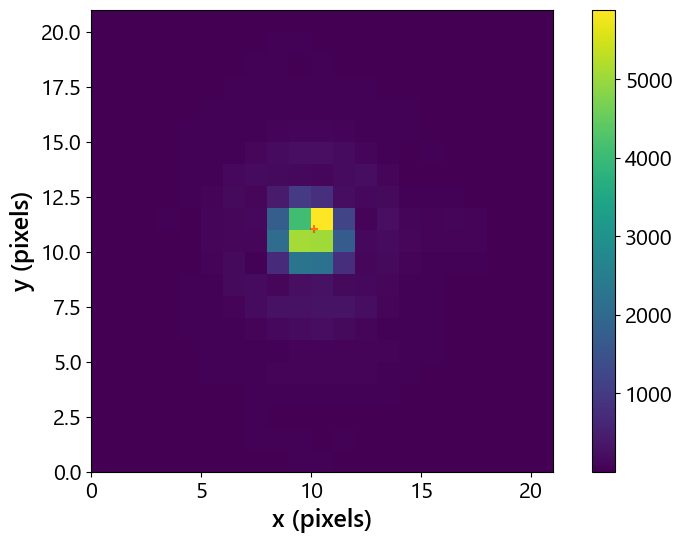

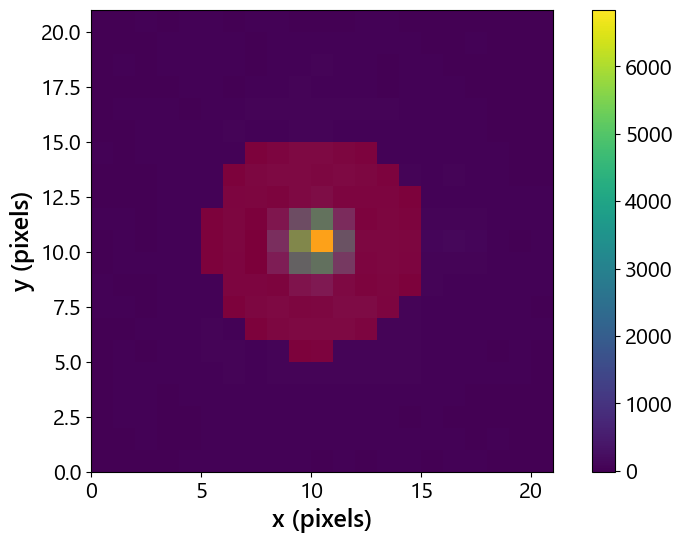

[0.0] [58.]
[0.1] [58.]
[0.25] [58.]
[0.475] [58.]
[0.812] [58.]
[1.312] [58.]
[1.812] [58.]
[2.312] [58.]
[2.812] [58.]
[3.312] [58.]
[3.812] [61.]
[4.312] [61.]
[4.812] [61.]
[5.312] [61.]
[5.812] [61.]
[6.312] [61.]
[6.812] [61.]
[7.312] [61.]
[7.812] [61.]
[8.312] [61.]
[8.812] [61.]
[9.312] [61.]
[9.812] [61.]
[10.312] [61.]
[10.812] [61.]
[11.312] [61.]
[11.812] [58.]
[11.832] [55.]
[11.852] [55.]
[11.952] [55.]
[12.102] [52.]
[12.122] [52.]
[12.222] [49.]
[12.242] [49.]
[12.342] [43.]
[12.362] [43.]
[12.462] [31.]
[12.464] [31.]
[12.466] [31.]
[12.468] [31.]
[12.47] [31.]
[12.473] [31.]
[12.475] [28.]
[12.477] [28.]
[12.479] [28.]
[12.481] [28.]
[12.482] [25.]
[12.483] [25.]
[12.485] [25.]
[12.487] [25.]
[12.489] [25.]
[12.491] [25.]
[12.493] [25.]
[12.495] [25.]
[12.497] [25.]
[12.499] [25.]
[12.501] [25.]
[12.502] [25.]
[12.503] [25.]
[12.505] [25.]
[12.507] [25.]
[12.509] [25.]
[12.511] [25.]
[12.513] [25.]
[12.515] [25.]
[12.517] [25.]
[12.519] [25.]
[12.521] [25.]
[12.523] 

In [56]:
from Bench import BENCH
device_name, num_outputs = f'Device5a_I15_1x3Tri', 1

filename_root = f'{device_name}'

trial_str = f'trial2'
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_TECon_polarizer_adaptive_{trial_str}\\'
filename_ref = glob.glob(data_dir+'*[0-9].npy')[0]
filename_dark = glob.glob(data_dir+'*dark*')[0]

data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
masks = BENCH.build_output_mask(data[0]-dark, num_outputs, coords, mask_range=5)

voltages, outputs, attens, outputs_flux, labels = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                            coords=None, r_lin=4, r_max=10, plot=False, 
                                                                            movie_filename=data_dir+filename_root+f'{trial_str}_inspect.mp4', 
                                                                            movie_null_filename=data_dir+filename_root+f'{trial_str}_null_inspect.mp4', movie_dpi=120)

np.save(f'{data_dir}{filename_root}_voltage', voltages)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

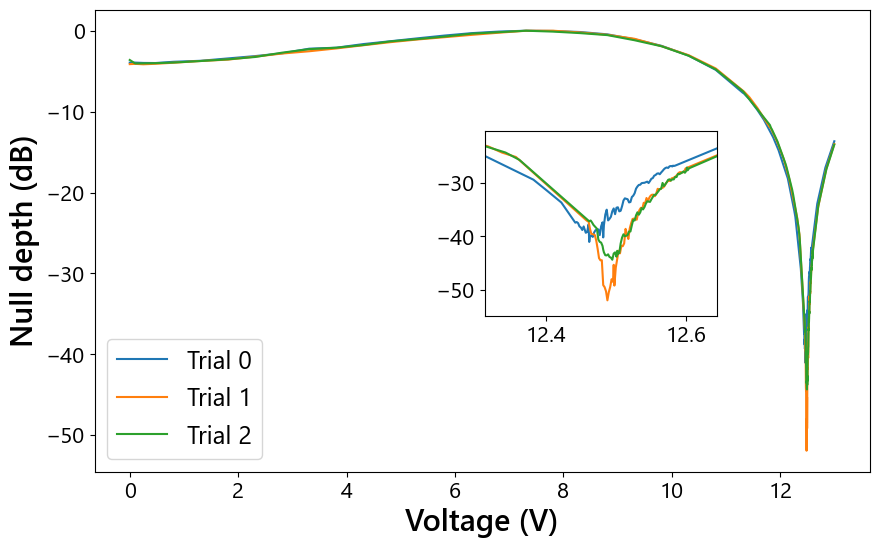

In [58]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_TECon_polarizer_adaptive_trial0\\'
voltages_0 = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled =  outputs * 10**(attens/10)
null_0 = 10 * np.log10(outputs_scaled/np.max(outputs_scaled))

data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_TECon_polarizer_adaptive_trial1\\'
voltages_1 = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled =  outputs * 10**(attens/10)
null_1 = 10 * np.log10(outputs_scaled/np.max(outputs_scaled))

data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_TECon_polarizer_adaptive_trial2\\'
voltages_2 = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled =  outputs * 10**(attens/10)
null_2 = 10 * np.log10(outputs_scaled/np.max(outputs_scaled))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(voltages_0, null_0, label='Trial 0')
ax.plot(voltages_1, null_1, label='Trial 1')
ax.plot(voltages_2, null_2, label='Trial 2')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Null depth (dB)')
ax.legend()
 
# Find each curve's null (minimum) location automatically
idx0 = np.argmin(null_0)
idx1 = np.argmin(null_1)
idx2 = np.argmin(null_2)
v_null0, v_null1, v_null2 = voltages_0[idx0], voltages_1[idx1], voltages_2[idx2]
 
# Window around the null(s) -- span both nulls with some padding
v_center = (min([v_null0, v_null1, v_null2]) + max([v_null0, v_null1, v_null2])) / 2
half_window = max(abs(v_null0 - v_center), abs(v_null1 - v_center)) + 0.15
 
axins = inset_axes(ax, width="100%", height="100%", bbox_transform=ax.transAxes, bbox_to_anchor=(0.6, 0.5, 0.3, 0.40), borderpad=3)
axins.plot(voltages_0, null_0)
axins.plot(voltages_1, null_1)
axins.plot(voltages_2, null_2)
axins.set_xlim(v_center - half_window, v_center + half_window)
 
# Frame the y-limits around the null depths within that window
mask0 = (voltages_0 >= v_center - half_window) & (voltages_0 <= v_center + half_window)
mask1 = (voltages_1 >= v_center - half_window) & (voltages_1 <= v_center + half_window)
y_lo = min(null_0[idx0], null_1[idx1])
y_hi = max(null_0[mask0].max(), null_1[mask1].max())
pad = (y_hi - y_lo) * 0.1
axins.set_ylim(y_lo - pad, y_hi + pad)
 
plt.show()

Laser scan

In [66]:
# data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_TECon_polarizer_adaptive_trial0\\'
# voltages_0 = np.load(f'{data_dir}{filename_root}_voltage.npy')
# outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
# attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
# outputs_scaled =  outputs * 10**(attens/10)

# data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260921\\laser_scan\\Device5a_I15_1x3Tri_TECon_polarizer_adaptive_trial0\\'
data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260906\\voltage_scan_Ch68_V11p500_TECon_polarizer_bad\\voltage_scan\\'
device_name = 'Device7a_I21_1x5Tri_Ch68_V11p500_KCh3_KCh2'
filename_root = f'{device_name}'
tab = np.genfromtxt(glob.glob(data_dir+filename_root+'*.log')[0], delimiter=',', names=True)
tab

array([(4.30391, 0.02   , 0.0860782 , 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  0.    , 9.6436000e-02, -1.83800e-03, -1.77249368e-04, 146408.88058215, 17.962),
       (4.30371, 0.01812, 0.07798323, 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  0.1   , 9.7271000e-02, -1.80600e-03, -1.75671426e-04, 146415.21041597, 17.995),
       (4.30391, 0.01875, 0.08069831, 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  0.25  , 2.5002700e-01, -4.09000e-04, -1.02261043e-04, 146421.44298411, 17.995),
       (4.30391, 0.02   , 0.0860782 , 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  0.475 , 4.7791000e-01,  1.68200e-03,  8.03844620e-04, 146427.65304053, 17.995),
       (4.30391, 0.01937, 0.08336674, 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  0.8125, 8.1514400e-01,  4.76800e-03,  3.88660659e-03, 146433.85865665, 17.995),
       (4.3041 , 0.02   , 0.086082  , 20.,  9.80282785,  9.802025, 0.091375, 0.89566003,  1.3125, 1.3159860e+00,  9.35100e-03,  1.23057851e-02, 146440

In [74]:
# BENCH.externalVOA_voltage_to_dB((max(tab['externalAttenActualVoltage']))) + 20
max(tab['externalAttenActualVoltage'])

4.49199

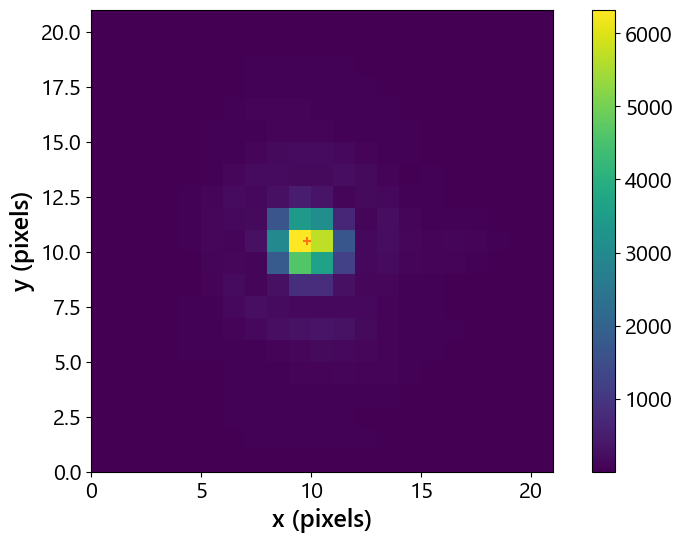

 1575.000 nm  [10.0]  [58.]
 1575.000 nm  [10.2]  [58.]
 1575.000 nm  [10.4]  [58.]
 1575.000 nm  [10.6]  [58.]
 1575.000 nm  [10.8]  [58.]
 1575.000 nm  [11.0]  [58.]
 1575.000 nm  [11.2]  [58.]
 1575.000 nm  [11.4]  [58.]
 1575.000 nm  [11.6]  [58.]
 1575.000 nm  [11.8]  [55.]
 1575.000 nm  [12.0]  [52.]
 1575.000 nm  [12.09]  [49.]
 1575.000 nm  [12.092]  [49.]
 1575.000 nm  [12.094]  [49.]
 1575.000 nm  [12.096]  [49.]
 1575.000 nm  [12.098]  [49.]
 1575.000 nm  [12.1]  [49.]
 1575.000 nm  [12.102]  [49.]
 1575.000 nm  [12.104]  [49.]
 1575.000 nm  [12.106]  [49.]
 1575.000 nm  [12.108]  [49.]
 1575.000 nm  [12.11]  [49.]
 1575.000 nm  [12.112]  [49.]
 1575.000 nm  [12.114]  [49.]
 1575.000 nm  [12.116]  [49.]
 1575.000 nm  [12.118]  [49.]
 1575.000 nm  [12.12]  [49.]
 1575.000 nm  [12.122]  [49.]
 1575.000 nm  [12.124]  [49.]
 1575.000 nm  [12.126]  [49.]
 1575.000 nm  [12.128]  [49.]
 1575.000 nm  [12.13]  [49.]
 1575.000 nm  [12.132]  [49.]
 1575.000 nm  [12.134]  [49.]
 1575.00

KeyboardInterrupt: 

In [111]:
data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260921\\laser_scan\\Device5a_I15_1x3Tri_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device5a_I15_1x3Tri'
filename_root = f'{device_name}'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 1

filename_ref = glob.glob(f'{data_dir}//*[0-9].npy')[0]
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
# masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords)

wavs, voltage_coords, outputs, attens, output_fluxes, labels = PIC.reduce_laser_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                              coords=coords, movie_root=data_dir+filename_root, 
                                                                              movie_dpi=120, movie_clim=(0, np.max(np.mean(data, axis=0)-dark)))

np.save(f'{data_dir}{filename_root}_wav', wavs)
np.save(f'{data_dir}{filename_root}_voltage', voltage_coords)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

Null track

In [104]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.animation import FuncAnimation, PillowWriter

data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260921\\laser_scan\\Device5a_I15_1x3Tri_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device5a_I15_1x3Tri'
filename_root = f'{device_name}'
wavs = np.load(f'{data_dir}{filename_root}_wav.npy')
voltage_coords = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

IND_OUTPUT = 0
IND_X = 0              # channel whose voltage is the x-axis

wav_ref = 1590
wav_vals = np.sort(list(set(wavs)))
wav_sets = [wavs == w for w in wav_vals]

outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

cmap_orig = plt.get_cmap('RdYlBu_r', 256)
blue = cmap_orig(0.0)
red = cmap_orig(1.0)
yellow = '#f2d675'  # soft yellow, keeps the transition smooth without passing through white
cmap = LinearSegmentedColormap.from_list('blue_yellow_red_smooth', [blue, yellow, red], N=256)
norm = Normalize(vmin=min(wav_vals), vmax=max(wav_vals))

# Precompute all curves, null depths, and null positions up front
curves = []
null_depths = []
null_positions = []
for i, w in enumerate(wav_vals):
    sel = wav_sets[i]
    order = np.argsort(voltage_coords[sel, IND_X])
    v = voltage_coords[sel, IND_X][order]
    output_w = outputs_scaled[sel][order]
    null_curve = 10*np.log10(output_w/np.nanmax(output_w))
    curves.append((v, null_curve))
    idx_min = np.argmin(null_curve)
    null_positions.append(v[idx_min])
    
voltages_ref = curves[int(np.argwhere(wav_vals == wav_ref))][0]
curve_ref = curves[int(np.argwhere(wav_vals == wav_ref))][1]
ind_null = np.argmin(curve_ref)
null_depths_theory = ((np.pi**2)/4)*((wav_vals-wav_ref)/wav_ref)**2
null_depths_theory = 10*np.log10(null_depths_theory)

for i, w in enumerate(wav_vals):
    null_curve = curves[i][1]
    null_depths.append(null_curve[ind_null])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 6))
plt.subplots_adjust(wspace=0.5)

# --- Panel 1: sweep curve (static elements) ---
all_v = np.concatenate([v for v, _ in curves])
ax1.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
ax1.set_xlim(all_v.min(), all_v.max())
ax1.set_ylim(-60, 0)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('C/max(C) (dB)')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=28)

scat = ax1.scatter([], [], marker='.')

# --- Panel 2: null depth vs wavelength (static elements) ---
ax2.plot(wav_vals, null_depths, '-', color='lightgray', zorder=1)
ax2.plot(wav_vals, null_depths_theory, '--', color='black', zorder=1)
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Null depth (dB)')
ax2.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
ax2.set_ylim(min(null_depths) - 2, max(null_depths) + 2)
title = ax2.set_title('')

null_scat = ax2.scatter([], [], s=80, zorder=2, edgecolor='k')

# --- Panel 3: null position vs wavelength (static elements) ---
ax3.plot(wav_vals, null_positions, '-', color='lightgray', zorder=1)
ax3.set_xlabel('Wavelength (nm)')
ax3.set_ylabel('Minimum position (V)')
ax3.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
pos_range = max(null_positions) - min(null_positions)
pad = pos_range * 0.1 if pos_range > 0 else 0.5
ax3.set_ylim(min(null_positions) - pad, max(null_positions) + pad)

pos_scat = ax3.scatter([], [], s=80, zorder=2, edgecolor='k')

def update(frame):
    # Panel 1: this frame's curve only
    v, null_curve = curves[frame]
    w = wav_vals[frame]
    scat.set_offsets(np.column_stack([v, null_curve]))
    scat.set_color(cmap(norm(w)))
    title.set_text(f'Wavelength = {w:.2f} nm')

    # Panel 2: accumulate null depth points up through this frame
    null_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_depths[:frame+1]]))
    null_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    # Panel 3: accumulate null position points up through this frame
    pos_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_positions[:frame+1]]))
    pos_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    return scat, title, null_scat, pos_scat

anim = FuncAnimation(fig, update, frames=len(wav_vals), interval=200, blit=False)

anim.save(f'{data_dir}{filename_root}_wavelength_sweep.gif', writer=PillowWriter(fps=1))
plt.close(fig)
print("Saved wavelength_sweep.gif")

C:\Users\Pradip\AppData\Local\Temp\ipykernel_13980\1486671585.py:49: RuntimeWarning: divide by zero encountered in log10
  null_depths_theory = 10*np.log10(null_depths_theory)


Saved wavelength_sweep.gif


In [103]:
sel

array([ True,  True,  True, ..., False, False, False])

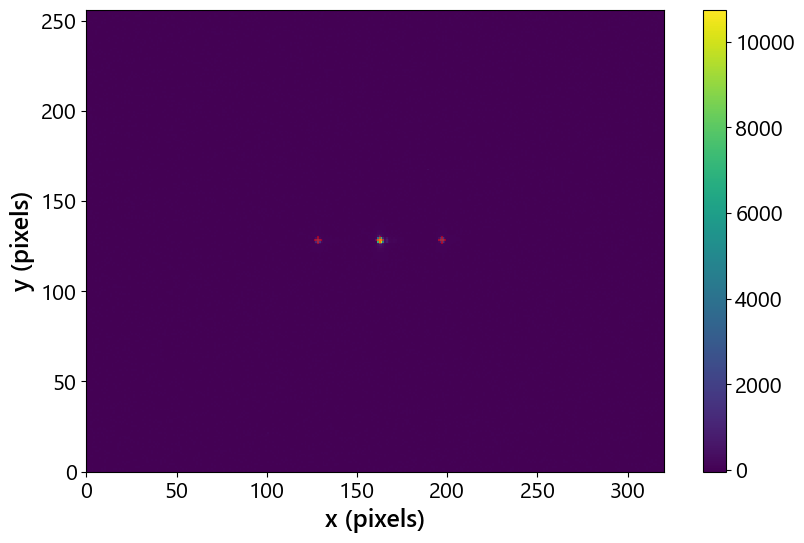

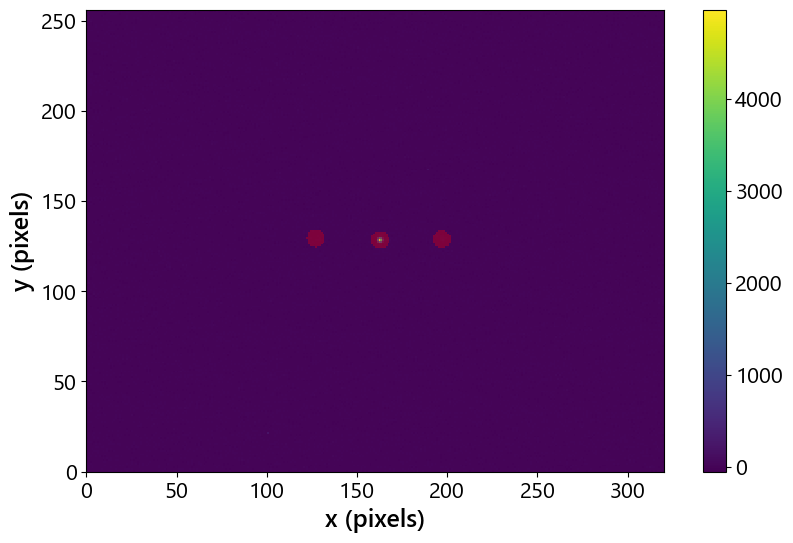

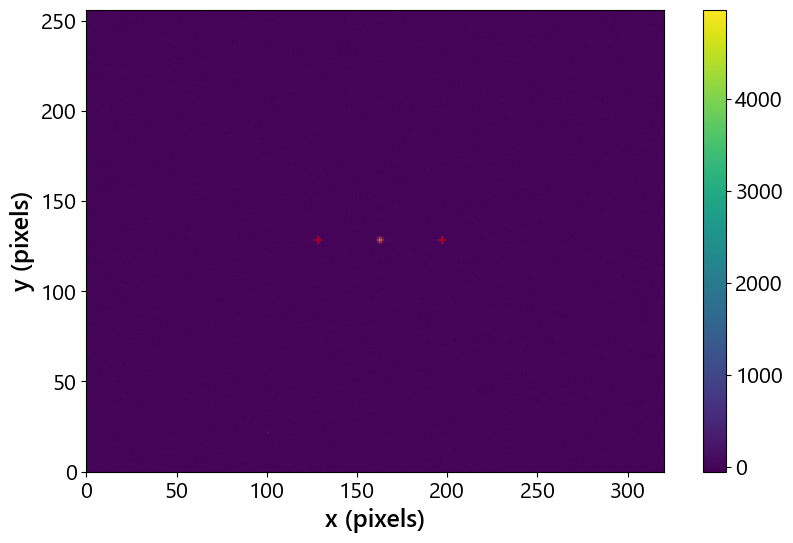

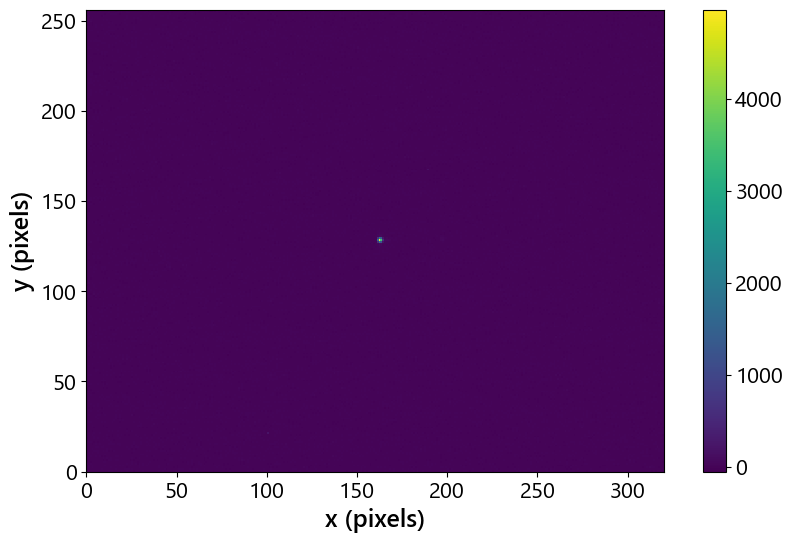

Output A


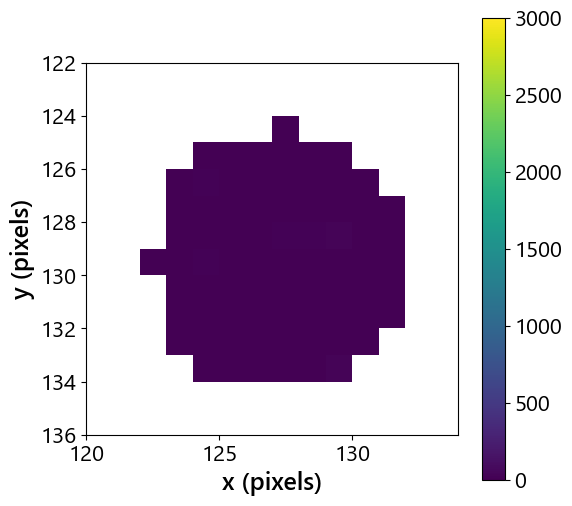

Data - Dark sum: -13.720458984375
Data peak: 4216.0


Output B


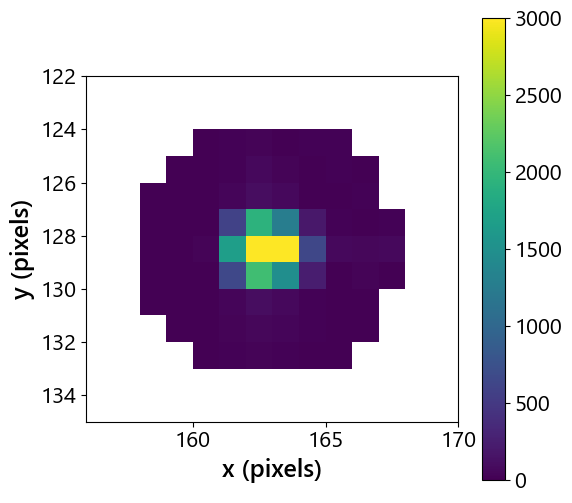

Data - Dark sum: 20417.0205078125
Data peak: 9122.0


Output C


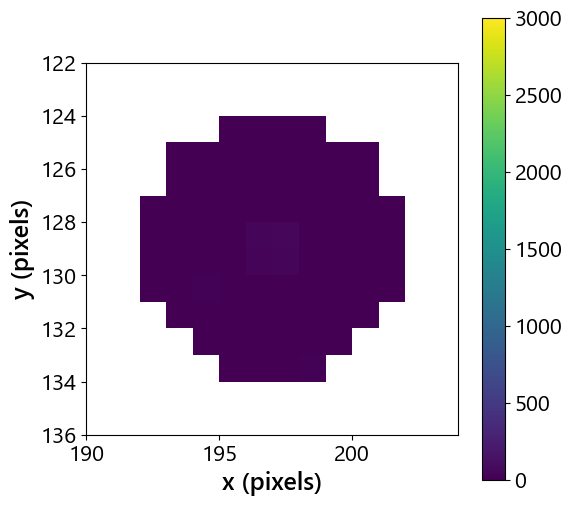

Data - Dark sum: 19.24072265625
Data peak: 4230.0




In [134]:
filename_ref = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260519\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECon_trial2\\Device5a_I15_1x3Tri_Ch66_V5p00_outputA_4p50.npy'
filename_dark = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260519\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECon_trial2\\Device5a_I15_1x3Tri_dark.csv'
num_outputs = 3

data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

filename = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260519\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECon_trial2\\Device5a_I15_1x3Tri_Ch66_V6p90_outputB_4p70.npy'
data = np.load(filename, allow_pickle=True)
masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords, mask_range=5)
# data_noStripe = PIC.remove_stripes(data[0], masks)
# dark_noStripe = PIC.remove_stripes(dark, masks)
# data_reduce = data_noStripe-dark_noStripe
# print(np.sum(data_reduce * masks, axis=(1,2)))
# print(np.nanmax(data[0] * masks, axis=(1,2)))

y_dim, x_dim = np.shape(data[0])

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data[0]-dark, zorder=0)
for coord in coords:
    ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_aspect('equal')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data[0]-dark, zorder=0)
# for coord in coords:
#     ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_aspect('equal')
plt.show()

vmax = 3000
for i in range(len(masks)):
    print(f'Output {chr(i+65)}')
    PIC.plot_masked(data[0]-dark, masks[i], vmax=vmax)
    plt.show()
    print('Data - Dark sum:', np.nansum((data[0]-dark)*masks[i]))
    print('Data peak:', np.nanmax(data[0]*masks[i]))
    print('\n')

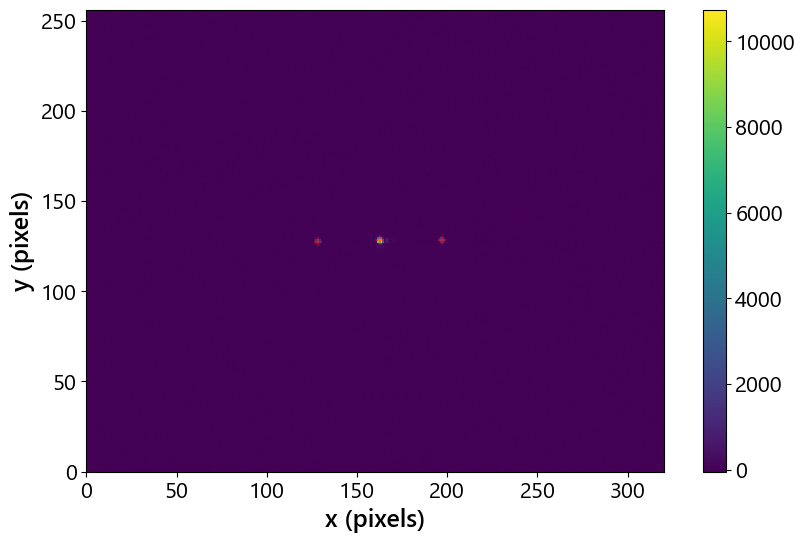

[0.0] [4.6, 4.6, 4.6]
[0.1] [4.6, 4.6, 4.6]
[0.2] [4.6, 4.6, 4.6]
[0.30000000000000004] [4.6, 4.6, 4.6]
[0.4] [4.6, 4.6, 4.6]
[0.5] [4.6, 4.6, 4.6]
[0.6000000000000001] [4.6, 4.6, 4.6]
[0.7000000000000001] [4.6, 4.6, 4.6]
[0.8] [4.6, 4.6, 4.6]
[0.9] [4.6, 4.6, 4.6]
[1.0] [4.6, 4.6, 4.6]
[1.1] [4.6, 4.6, 4.6]
[1.2000000000000002] [4.6, 4.6, 4.6]
[1.3] [4.6, 4.6, 4.6]
[1.4000000000000001] [4.6, 4.6, 4.6]
[1.5] [4.6, 4.6, 4.6]
[1.6] [4.6, 4.6, 4.6]
[1.7000000000000002] [4.6, 4.6, 4.6]
[1.8] [4.6, 4.6, 4.6]
[1.9000000000000001] [4.6, 4.6, 4.6]
[2.0] [4.6, 4.6, 4.6]
[2.1] [4.6, 4.6, 4.6]
[2.2] [4.6, 4.6, 4.6]
[2.3000000000000003] [4.6, 4.6, 4.6]
[2.4000000000000004] [4.6, 4.7, 4.6]
[2.5] [4.6, 4.7, 4.6]
[2.6] [4.6, 4.7, 4.6]
[2.7] [4.6, 4.7, 4.6]
[2.8000000000000003] [4.6, 4.7, 4.6]
[2.9000000000000004] [4.6, 4.7, 4.6]
[3.0] [4.6, 4.7, 4.6]
[3.1] [4.6, 4.7, 4.6]
[3.2] [4.6, 4.7, 4.6]
[3.3000000000000003] [4.6, 4.7, 4.6]
[3.4000000000000004] [4.6, 4.7, 4.6]
[3.5] [4.6, 4.7, 4.6]
[3.6] [4.6, 

In [159]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260519\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECon_trial1\\'
filename_root = 'Device5a_I15_1x3Tri'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 3

filename_ref = data_dir+'Device5a_I15_1x3Tri_Ch66_V4p80_outputA_4p50.npy'
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

voltages, outputs, attens, outputs_flux = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, 
                                                                  filename_dark, coords=coords, r_lin=9, 
                                                                  r_max=20, plot=False)

# np.save(f'{data_dir}{filename_root}_voltage', voltages)
# np.save(f'{data_dir}{filename_root}_outputs', outputs)
# np.save(f'{data_dir}{filename_root}_attenuation', attens)

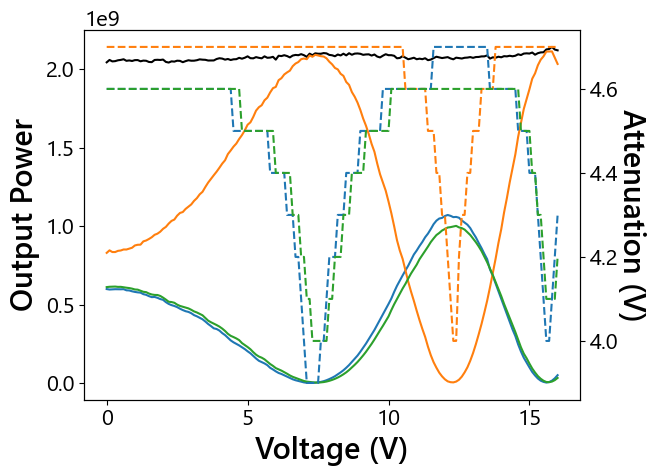

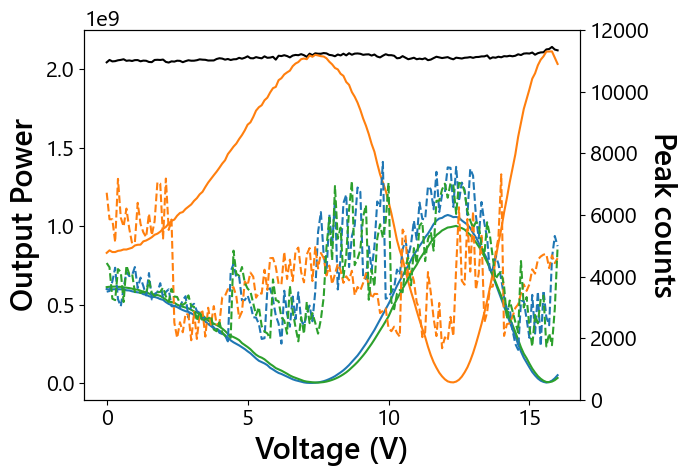

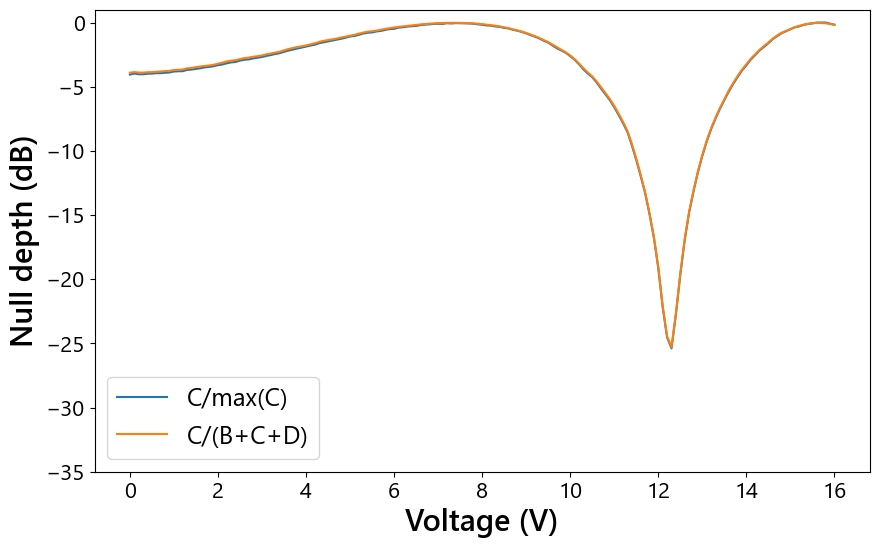

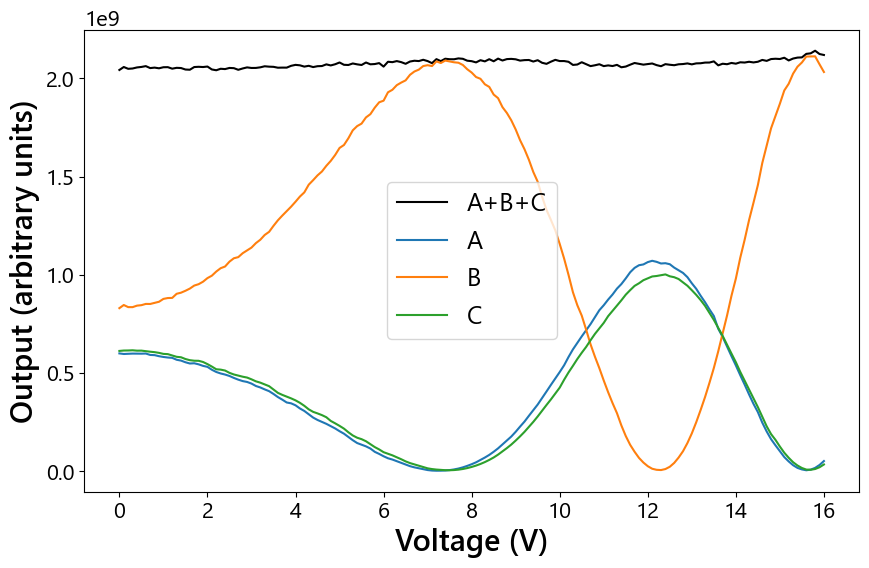

In [168]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260519\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECoff_trial2\\'
filename_root = 'Device5a_I15_1x3Tri'

voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
outputs_flux_scaled = PIC.scale_voltage_scan(outputs_flux, attens)
flux_ratio_maxC = outputs_scaled[:, 1]/np.max(outputs_scaled[:,1])
flux_ratio_BCD = outputs_scaled[:, 1]/np.sum(outputs_scaled, axis=1)
null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C')
ax1.plot(voltages, outputs_scaled)
# ax1.axvline(6.8, color='k', linestyle='dashed')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--')
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, outputs_flux, '--')
ax2.set_ylabel('Peak counts', rotation=270, labelpad=20)
ax2.set_ylim(0, 12000)
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, null_maxC, label='C/max(C)')
plt.plot(voltages, null_BCD, label='C/(B+C+D)')
plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')
plt.ylim(-35, 1)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C')
plt.plot(voltages, outputs_scaled[:,0], label='A')
plt.plot(voltages, outputs_scaled[:,1], label='B')
plt.plot(voltages, outputs_scaled[:,2], label='C')
plt.xlabel('Voltage (V)')
plt.ylabel('Output (arbitrary units)')
plt.legend()
plt.show()

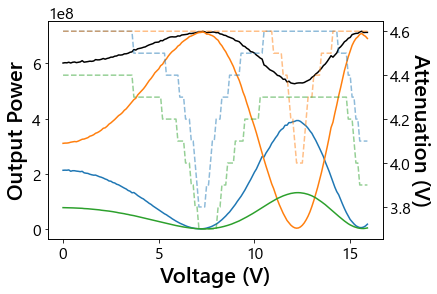

In [ ]:
voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

outputs_flux_scaled = PIC.scale_voltage_scan(outputs_flux, attens)

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_flux, axis=1), 'k', label='A+B+C')
ax1.plot(voltages, outputs_flux)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--')
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()


fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_flux_scaled, axis=1), 'k', label='A+B+C')
ax1.plot(voltages, outputs_flux_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--')
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()


fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--', alpha=0.5)
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()

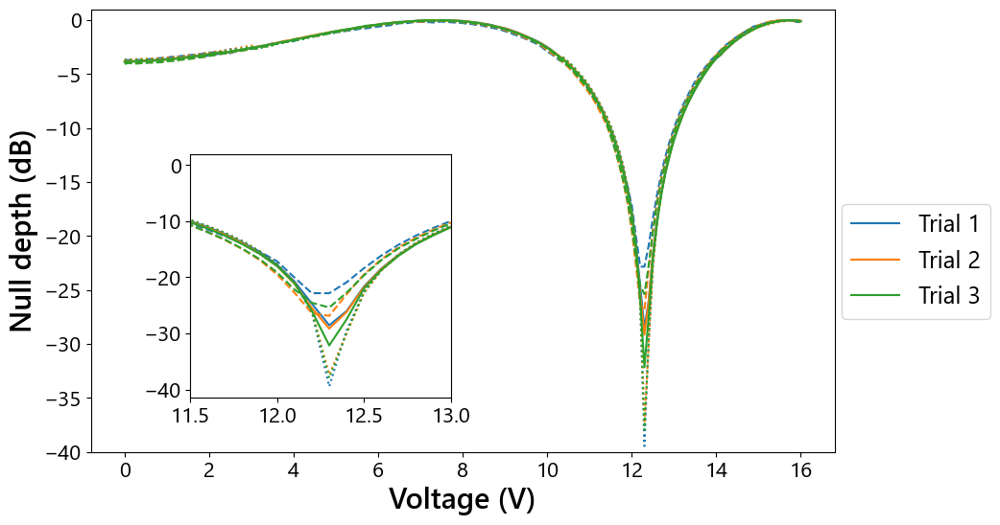

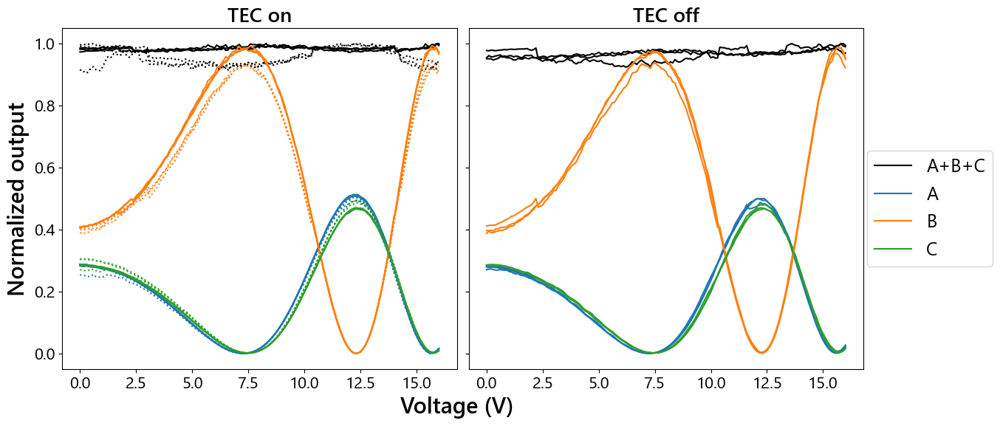

In [226]:
null_TECon, outputs_TECon = [], []
for i in range(3):
    filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260519\\voltage_scan\\{filename_root}_amoeba_TECon_trial{i}\\'
    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 1]/np.max(outputs_scaled[:,1])
    flux_ratio_BCD = outputs_scaled[:, 1]/np.sum(outputs_scaled, axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECon.append(null_maxC)
    outputs_TECon.append(outputs_scaled)

null_TECoff, outputs_TECoff = [], []
for i in range(3):
    filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260519\\voltage_scan\\{filename_root}_amoeba_TECoff_trial{i}\\'
    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 1]/np.max(outputs_scaled[:,1])
    flux_ratio_BCD = outputs_scaled[:, 1]/np.sum(outputs_scaled, axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECoff.append(null_maxC)
    outputs_TECoff.append(outputs_scaled)


null_pol, outputs_pol = [], []
for i in range(3):
    filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260521\\voltage_scan\\{filename_root}_amoeba_TECon_polarizer_trial{i}\\'
    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 1]/np.max(outputs_scaled[:,1])
    flux_ratio_BCD = outputs_scaled[:, 1]/np.sum(outputs_scaled, axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_pol.append(null_maxC)
    outputs_pol.append(outputs_scaled)


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(10,6))
for i in range(3):
    ax.plot(voltages, null_TECon[i], color=f'C{i}', label=f'Trial {i+1}')
    ax.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    ax.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Null depth (dB)')
ax.set_ylim(-40, 1)
ax.legend(loc=(1.01, 0.3))
# Inset
axins = inset_axes(ax, width="35%", height="55%", 
                   bbox_to_anchor=(-0.5, -0.3, 1, 1), bbox_transform=ax.transAxes)
for i in range(3):
    axins.plot(voltages, null_TECon[i], color=f'C{i}')
    axins.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    axins.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
axins.set_xlim(11.5, 13)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
plt.subplots_adjust(wspace=0.03)
for i in range(3):
    outputs_TECon_tot = np.sum(outputs_TECon[i], axis=1)
    outputs_TECoff_tot = np.sum(outputs_TECoff[i], axis=1)
    outputs_pol_tot = np.sum(outputs_pol[i], axis=1)       

    if i==0:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k', label='A+B+C')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}', label=f'{chr(65+j)}')
    else:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}')

ax[0].set_title('TEC on')
ax[1].set_title('TEC off')
ax[0].set_xlabel('Voltage (V)', labelpad=1.5)
ax[0].set_ylabel('Normalized output')
ax[0].xaxis.set_label_coords(1.0, -0.08)
ax[1].legend(loc=(1.01, 0.3))
plt.show()

### Device 6a

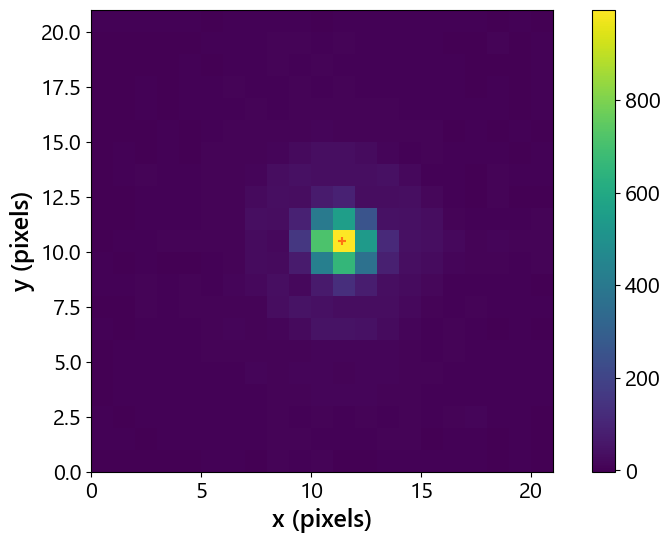

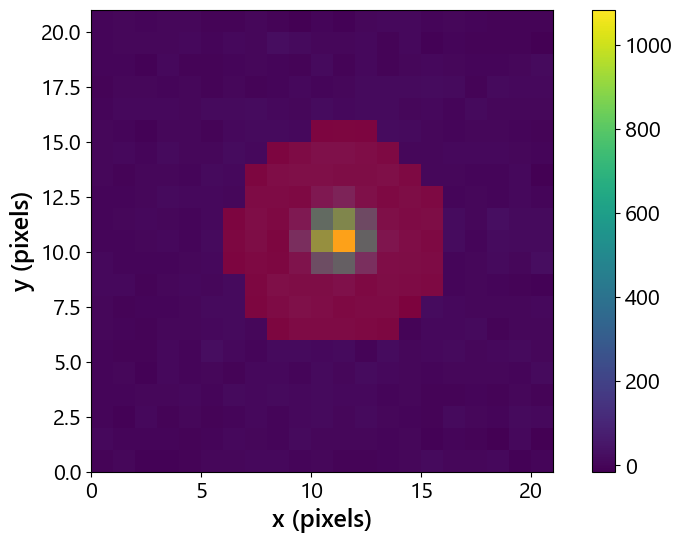

([10.032, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p500_Ch62_V10p032_Ch41_V0p000_outputA_43p000.npy')
([10.032, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p500_Ch62_V10p032_Ch41_V0p100_outputA_43p000.npy')
([10.032, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p500_Ch62_V10p032_Ch41_V0p250_outputA_43p000.npy')
([10.032, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p500_Ch62_V10p032_Ch41_V0p475_outputA_43p000.npy')
([10.032, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p500

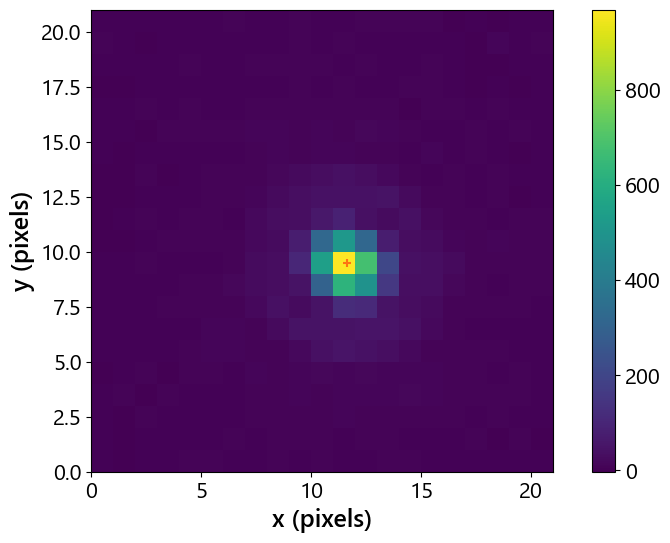

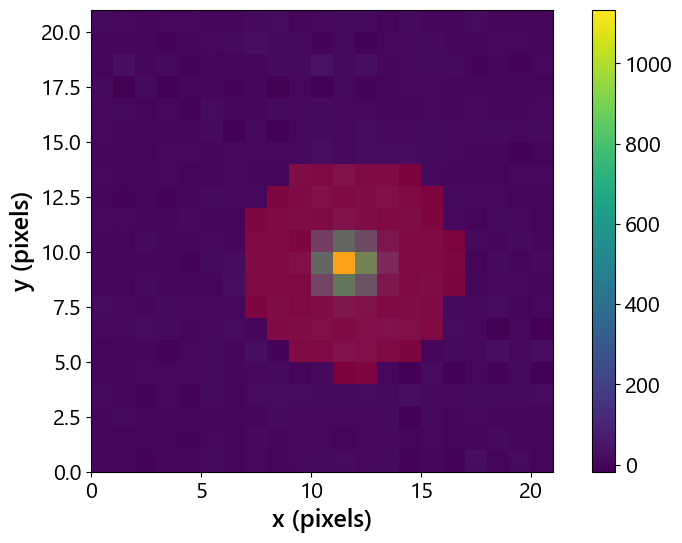

([10.192, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p750_Ch62_V10p192_Ch41_V0p000_outputA_43p000.npy')
([10.192, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p750_Ch62_V10p192_Ch41_V0p100_outputA_43p000.npy')
([10.192, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p750_Ch62_V10p192_Ch41_V0p250_outputA_43p000.npy')
([10.192, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V9p750_Ch62_V10p192_Ch41_V0p475_outputA_43p000.npy')
([10.192, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V9p750

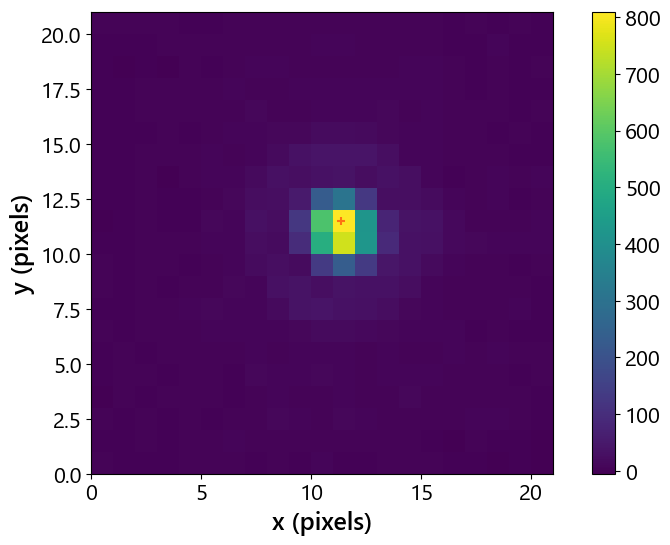

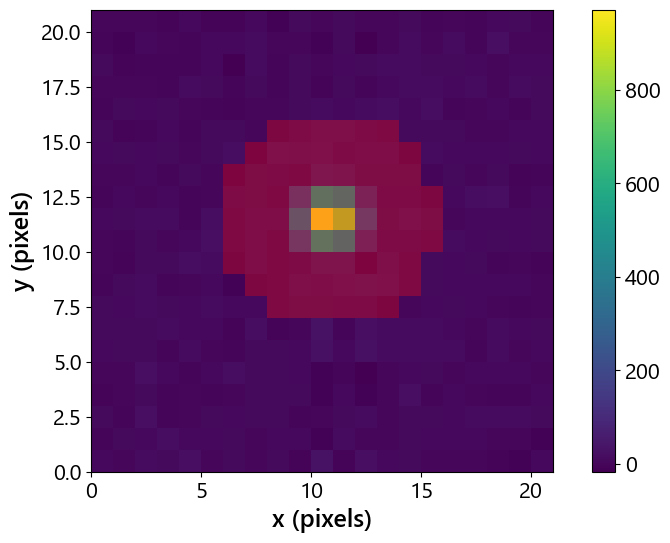

([10.463, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p463_Ch41_V0p000_outputA_43p000.npy')
([10.463, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p463_Ch41_V0p100_outputA_43p000.npy')
([10.463, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p463_Ch41_V0p250_outputA_43p000.npy')
([10.463, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p463_Ch41_V0p475_outputA_43p000.npy')
([10.463, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch6

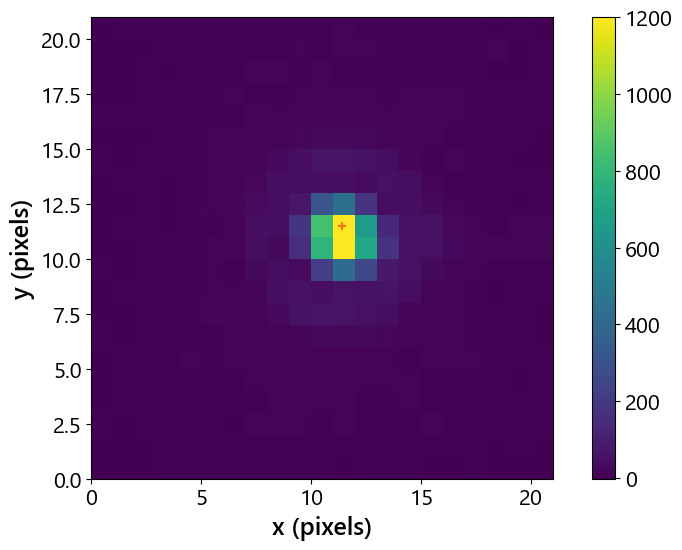

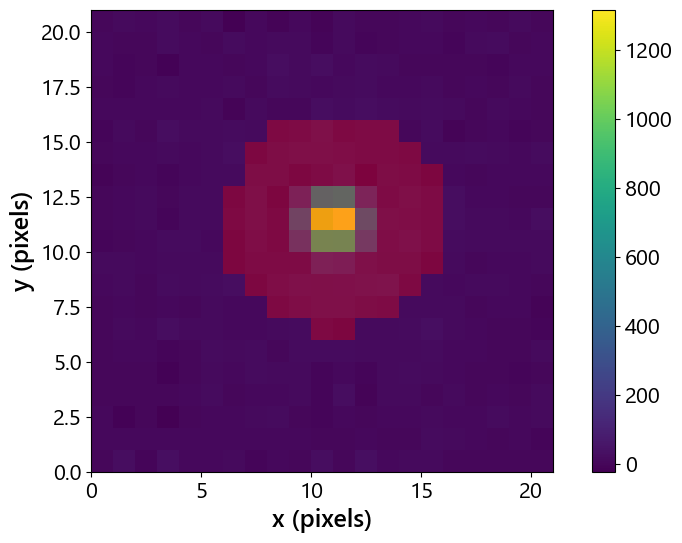

([10.723, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p250_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p250_Ch62_V10p723_Ch41_V0p000_outputA_40p000.npy')
([10.723, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p250_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p250_Ch62_V10p723_Ch41_V0p100_outputA_40p000.npy')
([10.723, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p250_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p250_Ch62_V10p723_Ch41_V0p250_outputA_40p000.npy')
([10.723, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p250_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p250_Ch62_V10p723_Ch41_V0p475_outputA_40p000.npy')
([10.723, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch6

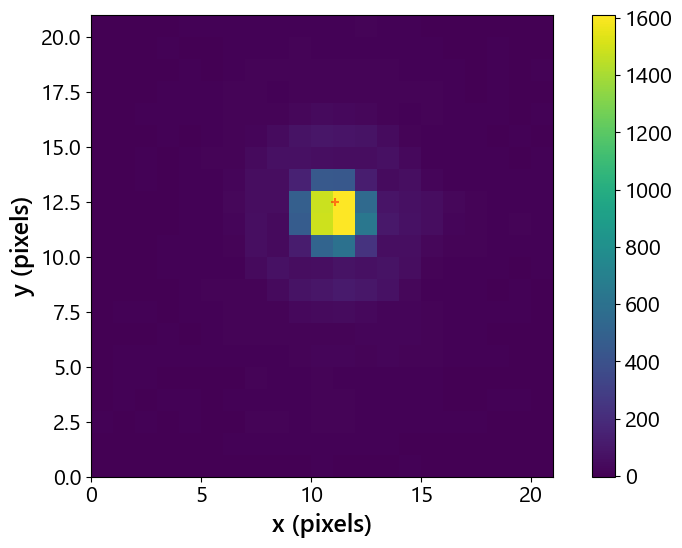

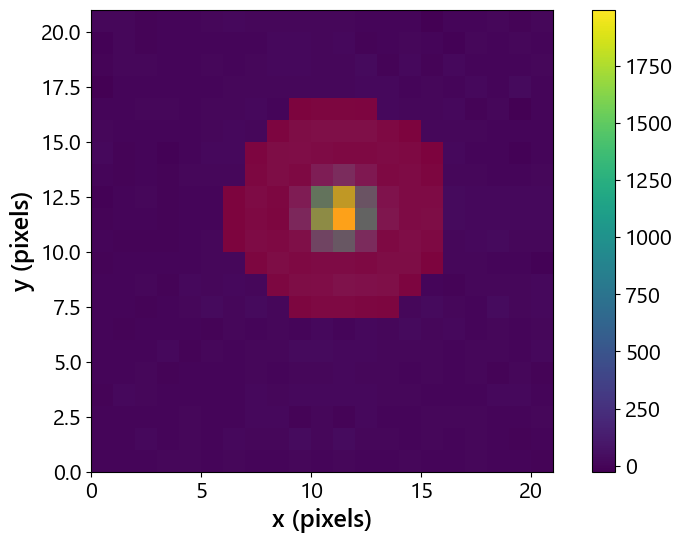

([10.992, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p500_Ch62_V10p992_Ch41_V0p000_outputA_40p000.npy')
([10.992, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p500_Ch62_V10p992_Ch41_V0p100_outputA_40p000.npy')
([10.992, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p500_Ch62_V10p992_Ch41_V0p250_outputA_40p000.npy')
([10.992, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p500_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p500_Ch62_V10p992_Ch41_V0p475_outputA_40p000.npy')
([10.992, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch6

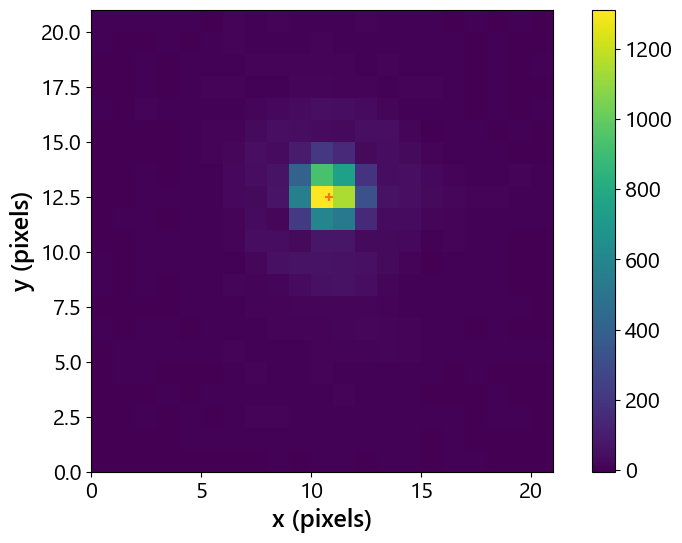

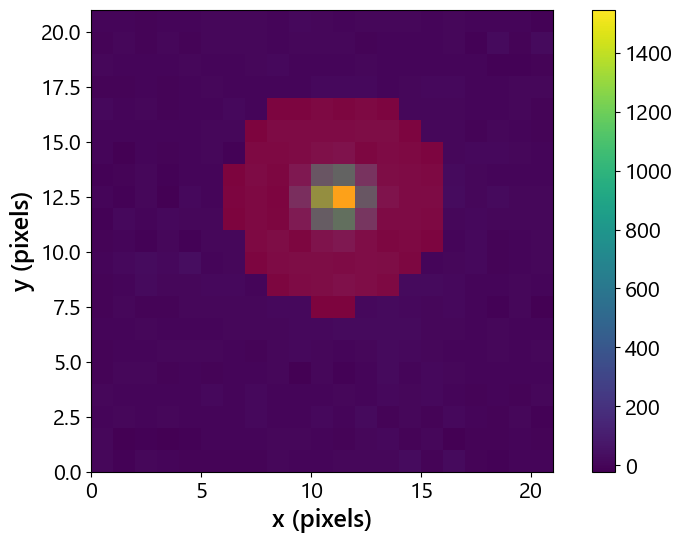

([11.199, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p750_Ch62_V11p199_Ch41_V0p000_outputA_43p000.npy')
([11.199, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p750_Ch62_V11p199_Ch41_V0p100_outputA_43p000.npy')
([11.199, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p750_Ch62_V11p199_Ch41_V0p250_outputA_43p000.npy')
([11.199, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V10p750_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V10p750_Ch62_V11p199_Ch41_V0p475_outputA_43p000.npy')
([11.199, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch6

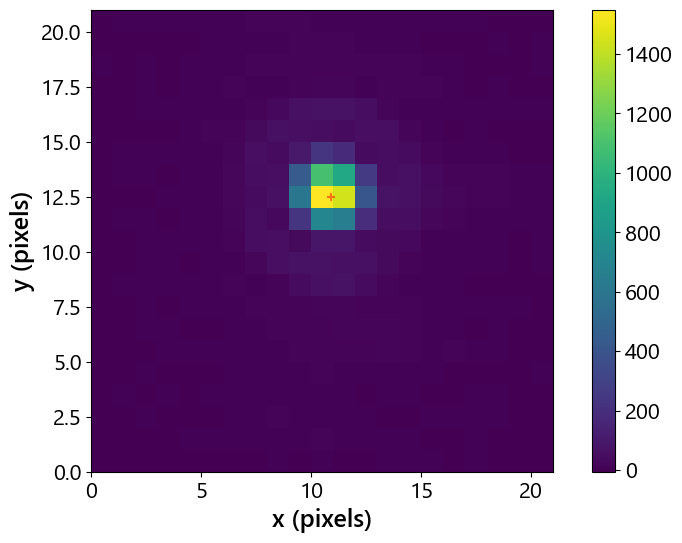

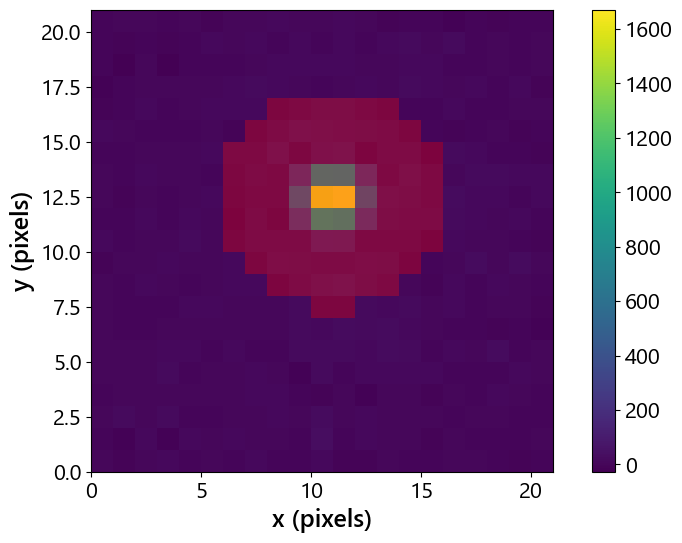

([11.271, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V11p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V11p000_Ch62_V11p271_Ch41_V0p000_outputA_43p000.npy')
([11.271, 0.1], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V11p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V11p000_Ch62_V11p271_Ch41_V0p100_outputA_43p000.npy')
([11.271, 0.25], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V11p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V11p000_Ch62_V11p271_Ch41_V0p250_outputA_43p000.npy')
([11.271, 0.475], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch61_V11p000_TECon_polarizer\\voltage_scan\\Device6a_I18_1x5Tri_Ch61_V11p000_Ch62_V11p271_Ch41_V0p475_outputA_43p000.npy')
([11.271, 0.812], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260916\\voltage_scan_Ch6

In [51]:
from Bench import BENCH
device_name, num_outputs = f'Device6a_I18_1x5Tri', 1
PS1_arr = np.arange(9.5, 11.01, 0.25)

for PS1 in PS1_arr:
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch61_V{PS1_str}'
    
    data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260916\\voltage_scan_Ch61_V{PS1_str}_TECon_polarizer\\voltage_scan\\'
    filename_ref = glob.glob(data_dir+'*[0-9].npy')[0]
    filename_dark = glob.glob(data_dir+'*dark*')[0]

    data = np.load(filename_ref, allow_pickle=True)#, 
    dark = np.loadtxt(filename_dark, delimiter=',')
    coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
    masks = BENCH.build_output_mask(data[0]-dark, num_outputs, coords, mask_range=5)

    voltages, outputs, attens, outputs_flux, labels = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                                coords=coords, r_lin=5, r_max=15, plot=False, 
                                                                                movie_filename=data_dir+filename_root+'_inspect.mp4', movie_dpi=120)

    np.save(f'{data_dir}{filename_root}_voltage', voltages)
    np.save(f'{data_dir}{filename_root}_outputs', outputs)
    np.save(f'{data_dir}{filename_root}_attenuation', attens)

ValueError: All-NaN slice encountered

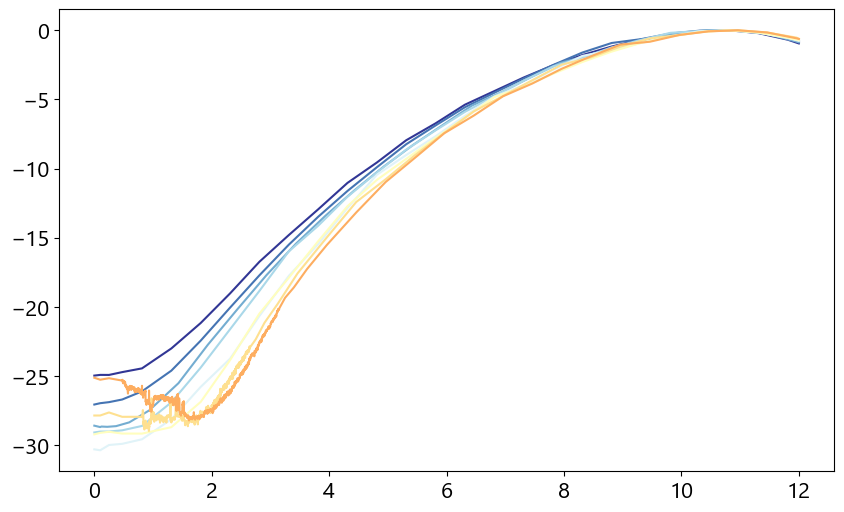

In [ ]:
import io
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from PIL import Image

device_name, num_outputs = f'Device6a_I18_1x5Tri', 1
PS1_arr = np.arange(9.5, 11.1, 0.25)
INSET_HALFWIDTH = 0.5           # V either side of the deepest null
data_root = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260916\\'
GIF_FILENAME = f'{data_root}null_vs_PS1.gif'
GIF_FPS = 1

gif_frames = []

# Per PS1: deepest null over all PS2 curves, and where it occurred
best_depth = np.full(len(PS1_arr), np.nan)      # dB
best_v_PS3 = np.full(len(PS1_arr), np.nan)      # V, adaptive channel
best_v_PS2 = np.full(len(PS1_arr), np.nan)      # V, curve the minimum came from

# Per PS1 and PS2: minimum of each individual curve
depths_all = []                                  # list of arrays, one per PS1
v_PS3_all = []
V_PS2_all = []

for k, PS1 in enumerate(PS1_arr):
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch61_V{PS1_str}'
    data_dir = f'{data_root}voltage_scan_Ch61_V{PS1_str}_TECon_polarizer\\voltage_scan\\'

    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    V_PS2 = np.sort(list(set(voltages[:, 0])))
    V_PS2_sets = [voltages[:, 0] == V for V in V_PS2]
    outputs_scaled = outputs * 10**(attens/10)

    fig, ax = plt.subplots(figsize=(10, 6))

    cmap = plt.get_cmap('RdYlBu_r')
    norm = Normalize(vmin=min(V_PS2), vmax=max(V_PS2))

    null_depths = np.full(len(V_PS2), np.nan)    # minimum of each PS2 curve
    null_v_PS3 = np.full(len(V_PS2), np.nan)     # PS3 voltage at each minimum

    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        v_curve = voltages[:, 1][V_PS2_sets[i]]
        null_curve = 10*np.log10(output_V/np.max(output_V))
        ax.plot(v_curve, null_curve, color=cmap(norm(V)))
        
        j = np.nanargmin(null_curve)
        null_depths[i] = null_curve[j]
        null_v_PS3[i] = v_curve[j]

    # Deepest null across all PS2 curves for this PS1
    i_best = np.nanargmin(null_depths)
    best_depth[k] = null_depths[i_best]
    best_v_PS3[k] = null_v_PS3[i_best]
    best_v_PS2[k] = V_PS2[i_best]

    depths_all.append(null_depths)
    v_PS3_all.append(null_v_PS3)
    V_PS2_all.append(V_PS2)

    ax.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    ax.set_ylim(-60, 0)

    # Inset
    axins = inset_axes(ax, width="35%", height="55%",
                       bbox_to_anchor=(-0.1, -0.25, 1, 1), bbox_transform=ax.transAxes)
    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        axins.plot(voltages[:, 1][V_PS2_sets[i]],
                   10*np.log10(output_V/np.max(output_V)), color=cmap(norm(V)))
    axins.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    axins.set_xlim(best_v_PS3[k] - INSET_HALFWIDTH, best_v_PS3[k] + INSET_HALFWIDTH)
    axins.set_ylim(-60, 0)

    ax.set_xlabel('PS3 voltage (V)')
    ax.set_ylabel('C/max(C) (dB)')
    ax.set_title(f'PS1 = {PS1} V')

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('PS2 (V)', rotation=270, labelpad=20)

    # Frozen bbox from the first figure keeps every frame the same size
    fig.canvas.draw()
    if not gif_frames:
        gif_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.1)

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=120, bbox_inches=gif_bbox, facecolor='white')
    buf.seek(0)
    gif_frames.append(Image.open(buf).convert('RGB'))

    plt.show()

gif_frames[0].save(GIF_FILENAME, save_all=True, append_images=gif_frames[1:],
                   duration=int(1000/GIF_FPS), loop=0)
print(f'wrote {len(gif_frames)} frames to {GIF_FILENAME}\n')

# Summary
print(f'{"PS1 (V)":>9}  {"null (dB)":>10}  {"PS3 (V)":>9}  {"PS2 (V)":>9}')
for k, PS1 in enumerate(PS1_arr):
    print(f'{PS1:9.3f}  {best_depth[k]:10.2f}  {best_v_PS3[k]:9.3f}  {best_v_PS2[k]:9.3f}')

PS1 = 9.5 V: 1 of 5119 points are NaN (unreadable images)


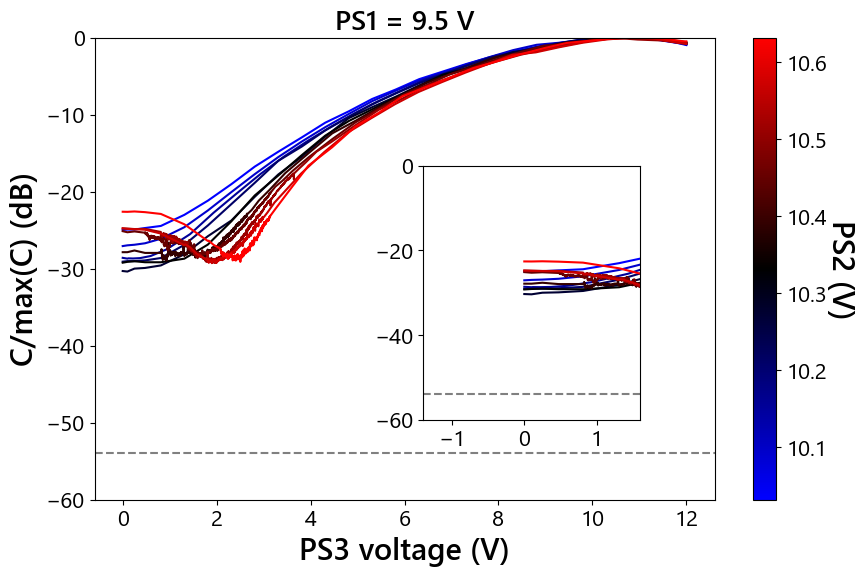

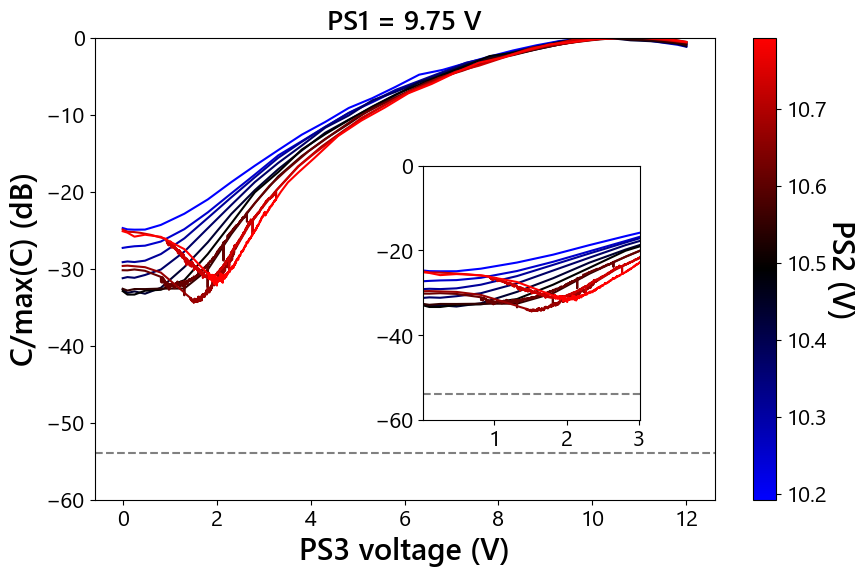

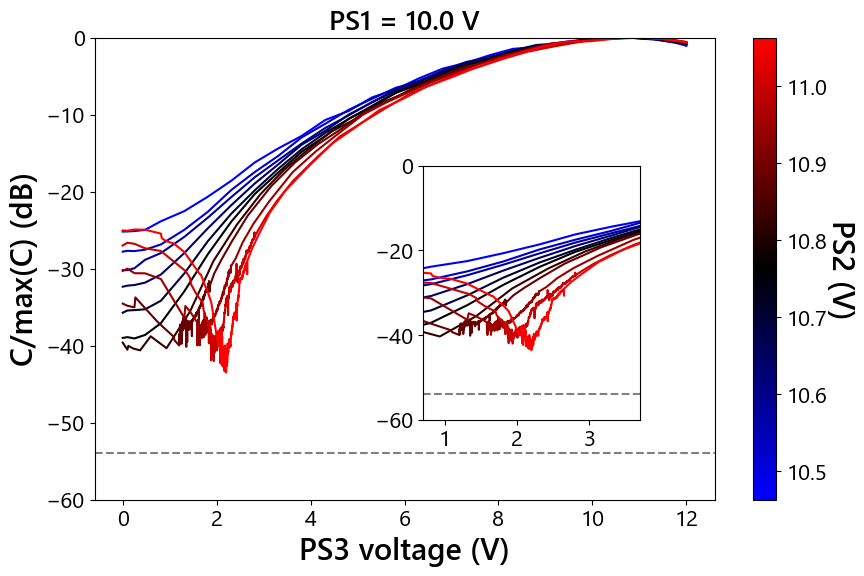

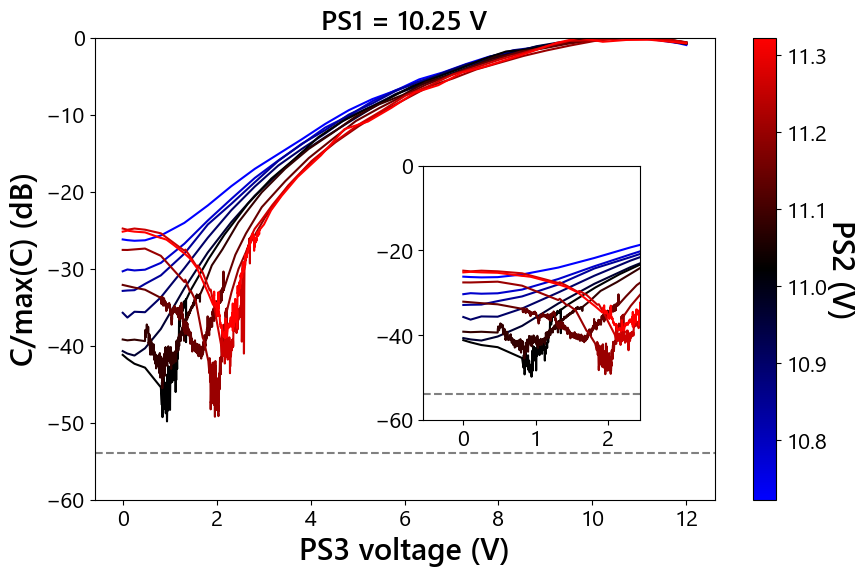

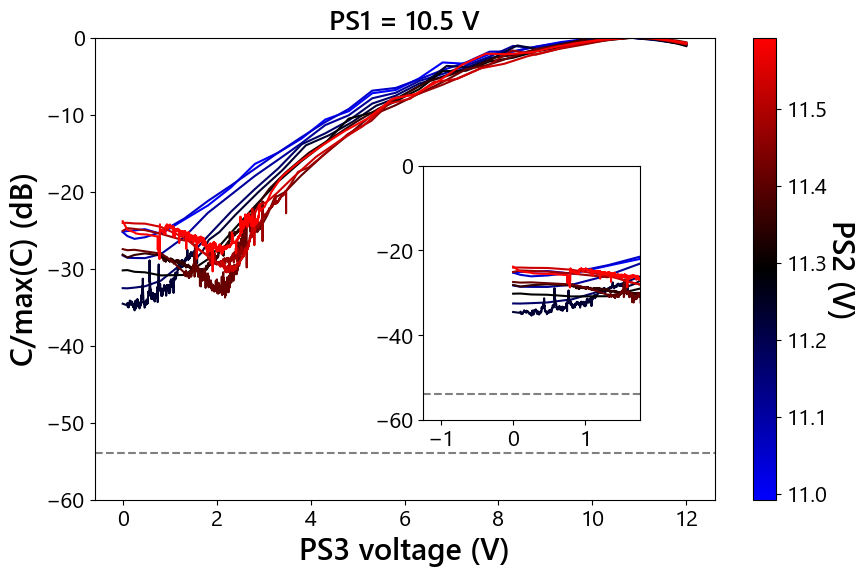

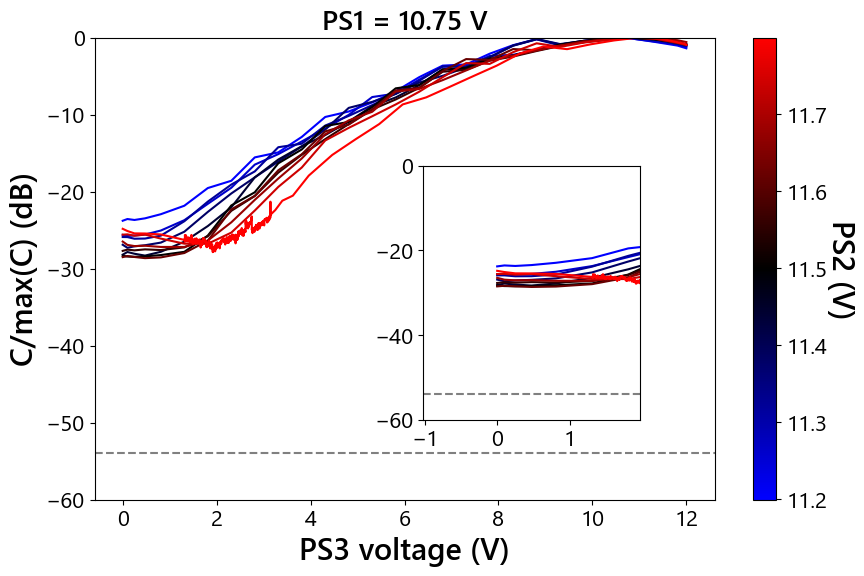

PS1 = 11.0 V: 18 of 2900 points are NaN (unreadable images)


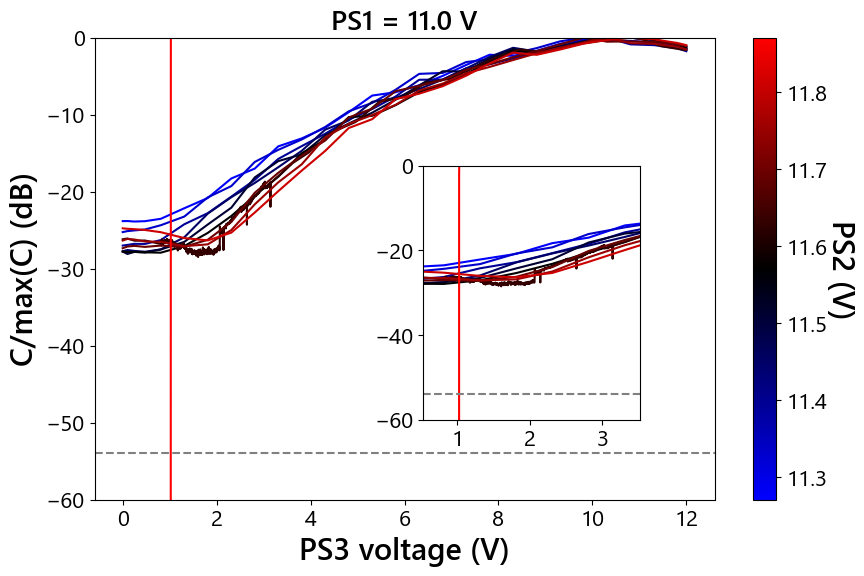

wrote 7 frames to D:\Active_PIC\Data\PhotometryScans\Device6a_I18_1x5Tri\20260916\null_vs_PS1.gif

Output A
  PS1 (V)   null (dB)    PS3 (V)    PS2 (V)
    9.500      -30.37      0.100     10.272
    9.750      -34.41      1.513     10.672
   10.000      -43.48      2.201     11.063
   10.250      -49.83      0.943     11.023
   10.500      -35.40      0.254     11.232
   10.750      -28.63      0.475     11.619
   11.000     -349.46      2.024     11.871


In [60]:
import io
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

device_name, num_outputs = f'Device6a_I18_1x5Tri', 1
IND_OUTPUT = 0                  # which output port to analyse
PS1_arr = np.arange(9.5, 11.1, 0.25)
INSET_HALFWIDTH = 1.5           # V either side of the deepest null
data_root = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260916\\'
GIF_FILENAME = f'{data_root}null_vs_PS1.gif'
GIF_FPS = 1

gif_frames = []
gif_bbox = None

# Per PS1: deepest null over all PS2 curves, and where it occurred
best_depth = np.full(len(PS1_arr), np.nan)      # dB
best_v_PS3 = np.full(len(PS1_arr), np.nan)      # V, adaptive channel
best_v_PS2 = np.full(len(PS1_arr), np.nan)      # V, curve the minimum came from

# Per PS1 and PS2: minimum of each individual curve
depths_all = []                                  # list of arrays, one per PS1
v_PS3_all = []
V_PS2_all = []

for k, PS1 in enumerate(PS1_arr):
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch61_V{PS1_str}'
    data_dir = f'{data_root}voltage_scan_Ch61_V{PS1_str}_TECon_polarizer\\voltage_scan\\'

    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    V_PS2 = np.sort(list(set(voltages[:, 0])))
    V_PS2_sets = [voltages[:, 0] == V for V in V_PS2]

    # Select the output column here: outputs and attens are (n_points,
    # num_outputs), so keeping the second axis leaves every downstream array 2D
    # and boolean indexing against a 1D voltage mask fails.
    outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

    n_bad = int(np.isnan(outputs_scaled).sum())
    if n_bad:
        print(f'PS1 = {PS1} V: {n_bad} of {len(outputs_scaled)} points are NaN '
              '(unreadable images)')

    fig, ax = plt.subplots(figsize=(10, 6))

    # cmap = plt.get_cmap('RdYlBu_r')
    cmap = LinearSegmentedColormap.from_list('bkr', ['blue', 'black', 'red'])
    norm = Normalize(vmin=min(V_PS2), vmax=max(V_PS2))

    null_depths = np.full(len(V_PS2), np.nan)    # minimum of each PS2 curve
    null_v_PS3 = np.full(len(V_PS2), np.nan)     # PS3 voltage at each minimum
    curves = []                                  # (v_curve, null_curve) for the inset

    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        v_curve = voltages[:, 1][V_PS2_sets[i]]

        # nanmax, not max: one NaN anywhere in the slice would otherwise make
        # the whole normalised curve NaN, even where the data is good.
        with np.errstate(divide='ignore', invalid='ignore'):
            if np.all(np.isnan(output_V)):
                null_curve = np.full(len(output_V), np.nan)
            else:
                null_curve = 10*np.log10(output_V/np.nanmax(output_V))

        ax.plot(v_curve, null_curve, color=cmap(norm(V)))
        curves.append((v_curve, null_curve))

        # An unreadable image leaves NaN in outputs, so a curve can be entirely
        # empty; nanargmin raises on an all-NaN slice rather than returning NaN.
        if np.all(np.isnan(null_curve)):
            print(f'  PS2 = {V:.3f} V: no valid points, skipping')
            continue

        j = np.nanargmin(null_curve)
        null_depths[i] = null_curve[j]
        null_v_PS3[i] = v_curve[j]

    depths_all.append(null_depths)
    v_PS3_all.append(null_v_PS3)
    V_PS2_all.append(V_PS2)

    # Deepest null across all PS2 curves for this PS1
    if np.all(np.isnan(null_depths)):
        print(f'PS1 = {PS1} V: no valid curves, no frame written')
        plt.close(fig)
        continue

    i_best = np.nanargmin(null_depths)
    best_depth[k] = null_depths[i_best]
    best_v_PS3[k] = null_v_PS3[i_best]
    best_v_PS2[k] = V_PS2[i_best]

    ax.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    ax.set_ylim(-60, 0)

    # Inset, reusing the curves already computed above
    axins = inset_axes(ax, width="35%", height="55%",
                       bbox_to_anchor=(-0.1, -0.25, 1, 1), bbox_transform=ax.transAxes)
    for i, V in enumerate(V_PS2):
        v_curve, null_curve = curves[i]
        axins.plot(v_curve, null_curve, color=cmap(norm(V)))
    axins.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    axins.set_xlim(best_v_PS3[k] - INSET_HALFWIDTH, best_v_PS3[k] + INSET_HALFWIDTH)
    axins.set_ylim(-60, 0)

    ax.set_xlabel('PS3 voltage (V)')
    ax.set_ylabel('C/max(C) (dB)')
    ax.set_title(f'PS1 = {PS1} V')

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('PS2 (V)', rotation=270, labelpad=20)

    # Frozen bbox from the first figure keeps every frame the same size
    fig.canvas.draw()
    if gif_bbox is None:
        gif_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.1)

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=120, bbox_inches=gif_bbox, facecolor='white')
    buf.seek(0)
    gif_frames.append(Image.open(buf).convert('RGB'))

    plt.show()

if gif_frames:
    gif_frames[0].save(GIF_FILENAME, save_all=True, append_images=gif_frames[1:],
                       duration=int(1000/GIF_FPS), loop=0)
    print(f'wrote {len(gif_frames)} frames to {GIF_FILENAME}\n')
else:
    print('no valid frames, no GIF written\n')

# Summary
print(f'Output {chr(65+IND_OUTPUT)}')
print(f'{"PS1 (V)":>9}  {"null (dB)":>10}  {"PS3 (V)":>9}  {"PS2 (V)":>9}')
for k, PS1 in enumerate(PS1_arr):
    print(f'{PS1:9.3f}  {best_depth[k]:10.2f}  {best_v_PS3[k]:9.3f}  {best_v_PS2[k]:9.3f}')

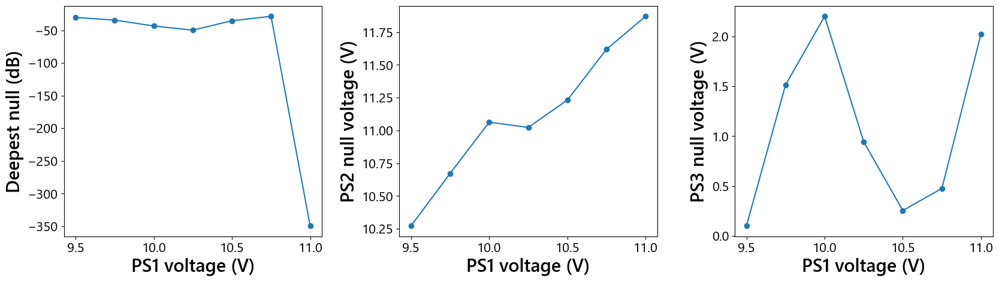

In [61]:
# Null depth vs PS1
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
plt.subplots_adjust(wspace=0.3)
ax[0].plot(PS1_arr, best_depth, 'o-')
# ax[0].plot(PS1_arr[ind], best_depth[ind], 'o-')
ax[0].set_xlabel('PS1 voltage (V)')
ax[0].set_ylabel('Deepest null (dB)')

ax[1].plot(PS1_arr, best_v_PS2, 'o-')
# ax[1].plot(PS1_arr[ind], best_v_PS2[ind], 'o-')
ax[1].set_xlabel('PS1 voltage (V)')
ax[1].set_ylabel('PS2 null voltage (V)')

ax[2].plot(PS1_arr, best_v_PS3, 'o-')
# ax[2].plot(PS1_arr[ind], best_v_PS3[ind], 'o-')
ax[2].set_xlabel('PS1 voltage (V)')
ax[2].set_ylabel('PS3 null voltage (V)')
plt.show()

Laser scan

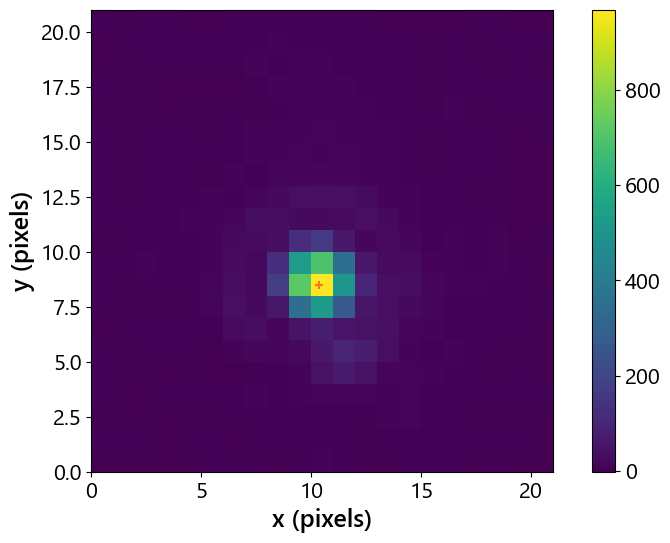

 1575.000 nm  [9.926, 0.002]  [43.]
 1575.000 nm  [9.926, 0.004]  [43.]
 1575.000 nm  [9.926, 0.006]  [43.]
 1575.000 nm  [9.926, 0.008]  [43.]
 1575.000 nm  [9.926, 0.01]  [43.]
 1575.000 nm  [9.926, 0.012]  [43.]
 1575.000 nm  [9.926, 0.014]  [43.]
 1575.000 nm  [9.926, 0.016]  [43.]
 1575.000 nm  [9.926, 0.018]  [43.]
 1575.000 nm  [9.926, 0.02]  [43.]
 1575.000 nm  [9.926, 0.022]  [43.]
 1575.000 nm  [9.926, 0.024]  [43.]
 1575.000 nm  [9.926, 0.026]  [43.]
 1575.000 nm  [9.926, 0.028]  [43.]
 1575.000 nm  [9.926, 0.03]  [43.]
 1575.000 nm  [9.926, 0.032]  [43.]
 1575.000 nm  [9.926, 0.034]  [43.]
 1575.000 nm  [9.926, 0.036]  [43.]
 1575.000 nm  [9.926, 0.038]  [43.]
 1575.000 nm  [9.926, 0.04]  [43.]
 1575.000 nm  [9.926, 0.042]  [43.]
 1575.000 nm  [9.926, 0.044]  [43.]
 1575.000 nm  [9.926, 0.046]  [43.]
 1575.000 nm  [9.926, 0.048]  [43.]
 1575.000 nm  [9.926, 0.05]  [43.]
 1575.000 nm  [9.926, 0.052]  [43.]
 1575.000 nm  [9.926, 0.054]  [43.]
 1575.000 nm  [9.926, 0.056]  [43

In [19]:
data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260914\\laser_scan\\Device6a_I18_1x5Tri_Ch61_V9p000_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device6a_I18_1x5Tri_Ch61_V9p000'
filename_root = f'{device_name}'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 1

filename_ref = glob.glob(f'{data_dir}//*[0-9].npy')[0]
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
# masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords)

wavs, voltage_coords, outputs, attens, output_fluxes, labels = PIC.reduce_laser_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                              coords=coords, movie_root=data_dir+filename_root, 
                                                                              movie_dpi=120, movie_clim=(0, np.max(np.mean(data, axis=0)-dark)))

np.save(f'{data_dir}{filename_root}_wav', wavs)
np.save(f'{data_dir}{filename_root}_voltage', voltage_coords)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.animation import FuncAnimation, PillowWriter

data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260914\\laser_scan\\Device6a_I18_1x5Tri_Ch61_V9p000_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device6a_I18_1x5Tri_Ch61_V9p000'
filename_root = f'{device_name}'
wavs = np.load(f'{data_dir}{filename_root}_wav.npy')
voltage_coords = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

IND_OUTPUT = 0
IND_X = 1              # channel whose voltage is the x-axis

wav_ref = 1590
wav_vals = np.sort(list(set(wavs)))
wav_sets = [wavs == w for w in wav_vals]

outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

cmap_orig = plt.get_cmap('RdYlBu_r', 256)
blue = cmap_orig(0.0)
red = cmap_orig(1.0)
yellow = '#f2d675'  # soft yellow, keeps the transition smooth without passing through white
cmap = LinearSegmentedColormap.from_list('blue_yellow_red_smooth', [blue, yellow, red], N=256)
norm = Normalize(vmin=min(wav_vals), vmax=max(wav_vals))

# Precompute all curves, null depths, and null positions up front
curves = []
null_depths = []
null_positions = []
for i, w in enumerate(wav_vals):
    sel = wav_sets[i]
    order = np.argsort(voltage_coords[sel, IND_X])
    v = voltage_coords[sel, IND_X][order]
    output_w = outputs_scaled[sel][order]
    null_curve = 10*np.log10(output_w/np.nanmax(output_w))
    curves.append((v, null_curve))
    idx_min = np.argmin(null_curve)
    null_positions.append(v[idx_min])
    

voltages_ref = curves[int(np.argwhere(wav_vals == wav_ref))][0]
curve_ref = curves[int(np.argwhere(wav_vals == wav_ref))][1]
ind_null = np.argmin(curve_ref)
null_depths_theory = ((np.pi**2)/4)*((wav_vals-wav_ref)/wav_ref)**2
null_depths_theory = 10*np.log10(null_depths_theory)

for i, w in enumerate(wav_vals):
    null_curve = curves[i][1]
    null_depths.append(null_curve[ind_null])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 6))
plt.subplots_adjust(wspace=0.5)

# --- Panel 1: sweep curve (static elements) ---
all_v = np.concatenate([v for v, _ in curves])
ax1.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
ax1.set_xlim(all_v.min(), all_v.max())
ax1.set_ylim(-60, 0)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('C/max(C) (dB)')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=28)

scat = ax1.scatter([], [], marker='.')

# --- Panel 2: null depth vs wavelength (static elements) ---
ax2.plot(wav_vals, null_depths, '-', color='lightgray', zorder=1)
ax2.plot(wav_vals, null_depths_theory, '--', color='black', zorder=1)
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Null depth (dB)')
ax2.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
ax2.set_ylim(min(null_depths) - 2, max(null_depths) + 2)
title = ax2.set_title('')

null_scat = ax2.scatter([], [], s=80, zorder=2, edgecolor='k')

# --- Panel 3: null position vs wavelength (static elements) ---
ax3.plot(wav_vals, null_positions, '-', color='lightgray', zorder=1)
ax3.set_xlabel('Wavelength (nm)')
ax3.set_ylabel('Minimum position (V)')
ax3.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
pos_range = max(null_positions) - min(null_positions)
pad = pos_range * 0.1 if pos_range > 0 else 0.5
ax3.set_ylim(min(null_positions) - pad, max(null_positions) + pad)

pos_scat = ax3.scatter([], [], s=80, zorder=2, edgecolor='k')

def update(frame):
    # Panel 1: this frame's curve only
    v, null_curve = curves[frame]
    w = wav_vals[frame]
    scat.set_offsets(np.column_stack([v, null_curve]))
    scat.set_color(cmap(norm(w)))
    title.set_text(f'Wavelength = {w:.2f} nm')

    # Panel 2: accumulate null depth points up through this frame
    null_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_depths[:frame+1]]))
    null_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    # Panel 3: accumulate null position points up through this frame
    pos_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_positions[:frame+1]]))
    pos_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    return scat, title, null_scat, pos_scat

anim = FuncAnimation(fig, update, frames=len(wav_vals), interval=200, blit=False)

anim.save(f'{data_dir}{filename_root}_wavelength_sweep.gif', writer=PillowWriter(fps=1))
plt.close(fig)
print("Saved wavelength_sweep.gif")

C:\Users\Pradip\AppData\Local\Temp\ipykernel_13980\4265582409.py:50: RuntimeWarning: divide by zero encountered in log10
  null_depths_theory = 10*np.log10(null_depths_theory)


Saved wavelength_sweep.gif


Null track

In [30]:
filename_dark = glob.glob(filename_root + '*dark*')[0]
voltages_red, outputs, attens_red, _, _ = PIC.reduce_voltage_scan(
    filename_root, num_outputs, filename_dark)
np.save(f'{filename_root}_voltage_sweep', voltages_red)
np.save(f'{filename_root}_outputs_sweep', outputs)
np.save(f'{filename_root}_attenuation_sweep', attens_red)

([10.783, 0.0], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260920\\null_track\\Device6a_I18_1x5Tri_Ch61_V10p000_TECon_polarizer_nulltrack_trial0\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p783_Ch41_V0p000_outputA_31p000.npy')
([10.783, 0.002], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260920\\null_track\\Device6a_I18_1x5Tri_Ch61_V10p000_TECon_polarizer_nulltrack_trial0\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p783_Ch41_V0p002_outputA_31p000.npy')
([10.783, 0.004], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260920\\null_track\\Device6a_I18_1x5Tri_Ch61_V10p000_TECon_polarizer_nulltrack_trial0\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p783_Ch41_V0p004_outputA_31p000.npy')
([10.783, 0.006], 'D:\\Active_PIC\\Data\\PhotometryScans\\Device6a_I18_1x5Tri\\20260920\\null_track\\Device6a_I18_1x5Tri_Ch61_V10p000_TECon_polarizer_nulltrack_trial0\\Device6a_I18_1x5Tri_Ch61_V10p000_Ch62_V10p783_Ch41_V0p006_outputA_34p000.npy')
([10.783, 0.00

In [44]:
import re
from Bench import BENCH

def parse_track_filename(filename, filename_root):
    ''' Extracts the time index and attenuation from a tracking image filename.
 
        Parameters
        ----------
        filename : str
            Full path of one .npy image produced by the tracking phase
        filename_root : str
            Path and prefix passed to null_stability_track
 
        Returns
        -------
        index : int or None
            Time index from the '_tNNNNN' part of the filename
        output_name : str or None
            Output port letter
        atten : float or None
            Attenuation in dB applied for this image
    '''
    stem = filename[len(filename_root):]
 
    match = re.search(r'_t(\d+)_output', stem)
    index = int(match.group(1)) if match else None
 
    match = re.search(r'_output([A-Z])_', stem)
    output_name = match.group(1) if match else None
 
    match = re.search(r'_output[A-Z]_(\d+p\d+)\.npy$', stem)
    atten = float(match.group(1).replace('p', '.')) if match else None
 
    return index, output_name, atten
 
 
def reduce_null_track(filename_root, num_outputs, ind_null, filename_dark, filt_size=5,
                      coords=None, find_centers=True, mask_range=5, r_max=15,
                      r_lin=5, plot=False, flux_max=None, log_suffix='_track',
                      movie_filename=None, movie_fps=4, movie_stride=1,
                      movie_dpi=100, movie_clim=None, movie_bitrate=4000):
    ''' Get output intensities for each image taken during the tracking phase of
        null_stability_track.
 
        Points are ordered by the '_tNNNNN' index in the filename rather than by voltage. Elapsed time and
        temperature come from the tracking log, which holds one row per output
        per point in output order.
 
        Parameters
        ----------
        filename_root : str
            Path and prefix passed to null_stability_track
        num_outputs : int
            Number of outputs to identify in image
        ind_null : integer
            Index of null port
        filename_dark : str
            Filename of the dark frame to subtract
        filt_size : int
            Size of maximum filter (in pixels) for isolating local maxima to identify outputs. Default: 5
        coords : 2D numpy array or None
            Coordinate pairs of output centers; if None, finds output centers
        find_centers : boolean
            True if need to find output centers; else False. Cannot be False if coords is None.
        mask_range : int
            Mask radius (in pixels) around center of output for peak flux. Default: 5
        r_max : int
            Maximum pixel radius for photometry extraction method. Default: 15
        r_lin : int
            Lower limit of pixel radius at which photometry extraction method behaves linearly. Default: 5
        plot : boolean
            Flag for plotting masks overlayed on image and photometry extraction
        flux_max : float or None
            Attenuation-corrected maximum flux from the confirmation sweep. If
            given, nulls_dB is returned relative to it; otherwise nulls_dB is
            relative to the brightest point in the tracking series itself, which
            is only meaningful if the null drifted far enough to reach a peak.
        log_suffix : str
            Suffix distinguishing the tracking log from the sweep log.
            Default: '_track'
        movie_filename : str or None
            If given, writes an .mp4 of every tracking frame here. Requires ffmpeg.
        movie_fps : float
            Movie playback rate. Default: 4
        movie_stride : int
            Keep every nth point in the movie. Default: 1
        movie_dpi : int
            Movie render resolution. Default: 100
        movie_clim : tuple of float or None
            (vmin, vmax) colour limits held fixed across every frame. If None,
            taken from the 1st and 99.5th percentiles of the first frame.
        movie_bitrate : int
            ffmpeg bitrate in kb/s. Default: 4000
 
        Returns
        -------
        times : 1D numpy array
            Seconds since the first tracking measurement
        outputs : 2D numpy array
            Output intensities at each time
        attens : 2D numpy array
            Attenuation in dB applied to each output at each time
        output_fluxes : 2D numpy array
            Peak dark-subtracted flux in each output mask, NaN if coords is None
        nulls_dB : 1D numpy array
            Null port intensity in dB relative to flux_max, or to the brightest
            tracking point if flux_max is None
        temps : 1D numpy array
            Chip temperature at each time
        labels : list of str
            Channel labels held fixed during tracking
    '''
    outputs_ref = np.load(f'{filename_root}_outputs_sweep.npy')
    attens_ref = np.load(f'{filename_root}_attenuation_sweep.npy')
    reference = np.nanmax(outputs_ref * 10**(attens_ref/10))

    matches = glob.glob(filename_root + f"*{log_suffix}.log")
    if not matches:
        raise FileNotFoundError(f'No log matching {filename_root}*{log_suffix}.log')
    filename_log = matches[0]
    labels = PIC.parse_channel_labels(filename_log, filename_root)
 
    dark = np.loadtxt(filename_dark, delimiter=',')
    masks = PIC.build_box_masks(np.shape(dark), coords, mask_range=mask_range)
 
    output_names = [chr(65 + i) for i in range(num_outputs)]
 
    # Enumerate the tracking points from the output A images and order them by
    # time index, not by the lexical order glob returns.
    settings = []
    for filename in glob.glob(filename_root + f"*_t*_output{output_names[0]}_*.npy"):
        index, _, _ = parse_track_filename(filename, filename_root)
        if index is not None:
            settings.append((index, filename))
 
    if not settings:
        raise FileNotFoundError(
            f'No tracking images matching {filename_root}*_t*_output{output_names[0]}_*.npy')
 
    settings.sort(key=lambda s: s[0])
    indices = np.array([s[0] for s in settings])
 
    n = len(settings)
    outputs = np.full((n, num_outputs), np.nan)
    attens = np.full((n, num_outputs), np.nan)
    output_fluxes = np.full((n, num_outputs), np.nan)
 
    # --- elapsed time and temperature from the log ---
    # One row per output per point, in output order, so the per-point values are
    # every num_outputs-th row.
    times = np.full(n, np.nan)
    temps = np.full(n, np.nan)
 
    log = np.loadtxt(filename_log, delimiter=',')
    with open(filename_log) as f:
        colnames = f.readline().strip().strip('# ').split(',')
 
    if log.ndim == 1:
        log = log[np.newaxis, :]
 
    if 'timestamp' in colnames and 'temperature' in colnames:
        i_time = colnames.index('timestamp')
        i_temp = colnames.index('temperature')
        rows = log[::num_outputs]
 
        if len(rows) < n:
            print(f'Log has {len(rows)} points but {n} images were found; '
                  'times and temperatures will be incomplete.')
 
        m = min(len(rows), n)
        times[:m] = rows[:m, i_time] - rows[0, i_time]
        temps[:m] = rows[:m, i_temp]
    else:
        print(f'Log {filename_log} has no timestamp/temperature columns; '
              'times will be the frame index.')
        times = indices.astype(float)
 
    # --- movie setup ---
    writer = None
    if movie_filename is not None:
        from matplotlib.animation import FFMpegWriter
 
        if not FFMpegWriter.isAvailable():
            raise RuntimeError(
                'ffmpeg not found. pip install imageio-ffmpeg, then set\n'
                "  matplotlib.rcParams['animation.ffmpeg_path'] = "
                'imageio_ffmpeg.get_ffmpeg_exe()')
 
        fig_mov, ax_mov = plt.subplots(figsize=(3 * num_outputs, 3.5))
        ax_mov.set_axis_off()
        im_mov = ax_mov.imshow(np.hstack([dark] * num_outputs),
                               vmin=0, vmax=1, origin='lower',
                               interpolation='nearest')
        title_mov = ax_mov.set_title('', fontsize=9)
        fig_mov.tight_layout()
 
        writer = FFMpegWriter(fps=movie_fps, bitrate=movie_bitrate,
                              metadata={'title': filename_root})
        writer.setup(fig_mov, movie_filename, dpi=movie_dpi)
        movie_clim_set = movie_clim is not None
        if movie_clim_set:
            im_mov.set_clim(*movie_clim)
        n_movie_frames = 0
 
    try:
        for idx_i, (index, filename_A) in enumerate(settings):
            panels = []
 
            for o, output_name in enumerate(output_names):
                # Substitute the output letter in the filename that was found,
                # rather than rebuilding it, so a point can only be missing if
                # that one output's file is genuinely absent.
                pattern = re.sub(rf'_output{output_names[0]}_[\d p]+\.npy$',
                                 f'_output{output_name}_*.npy', filename_A)
                found = glob.glob(pattern)
 
                if not found:
                    print(f'No image found for {pattern}')
                    continue
 
                filename = found[0]
                _, _, attens[idx_i, o] = parse_track_filename(filename, filename_root)
 
                try:
                    data = np.load(filename)
                except (ValueError, OSError, EOFError) as e:
                    # A truncated .npy: the header declares a shape the file
                    # does not contain, which happens if a run was interrupted
                    # mid-write. Skip it rather than failing the reduction.
                    print(f'Unreadable image {filename}: {type(e).__name__}: {e}')
                    continue
 
                if data.ndim == 2:
                    frame = data - dark
                    output = BENCH.extract_outputs(frame, num_outputs, r_max=r_max, r_lin=r_lin,
                                                   filt_size=filt_size, plot=plot, coords=coords,
                                                   find_centers=find_centers)
                elif data.ndim == 3:
                    output, frames = [], []
                    for data_i in data:
                        frame_i = data_i - dark
                        frames.append(frame_i)
                        output.append(BENCH.extract_outputs(frame_i, num_outputs, r_max=r_max, r_lin=r_lin,
                                                            filt_size=filt_size, plot=plot, coords=coords,
                                                            find_centers=find_centers))
                    output = np.nanmean(output, axis=0)
                    frame = np.nanmean(frames, axis=0)
                else:
                    raise ValueError(f'Image {filename} has {data.ndim} dimensions, expected 2 or 3')
 
                outputs[idx_i, o] = output[o]
 
                if masks:
                    output_fluxes[idx_i, o] = np.nanmax(frame * masks[o])
 
                if writer is not None:
                    panels.append(frame)
 
            if writer is not None and panels and (idx_i % movie_stride == 0):
                composite = np.hstack(panels)
 
                if not movie_clim_set:
                    im_mov.set_clim(*np.percentile(composite, [1, 99.5]))
                    movie_clim_set = True
 
                im_mov.set_data(composite)
                title_mov.set_text(
                    f't = {times[idx_i]:.1f} s,  {temps[idx_i]:.3f} C   |   '
                    + '  '.join(f'{name} {attens[idx_i, o]:.0f} dB'
                                for o, name in enumerate(output_names)))
                writer.grab_frame(facecolor='white')
                n_movie_frames += 1
 
            print(f't {times[idx_i]:8.1f} s  {outputs[idx_i]}  {attens[idx_i]}')
 
    finally:
        if writer is not None:
            writer.finish()
            plt.close(fig_mov)
            print(f'Wrote {n_movie_frames} frames to {movie_filename}')
 
    # --- null depth ---
    flux = outputs[:, ind_null] * 10**(attens[:, ind_null] / 10)
 
    nulls_dB = 10 * np.log10(flux / reference)
 
    n_missing = int(np.sum(np.all(np.isnan(outputs), axis=1)))
    if n_missing:
        print(f'{n_missing} of {n} points had no readable image.')
 
    return times, outputs, attens, output_fluxes, nulls_dB, temps, labels

In [55]:
filename_log = glob.glob(filename_root + f"*track.log")[0]
tab = np.genfromtxt(filename_log, delimiter=',', names=True)
tab['temperature']

array([17.995, 17.995, 17.995, 17.995, 17.962, 17.995, 17.995, 17.995,
       17.995, 17.995, 17.995, 17.995, 17.995, 17.995, 17.962, 17.995,
       18.029, 17.995, 18.029, 17.995, 17.995, 17.995, 18.029, 17.995,
       17.995, 17.995, 17.995, 18.029, 17.995, 17.995, 18.029, 17.962,
       17.995, 17.995, 17.995, 18.029, 17.995, 18.029, 17.995, 17.995,
       18.029, 18.029, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995,
       17.995, 17.995, 18.029, 17.995, 17.995, 17.995, 17.962, 18.029,
       17.995, 17.995, 17.995, 18.029, 17.995, 17.995, 17.995, 17.995,
       17.995, 18.029, 17.995, 17.995, 17.995, 17.995, 18.029, 17.995,
       17.995, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995,
       17.995, 18.029, 18.029, 17.995, 17.995, 17.995, 17.995, 17.995,
       17.995, 18.029, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995,
       17.995, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995, 17.995,
       18.029, 17.995, 17.962, 17.995, 17.995, 17.995, 17.995, 17.995,
      

In [48]:
device_name = 'Device6a_I18_1x5Tri'

PS1, V_PS1 = 61, 10.0
PS1_str = f'Ch{PS1}_V{V_PS1:0.3f}'.replace('.', 'p')

exp_name = f'{PS1_str}_TECon_polarizer_nulltrack_trial0'
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260920\\null_track\\{device_name}_{exp_name}\\'
filename_root = f'{data_dir}{device_name}_{PS1_str}'
filename_dark = glob.glob(filename_root+'*_dark.csv')[0]
num_outputs, ind_null = 1, 0

times, outputs, attens, output_fluxes, nulls_dB, temps, labels = reduce_null_track(filename_root, num_outputs, ind_null, filename_dark)#, filt_size=5,
                    #   coords=None, find_centers=True, mask_range=5, r_max=15,
                    #   r_lin=5, plot=False, flux_max=None, log_suffix='_track',
                    #   movie_filename=None, movie_fps=4, movie_stride=1,
                    #   movie_dpi=100, movie_clim=None, movie_bitrate=4000)

t      0.0 s  [6571.91328613]  [34.]
t      5.8 s  [6939.77409668]  [34.]
t     11.6 s  [6850.89409668]  [34.]
t     21.8 s  [12706.71569824]  [31.]
t     27.5 s  [13312.57090332]  [31.]
t     33.2 s  [14269.37810059]  [31.]
t     39.0 s  [14003.68210449]  [31.]
t     44.6 s  [14498.65530273]  [31.]
t     50.2 s  [12610.65250488]  [31.]
t     55.7 s  [12176.74369629]  [31.]
t     61.5 s  [12397.7280957]  [31.]
t     67.2 s  [13899.40529785]  [31.]
t     73.0 s  [13648.39409668]  [31.]
t     78.6 s  [12986.48969727]  [31.]
t     84.4 s  [12595.14089844]  [31.]
t     90.1 s  [12618.18410156]  [31.]
t     95.9 s  [10984.96689941]  [31.]
t    101.5 s  [11260.15250488]  [31.]
t    107.1 s  [11984.02930176]  [31.]
t    113.0 s  [11565.84490234]  [31.]
t    118.6 s  [12128.39209961]  [31.]
t    124.4 s  [11997.85810059]  [31.]
t    130.4 s  [11939.72689941]  [31.]
t    136.1 s  [11326.01250488]  [31.]
t    141.9 s  [11280.17050781]  [31.]
t    147.7 s  [12028.71649902]  [31.]
t    153.6 s  [1

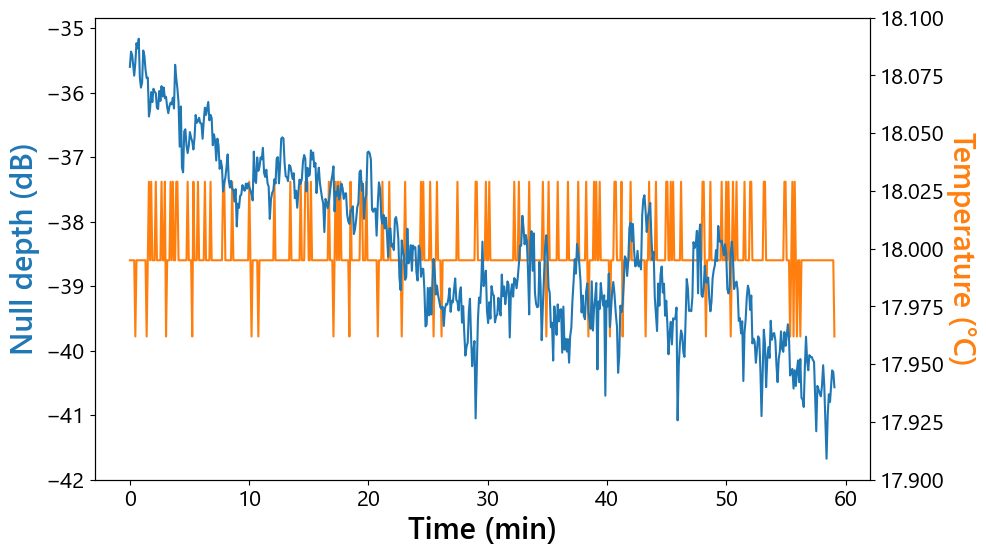

In [68]:
fig, ax = plt.subplots(figsize=(10, 6))
ax2 = ax.twinx()
 
ax.plot(times/60, nulls_dB, color='C0')
ax2.plot(times/60, tab['temperature'], color='C1')
ax2.set_ylim(17.9, 18.1)
ax.set_ylabel('Null depth (dB)', color='C0')
ax2.set_ylabel('Temperature (°C)', color='C1', rotation=270, labelpad=23)
ax.set_xlabel('Time (min)')
 
# Bring the null-depth axis (ax) to the front, above the temperature axis (ax2)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)  # so ax's background doesn't hide ax2 underneath
 
plt.show()

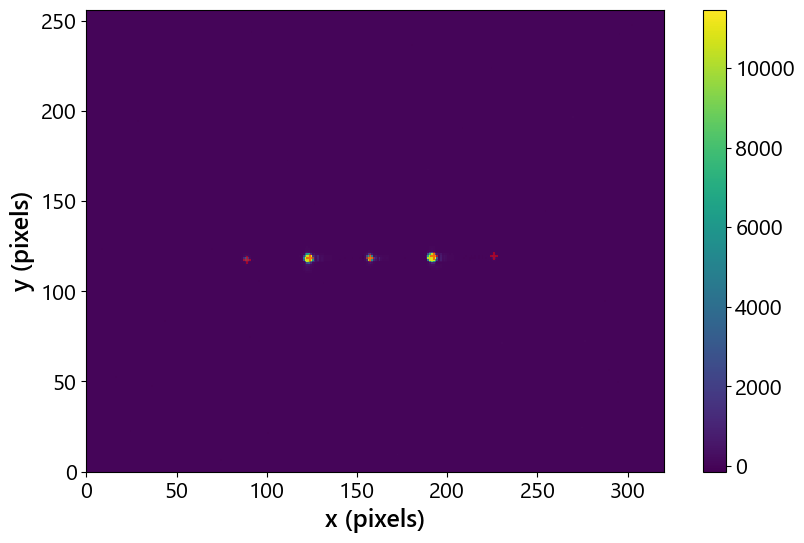

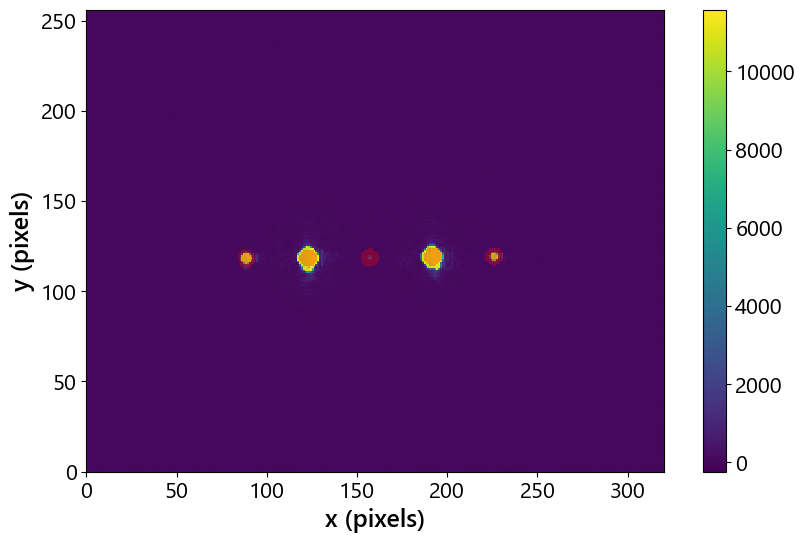

[318652.69987716 805135.47651829  10275.42179234 853285.95777905
 169981.48251511]
[15293. 15459.  6713. 15440. 15020.]


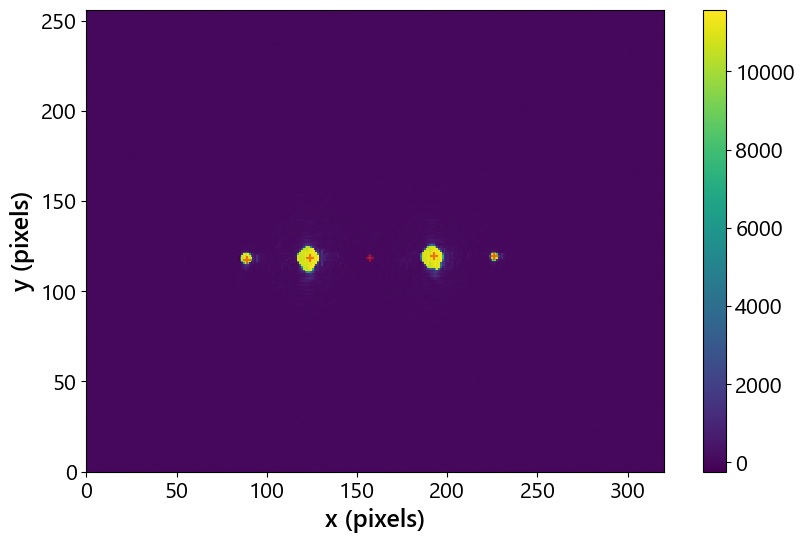

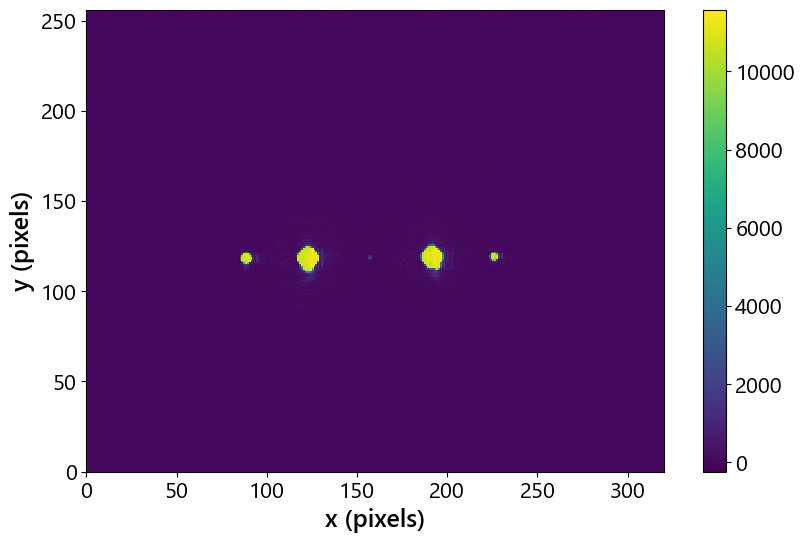

Output A:


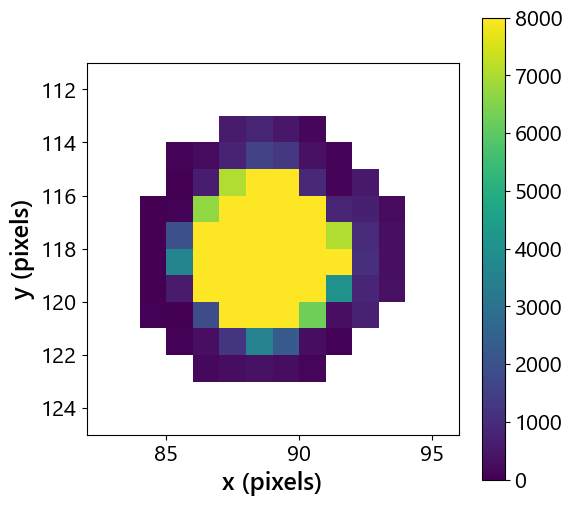

Data - Dark sum: 332481.4392089844
Data peak: 15293.0
Output B:


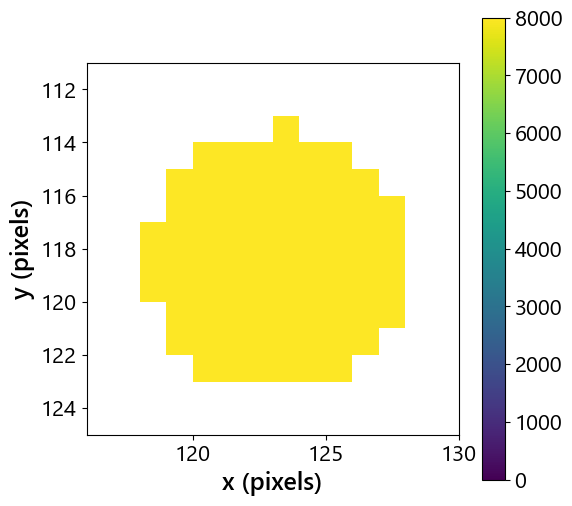

Data - Dark sum: 849632.4196777344
Data peak: 15459.0
Output C:


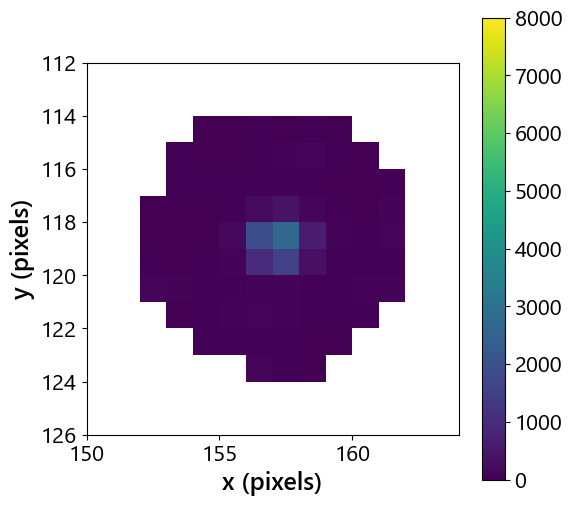

Data - Dark sum: 12056.219482421875
Data peak: 6713.0
Output D:


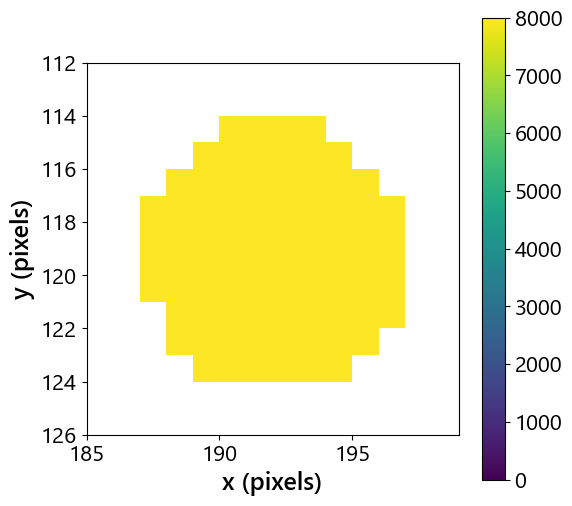

Data - Dark sum: 897503.259765625
Data peak: 15440.0
Output E:


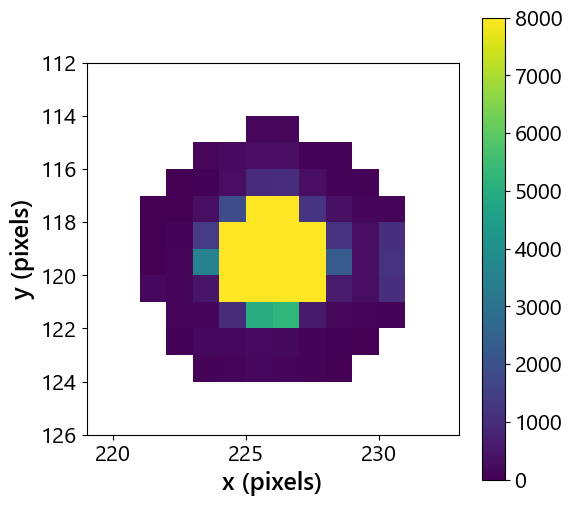

Data - Dark sum: 177619.58056640625
Data peak: 15020.0


In [119]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260520\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECoff_lowV_trial0\\'
filename_root = 'Device6a_I18_1x5Tri'
num_outputs = 5

voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

filename = 'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260521\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECon_lowVTest_polarizer_trial3\\Device6a_I18_1x5Tri_Ch61_V9p88_Ch62_V10p51_Ch41_V0p50_outputC_3p30.npy'
# filename = 'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260521\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECon_lowVTest_polarizer_manualC\\Device6a_I18_1x5Tri_Ch61_V9p88_Ch62_V10p51_Ch41_V0p50_outputC_2p50.npy'
data = np.load(filename, allow_pickle=True)
masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords, mask_range=5)
data_noStripe = PIC.remove_stripes(data[0], masks)
dark_noStripe = PIC.remove_stripes(dark, masks)
data_reduce = data_noStripe-dark_noStripe
print(np.sum(data_reduce * masks, axis=(1,2)))
print(np.nanmax(data[0] * masks, axis=(1,2)))

y_dim, x_dim = np.shape(data[0])

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data[0]-dark, zorder=0)
for coord in coords:
    ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_aspect('equal')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data[0]-dark, zorder=0)
# for coord in coords:
#     ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_aspect('equal')
plt.show()

vmax = 8000
for i in range(len(masks)):
    print(f'Output {chr(65+i)}:')
    PIC.plot_masked(data[0]-dark, masks[i], vmax=vmax)
    print('Data - Dark sum:', np.nansum((data[0]-dark)*masks[i]))
    print('Data peak:', np.nanmax(data[0]*masks[i]))


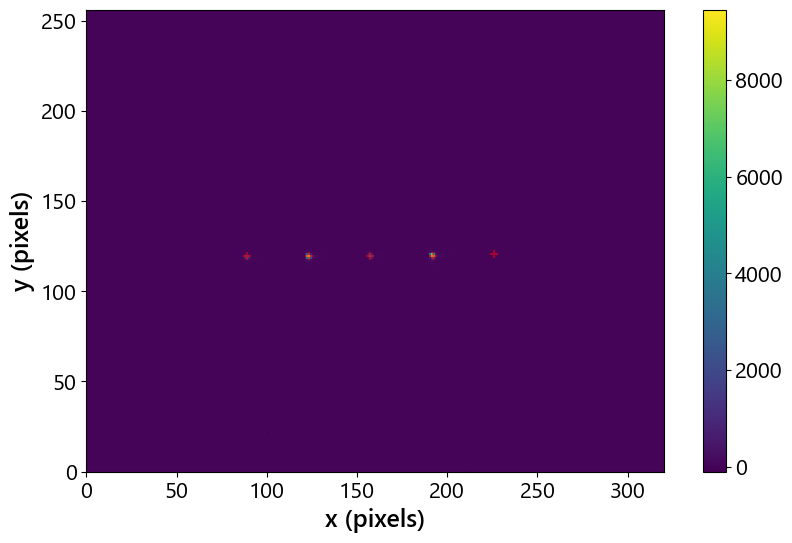

[0.0] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.1] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.2] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.30000000000000004] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.4] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.5] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.6000000000000001] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.7000000000000001] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.8] [4.5, 4.6, 3.9, 4.6, 4.0]
[0.9] [4.5, 4.6, 3.9, 4.6, 4.0]
[1.0] [4.5, 4.6, 3.9, 4.6, 4.0]
[1.1] [4.5, 4.6, 3.9, 4.6, 4.0]
[1.2000000000000002] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.3] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.4000000000000001] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.5] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.6] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.7000000000000002] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.8] [4.5, 4.6, 3.8, 4.6, 4.0]
[1.9000000000000001] [4.5, 4.6, 3.8, 4.6, 4.0]
[2.0] [4.5, 4.6, 3.8, 4.6, 4.0]
[2.1] [4.5, 4.6, 3.8, 4.6, 4.0]
[2.2] [4.5, 4.6, 3.8, 4.6, 4.0]
[2.3000000000000003] [4.5, 4.6, 3.8, 4.6, 4.0]
[2.4000000000000004] [4.5, 4.6, 3.9, 4.6, 4.0]
[2.5] [4.5, 4.6, 3.9, 4.6, 4.0]
[2.6] [4.5, 4.6, 3.9, 4.6, 4.0]


In [231]:
data_dir = filename = 'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260521\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECon_lowV_polarizer_trial2\\'
filename_root = 'Device6a_I18_1x5Tri_Ch61_V9p15_Ch62_V9p99'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 5

filename_ref = data_dir+'Device6a_I18_1x5Tri_Ch61_V9p15_Ch62_V9p99_Ch41_V5p50_outputA_4p50.npy'
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
# masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords)

voltages, outputs, attens, outputs_flux = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                              coords=coords, r_lin=5, r_max=15, plot=False)

np.save(f'{data_dir}{filename_root}_voltage', voltages)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

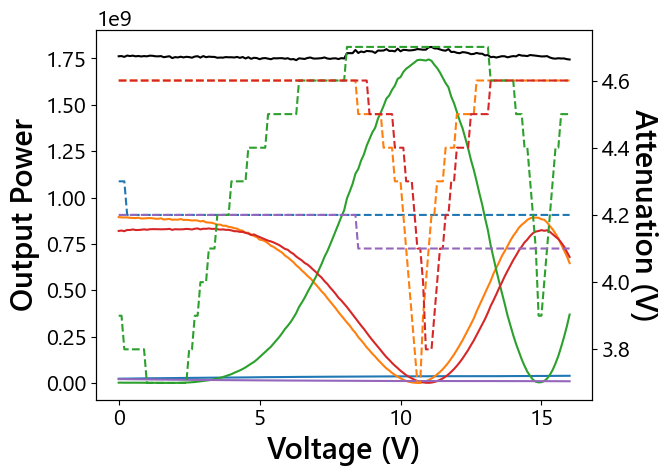

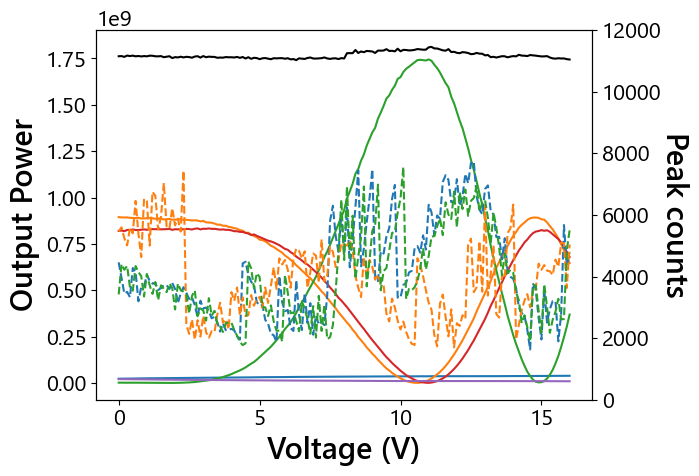

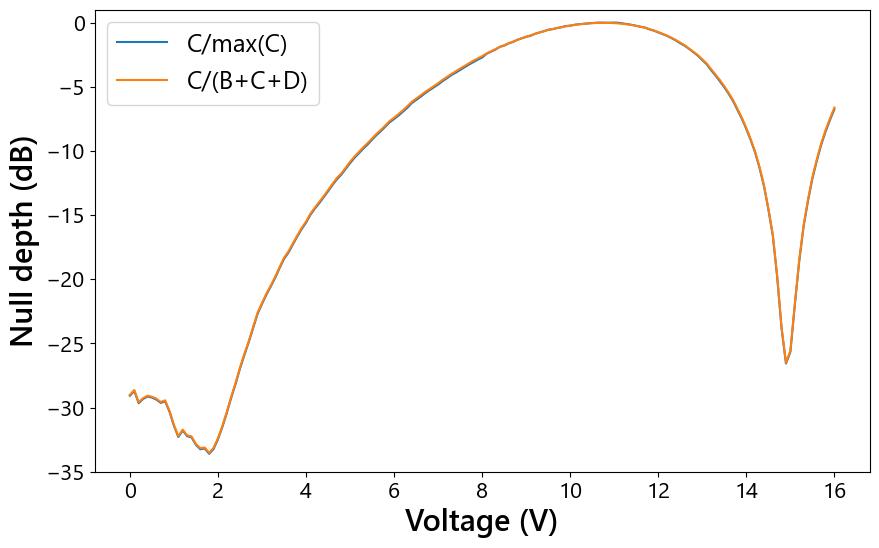

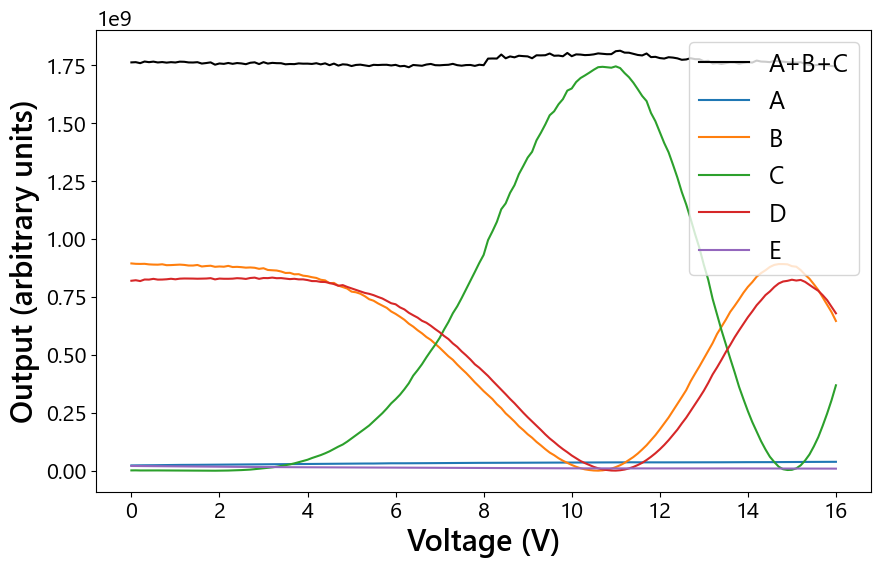

In [125]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260520\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECoff_lowV_trial2\\'
filename_root = 'Device6a_I18_1x5Tri'
num_outputs = 5

voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])


outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
# outputs_flux_scaled = PIC.scale_voltage_scan(outputs_flux, attens)
flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:, 1:4], axis=1)
null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C+D+E')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--')
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C+D+E')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, outputs_flux, '--')
ax2.set_ylabel('Peak counts', rotation=270, labelpad=20)
ax2.set_ylim(0, 12000)
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, null_maxC, label='C/max(C)')
plt.plot(voltages, null_BCD, label='C/(B+C+D)')
plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')
plt.ylim(-35, 1)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C')
plt.plot(voltages, outputs_scaled[:,0], label='A')
plt.plot(voltages, outputs_scaled[:,1], label='B')
plt.plot(voltages, outputs_scaled[:,2], label='C')
plt.plot(voltages, outputs_scaled[:,3], label='D')
plt.plot(voltages, outputs_scaled[:,4], label='E')
plt.xlabel('Voltage (V)')
plt.ylabel('Output (arbitrary units)')
plt.legend()
plt.show()

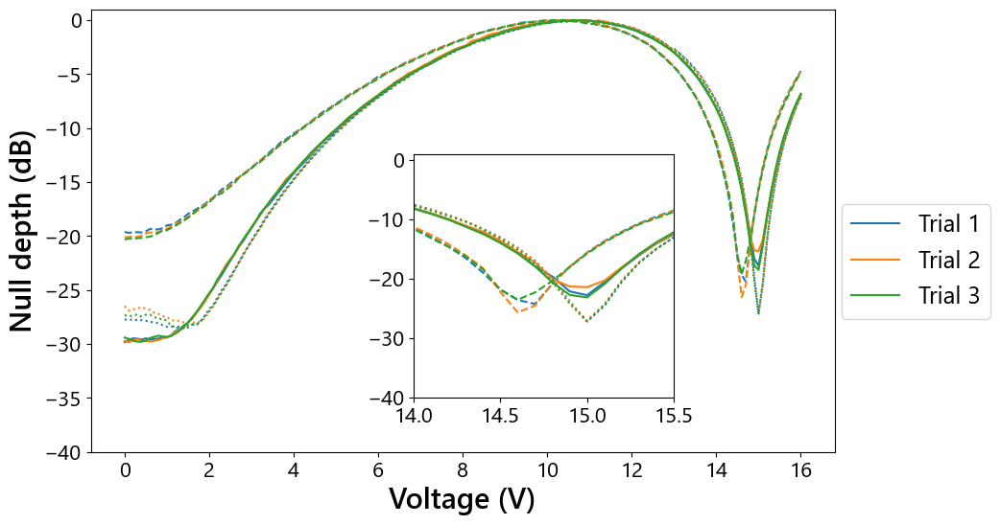

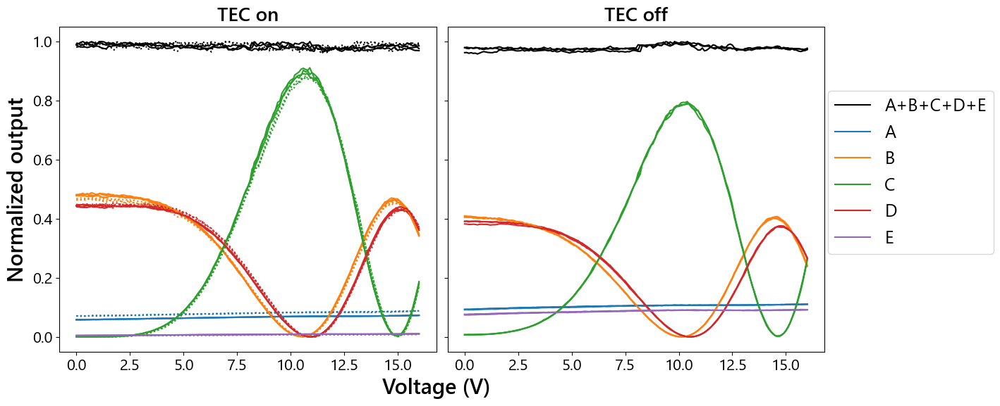

In [238]:
null_TECon, outputs_TECon = [], []
filename_root, num_outputs = 'Device6a_I18_1x5Tri', 5
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260520\\voltage_scan\\{filename_root}_amoeba_TECon_lowV_trial{i}\\'
    voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:,1:4], axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECon.append(null_maxC)
    outputs_TECon.append(outputs_scaled)

null_TECoff, outputs_TECoff = [], []
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260520\\voltage_scan\\{filename_root}_amoeba_TECoff_highV_trial{i}\\'
    voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:,1:4], axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECoff.append(null_maxC)
    outputs_TECoff.append(outputs_scaled)

null_pol, outputs_pol = [], []
for i in range(3):
    filename_root, num_outputs = 'Device6a_I18_1x5Tri', 5
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260521\\voltage_scan\\{filename_root}_amoeba_TECon_lowV_polarizer_trial{i}\\'
    # voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled, axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_pol.append(null_maxC)
    outputs_pol.append(outputs_scaled)


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(10,6))
for i in range(3):
    ax.plot(voltages, null_TECon[i], color=f'C{i}', label=f'Trial {i+1}')
    ax.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    ax.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Null depth (dB)')
ax.set_ylim(-40, 1)
ax.legend(loc=(1.01, 0.3))
# Inset
axins = inset_axes(ax, width="35%", height="55%", 
                   bbox_to_anchor=(-0.2, -0.3, 1, 1), bbox_transform=ax.transAxes)
for i in range(3):
    axins.plot(voltages, null_TECon[i], color=f'C{i}')
    axins.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    axins.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
axins.set_xlim(14, 15.5)
axins.set_ylim(-40, 1)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
plt.subplots_adjust(wspace=0.03)
for i in range(3):
    outputs_TECon_tot = np.sum(outputs_TECon[i], axis=1)
    outputs_TECoff_tot = np.sum(outputs_TECoff[i], axis=1)
    outputs_pol_tot = np.sum(outputs_pol[i], axis=1)       

    if i==0:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k', label='A+B+C+D+E')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}', label=f'{chr(65+j)}')
    else:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}')

ax[0].set_title('TEC on')
ax[1].set_title('TEC off')
ax[0].set_xlabel('Voltage (V)', labelpad=1.5)
ax[0].set_ylabel('Normalized output')
ax[0].xaxis.set_label_coords(1.0, -0.08)
ax[1].legend(loc=(1.01, 0.3))
plt.show()

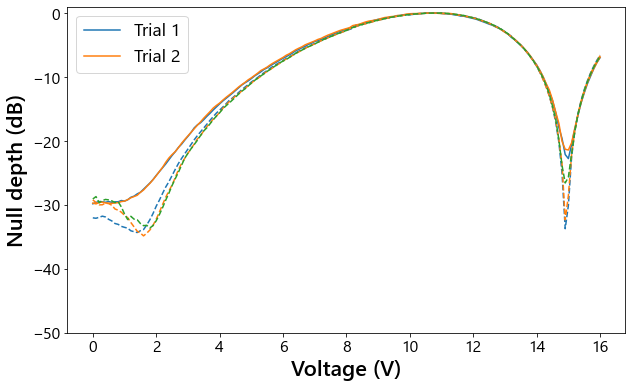

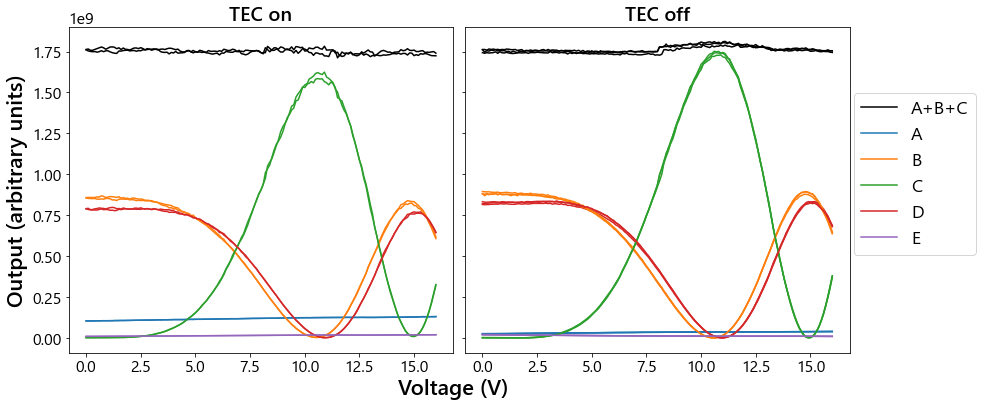

In [268]:
plt.figure(figsize=(10,6))
for i in range(2):
    plt.plot(voltages, null_TECon[i], color=f'C{i}', label=f'Trial {i+1}')
for i in range(3):
    plt.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    # plt.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')
plt.ylim(-50, 1)
plt.legend()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
plt.subplots_adjust(wspace=0.03)
for i in range(2):
    ax[0].plot(voltages, np.sum(outputs_TECon[i], axis=1), 'k')
    for j in range(num_outputs):
        ax[0].plot(voltages, outputs_TECon[i][:,j], color=f'C{j}')

for i in range(3):

    if i==0:
        ax[1].plot(voltages, np.sum(outputs_TECoff[i], axis=1), 'k', label='A+B+C')
        for j in range(num_outputs):
            ax[1].plot(voltages, outputs_TECoff[i][:,j], color=f'C{j}', label=f'{chr(65+j)}')
            # ax[1].plot(voltages, outputs_pol[i][:,j], color=f'C{j}', linestyle='dotted')
    else:
        ax[1].plot(voltages, np.sum(outputs_TECoff[i], axis=1), 'k')
        # ax[1].plot(voltages, np.sum(outputs_pol[i], axis=1), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[1].plot(voltages, outputs_TECoff[i][:,j], color=f'C{j}')
            # ax[1].plot(voltages, outputs_pol[i][:,j], color=f'C{j}', linestyle='dotted')

ax[0].set_title('TEC on')
ax[1].set_title('TEC off')
ax[0].set_xlabel('Voltage (V)', labelpad=1.5)
ax[0].set_ylabel('Output (arbitrary units)')
ax[0].xaxis.set_label_coords(1.0, -0.08)
ax[1].legend(loc=(1.01, 0.3))
plt.show()

### Device 7a

In [25]:
importlib.reload(PIC)

<module 'PIC_lib' from 'd:\\Active_PIC\\AnalysisCode\\PIC_lib.py'>

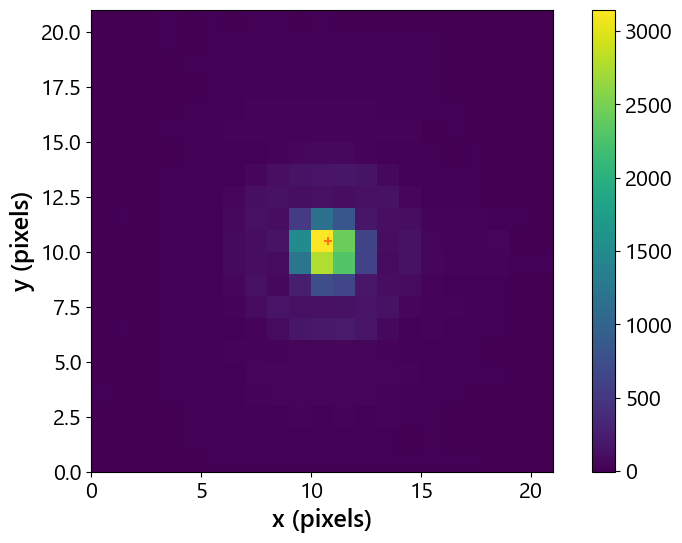

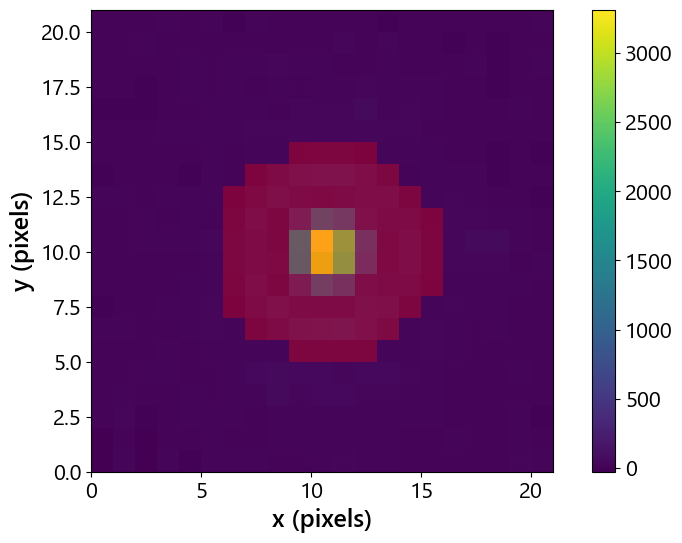

[9.865, 0.0] [52.]
[9.865, 0.1] [52.]
[9.865, 0.25] [52.]
[9.865, 0.475] [52.]
[9.865, 0.812] [52.]
[9.865, 1.312] [52.]
[9.865, 1.812] [52.]
[9.865, 2.312] [52.]
[9.865, 2.812] [52.]
[9.865, 3.312] [52.]
[9.865, 3.812] [49.]
[9.865, 3.833] [49.]
[9.865, 3.933] [49.]
[9.865, 4.083] [46.]
[9.865, 4.103] [46.]
[9.865, 4.202] [46.]
[9.865, 4.353] [43.]
[9.865, 4.372] [43.]
[9.865, 4.472] [40.]
[9.865, 4.492] [40.]
[9.865, 4.592] [37.]
[9.865, 4.612] [37.]
[9.865, 4.614] [37.]
[9.865, 4.616] [37.]
[9.865, 4.618] [37.]
[9.865, 4.62] [37.]
[9.865, 4.622] [37.]
[9.865, 4.624] [34.]
[9.865, 4.626] [34.]
[9.865, 4.628] [34.]
[9.865, 4.63] [34.]
[9.865, 4.632] [34.]
[9.865, 4.634] [34.]
[9.865, 4.636] [34.]
[9.865, 4.638] [34.]
[9.865, 4.64] [34.]
[9.865, 4.642] [34.]
[9.865, 4.644] [34.]
[9.865, 4.646] [34.]
[9.865, 4.648] [34.]
[9.865, 4.65] [34.]
[9.865, 4.652] [34.]
[9.865, 4.654] [34.]
[9.865, 4.656] [34.]
[9.865, 4.658] [34.]
[9.865, 4.66] [34.]
[9.865, 4.662] [34.]
[9.865, 4.664] [34.]
[9

ValueError: cannot reshape array of size 0 into shape (50,21,21)

In [28]:
from Bench import BENCH

device_name, num_outputs = f'Device7a_I21_1x5Tri', 1
# PS1_arr = np.arange(9.0, 12.1, 0.5)
PS1_arr = [10.5]

for PS1 in PS1_arr:
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch68_V{PS1_str}'
    
    data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260906\\voltage_scan_Ch68_V{PS1_str}_TECon_polarizer\\voltage_scan\\'
    filename_ref = glob.glob(data_dir+'*[0-9].npy')[0]
    filename_dark = glob.glob(data_dir+'*dark*')[0]

    data = np.load(filename_ref, allow_pickle=True)#, 
    dark = np.loadtxt(filename_dark, delimiter=',')
    coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
    masks = BENCH.build_output_mask(data[0]-dark, num_outputs, coords, mask_range=5)

    voltages, outputs, attens, outputs_flux, labels = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                                coords=coords, r_lin=5, r_max=15, plot=False, 
                                                                                movie_filename=data_dir+filename_root+'_inspect.mp4', movie_dpi=120)

    np.save(f'{data_dir}{filename_root}_voltage', voltages)
    np.save(f'{data_dir}{filename_root}_outputs', outputs)
    np.save(f'{data_dir}{filename_root}_attenuation', attens)

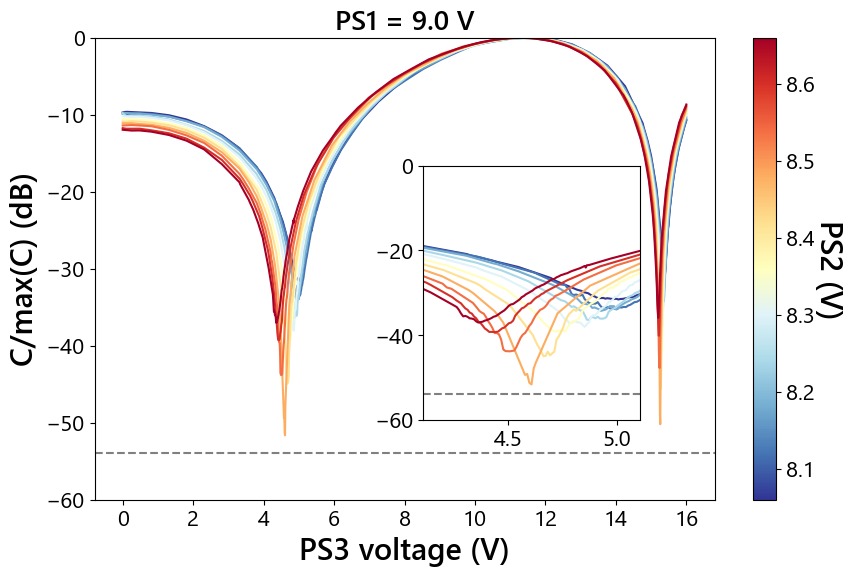

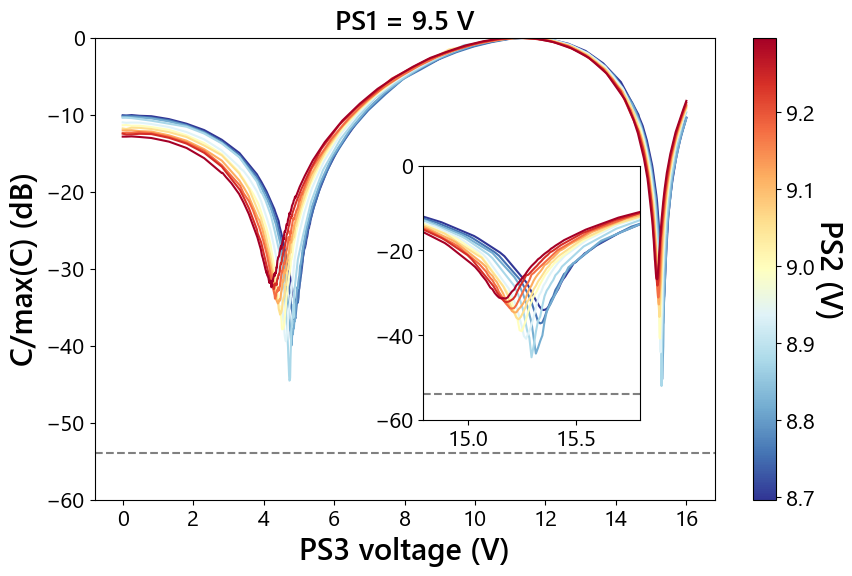

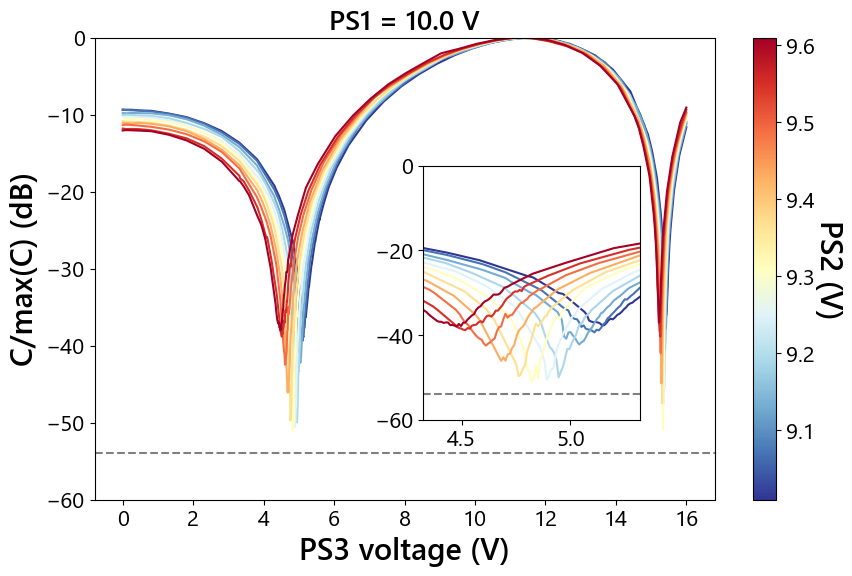

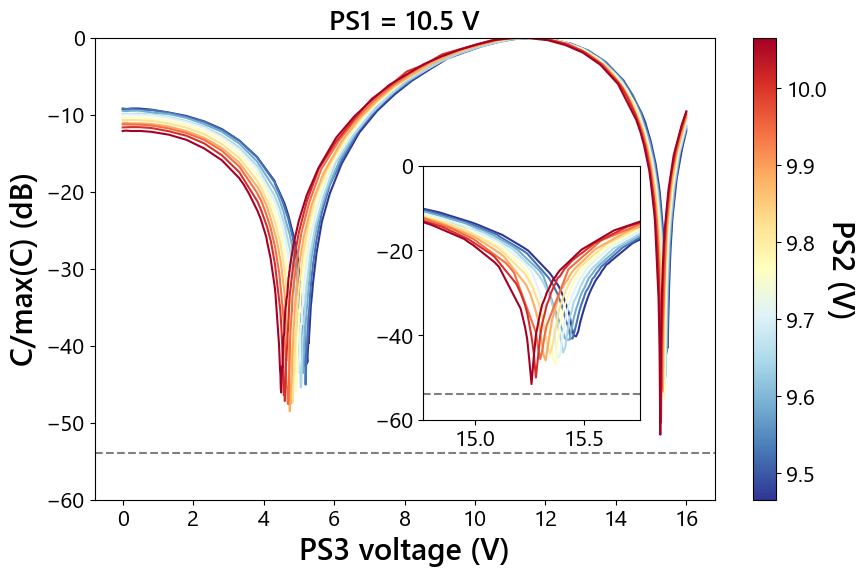

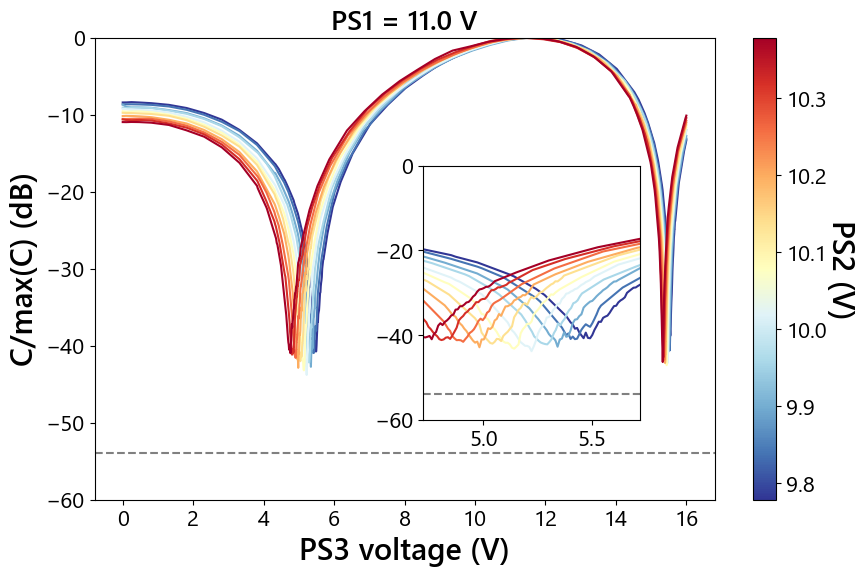

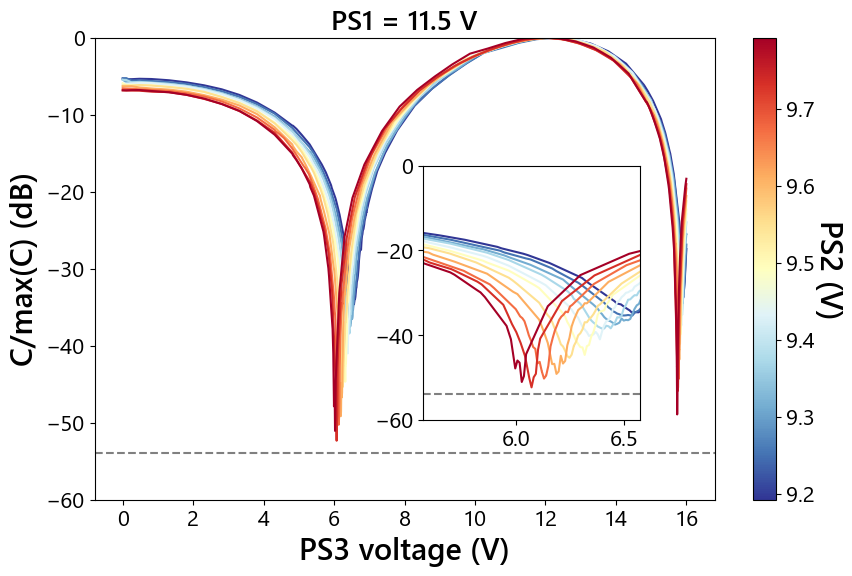

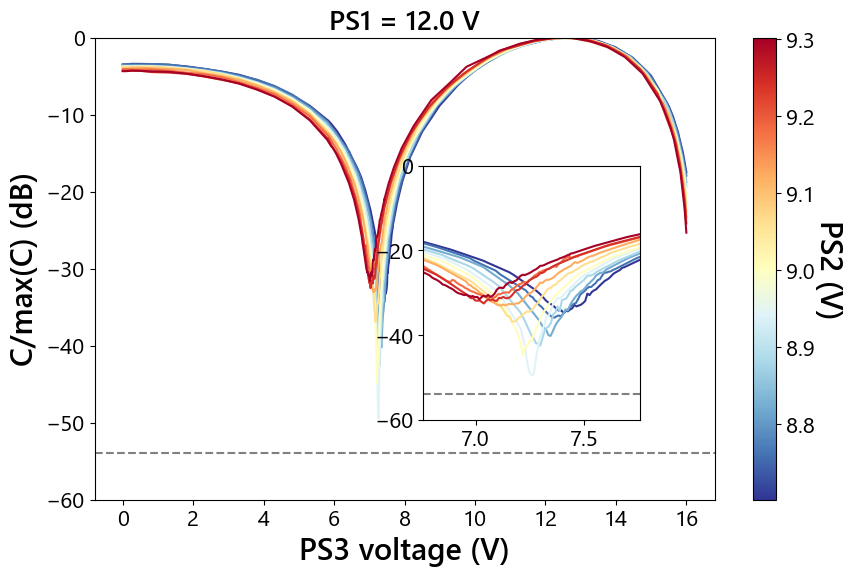

wrote 7 frames to D:\Active_PIC\Data\PhotometryScans\Device7a_I21_1x5Tri\20260902\null_vs_PS1.gif

  PS1 (V)   null (dB)    PS3 (V)    PS2 (V)
    9.000      -51.64      4.607      8.479
    9.500      -45.23     15.295      8.877
   10.000      -51.02      4.822      9.309
   10.500      -51.55     15.260     10.065
   11.000      -43.79      5.222     10.018
   11.500      -52.34      6.072      9.732
   12.000      -49.47      7.257      8.942


In [ ]:
import io
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from PIL import Image

device_name, num_outputs = f'Device7a_I21_1x5Tri', 1
PS1_arr = np.arange(9.0, 12.1, 0.5)
INSET_HALFWIDTH = 0.5           # V either side of the deepest null
data_root = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260902\\'
GIF_FILENAME = f'{data_root}null_vs_PS1.gif'
GIF_FPS = 1

gif_frames = []

# Per PS1: deepest null over all PS2 curves, and where it occurred
best_depth = np.full(len(PS1_arr), np.nan)      # dB
best_v_PS3 = np.full(len(PS1_arr), np.nan)      # V, adaptive channel
best_v_PS2 = np.full(len(PS1_arr), np.nan)      # V, curve the minimum came from

# Per PS1 and PS2: minimum of each individual curve
depths_all = []                                  # list of arrays, one per PS1
v_PS3_all = []
V_PS2_all = []

for k, PS1 in enumerate(PS1_arr):
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch68_V{PS1_str}'
    data_dir = f'{data_root}voltage_scan_Ch68_V{PS1_str}_TECon_polarizer\\voltage_scan\\'

    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    V_PS2 = np.sort(list(set(voltages[:, 0])))
    V_PS2_sets = [voltages[:, 0] == V for V in V_PS2]
    outputs_scaled = outputs * 10**(attens/10)

    fig, ax = plt.subplots(figsize=(10, 6))

    cmap = plt.get_cmap('RdYlBu_r')
    norm = Normalize(vmin=min(V_PS2), vmax=max(V_PS2))

    null_depths = np.full(len(V_PS2), np.nan)    # minimum of each PS2 curve
    null_v_PS3 = np.full(len(V_PS2), np.nan)     # PS3 voltage at each minimum

    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        v_curve = voltages[:, 1][V_PS2_sets[i]]
        null_curve = 10*np.log10(output_V/np.max(output_V))
        ax.plot(v_curve, null_curve, color=cmap(norm(V)))

        j = np.nanargmin(null_curve)
        null_depths[i] = null_curve[j]
        null_v_PS3[i] = v_curve[j]

    # Deepest null across all PS2 curves for this PS1
    i_best = np.nanargmin(null_depths)
    best_depth[k] = null_depths[i_best]
    best_v_PS3[k] = null_v_PS3[i_best]
    best_v_PS2[k] = V_PS2[i_best]

    depths_all.append(null_depths)
    v_PS3_all.append(null_v_PS3)
    V_PS2_all.append(V_PS2)

    ax.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    ax.set_ylim(-60, 0)

    # Inset
    axins = inset_axes(ax, width="35%", height="55%",
                       bbox_to_anchor=(-0.1, -0.25, 1, 1), bbox_transform=ax.transAxes)
    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        axins.plot(voltages[:, 1][V_PS2_sets[i]],
                   10*np.log10(output_V/np.max(output_V)), color=cmap(norm(V)))
    axins.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    axins.set_xlim(best_v_PS3[k] - INSET_HALFWIDTH, best_v_PS3[k] + INSET_HALFWIDTH)
    axins.set_ylim(-60, 0)

    ax.set_xlabel('PS3 voltage (V)')
    ax.set_ylabel('C/max(C) (dB)')
    ax.set_title(f'PS1 = {PS1} V')

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('PS2 (V)', rotation=270, labelpad=20)

    # Frozen bbox from the first figure keeps every frame the same size
    fig.canvas.draw()
    if not gif_frames:
        gif_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.1)

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=120, bbox_inches=gif_bbox, facecolor='white')
    buf.seek(0)
    gif_frames.append(Image.open(buf).convert('RGB'))

    plt.show()

gif_frames[0].save(GIF_FILENAME, save_all=True, append_images=gif_frames[1:],
                   duration=int(1000/GIF_FPS), loop=0)
print(f'wrote {len(gif_frames)} frames to {GIF_FILENAME}\n')

# Summary
print(f'{"PS1 (V)":>9}  {"null (dB)":>10}  {"PS3 (V)":>9}  {"PS2 (V)":>9}')
for k, PS1 in enumerate(PS1_arr):
    print(f'{PS1:9.3f}  {best_depth[k]:10.2f}  {best_v_PS3[k]:9.3f}  {best_v_PS2[k]:9.3f}')

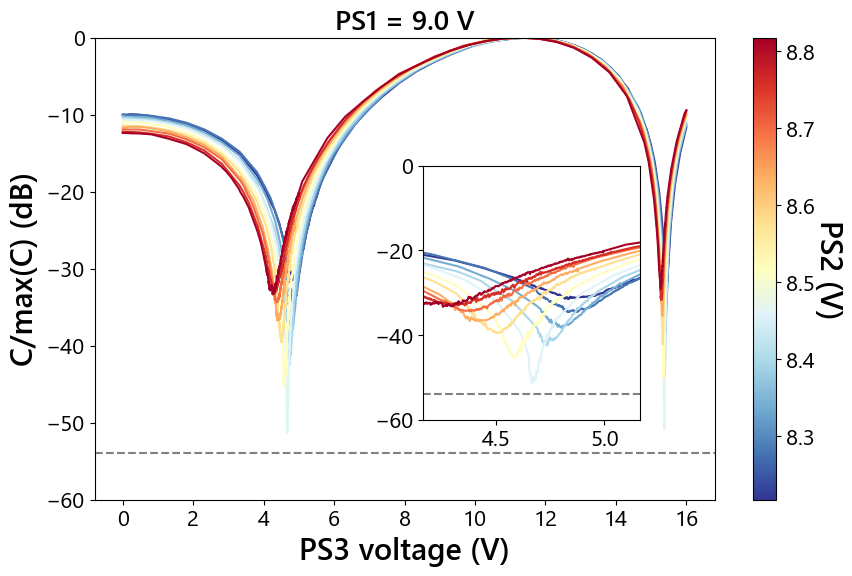

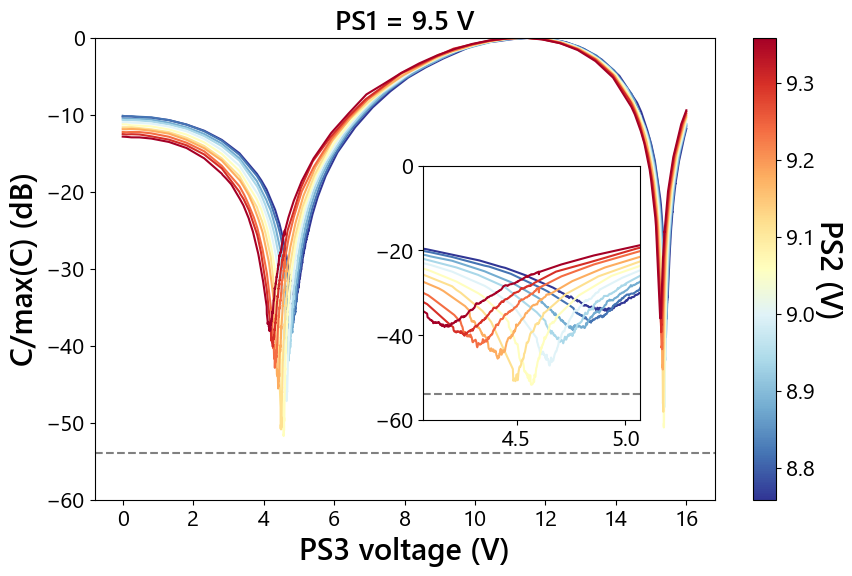

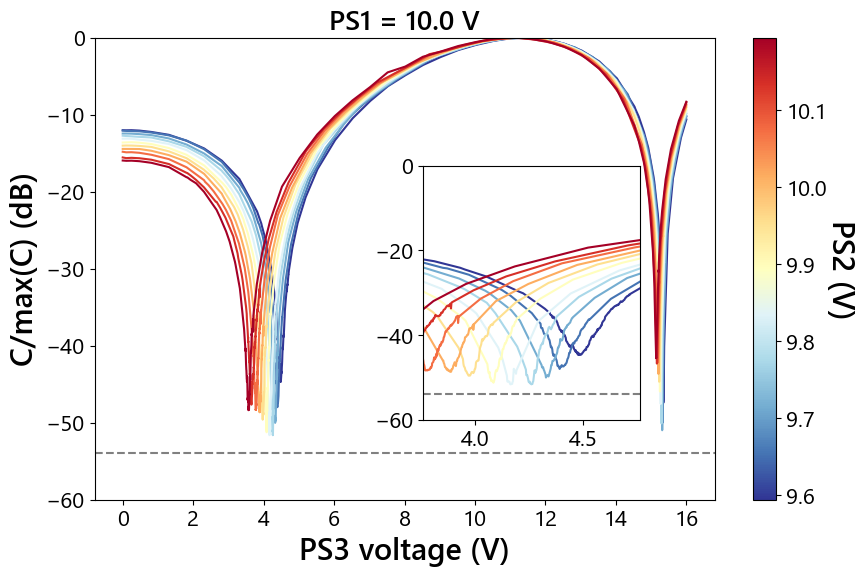

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260906\\voltage_scan_Ch68_V10p500_TECon_polarizer\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V10p500_voltage.npy'

In [21]:
import io
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from PIL import Image

device_name, num_outputs = f'Device7a_I21_1x5Tri', 1
IND_OUTPUT = 0                  # which output port to analyse
PS1_arr = np.arange(9.0, 12.1, 0.5)
INSET_HALFWIDTH = 0.5           # V either side of the deepest null
PS3_LIM = (0.0, 10.0)           # only look for the null within this PS3 range
data_root = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260906\\'
GIF_FILENAME = f'{data_root}null_vs_PS1.gif'
GIF_FPS = 1

gif_frames = []

# Per PS1: deepest null over all PS2 curves within PS3_LIM, and where it occurred
best_depth = np.full(len(PS1_arr), np.nan)      # dB
best_v_PS3 = np.full(len(PS1_arr), np.nan)      # V, adaptive channel
best_v_PS2 = np.full(len(PS1_arr), np.nan)      # V, curve the minimum came from

# Per PS1 and PS2: minimum of each individual curve
depths_all = []                                  # list of arrays, one per PS1
v_PS3_all = []
V_PS2_all = []

for k, PS1 in enumerate(PS1_arr):
    PS1_str = f'{PS1:0.3f}'.replace('.', 'p')
    filename_root = f'{device_name}_Ch68_V{PS1_str}'
    data_dir = f'{data_root}voltage_scan_Ch68_V{PS1_str}_TECon_polarizer\\voltage_scan\\'

    voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

    V_PS2 = np.sort(list(set(voltages[:, 0])))
    V_PS2_sets = [voltages[:, 0] == V for V in V_PS2]

    # Select the output column here: outputs and attens are (n_points,
    # num_outputs), so keeping the second axis leaves every downstream array 2D
    # and boolean indexing against a 1D voltage mask fails.
    outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

    fig, ax = plt.subplots(figsize=(10, 6))

    cmap = plt.get_cmap('RdYlBu_r')
    norm = Normalize(vmin=min(V_PS2), vmax=max(V_PS2))

    null_depths = np.full(len(V_PS2), np.nan)    # minimum of each PS2 curve
    null_v_PS3 = np.full(len(V_PS2), np.nan)     # PS3 voltage at each minimum
    curves = []                                  # (v_curve, null_curve) for the inset

    for i, V in enumerate(V_PS2):
        output_V = outputs_scaled[V_PS2_sets[i]]
        v_curve = voltages[:, 1][V_PS2_sets[i]]
        null_curve = 10*np.log10(output_V/np.max(output_V))
        ax.plot(v_curve, null_curve, color=cmap(norm(V)))
        curves.append((v_curve, null_curve))

        # Search for the minimum only within PS3_LIM, but normalise and plot
        # over the full scanned range.
        in_range = (v_curve >= PS3_LIM[0]) & (v_curve <= PS3_LIM[1]) & np.isfinite(null_curve)

        if np.any(in_range):
            idx_in = np.flatnonzero(in_range)
            j = idx_in[np.argmin(null_curve[in_range])]
            null_depths[i] = null_curve[j]
            null_v_PS3[i] = v_curve[j]

    # Deepest null across all PS2 curves for this PS1, within PS3_LIM
    if np.all(np.isnan(null_depths)):
        print(f'PS1 = {PS1} V: no PS3 points in {PS3_LIM}, skipping')
        inset_centre = np.mean(PS3_LIM)
    else:
        i_best = np.nanargmin(null_depths)
        best_depth[k] = null_depths[i_best]
        best_v_PS3[k] = null_v_PS3[i_best]
        best_v_PS2[k] = V_PS2[i_best]
        inset_centre = best_v_PS3[k]

    depths_all.append(null_depths)
    v_PS3_all.append(null_v_PS3)
    V_PS2_all.append(V_PS2)

    ax.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    ax.set_ylim(-60, 0)

    # Inset, reusing the curves already computed above
    axins = inset_axes(ax, width="35%", height="55%",
                       bbox_to_anchor=(-0.1, -0.25, 1, 1), bbox_transform=ax.transAxes)
    for i, V in enumerate(V_PS2):
        v_curve, null_curve = curves[i]
        axins.plot(v_curve, null_curve, color=cmap(norm(V)))
    axins.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
    axins.set_xlim(inset_centre - INSET_HALFWIDTH, inset_centre + INSET_HALFWIDTH)
    axins.set_ylim(-60, 0)

    ax.set_xlabel('PS3 voltage (V)')
    ax.set_ylabel('C/max(C) (dB)')
    ax.set_title(f'PS1 = {PS1} V')

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('PS2 (V)', rotation=270, labelpad=20)

    # Frozen bbox from the first figure keeps every frame the same size
    fig.canvas.draw()
    if not gif_frames:
        gif_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.1)

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=120, bbox_inches=gif_bbox, facecolor='white')
    buf.seek(0)
    gif_frames.append(Image.open(buf).convert('RGB'))

    plt.show()

gif_frames[0].save(GIF_FILENAME, save_all=True, append_images=gif_frames[1:],
                   duration=int(1000/GIF_FPS), loop=0)
print(f'wrote {len(gif_frames)} frames to {GIF_FILENAME}\n')

# Summary
print(f'Output {chr(65+IND_OUTPUT)}, PS3 search window {PS3_LIM[0]} to {PS3_LIM[1]} V')
print(f'{"PS1 (V)":>9}  {"null (dB)":>10}  {"PS3 (V)":>9}  {"PS2 (V)":>9}')
for k, PS1 in enumerate(PS1_arr):
    print(f'{PS1:9.3f}  {best_depth[k]:10.2f}  {best_v_PS3[k]:9.3f}  {best_v_PS2[k]:9.3f}')

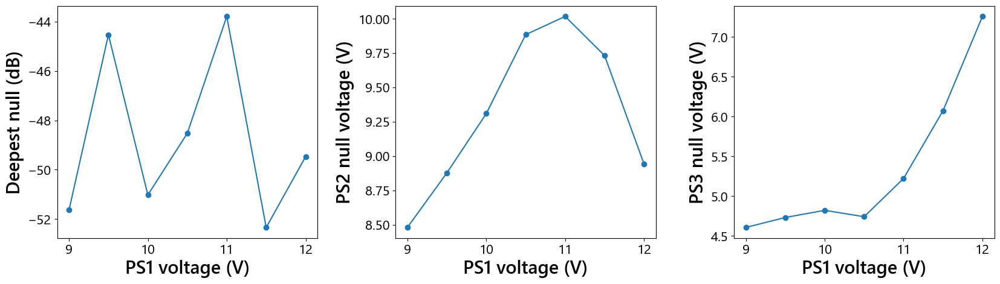

In [25]:
# ind = PS1_arr == 11.0

# Null depth vs PS1
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
plt.subplots_adjust(wspace=0.3)
ax[0].plot(PS1_arr, best_depth, 'o-')
# ax[0].plot(PS1_arr[ind], best_depth[ind], 'o-')
ax[0].set_xlabel('PS1 voltage (V)')
ax[0].set_ylabel('Deepest null (dB)')

ax[1].plot(PS1_arr, best_v_PS2, 'o-')
# ax[1].plot(PS1_arr[ind], best_v_PS2[ind], 'o-')
ax[1].set_xlabel('PS1 voltage (V)')
ax[1].set_ylabel('PS2 null voltage (V)')

ax[2].plot(PS1_arr, best_v_PS3, 'o-')
# ax[2].plot(PS1_arr[ind], best_v_PS3[ind], 'o-')
ax[2].set_xlabel('PS1 voltage (V)')
ax[2].set_ylabel('PS3 null voltage (V)')
plt.show()

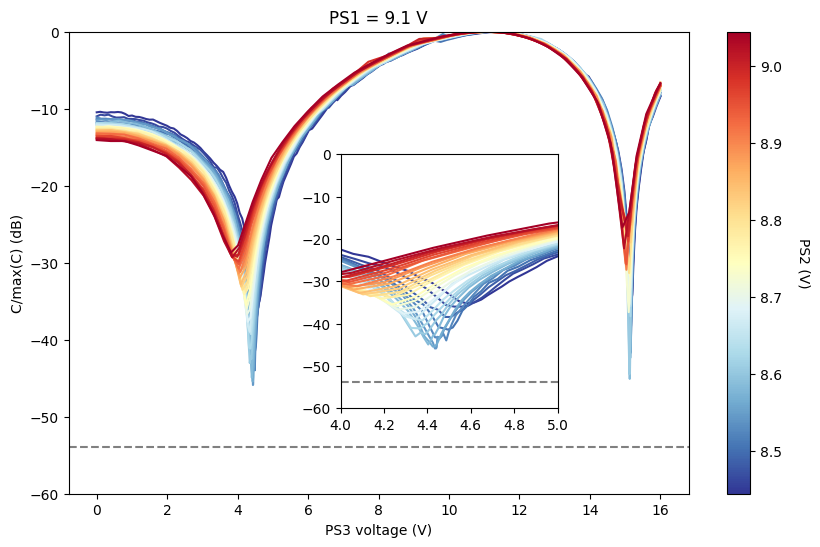

In [6]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

V_PS2 = np.sort(list(set(voltages[:,0])))
V_PS2_sets = [voltages[:,0] == V for V in V_PS2]
outputs_scaled = outputs * 10**(attens/10)


fig, ax = plt.subplots(figsize=(10,6))

cmap = cm.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(V_PS2), vmax=max(V_PS2))
null_depths = []

for i, V in enumerate(V_PS2):
    output_V = outputs_scaled[V_PS2_sets[i]]
    null_curve = 10*np.log10(output_V/np.max(output_V))
    ax.plot(voltages[:,1][V_PS2_sets[i]], null_curve,
             color=cmap(norm(V)))
    null_depths.append(np.min(null_curve))
ax.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
ax.set_ylim(-60, 0)

# Inset
axins = inset_axes(ax, width="35%", height="55%",
                   bbox_to_anchor=(-0.2, -0.25, 1, 1), bbox_transform=ax.transAxes)
for i, V in enumerate(V_PS2):
    output_V = outputs_scaled[V_PS2_sets[i]]
    axins.plot(voltages[:,1][V_PS2_sets[i]], 10*np.log10(output_V/np.max(output_V)),
                color=cmap(norm(V)))
axins.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
axins.set_xlim(4, 5.0)
axins.set_ylim(-60, 0)

ax.set_xlabel('PS3 voltage (V)')
ax.set_ylabel('C/max(C) (dB)')
ax.set_title('PS1 = 9.1 V')

# Colorbar instead of legend
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('PS2 (V)', rotation=270, labelpad=20)

plt.show()

Reduce laser scan

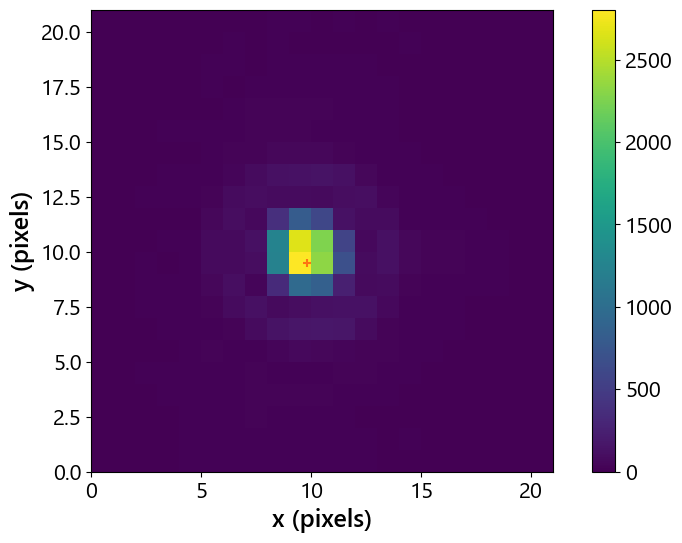

 1575.000 nm  [8.491, 4.192]  [43.]
 1575.000 nm  [8.491, 4.194]  [43.]
 1575.000 nm  [8.491, 4.196]  [43.]
 1575.000 nm  [8.491, 4.198]  [40.]
 1575.000 nm  [8.491, 4.2]  [40.]
 1575.000 nm  [8.491, 4.202]  [40.]
 1575.000 nm  [8.491, 4.204]  [40.]
 1575.000 nm  [8.491, 4.206]  [40.]
 1575.000 nm  [8.491, 4.208]  [40.]
 1575.000 nm  [8.491, 4.21]  [40.]
 1575.000 nm  [8.491, 4.212]  [40.]
 1575.000 nm  [8.491, 4.214]  [40.]
 1575.000 nm  [8.491, 4.216]  [40.]
 1575.000 nm  [8.491, 4.218]  [40.]
 1575.000 nm  [8.491, 4.22]  [40.]
 1575.000 nm  [8.491, 4.222]  [40.]
 1575.000 nm  [8.491, 4.224]  [40.]
 1575.000 nm  [8.491, 4.226]  [40.]
 1575.000 nm  [8.491, 4.228]  [40.]
 1575.000 nm  [8.491, 4.23]  [40.]
 1575.000 nm  [8.491, 4.232]  [40.]
 1575.000 nm  [8.491, 4.234]  [40.]
 1575.000 nm  [8.491, 4.236]  [40.]
 1575.000 nm  [8.491, 4.238]  [40.]
 1575.000 nm  [8.491, 4.24]  [40.]
 1575.000 nm  [8.491, 4.242]  [40.]
 1575.000 nm  [8.491, 4.244]  [40.]
 1575.000 nm  [8.491, 4.246]  [40.

In [80]:
data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260904\\laser_scan\\Device7a_I21_1x5Tri_Ch68_V9p000_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device7a_I21_1x5Tri_Ch68_V9p000'
filename_root = f'{device_name}'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 1

filename_ref = glob.glob(f'{data_dir}//*[0-9].npy')[0]
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = BENCH.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
# masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords)

wavs, voltage_coords, outputs, attens, output_fluxes, labels = PIC.reduce_laser_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                              coords=coords, movie_root=data_dir+filename_root, 
                                                                              movie_dpi=120, movie_clim=(0, np.max(np.mean(data, axis=0)-dark)))

np.save(f'{data_dir}{filename_root}_wav', wavs)
np.save(f'{data_dir}{filename_root}_voltage', voltage_coords)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

In [59]:
data_dir = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260904\\laser_scan\\Device7a_I21_1x5Tri_Ch68_V9p000_TECon_polarizer_adaptive_trial0\\'
device_name = 'Device7a_I21_1x5Tri_Ch68_V9p000'
filename_root = f'{device_name}'
wavs = np.load(f'{data_dir}{filename_root}_wav.npy')
voltage_coords = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')

In [85]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.animation import FuncAnimation, PillowWriter

IND_OUTPUT = 0
IND_X = 1              # channel whose voltage is the x-axis

wav_ref = 1590
wav_vals = np.sort(list(set(wavs)))
wav_sets = [wavs == w for w in wav_vals]

outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

cmap_orig = plt.get_cmap('RdYlBu_r', 256)
blue = cmap_orig(0.0)
red = cmap_orig(1.0)
yellow = '#f2d675'  # soft yellow, keeps the transition smooth without passing through white
cmap = LinearSegmentedColormap.from_list('blue_yellow_red_smooth', [blue, yellow, red], N=256)
norm = Normalize(vmin=min(wav_vals), vmax=max(wav_vals))

# Precompute all curves, null depths, and null positions up front
curves = []
null_depths = []
null_positions = []
for i, w in enumerate(wav_vals):
    sel = wav_sets[i]
    order = np.argsort(voltage_coords[sel, IND_X])
    v = voltage_coords[sel, IND_X][order]
    output_w = outputs_scaled[sel][order]
    null_curve = 10*np.log10(output_w/np.nanmax(output_w))
    curves.append((v, null_curve))
    idx_min = np.argmin(null_curve)
    null_positions.append(v[idx_min])
    

voltages_ref = curves[int(np.argwhere(wav_vals == wav_ref))][0]
curve_ref = curves[int(np.argwhere(wav_vals == wav_ref))][1]
ind_null = np.argmin(curve_ref)
null_depths_theory = ((np.pi**2)/4)*((wav_vals-wav_ref)/wav_ref)**2
null_depths_theory = 10*np.log10(null_depths_theory)

for i, w in enumerate(wav_vals):
    null_curve = curves[i][1]
    null_depths.append(null_curve[ind_null])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 6))
plt.subplots_adjust(wspace=0.5)

# --- Panel 1: sweep curve (static elements) ---
all_v = np.concatenate([v for v, _ in curves])
ax1.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
ax1.set_xlim(all_v.min(), all_v.max())
ax1.set_ylim(-60, 0)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('C/max(C) (dB)')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=28)

scat = ax1.scatter([], [], marker='.')

# --- Panel 2: null depth vs wavelength (static elements) ---
ax2.plot(wav_vals, null_depths, '-', color='lightgray', zorder=1)
ax2.plot(wav_vals, null_depths_theory, '--', color='black', zorder=1)
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Null depth (dB)')
ax2.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
ax2.set_ylim(min(null_depths) - 2, max(null_depths) + 2)
title = ax2.set_title('')

null_scat = ax2.scatter([], [], s=80, zorder=2, edgecolor='k')

# --- Panel 3: null position vs wavelength (static elements) ---
ax3.plot(wav_vals, null_positions, '-', color='lightgray', zorder=1)
ax3.set_xlabel('Wavelength (nm)')
ax3.set_ylabel('Minimum position (V)')
ax3.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
pos_range = max(null_positions) - min(null_positions)
pad = pos_range * 0.1 if pos_range > 0 else 0.5
ax3.set_ylim(min(null_positions) - pad, max(null_positions) + pad)

pos_scat = ax3.scatter([], [], s=80, zorder=2, edgecolor='k')

def update(frame):
    # Panel 1: this frame's curve only
    v, null_curve = curves[frame]
    w = wav_vals[frame]
    scat.set_offsets(np.column_stack([v, null_curve]))
    scat.set_color(cmap(norm(w)))
    title.set_text(f'Wavelength = {w:.2f} nm')

    # Panel 2: accumulate null depth points up through this frame
    null_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_depths[:frame+1]]))
    null_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    # Panel 3: accumulate null position points up through this frame
    pos_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_positions[:frame+1]]))
    pos_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    return scat, title, null_scat, pos_scat

anim = FuncAnimation(fig, update, frames=len(wav_vals), interval=200, blit=False)

anim.save(f'{data_dir}{filename_root}_wavelength_sweep.gif', writer=PillowWriter(fps=1))
plt.close(fig)
print("Saved wavelength_sweep.gif")

C:\Users\Pradip\AppData\Local\Temp\ipykernel_19096\2157709658.py:42: RuntimeWarning: divide by zero encountered in log10
  null_depths_theory = 10*np.log10(null_depths_theory)


Saved wavelength_sweep.gif


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.animation import FuncAnimation, PillowWriter

IND_OUTPUT = 0
IND_X = 1              # channel whose voltage is the x-axis

wav_ref = 1590
wav_vals = np.sort(list(set(wavs)))
wav_sets = [wavs == w for w in wav_vals]

outputs_scaled = outputs[:, IND_OUTPUT] * 10**(attens[:, IND_OUTPUT]/10)

cmap_orig = plt.get_cmap('RdYlBu_r', 256)
blue = cmap_orig(0.0)
red = cmap_orig(1.0)
yellow = '#f2d675'  # soft yellow, keeps the transition smooth without passing through white
cmap = LinearSegmentedColormap.from_list('blue_yellow_red_smooth', [blue, yellow, red], N=256)
norm = Normalize(vmin=min(wav_vals), vmax=max(wav_vals))

# Precompute all curves, null depths, and null positions up front
curves = []
null_depths = []
null_positions = []
for i, w in enumerate(wav_vals):
    sel = wav_sets[i]
    order = np.argsort(voltage_coords[sel, IND_X])
    v = voltage_coords[sel, IND_X][order]
    output_w = outputs_scaled[sel][order]
    null_curve = 10*np.log10(output_w/np.nanmax(output_w))
    curves.append((v, null_curve))
    idx_min = np.argmin(null_curve)
    null_positions.append(v[idx_min])
    

voltages_ref = curves[int(np.argwhere(wav_vals == wav_ref))][0]
curve_ref = curves[int(np.argwhere(wav_vals == wav_ref))][1]
ind_null = np.argmin(curve_ref)
null_depths_theory = ((np.pi**2)/4)*((wav_vals-wav_ref)/wav_ref)**2
null_depths_theory = 10*np.log10(null_depths_theory)

for i, w in enumerate(wav_vals):
    null_curve = curves[i][1]
    null_depths.append(min(null_curve))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 6))
plt.subplots_adjust(wspace=0.5)

# --- Panel 1: sweep curve (static elements) ---
all_v = np.concatenate([v for v, _ in curves])
ax1.axhline(10*np.log10(4.1e-6), linestyle='dashed', color='grey')
ax1.set_xlim(all_v.min(), all_v.max())
ax1.set_ylim(-60, 0)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('C/max(C) (dB)')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1)
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=28)

scat = ax1.scatter([], [], marker='.')

# --- Panel 2: null depth vs wavelength (static elements) ---
ax2.plot(wav_vals, null_depths, '-', color='lightgray', zorder=1)
ax2.plot(wav_vals, null_depths_theory, '--', color='black', zorder=1)
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('min(C)/max(C) (dB)')
ax2.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
ax2.set_ylim(min(null_depths) - 2, max(null_depths) + 2)
title = ax2.set_title('')

null_scat = ax2.scatter([], [], s=80, zorder=2, edgecolor='k')

# --- Panel 3: null position vs wavelength (static elements) ---
ax3.plot(wav_vals, null_positions, '-', color='lightgray', zorder=1)
ax3.set_xlabel('Wavelength (nm)')
ax3.set_ylabel('Minimum position (V)')
ax3.set_xlim(min(wav_vals) - 1, max(wav_vals) + 1)
pos_range = max(null_positions) - min(null_positions)
pad = pos_range * 0.1 if pos_range > 0 else 0.5
ax3.set_ylim(min(null_positions) - pad, max(null_positions) + pad)

pos_scat = ax3.scatter([], [], s=80, zorder=2, edgecolor='k')

def update(frame):
    # Panel 1: this frame's curve only
    v, null_curve = curves[frame]
    w = wav_vals[frame]
    scat.set_offsets(np.column_stack([v, null_curve]))
    scat.set_color(cmap(norm(w)))
    title.set_text(f'Wavelength = {w:.2f} nm')

    # Panel 2: accumulate null depth points up through this frame
    null_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_depths[:frame+1]]))
    null_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    # Panel 3: accumulate null position points up through this frame
    pos_scat.set_offsets(np.column_stack([wav_vals[:frame+1], null_positions[:frame+1]]))
    pos_scat.set_color([cmap(norm(ww)) for ww in wav_vals[:frame+1]])

    return scat, title, null_scat, pos_scat

anim = FuncAnimation(fig, update, frames=len(wav_vals), interval=200, blit=False)

anim.save(f'{data_dir}{filename_root}_wavelength_sweep_v2.gif', writer=PillowWriter(fps=1))
plt.close(fig)
print("Saved wavelength_sweep_v2.gif")

In [ ]:
plt.figure()
for V_PS1 in np.arange(9.0, 12.1, 0.5):
    PS1_str = f'{V_PS1:0.3f}'.replace('.', 'p')
    attenuation = np.load(f'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260902\\voltage_scan_Ch68_V{PS1_str}_TECon_polarizer\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V{PS1_str}_attenuation.npy')

    plt.plot(attenuation, label=f'PS1 = {V_PS1} V')
    plt.axhline(10, linestyle='dashed', color='gray')
    plt.xlabel('Frame #')
    plt.ylabel('Attenuation (dB)')
plt.legend(loc=(1.01, 0.1))
plt.show()

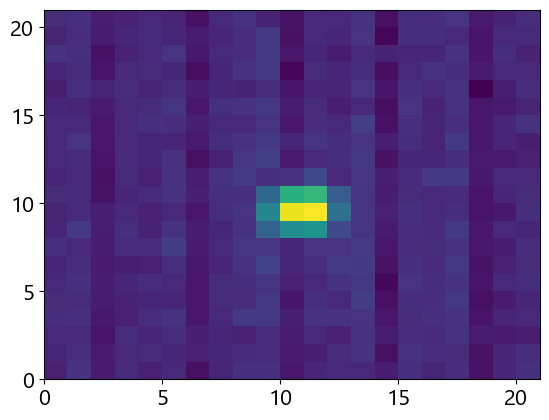

In [44]:
filename = 'D:\\Active_PIC\\Data\\PhotometryScans\\Device7a_I21_1x5Tri\\20260830\\voltage_scan_Ch68_V9p000_TECon_polarizer\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p000_KCh3_V8p044_KCh2_V0p000_outputA_52p000.npy'
data = np.load(filename)

plt.pcolormesh(data[0])

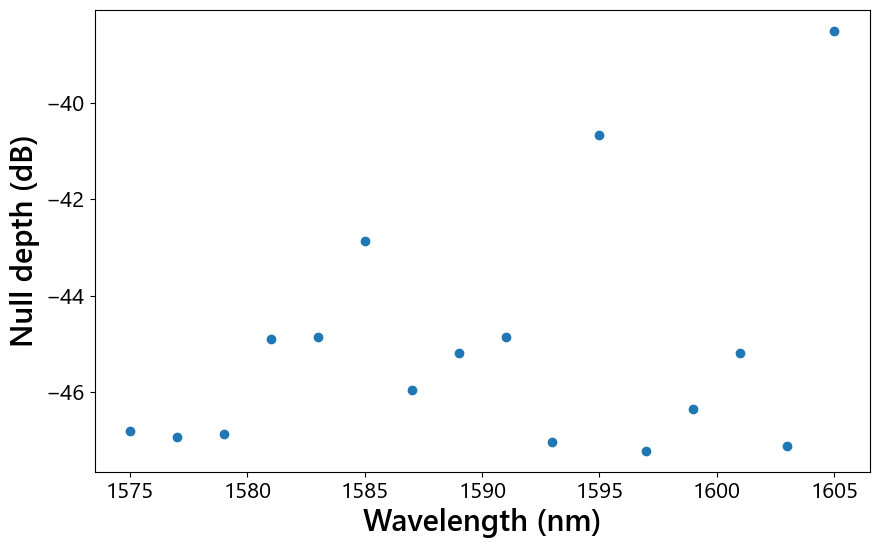

In [20]:
plt.figure(figsize=(10,6))
plt.plot(wav_vals, null_depths, 'o')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null depth (dB)')
plt.show()

In [161]:
filename_root = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_regular_trial1\\Device7a_I21_1x5Tri_Ch68_V9p100'
voltages_9p2 = np.load(f'{filename_root}_voltage.npy')
outputs_9p2 = np.load(f'{filename_root}_outputs.npy')
attens_9p2 = np.load(f'{filename_root}_attenuation.npy')
outputs_scaled_9p2 = outputs_9p2 * 10**(attens_9p2/10)

plt.plot(voltages_9p2[:,1], attens_9p2/10)

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_regular_trial1\\Device7a_I21_1x5Tri_Ch68_V9p100_voltage.npy'

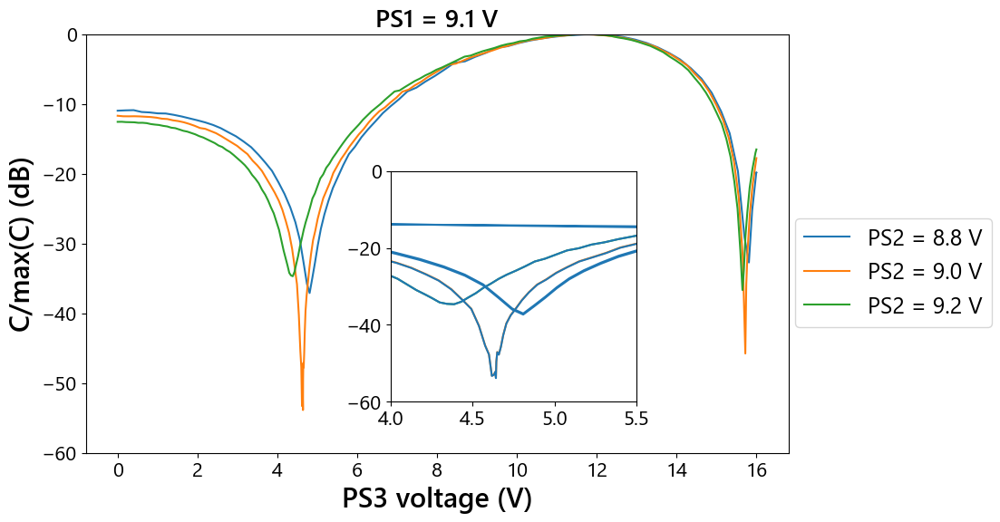

In [147]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

filename_root = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_trial3\\Device7a_I21_1x5Tri_Ch68_V9p100'
voltages = np.load(f'{filename_root}_voltage.npy')
outputs = np.load(f'{filename_root}_outputs.npy')
attens = np.load(f'{filename_root}_attenuation.npy')
V_PS2 = np.sort(list(set(voltages[:,0])))
V_PS2_sets = [voltages[:,0] == V for V in V_PS2]
outputs_scaled = outputs * 10**(attens/10)

data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_regular_trial0\\Device7a_I21_1x5Tri_Ch68_V9p100'
voltages_9p2 = np.load(f'{filename_root}_voltage.npy')
outputs_9p2 = np.load(f'{filename_root}_outputs.npy')
attens_9p2 = np.load(f'{filename_root}_attenuation.npy')
outputs_scaled_9p2 = outputs_9p2 * 10**(attens_9p2/10)

fig, ax = plt.subplots(figsize=(10,6))
for i, V in enumerate(V_PS2):
    output_V = outputs_scaled[V_PS2_sets[i]]
    ax.plot(voltages[:,1][V_PS2_sets[i]], 10*np.log10(output_V/np.max(output_V)), color=f'C{i}', label=f'PS2 = {V} V')
    ax.set_ylim(-60, 0)

# Inset
axins = inset_axes(ax, width="35%", height="55%", 
                   bbox_to_anchor=(-0.2, -0.3, 1, 1), bbox_transform=ax.transAxes)
for i, V in enumerate(V_PS2):
    output_V = outputs_scaled[V_PS2_sets[i]]
    axins.plot(voltages[:,1][V_PS2_sets[i]], 10*np.log10(output_V/np.max(output_V)), color=f'C{i}', label=f'PS2 = {V} V')
    axins.set_xlim(4,5.5)
    axins.set_ylim(-60, 0)

axins.plot(voltages_9p2[:,1], 10*np.log10(outputs_scaled_9p2/np.max(outputs_scaled)))#, marker='.', color='C2')

ax.set_xlabel('PS3 voltage (V)')
ax.set_ylabel('C/max(C) (dB)')
ax.set_title('PS1 = 9.1 V')
ax.legend(loc=(1.01, 0.3))
plt.show()

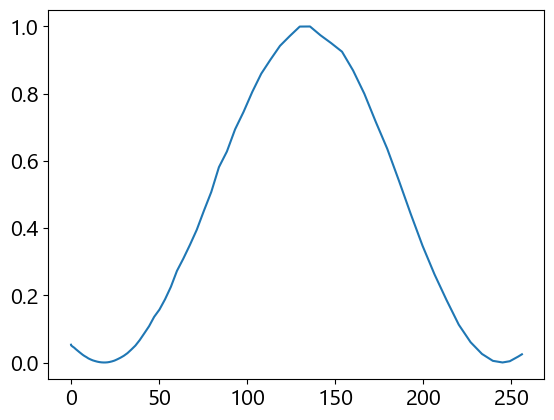

In [81]:
outputs_scaled = outputs*10**(attens/10)
phase = voltages[:,1]

plt.plot(voltages[:,1]**2, (outputs_scaled/np.max(outputs_scaled)))

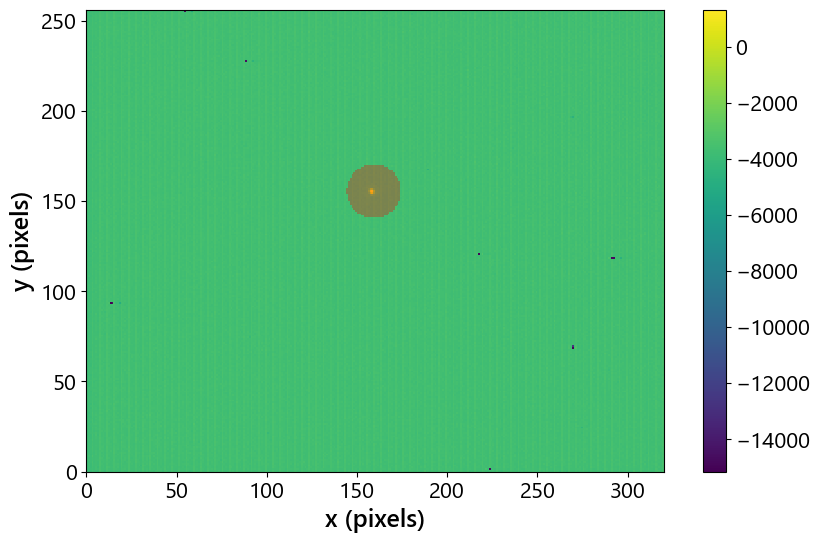

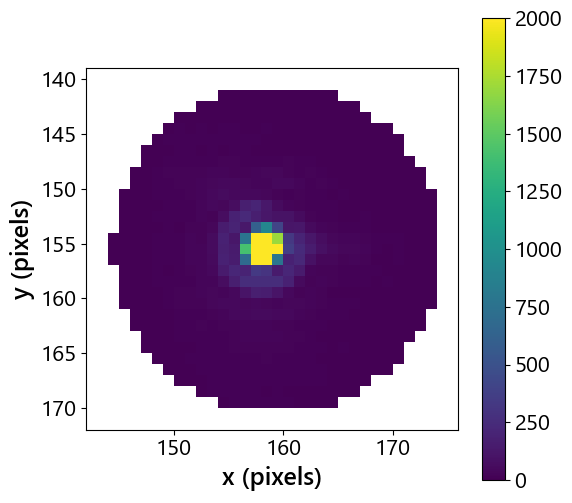

In [98]:
import matplotlib.colors as colors
data = np.load('D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_trial2\\Device7a_I21_1x5Tri_Ch68_V9p100_Ch69_V9p000_Ch43_V0p000_outputA_49p000.npy')
dark = np.loadtxt('D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260611\\voltage_scan\\Device7a_I21_1x5Tri_Ch68_V9p100_TECon_polarizer_trial2\\Device7a_I21_1x5Tri_Ch68_V9p100_dark.csv', delimiter=',')
data_reduce = np.mean(data, axis=0) - dark
outputs_masks = PIC.build_output_mask(data_reduce-dark, 1, mask_range=15)

PIC.plot_masked(data_reduce, outputs_masks[0], vmax=2000)

In [55]:
filename_log = glob.glob(data_dir+filename_root+"*.log")[0]
channel_str = filename_log.split(filename_root+'_')[-1].split('.log')[0]
channel_str = channel_str.split('_')
channels = [int(channel.split('Ch')[-1]) for channel in channel_str]

# Read voltages from data log
log = np.loadtxt(filename_log, delimiter=',')
with open(filename_log) as f:
    colnames = f.readline().strip().strip('# ').split(',')
log = np.core.records.fromarrays(log.T, names=colnames)

cols = [f'inputVoltage{channel}' for channel in channels]
np.column_stack([log[col] for col in cols])

array([[ 9.1       ,  9.1       ],
       [ 9.1       ,  0.2       ],
       [ 9.1       ,  0.3995703 ],
       [ 9.1       ,  0.59902188],
       [ 9.1       ,  0.79821812],
       [ 9.1       ,  0.9970362 ],
       [ 9.1       ,  1.19552982],
       [ 9.1       ,  1.3935443 ],
       [ 9.1       ,  1.59096964],
       [ 9.1       ,  1.78759951],
       [ 9.1       ,  1.98343992],
       [ 9.1       ,  2.17836763],
       [ 9.1       ,  2.37237488],
       [ 9.1       ,  2.56536904],
       [ 9.1       ,  2.75730404],
       [ 9.1       ,  2.94829339],
       [ 9.1       ,  3.13837567],
       [ 9.1       ,  3.32746728],
       [ 9.1       ,  3.51569076],
       [ 9.1       ,  3.6932846 ],
       [ 9.1       ,  3.8604459 ],
       [ 9.1       ,  4.02589497],
       [ 9.1       ,  4.17977497],
       [ 9.1       ,  4.31179063],
       [ 9.1       ,  4.43194069],
       [ 9.1       ,  4.55276551],
       [ 9.1       ,  4.67815   ],
       [ 9.1       ,  4.81729068],
       [ 9.1       ,

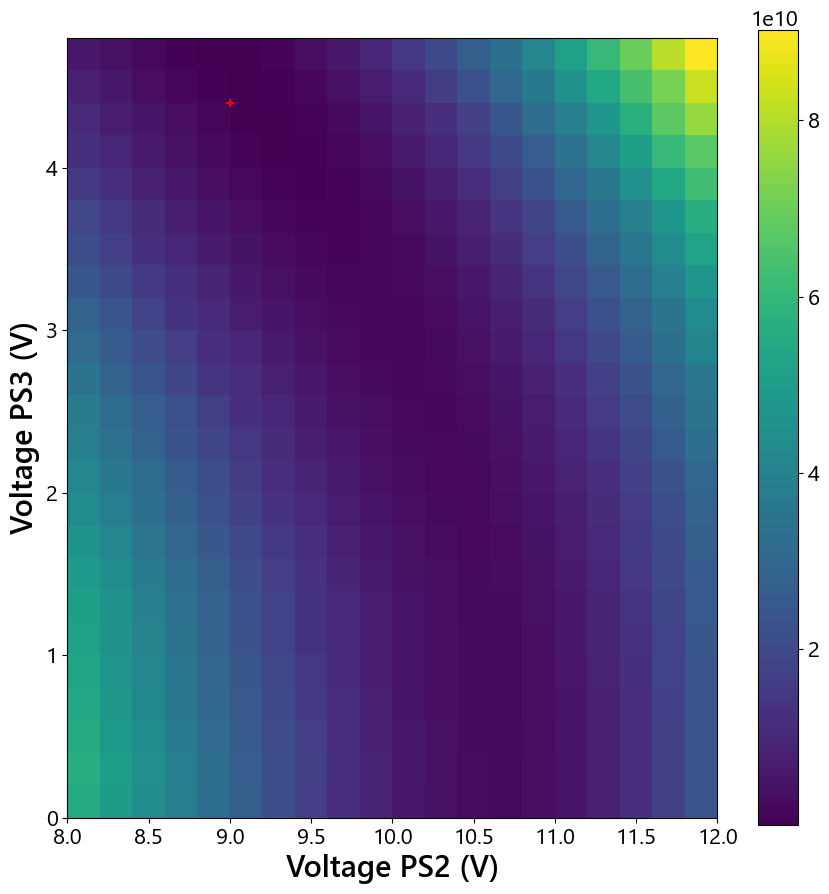

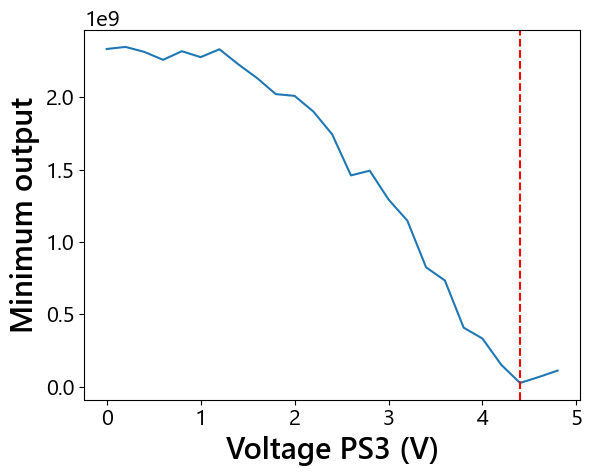

In [40]:
# filename_root = f'{device_name}'
# voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
# outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
# attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
ind =  np.argmin(outputs_scaled[:, :, 0])
col, row = np.unravel_index(ind, np.shape(outputs_scaled[:, :, 0]))

fig, ax = plt.subplots(figsize=(9,9))

im = ax.pcolormesh(
    voltages[0],
    voltages[1],
    outputs_scaled[:, :, 0].T
)
plt.scatter([voltages[0][col]], [voltages[1][row]], marker='+', color='r')

fig.colorbar(im, ax=ax)

ax.set_aspect('equal')
ax.set_xlabel('Voltage PS2 (V)')
ax.set_ylabel('Voltage PS3 (V)')

fig.tight_layout()   # fixed spacing
plt.show()


plt.figure()
plt.plot(voltages[1], np.min(outputs_scaled, axis=0))
plt.axvline(voltages[1][row], linestyle='dashed', color='r')
plt.xlabel('Voltage PS3 (V)')
plt.ylabel('Minimum output')
plt.show()


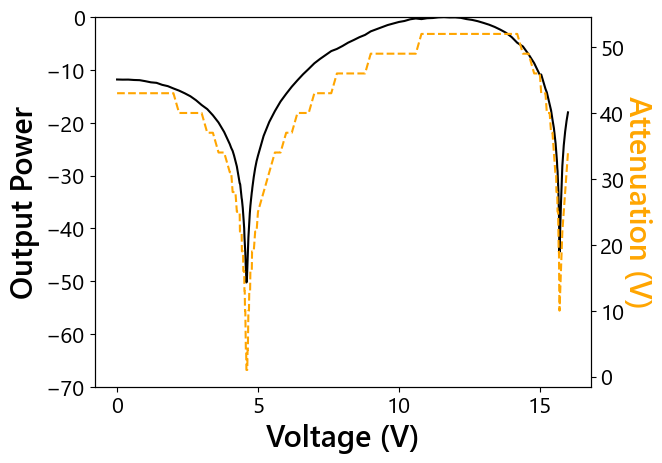

In [23]:
# data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260605\\voltage_scan\\Device7a_I21_1x5Tri_gridSearch_TECon_tlx10p0_lowV_polarizer_trial3\\'
# data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260605\\voltage_scan\\Device7a_I21_1x5Tri_gridSearch_TECon_tlx10p0_lowV_polarizer_trial3\\'
device_name = 'Device7a_I21_1x5Tri_Ch68_V9p100_Ch69_V9p000'
filename_root = f'{device_name}'
voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)

# data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260605\\voltage_scan\\Device7a_I21_1x5Tri_gridSearch_TECon_tlx1p0_lowV_polarizer_trial4\\'
# device_name = 'Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00'
# filename_root = f'{device_name}'
# voltages_null = np.load(f'{data_dir}{filename_root}_voltage.npy')
# outputs_null = np.load(f'{data_dir}{filename_root}_outputs.npy')
# attens_null = np.load(f'{data_dir}{filename_root}_attenuation.npy')
# outputs_null_scaled = PIC.scale_voltage_scan(outputs_null, attens_null) * 10**((1-10)/10)

# voltages = np.hstack([voltages.flatten(), voltages_null.flatten()])
# outputs_scaled = np.hstack([outputs_scaled.flatten(), outputs_null_scaled.flatten()])
# ind = np.argsort(voltages)
# voltages, outputs_scaled = voltages[ind], outputs_scaled[ind]

fig, ax1 = plt.subplots()
ax1.plot(voltages, 10*np.log10(outputs_scaled/np.max(outputs_scaled)), 'k')
# ax1.plot(voltages, outputs_scaled/np.max(outputs_scaled), 'k')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax1.set_ylim(-70, 0)
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--', color='orange')
# ax2.set_ylim(3.15, 4.75)
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20, color='orange')
plt.show()

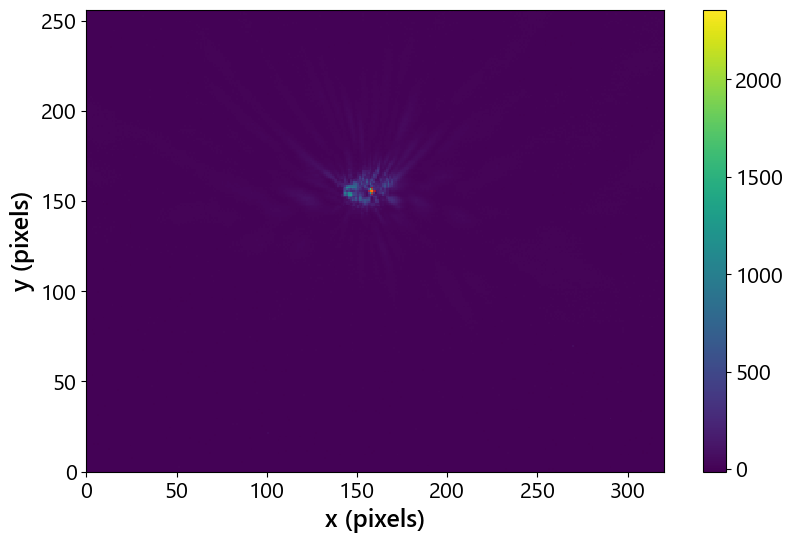

In [25]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260605\\voltage_scan\\Device7a_I21_1x5Tri_gridSearch_TECon_tlx1p0_lowV_polarizer_trial4\\'
device_name = 'Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00'
filename_root = f'{device_name}'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 1

filename_ref = f'{data_dir}Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V4p572_outputA_2p500.npy'
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

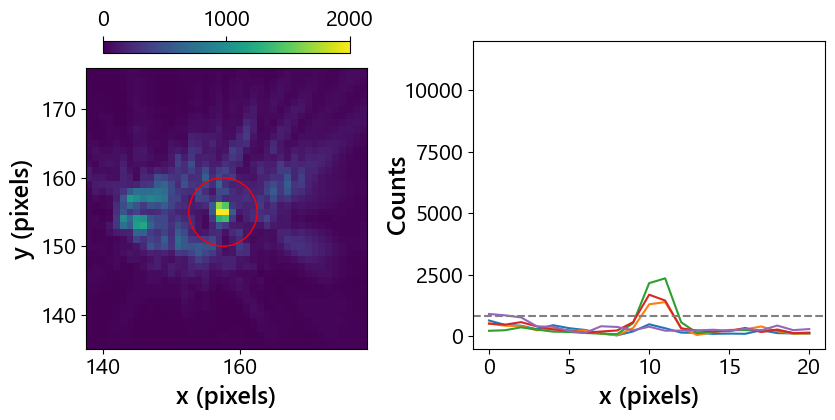

In [45]:
from matplotlib import colors
r, c = int(coords[0][0]), int(coords[0][1])
data_reduce = np.mean(data, axis=0)-dark

fig, ax = plt.subplots(1, 2, figsize=(10,4))
norm = colors.Normalize(vmin=0, vmax=2000)

im0 = ax[0].imshow(np.mean(data, axis=0)-dark, norm=norm, cmap='viridis', aspect='auto')
fig.colorbar(im0, ax=ax[0], location='top', pad=0.05, fraction=0.04)

circle = plt.Circle((coords[0, 1], coords[0, 0]), radius=5, edgecolor='red', facecolor='none', linewidth=1)
ax[0].add_patch(circle)

ax[0].set_xlabel('x (pixels)', fontsize=18)
ax[0].set_ylabel('y (pixels)', fontsize=18)
ax[0].set_ylim(coords[0][0]-20, coords[0][0]+21)
ax[0].set_xlim(np.min(coords[:, 1]-20), np.max(coords[:, 1]+21))
ax[0].set_aspect('equal')

ax[1].plot(data_reduce[r-2:r+3, c-10:c+11].T)
ax[1].axhline(5*np.std(dark), color='gray', linestyle='dashed')
ax[1].set_xlabel('x (pixels)', fontsize=18)
ax[1].set_ylabel('Counts', fontsize=18, labelpad=-5)
ax[1].set_ylim(-500, 12000)
plt.show()

In [ ]:
device_name, num_outputs = 'Device7a_I21_1x5Tri', 1
# data_dir = f'D:\\Active_PIC\\PhotometryScans\\{device_name}\\20260605\\voltage_scan\\Device7a_I21_1x5Tri_TECon_lowV_polarizer_trial2\\'
files = glob.glob(data_dir+'Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V*.npy')
sorted_files = sorted(files, key=lambda x: float(x.split(data_dir)[-1].split('Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V')[-1].split('_')[0].replace('p', '.')))
sorted_files
for file in sorted_files:
    data = np.load(file)
    data_stacked = np.mean(data, axis=0)
    np.save(file.split('.npy')[0]+'_stack.npy', data_stacked)

In [31]:
filename.split('_atten')[-1]

'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260604\\voltage_scan\\Device7a_I21_1x5Tri_TECon_lowV_polarizer_trial0\\Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V0p00_outputA_4p50_stack.npy'

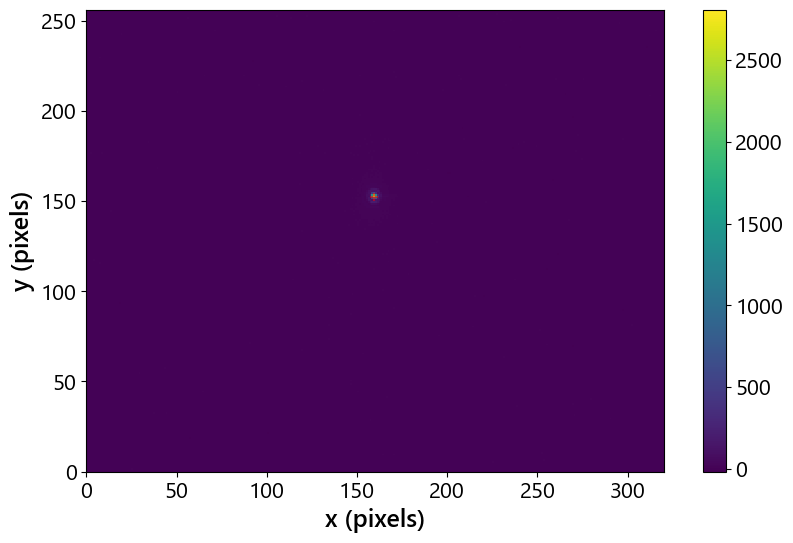

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (420, 240) to (432, 240) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


In [ ]:
from matplotlib import colors
import imageio.v2 as imageio
import gc

# device_name, num_outputs = 'Device7a_I21_1x5Tri', 5
# data_dir = f'D:\\Active_PIC\\PhotometryScans\\{device_name}\\20260604\\atten_scan\\'
# files = glob.glob(data_dir+'*.npy')
# sorted_files = sorted(files, key=lambda x: int(x.split(data_dir)[-1].split("_")[0]))
files = glob.glob(data_dir+'Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V*_stack.npy')
sorted_files = sorted(files, key=lambda x: float(x.split(data_dir)[-1].split('Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V')[-1].split('_')[0].replace('p', '.')))
data_ref = np.load(sorted_files[0])
dark = np.loadtxt(f'{data_dir}{device_name}_Ch68_V9p10_Ch69_V9p00_dark.csv', delimiter=',')
coords = PIC.find_output_centers(data_ref-dark, 1, None)



# df = np.genfromtxt(data_dir+f"{device_name}_attenScan.log", delimiter=',', names=True)
# output_sum, output_extract = df['nullOutputSum']*10**(df['externalAttendB']/10), df['nullOutputExtract']*10**(df['externalAttendB']/10)

# PS1, PS2, PS3 = 68, 69, 43
# V_PS1, V_PS2 = 9.1, 9.0
# PS1_str, PS2_str = f'{V_PS1:0.2f}'.replace('.', 'p'), f'{V_PS2:0.2f}'.replace('.', 'p')

# Set XPOW voltages for reference image
# dark = np.loadtxt(f'{data_dir}{device_name}_Ch68_V9p10_Ch69_V9p00_dark.csv', delimiter=',')
R = 5
r, c = int(coords[0, 0]), int(coords[0, 1])

outfile = f'{data_dir}{device_name}_voltageScan.mp4'
with imageio.get_writer(outfile, fps=1.0, codec='libx264') as writer:
    for i, filename in enumerate(sorted_files):
        phase = float(filename.split('Ch43_V')[-1].split('_')[0].replace('p', '.'))
        atten = float(filename.split('outputA_')[-1].split('_')[0].replace('p', '.'))
        data = np.load(filename, allow_pickle=False)
        data_reduce = data-dark

        fig, ax = plt.subplots(1, 2, figsize=(7,4), dpi=60, gridspec_kw={'width_ratios':[1.5,1], 'wspace':0.6})
        fig.subplots_adjust(left=0.06, right=0.98, bottom=0.20, top=0.72)
        norm = colors.Normalize(vmin=0, vmax=12000)

        im0 = ax[0].imshow(data_reduce, norm=norm, cmap='viridis', aspect='auto')
        fig.colorbar(im0, ax=ax[0], location='top', pad=0.05, fraction=0.04)

        circle = plt.Circle((coords[0, 1], coords[0, 0]), radius=R, edgecolor='red', facecolor='none', linewidth=1)
        ax[0].add_patch(circle)

        ax[0].set_xlabel('x (pixels)', fontsize=18)
        ax[0].set_ylabel('y (pixels)', fontsize=18)
        ax[0].set_ylim(r-20, r+21)
        ax[0].set_xlim(np.min(coords[:, 1]-20), np.max(coords[:, 1]+21))
        ax[0].set_aspect('equal')

        ax[1].plot(data_reduce[r-2:r+3, c-10:c+11].T)
        ax[1].axhline(11*np.std(dark), color='gray', linestyle='dashed')
        ax[1].set_xlabel('x (pixels)', fontsize=18)
        ax[1].set_ylabel('Counts', fontsize=18, labelpad=-5)
        ax[1].set_ylim(-500, 12000)

        fig.suptitle(f'Phase: {phase:0.1f} V \n Attenuation: {atten:0.1f} V, {PIC.externalVOA_voltage_to_dB(atten):0.1f} dB',
                     fontsize=20, fontweight='semibold', y=0.95)
        
        # fig.show()

        fig.canvas.draw()

        frame = np.asarray(fig.canvas.buffer_rgba())[..., :3]

        writer.append_data(frame)

        plt.close(fig)
        del data_reduce, frame
        gc.collect()

In [45]:
10**((atten_0_dB-atten_1_dB)/10)

0.7025976320462314

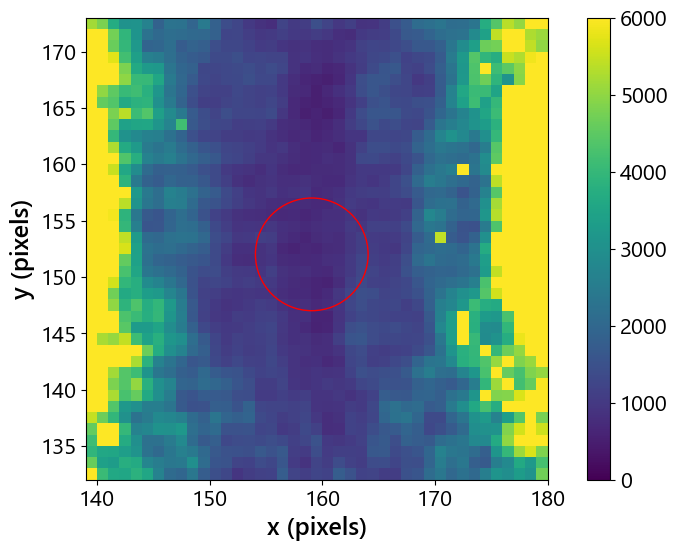

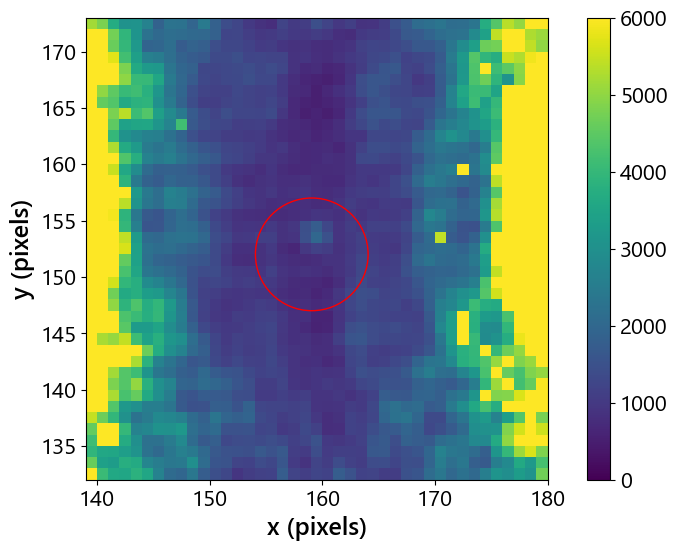

In [46]:
filename_0 = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260604\\voltage_scan\\Device7a_I21_1x5Tri_TECon_lowV_polarizer_trial0\\Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V4p50_outputA_3p30_stack.npy'
filename_1 = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260603\\atten_scan\\100_Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_Ch43_V4p50_atten3p40_stack.npy'
atten_0, atten_1 = 3.3, 3.4
atten_0_dB, atten_1_dB = PIC.externalVOA_voltage_to_dB(atten_0), PIC.externalVOA_voltage_to_dB(atten_1)

mask, R = np.zeros(np.shape(dark), bool), 5
r, c = int(coords[0, 0]), int(coords[0, 1])
y, x = np.ogrid[:dark.shape[0], :dark.shape[1]]
mask = (x-c)**2 + (y-r)**2 <= R**2
y_dim, x_dim = np.shape(dark)

data_0 = np.load(filename_0) - dark
data_1 = np.load(filename_1) - dark

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data_1, zorder=0, vmin=0, vmax=6000)
circle = plt.Circle((coords[0, 1], coords[0, 0]), radius=R, edgecolor='red', facecolor='none', linewidth=1)
ax.add_patch(circle)
# for coord in coords:
#     ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_ylim(r-20, r+21)
ax.set_xlim(np.min(coords[:, 1]-20), np.max(coords[:, 1]+21))
ax.set_aspect('equal')
plt.show()

data_1[mask] = data_1[mask] + data_0[mask] * 10**((atten_0_dB-atten_1_dB)/10)

fig, ax = plt.subplots(1, 1, figsize=(10,6))
im = ax.pcolormesh(data_1, zorder=0, vmin=0, vmax=6000)
circle = plt.Circle((coords[0, 1], coords[0, 0]), radius=R, edgecolor='red', facecolor='none', linewidth=1)
ax.add_patch(circle)
# for coord in coords:
#     ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax, fraction=0.05*y_dim/x_dim)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_ylim(r-20, r+21)
ax.set_xlim(np.min(coords[:, 1]-20), np.max(coords[:, 1]+21))
ax.set_aspect('equal')
plt.show()

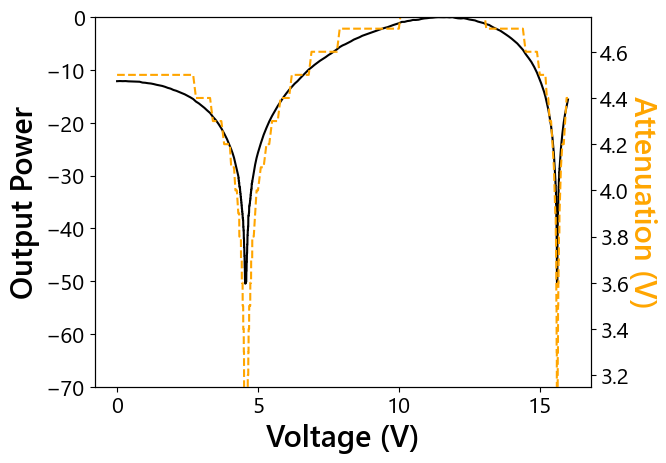

In [11]:
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)

fig, ax1 = plt.subplots()
ax1.plot(voltages, 10*np.log10(outputs_scaled/np.max(outputs_scaled)), 'k')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax1.set_ylim(-70, 0)
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--', color='orange')
ax2.set_ylim(3.15, 4.75)
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20, color='orange')
plt.show()

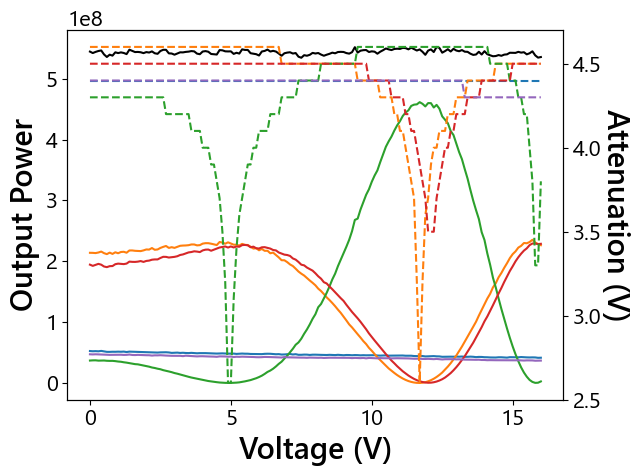

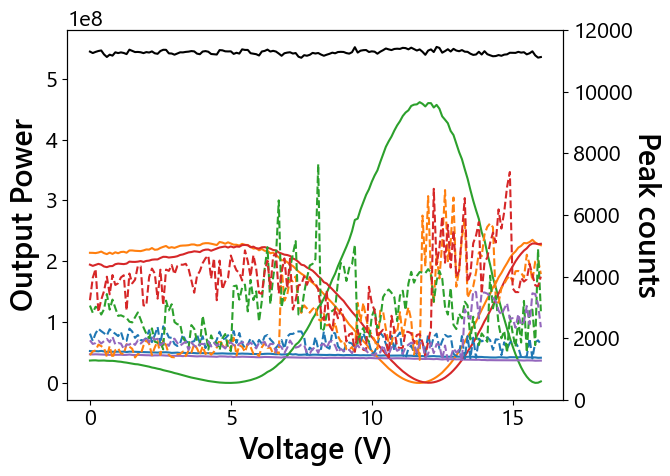

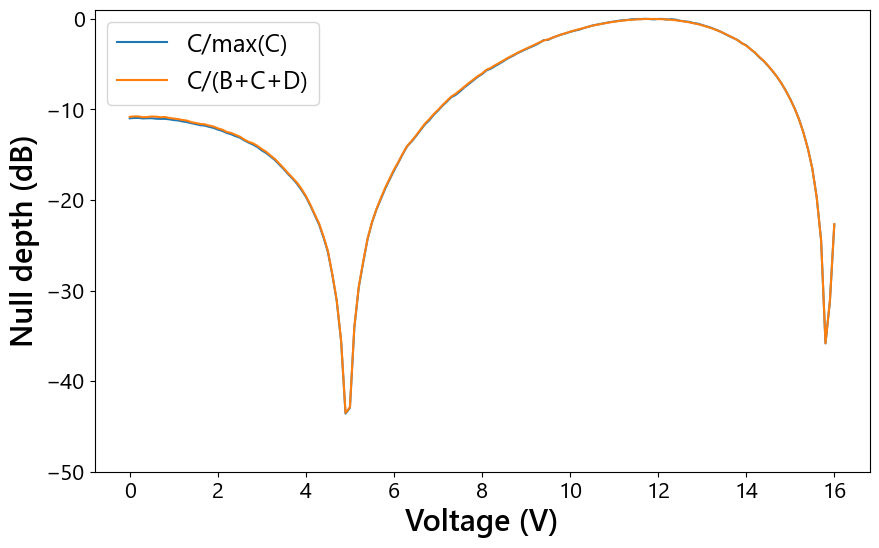

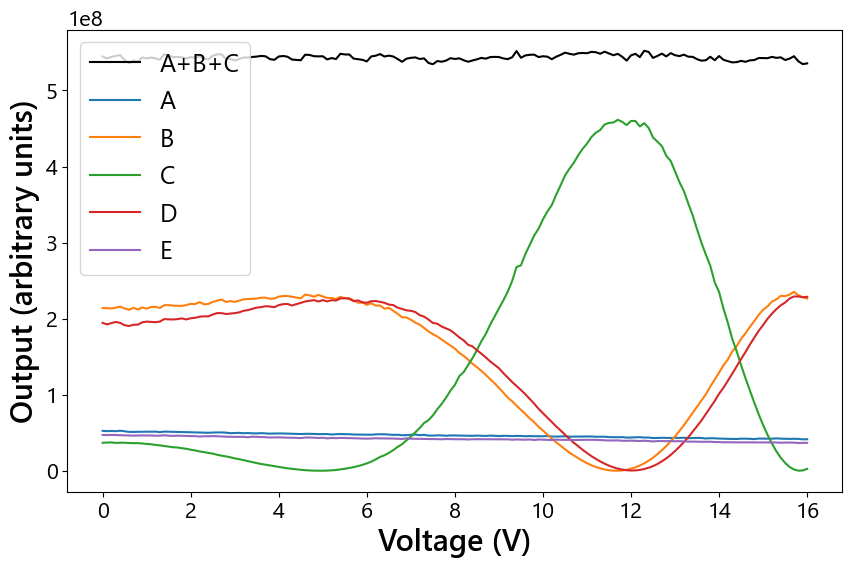

In [ ]:
# data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260521\\voltage_scan\\Device7a_I21_1x5Tri_amoeba_TECoff_lowV_trial2\\'
# filename_root = 'Device6a_I18_1x5Tri'
# num_outputs = 5

# voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
# outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
# attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
outputs_flux_scaled = PIC.scale_voltage_scan(outputs_flux, attens)
flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:, 1:4], axis=1)
null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C+D+E')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, attens, '--')
ax2.set_ylabel('Attenuation (V)', rotation=270, labelpad=20)
plt.show()

fig, ax1 = plt.subplots()
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C+D+E')
ax1.plot(voltages, outputs_scaled)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
ax2 = ax1.twinx()
ax2.plot(voltages, outputs_flux, '--')
ax2.set_ylabel('Peak counts', rotation=270, labelpad=20)
ax2.set_ylim(0, 12000)
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, null_maxC, label='C/max(C)')
plt.plot(voltages, null_BCD, label='C/(B+C+D)')
plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')
plt.ylim(-50, 1)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='A+B+C+D+E')
plt.plot(voltages, outputs_scaled[:,0], label='A')
plt.plot(voltages, outputs_scaled[:,1], label='B')
plt.plot(voltages, outputs_scaled[:,2], label='C')
plt.plot(voltages, outputs_scaled[:,3], label='D')
plt.plot(voltages, outputs_scaled[:,4], label='E')
plt.xlabel('Voltage (V)')
plt.ylabel('Output (arbitrary units)')
plt.legend()
plt.show()

In [ ]:
null_TECon, outputs_TECon = [], []
filename_root, num_outputs = 'Device7a_I21_1x5Tri', 5
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260520\\voltage_scan\\{filename_root}_amoeba_TECon_lowV_trial{i}\\'
    voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:,1:4], axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECon.append(null_maxC)
    outputs_TECon.append(outputs_scaled)

null_TECoff, outputs_TECoff = [], []
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260520\\voltage_scan\\{filename_root}_amoeba_TECoff_lowV_trial{i}\\'
    voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled[:,1:4], axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_TECoff.append(null_maxC)
    outputs_TECoff.append(outputs_scaled)

null_pol, outputs_pol = [], []
for i in range(3):
    filename_root, num_outputs = 'Device7a_I21_1x5Tri', 5
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260527\\voltage_scan\\{filename_root}_amoeba_TECon_lowV20250520_polarizer_trial{i}\\'
    voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
    outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
    attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])

    outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
    flux_ratio_maxC = outputs_scaled[:, 2]/np.max(outputs_scaled[:,2])
    flux_ratio_BCD = outputs_scaled[:, 2]/np.sum(outputs_scaled, axis=1)
    null_maxC, null_BCD = 10*np.log10(flux_ratio_maxC), 10*np.log10(flux_ratio_BCD)

    null_pol.append(null_maxC)
    outputs_pol.append(outputs_scaled)


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(10,6))
for i in range(3):
    ax.plot(voltages, null_TECon[i], color=f'C{i}', label=f'Trial {i+1}')
    ax.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    ax.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Null depth (dB)')
ax.set_ylim(-40, 1)
ax.legend(loc=(1.01, 0.3))
# Inset
axins = inset_axes(ax, width="35%", height="55%", 
                   bbox_to_anchor=(-0.2, -0.3, 1, 1), bbox_transform=ax.transAxes)
for i in range(3):
    axins.plot(voltages, null_TECon[i], color=f'C{i}')
    axins.plot(voltages, null_TECoff[i], color=f'C{i}', linestyle='dashed')
    axins.plot(voltages, null_pol[i], color=f'C{i}', linestyle='dotted')
axins.set_xlim(14, 15.5)
axins.set_ylim(-40, 1)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
plt.subplots_adjust(wspace=0.03)
for i in range(3):
    outputs_TECon_tot = np.sum(outputs_TECon[i], axis=1)
    outputs_TECoff_tot = np.sum(outputs_TECoff[i], axis=1)
    outputs_pol_tot = np.sum(outputs_pol[i], axis=1)       

    if i==0:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k', label='A+B+C+D+E')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}', label=f'{chr(65+j)}')
    else:
        ax[0].plot(voltages, outputs_TECon_tot/np.max(outputs_TECon_tot), 'k')
        ax[1].plot(voltages, outputs_TECoff_tot/np.max(outputs_TECoff_tot), 'k')
        ax[0].plot(voltages, outputs_pol_tot/np.max(outputs_pol_tot), color='k', linestyle='dotted')
        for j in range(num_outputs):
            ax[0].plot(voltages, outputs_TECon[i][:,j]/np.max(outputs_TECon_tot), color=f'C{j}')
            ax[0].plot(voltages, outputs_pol[i][:,j]/np.max(outputs_pol_tot), color=f'C{j}', linestyle='dotted')
            ax[1].plot(voltages, outputs_TECoff[i][:,j]/np.max(outputs_TECoff_tot), color=f'C{j}')

ax[0].set_title('TEC on')
ax[1].set_title('TEC off')
ax[0].set_xlabel('Voltage (V)', labelpad=1.5)
ax[0].set_ylabel('Normalized output')
ax[0].xaxis.set_label_coords(1.0, -0.08)
ax[1].legend(loc=(1.01, 0.3))
plt.show()

IndexError: list index out of range

In [240]:
data_dir

'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260527\\voltage_scan\\Device7a_I21_1x5Tri_amoeba_TECon_lowV_polarizer_trial2\\'

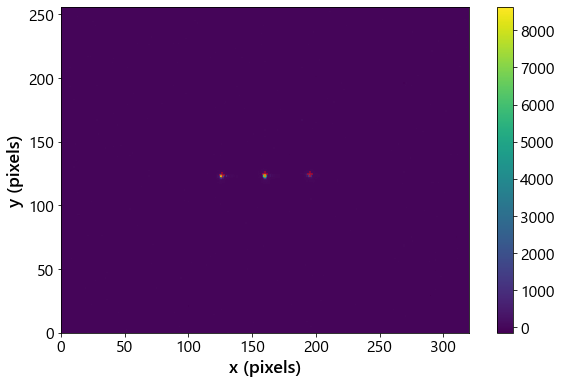

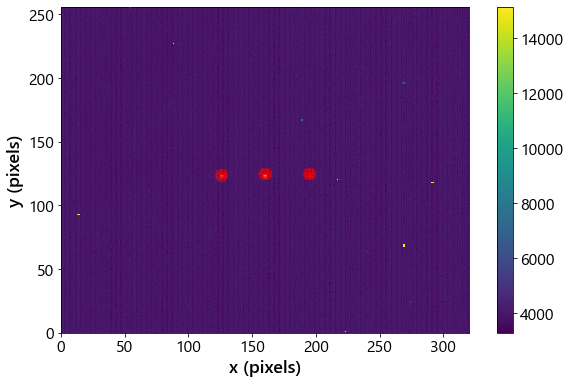

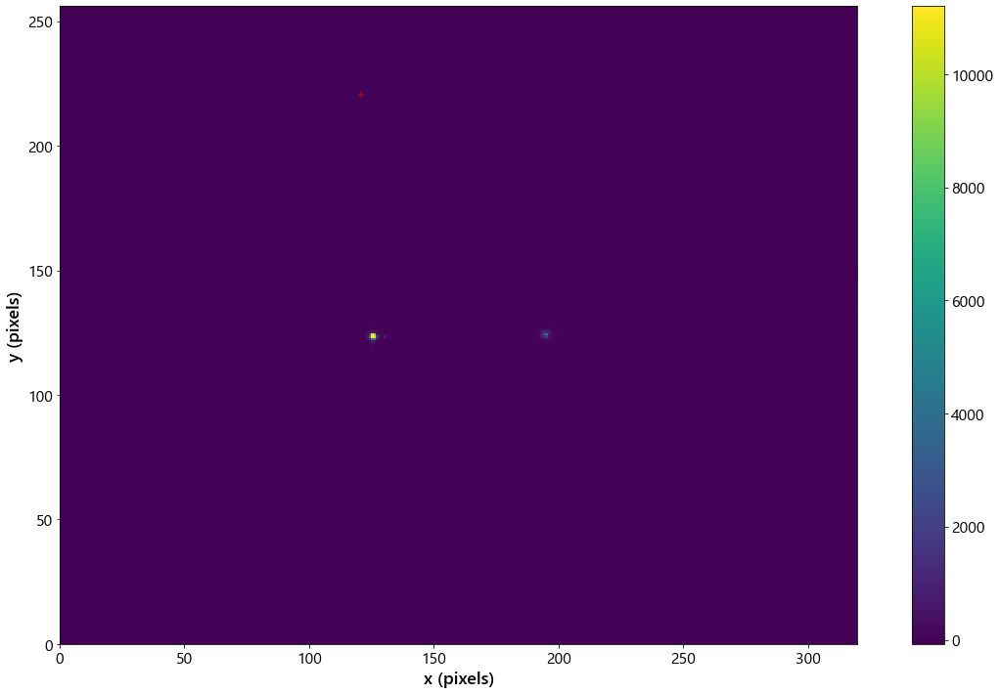

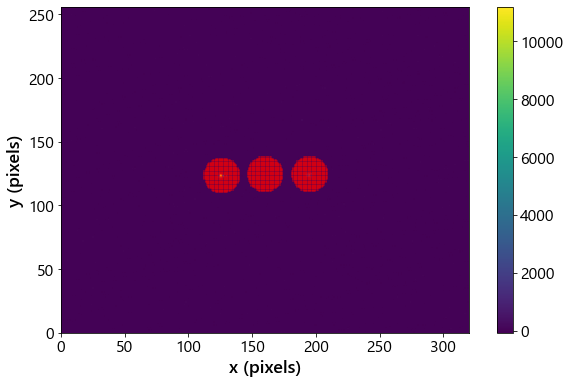

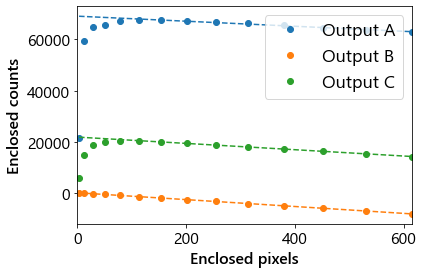

...

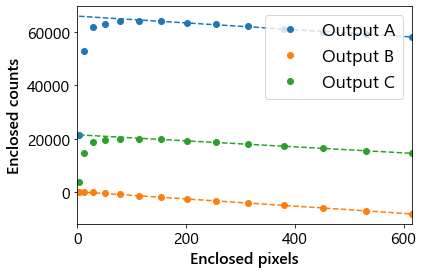

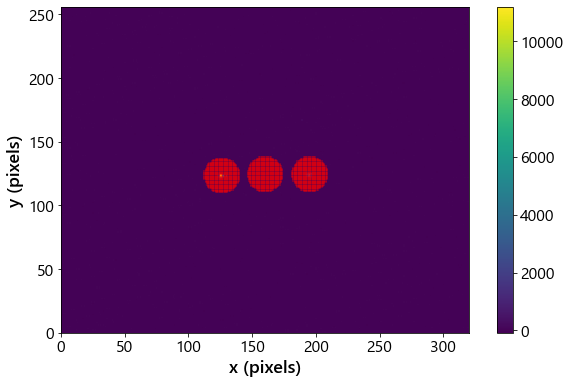

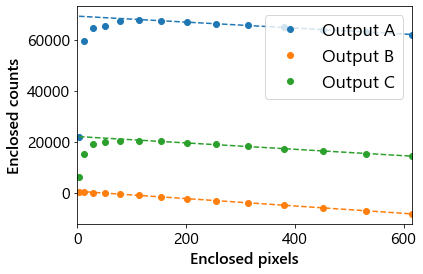

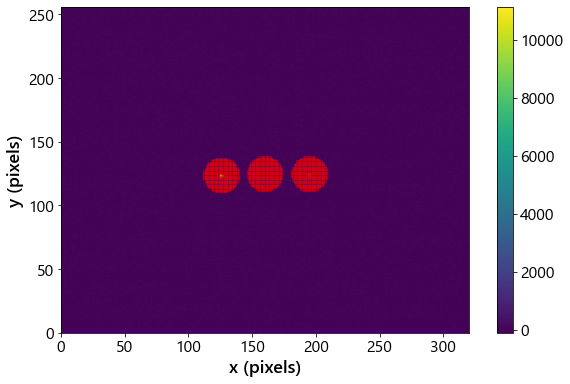

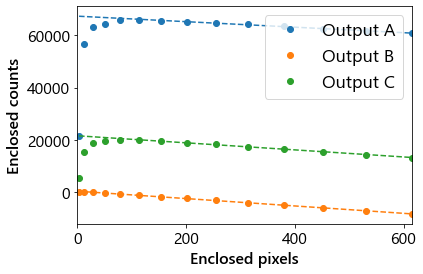

In [16]:
data_dir = 'D:\\Active_PIC\\PhotometryScans\\Device5a_I15_1x3Tri\\20260506\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECoff_trial0\\'
filename_root = 'Device5a_I15_1x3Tri'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 3

filename_ref = data_dir+'Device5a_I15_1x3Tri_Ch66_V0p30_outputC_4p40.npy'
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

outputs_masks = PIC.build_output_mask(data[0], num_outputs, coords=coords, plot=True)

filename_ref = data_dir+'Device5a_I15_1x3Tri_Ch66_V12p00_outputC_4p40.npy'
data = np.load(filename_ref, allow_pickle=True)#, 

fig, ax = plt.subplots(1, 1, figsize=(20,12))
im = ax.pcolormesh(data[0]-dark, zorder=0)
# for coord in coords:
ax.scatter(coord[1]+0.5, coord[0]+0.5, marker='+', color='r', alpha=0.5)
fig.colorbar(im, ax=ax)
ax.set_xlabel('x (pixels)', fontsize=18)
ax.set_ylabel('y (pixels)', fontsize=18)
ax.set_aspect('equal')
plt.show()

ind_max = np.argmax(data[0]-dark)
row, col = np.unravel_index(ind_max, np.shape(dark))

output = PIC.extract_outputs(data-dark, num_outputs, r_max=15, r_lin=5, filt_size=5, plot=True, coords=coords, stack=True)

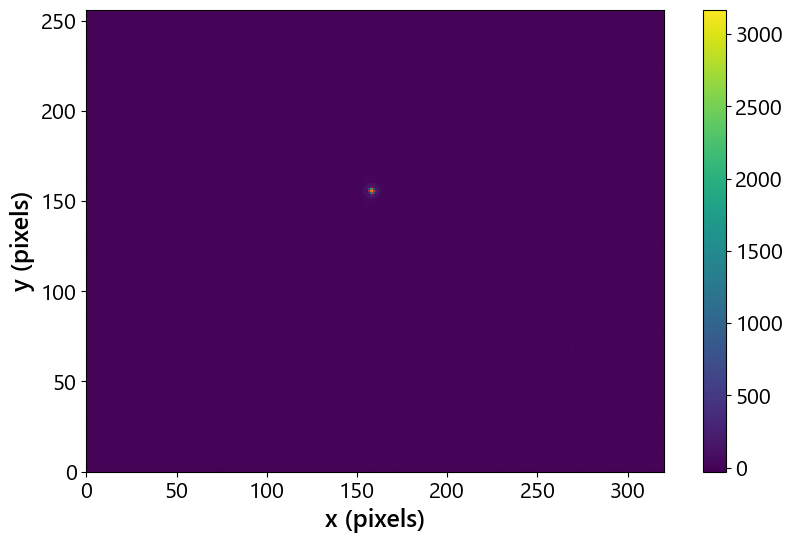

[8.0, 8.0, 0.0] [4.5]
[8.0, 8.0, 0.5] [4.5]
[8.0, 8.0, 1.0] [4.5]
[8.0, 8.0, 1.5] [4.4]
[8.0, 8.0, 2.0] [4.4]
[8.0, 8.0, 2.5] [4.4]
[8.0, 8.0, 3.0] [4.3]
[8.0, 8.0, 3.5] [4.2]
[8.0, 8.0, 4.0] [3.9]
[8.0, 8.0, 4.5] [3.7]
[8.0, 8.5, 0.0] [4.4]
[8.0, 8.5, 0.5] [4.4]
[8.0, 8.5, 1.0] [4.4]
[8.0, 8.5, 1.5] [4.4]
[8.0, 8.5, 2.0] [4.3]
[8.0, 8.5, 2.5] [4.3]
[8.0, 8.5, 3.0] [4.2]
[8.0, 8.5, 3.5] [4.1]
[8.0, 8.5, 4.0] [4.1]
[8.0, 8.5, 4.5] [4.2]
[8.0, 9.0, 0.0] [4.4]
[8.0, 9.0, 0.5] [4.4]
[8.0, 9.0, 1.0] [4.4]
[8.0, 9.0, 1.5] [4.3]
[8.0, 9.0, 2.0] [4.3]
[8.0, 9.0, 2.5] [4.3]
[8.0, 9.0, 3.0] [4.3]
[8.0, 9.0, 3.5] [4.3]
[8.0, 9.0, 4.0] [4.3]
[8.0, 9.0, 4.5] [4.4]
[8.0, 9.5, 0.0] [4.4]
[8.0, 9.5, 0.5] [4.4]
[8.0, 9.5, 1.0] [4.4]
[8.0, 9.5, 1.5] [4.4]
[8.0, 9.5, 2.0] [4.4]
[8.0, 9.5, 2.5] [4.4]
[8.0, 9.5, 3.0] [4.4]
[8.0, 9.5, 3.5] [4.4]
[8.0, 9.5, 4.0] [4.4]
[8.0, 9.5, 4.5] [4.5]
[8.0, 10.0, 0.0] [4.4]
[8.0, 10.0, 0.5] [4.4]
[8.0, 10.0, 1.0] [4.4]
[8.0, 10.0, 1.5] [4.4]
[8.0, 10.0, 2.0] [4.4]
[8.0,

In [7]:
device_name = 'Device7a_I21_1x5Tri'
data_dir = f'D:\\Active_PIC\\PhotometryScans\\{device_name}\\20260605\\voltage_scan\\null_search_0\\'
filename_root = f'{device_name}'
filename_dark = f'{data_dir}{filename_root}_dark.csv'
num_outputs = 1

filename_ref = glob.glob(data_dir+'*.npy')[0]
data = np.load(filename_ref, allow_pickle=True)#, 
dark = np.loadtxt(filename_dark, delimiter=',')
coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)
# masks = PIC.build_output_mask(data[0]-dark, num_outputs, coords)

voltages, outputs, attens, outputs_flux = PIC.reduce_voltage_scan(data_dir+filename_root, num_outputs, filename_dark, 
                                                                              coords=coords, r_lin=5, r_max=15, plot=False)

np.save(f'{data_dir}{filename_root}_voltage', voltages)
np.save(f'{data_dir}{filename_root}_outputs', outputs)
np.save(f'{data_dir}{filename_root}_attenuation', attens)

In [22]:
[np.shape(frame) for frame in frames]

[(713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 752, 4),
 (713, 764, 4),
 (713, 752, 4)]

In [ ]:
import io
import imageio

outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
frames = []

for i3, v3 in enumerate(voltages[2]):
    fig, ax = plt.subplots(figsize=(9,9))

    im = ax.pcolormesh(
        voltages[0],
        voltages[1],
        outputs_scaled[:, :, i3, 0]
    )

    fig.colorbar(im, ax=ax)

    ax.set_aspect('equal')
    ax.set_xlabel('Voltage PS1 (V)')
    ax.set_ylabel('Voltage PS2 (V)')
    ax.set_title(f"Voltage PS3: {v3:.2f} V")

    fig.tight_layout()   # fixed spacing

    buf = io.BytesIO()
    fig.savefig(buf, format='png')   # remove bbox_inches='tight'
    plt.close(fig)

    buf.seek(0)
    frames.append(imageio.imread(buf))

imageio.mimsave(filename_root+"_null.gif", frames, fps=1, loop=0)

In [24]:
import io
import imageio

outputs_scaled = PIC.scale_voltage_scan(outputs, attens)
frames = []

for i3, v3 in enumerate(voltages[2]):
    fig, ax = plt.subplots(figsize=(9,9))

    im = ax.pcolormesh(
        voltages[0],
        voltages[1],
        outputs_scaled[:, :, i3, 0]
    )

    fig.colorbar(im, ax=ax)

    ax.set_aspect('equal')
    ax.set_xlabel('Voltage PS1 (V)')
    ax.set_ylabel('Voltage PS2 (V)')
    ax.set_title(f"Voltage PS3: {v3:.2f} V")

    fig.tight_layout()   # fixed spacing

    buf = io.BytesIO()
    fig.savefig(buf, format='png')   # remove bbox_inches='tight'
    plt.close(fig)

    buf.seek(0)
    frames.append(imageio.imread(buf))

imageio.mimsave(f"{data_dir}{filename_root}_null.gif", frames, fps=1, loop=0)

print("Null: ", np.min(outputs_scaled))

Null:  103527.2033024219


In [33]:
[voltages[i][ind[i]] for i in range(len(voltages))]

[10.0, 11.0, 2.5]

In [30]:
output_min = np.min(outputs_scaled)
ind = np.unravel_index(np.argmin(outputs_scaled), np.shape(outputs_scaled))
output_max = np.load("D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260604\\voltage_scan\\Device7a_I21_1x5Tri_TECon_lowV_polarizer_trial0\\Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_outputs.npy")
atten_max = np.load("D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260604\\voltage_scan\\Device7a_I21_1x5Tri_TECon_lowV_polarizer_trial0\\Device7a_I21_1x5Tri_Ch68_V9p10_Ch69_V9p00_attenuation.npy")
output_max = np.max(PIC.scale_voltage_scan(output_max, atten_max))
null_depth = 10*np.log10(output_min/output_max)
null_depth


-47.32410779165389

In [118]:
# data_dir = 'D:\\Active_PIC\\2026-01-21\\Device6a_I18_1x5Tricoupler_scan0\\'
# filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
# filename_dark = data_dir+filename_root+'_dark.csv'

# filename_ref = data_dir+'Device5a_I15_1x3Tri_Ch66_V6p20_low_laserVOA1_attenVolt3.npy'
# data = np.load(filename_ref, allow_pickle=True)#, 
# dark = np.loadtxt(filename_dark, delimiter=',')
# coords = PIC.find_output_centers(np.mean(data, axis=0)-dark, num_outputs, filt_size=20)

# voltages, outputs_low = PIC.reduce_voltage_scan_fixedAtten(data_dir+filename_root, 'low', num_outputs, 
#                                                            filename_dark=filename_dark, coords=coords)
# voltages, outputs_high = PIC.reduce_voltage_scan_fixedAtten(data_dir+filename_root, 'high', num_outputs, 
#                                                            filename_dark=filename_dark, coords=coords)

outputs_low = np.load('C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-01-05-Active_splitters_imaging\\Device6a_I18_1x5Tricoupler\\Device6a_I18_1x5Tricoupler_Ch20_Ch19_Ch41_outputsNull.npy')
outputs_high = np.load('C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-01-05-Active_splitters_imaging\\Device6a_I18_1x5Tricoupler\\Device6a_I18_1x5Tricoupler_Ch20_Ch19_Ch41_outputsBright.npy')
voltages = np.load('C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-01-05-Active_splitters_imaging\\Device6a_I18_1x5Tricoupler\\Device6a_I18_1x5Tricoupler_voltagesReduced.npy')

atten_low_dB, atten_high_dB = PIC.externalVOA_voltage_to_dB(3.0), PIC.externalVOA_voltage_to_dB(4.7)
scaling = 10**(abs(20-1)/10)# * 10**(abs(atten_low_dB-atten_high_dB)/10)

norm_intensity = np.sum(outputs_high[:,:,:,1:4], axis=3) * scaling
null = 10*np.log10(outputs_low[:, :, :, 2]/norm_intensity)

plt.plot(voltages, null)

ValueError: Object arrays cannot be loaded when allow_pickle=False

In [114]:
# plt.plot(voltages, null)
np.shape(outputs_high)

(11, 11, 10, 5)

In [201]:
data_dir = 'D:\\Active_PIC\\2026-03-30\\Device6a_I18_1x5Tri\\voltage_scan\\scan0\\'
filename_root = 'Device6a_I18_1x5Tri'
filename_dark = data_dir+filename_root+"_dark.csv"
num_outputs = 5
filt_size = 5
mask_range=5
r_max=15
r_lin=5 
plot=False

filename_root = data_dir+filename_root

# Get channels
filename_log = glob.glob(filename_root+"*.log")[0]
channel_str = filename_log.split(filename_root+'_')[-1].split('.log')[0]
channel_str = channel_str.split('_')
channels = [int(channel.split('Ch')[-1]) for channel in channel_str]

# Read voltages from data log
log = np.loadtxt(filename_log, delimiter=',')
with open(filename_log) as f:
    colnames = f.readline().strip().strip('# ').split(',')
log = np.core.records.fromarrays(log.T, names=colnames)

# voltages = []
# for channel in channels:
#     voltages.append(np.sort(list(set(log['inputVoltage'+str(channel)]))))
voltages = [np.array([9.0, 9.2, 9.4, 9.6, 9.8, 10., 10.2, 10.4, 10.6, 10.8, 11]),
            np.array([9.4, 9.6, 9.8, 10., 10.2, 10.4, 10.6, 10.8, 11., 11.2, 11.4]),
            np.array([14.0, 14.2, 14.4, 14.6, 14.8, 15., 15.2, 15.4, 15.6, 15.8])]
shape = tuple(len(v) for v in voltages)

if filename_dark is not None:
    dark = np.loadtxt(filename_dark, delimiter=',')
    dark = PIC.remove_stripes(dark)

### LOW ATTENUATION ###
mode_ext = 'low'
outputs_low = np.empty((*shape, num_outputs))
for idx_i, idx in enumerate(np.ndindex(shape)):
    voltage_coord = [voltages[d][idx[d]] for d in range(len(voltages))]
    print(voltage_coord)
    v_str = ''
    for i in range(len(voltage_coord)):
        v_i = f"{voltage_coord[i]:.2f}".replace('.', 'p')
        v_str += f"*_V{v_i}"

    filename = glob.glob(filename_root+f"{v_str}*{mode_ext}*")[0]
    if filename_dark is None:
        filename_dark = glob.glob(filename_root + v_str + '_dark*')[0]
        dark = np.load(filename_dark)
        dark = PIC.remove_stripes(dark)
    
    data = np.load(filename)
    if (idx_i == 0) and (coords is not None):
        if data.ndim == 2: # stacked frame
            outputs_masks = PIC.build_output_mask(data, num_outputs, coords=coords, mask_range=mask_range,
                                    filt_size=filt_size, plot=plot)
        elif data.ndim == 3:
            outputs_masks = PIC.build_output_mask(np.sum(data, axis=0), num_outputs, coords=coords, mask_range=mask_range,
                                    filt_size=filt_size, plot=plot)

    if data.ndim == 2:
        if coords is None:
            outputs_masks = PIC.build_output_mask(data-dark, num_outputs, coords=coords, mask_range=mask_range,
                                            filt_size=filt_size, plot=plot)
        data = PIC.remove_stripes(data, outputs_masks)    
        output = PIC.extract_outputs(data-dark, num_outputs, r_max=r_max, r_lin=r_lin, 
                                    filt_size=filt_size, plot=plot, coords=coords)
    elif data.ndim == 3:
        output = []
        for data_i in data:
            if coords is None:
                outputs_masks = PIC.build_output_mask(data_i-dark, num_outputs, coords=coords, mask_range=mask_range,
                                            filt_size=filt_size, plot=plot)
            data_i = PIC.remove_stripes(data_i, outputs_masks)    
            output.append(PIC.extract_outputs(data_i-dark, num_outputs, r_max=r_max, r_lin=r_lin, 
                                            filt_size=filt_size, plot=plot, coords=coords))
        output = np.nanmean(output, axis=0)

    # Determine VOA scaling
    # cols = [f"inputVoltage{channel}" for channel in channels]
    # row = np.all([log[name] == val for name, val in zip(cols, coord)], axis=0)
    # voa = log[row]['laserVOA']

    outputs_low[tuple(idx)] = output

### HIGH ATTENUATION ###
mode_ext = 'high'
outputs_high = np.empty((*shape, num_outputs))
for idx_i, idx in enumerate(np.ndindex(shape)):
    voltage_coord = [voltages[d][idx[d]] for d in range(len(voltages))]
    print(voltage_coord)
    v_str = ''
    for i in range(len(voltage_coord)):
        v_i = f"{voltage_coord[i]:.2f}".replace('.', 'p')
        v_str += f"*_V{v_i}"

    filename = glob.glob(filename_root+f"{v_str}*{mode_ext}*")[0]
    if filename_dark is None:
        filename_dark = glob.glob(filename_root + v_str + '_dark*')[0]
        dark = np.load(filename_dark)
        dark = PIC.remove_stripes(dark)
    
    data = np.load(filename)
    if (idx_i == 0) and (coords is not None):
        if data.ndim == 2: # stacked frame
            outputs_masks = PIC.build_output_mask(data, num_outputs, coords=coords, mask_range=mask_range,
                                    filt_size=filt_size, plot=plot)
        elif data.ndim == 3:
            outputs_masks = PIC.build_output_mask(np.sum(data, axis=0), num_outputs, coords=coords, mask_range=mask_range,
                                    filt_size=filt_size, plot=plot)

    if data.ndim == 2:
        if coords is None:
            outputs_masks = PIC.build_output_mask(data-dark, num_outputs, coords=coords, mask_range=mask_range,
                                            filt_size=filt_size, plot=plot)
        data = PIC.remove_stripes(data, outputs_masks)    
        output = PIC.extract_outputs(data-dark, num_outputs, r_max=r_max, r_lin=r_lin, 
                                    filt_size=filt_size, plot=plot, coords=coords)
    elif data.ndim == 3:
        output = []
        for data_i in data:
            if coords is None:
                outputs_masks = PIC.build_output_mask(data_i-dark, num_outputs, coords=coords, mask_range=mask_range,
                                            filt_size=filt_size, plot=plot)
            data_i = PIC.remove_stripes(data_i, outputs_masks)    
            output.append(PIC.extract_outputs(data_i-dark, num_outputs, r_max=r_max, r_lin=r_lin, 
                                            filt_size=filt_size, plot=plot, coords=coords))
        output = np.nanmean(output, axis=0)

    # Determine VOA scaling
    # cols = [f"inputVoltage{channel}" for channel in channels]
    # row = np.all([log[name] == val for name, val in zip(cols, coord)], axis=0)
    # voa = log[row]['laserVOA']

    outputs_high[tuple(idx)] = output

[9.0, 9.4, 14.0]
[9.0, 9.4, 14.2]
[9.0, 9.4, 14.4]


KeyboardInterrupt: 

In [28]:
np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_outputs_low', outputs_low)
np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_outputs_high', outputs_high)
np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_voltages', voltages)

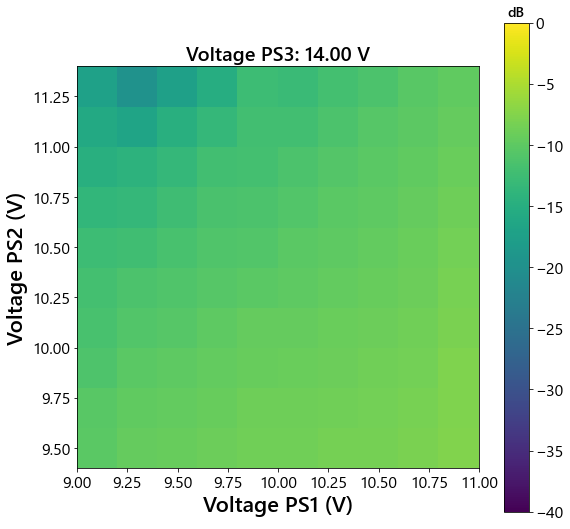

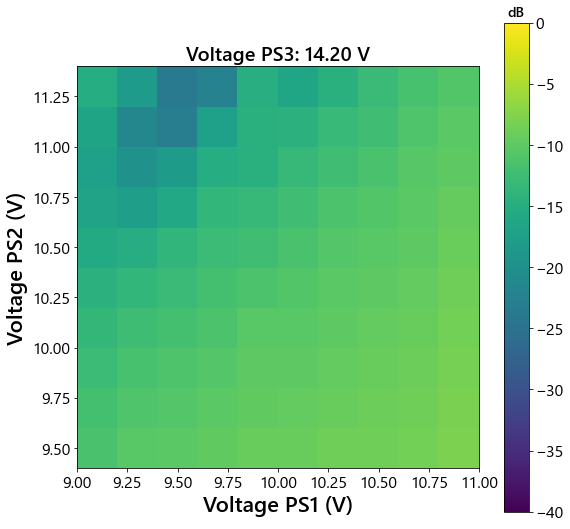

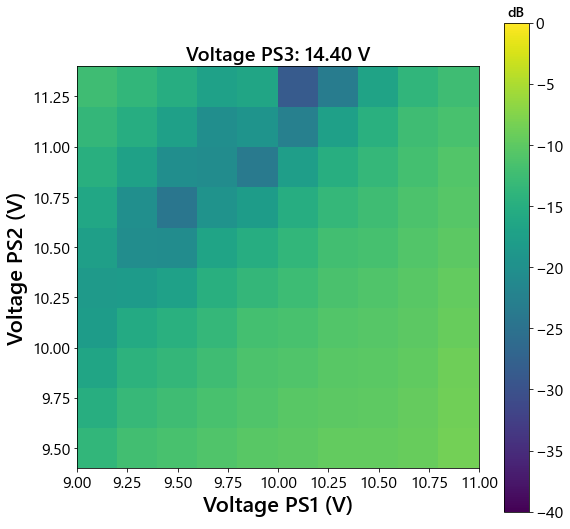

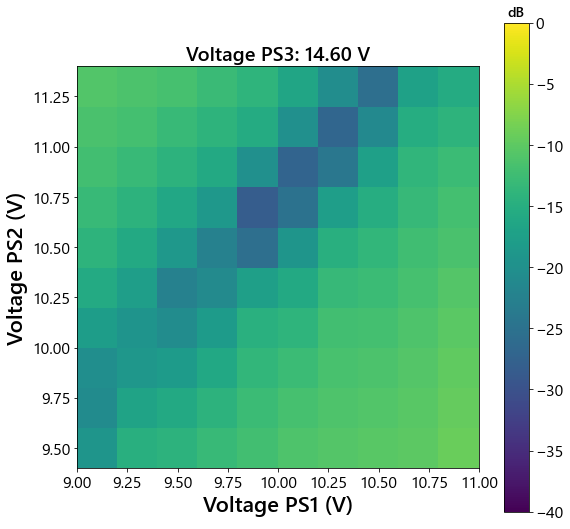

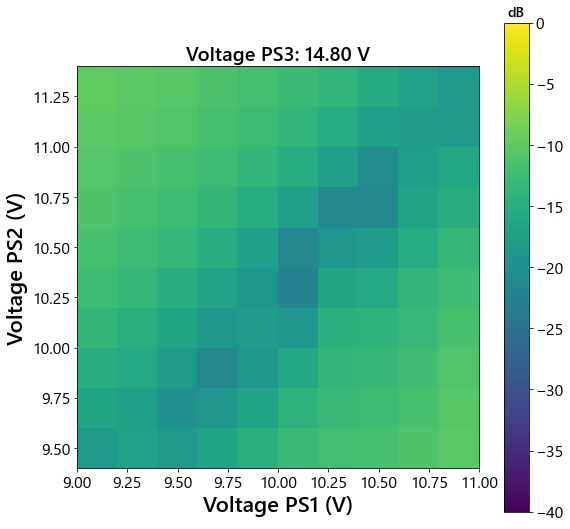

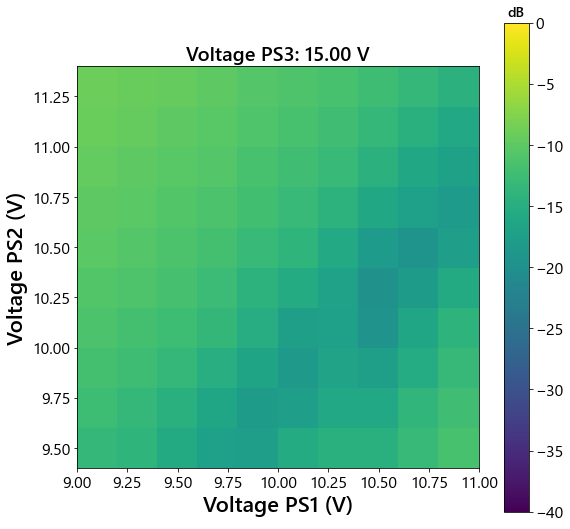

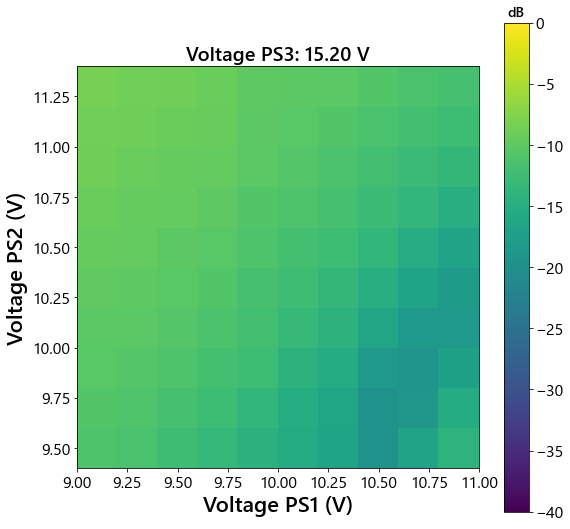

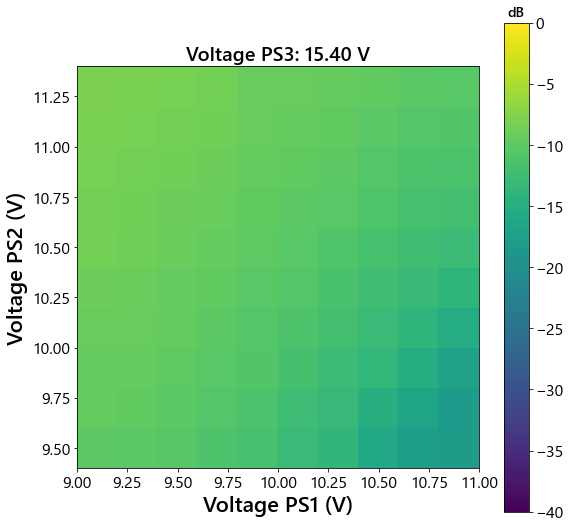

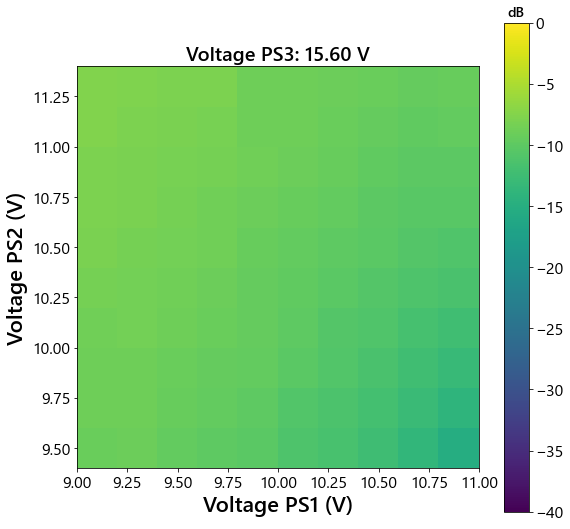

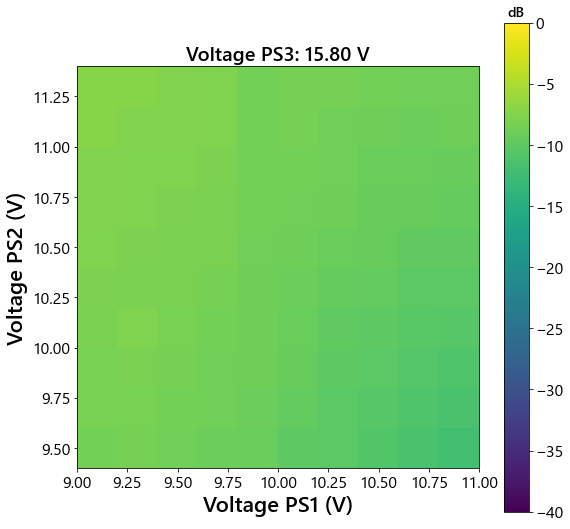

Null:  -30.366705548436848


In [ ]:
import matplotlib.colors as colors
import io, imageio

np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_outputs_low', outputs_low)
np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_outputs_high', outputs_high)
np.save(filename_root+'Device6a_I18_1x5Tri_voltageScan_voltages', voltages)
atten_low_dB, atten_high_dB = PIC.externalVOA_voltage_to_dB(4.3), PIC.externalVOA_voltage_to_dB(4.7)

scaling = 10**(abs(20-1)/10) * 10**(abs(atten_low_dB-atten_high_dB)/10)

norm_intensity = np.sum(outputs_high[:,:,:,1:4], axis=3) * scaling
null = 10*np.log10(outputs_low[:, :, :, 2]/norm_intensity)

frames = []
for i3, v3 in enumerate(voltages[2]):
    fig, ax = plt.subplots(1, 1, figsize=(9,9))
    
    cbar_norm = colors.Normalize(vmin=-40, vmax=0) 
    im = plt.pcolormesh(voltages[0], voltages[1], null[:, :, i3], norm=cbar_norm)
    cbar = fig.colorbar(im, ax=ax)
    cbar.ax.set_title('dB', fontsize=14)
    ax.set_aspect('equal')
    plt.xlabel('Voltage PS1 (V)')
    plt.ylabel('Voltage PS2 (V)')
    plt.title(f"Voltage PS3: {v3:.2f} V")

    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
    plt.show()
    plt.close(fig)
    buf.seek(0)
    
    frames.append(imageio.imread(buf))

imageio.mimsave(filename_root+"_null.gif", frames, fps=1, loop=0)

print("Null: ", np.min(null))

# Spectra

### Passive devices

In [2]:
save_dir = f'D:\\Active_PIC\\Data\\device_figs\\Passive\\'
# save_dir = f'D:\\Active_PIC\\device_figs\\Passive\\ReverseInjection\\'
data_dir_forwards = f'D:\\Active_PIC\\Data\\ForwardsInjectionSpectra\\20260312\\'
data_dir_reverse = f'D:\\Active_PIC\\Data\\ReverseInjection\\20260304\\'
wav_range = [1450, 1650]

Straight vs. S-bend

C:\Users\Pradip\AppData\Local\Temp\ipykernel_28280\2906856093.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_xticklabels(labels)
C:\Users\Pradip\AppData\Local\Temp\ipykernel_28280\2906856093.py:31: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(['']*len(ax[0].get_xticks()))
C:\Users\Pradip\AppData\Local\Temp\ipykernel_28280\2906856093.py:35: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax_top.set_xticklabels(['']*len(ax_top.get_xticks()))


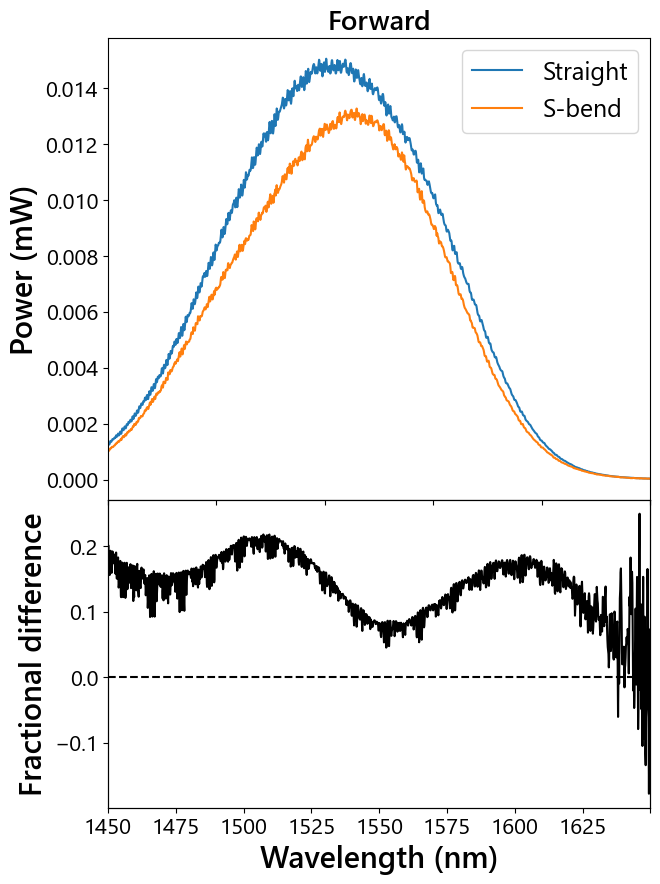

In [64]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    2, 1, figsize=(7, 10),
    gridspec_kw={'height_ratios': [3, 2]})
plt.subplots_adjust(hspace=0)  # remove vertical gap

# Forwards
filepath = f'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-07-25-Prototype-One-Active-1\\2-Straight_waveguide.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath, log=False)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
filepath = f'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-07-25-Prototype-One-Active-1\\3-Sbend.csv'
wav_2, flux_2 = PIC.read_ThorSpectra(filepath, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)

ax[0].plot(wav_1, flux_1, label='Straight')
ax[0].plot(wav_1, flux_2, label='S-bend')

ax[1].plot(wav_1, 1 - flux_2/flux_1, color='k')
ax[1].axhline(0, linestyle='dashed', color='k')

ax[0].set_xlim(wav_range[0], wav_range[1])
ax[1].set_xlim(wav_range[0], wav_range[1])
ticks = ax[1].get_xticks()
labels = [int(t) if t != 1650 else '' for t in ticks]
ax[1].set_xticklabels(labels)

# ax[0].set_ylim(-0.00001, 0.00027)
# ax[1].set_ylim(-0.2, 0.2)
ax[0].set_xticklabels(['']*len(ax[0].get_xticks()))

ax_top = ax[1].twiny()
ax_top.tick_params(axis='x', top=True, direction='in')
ax_top.set_xticklabels(['']*len(ax_top.get_xticks()))

ax[0].set_title('Forward')
ax[1].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Power (mW)')
ax[1].set_ylabel('Fractional difference')

ax[0].legend()
plt.savefig(f'{save_dir}Device0_Straight_Sbend_spectra.png',
            dpi=300, transparent=True, bbox_inches='tight')
plt.show()

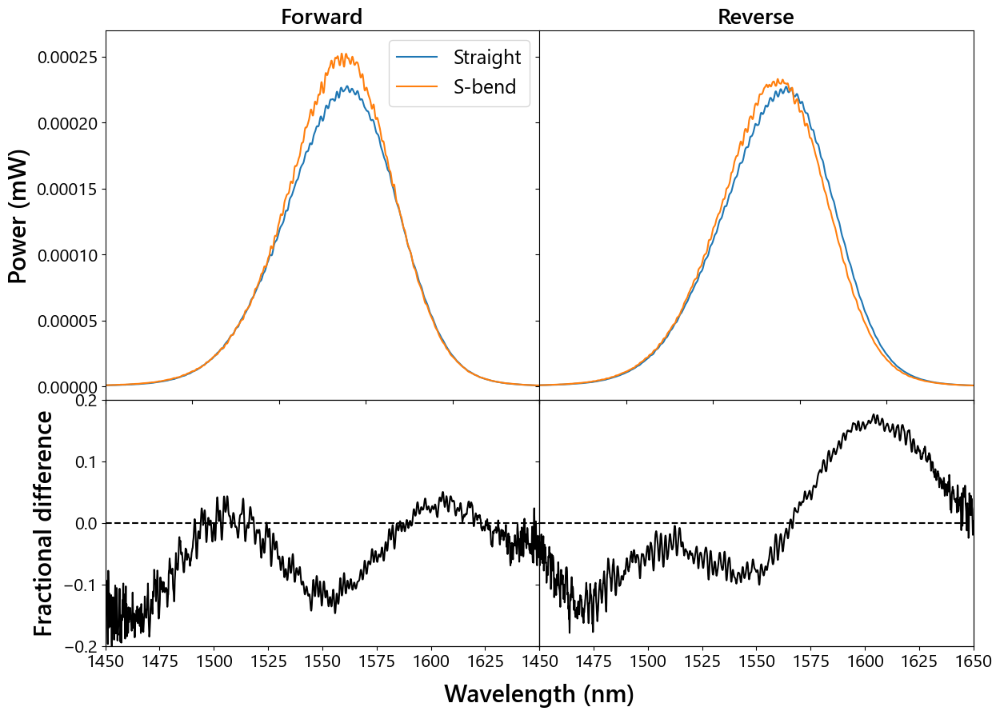

In [10]:
fig, ax = plt.subplots(
    2, 2, figsize=(14,10),
    gridspec_kw={'height_ratios': [3, 2]})
plt.subplots_adjust(hspace=0, wspace=0)  # remove vertical gap

# Forwards
filepath = f'{data_dir_forwards}Device0_StraightWaveguide_I2_O0_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath, log=False)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
filepath = f'{data_dir_forwards}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_2, flux_2 = PIC.read_ThorSpectra(filepath, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)

ax[0,0].plot(wav_1, flux_1, label='Straight')
ax[0,0].plot(wav_1, flux_2, label='S-bend')


ax[1,0].plot(wav_1, 1-flux_2/flux_1, color='k')
ax[1,0].axhline(0, linestyle='dashed', color='k')
for i in range(2):
    ax[i,0].set_xlim(wav_range[0], wav_range[1])
    ticks = ax[i, 0].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks] 
    ax[i,0].set_xticklabels(labels)

# Reverse
filepath = f'{data_dir_reverse}Device0_StraightWaveguide_I2_O0_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
filepath = f'{data_dir_reverse}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_2, flux_2 = PIC.read_ThorSpectra(filepath, log=True)
flux_2 = np.interp(wav_1, wav_2, flux_2)

ax[0,1].plot(wav_1, flux_1, label='Straight')
ax[0,1].plot(wav_1, flux_2, label='S-bend')

ax[1,1].plot(wav_1, 1-flux_2/flux_1, color='k')
ax[1,1].axhline(0, linestyle='dashed', color='k')
for i in range(2):
    ax[i,1].set_xlim(wav_range[0], wav_range[1])
    ax[i,1].set_yticklabels(['']*len(ax[i, 1].get_yticks()))

for i in range(2):
    ax[0,i].set_ylim(-0.00001, 0.00027)
    ax[1,i].set_ylim(-0.2, 0.2)
    ax[0,i].set_xticklabels(['']*len(ax[0, i].get_xticks()))
    ax_top = ax[1,i].twiny()
    ax_top.tick_params(axis='x', top=True, direction='in')
    ax_top.set_xticklabels(['']*len(ax_top.get_xticks()))

ax[0,0].set_title('Forward')
ax[0,1].set_title('Reverse')
ax[1,0].set_xlabel('Wavelength (nm)')
ax[1,0].xaxis.set_label_coords(1, -0.15)
ax[0,0].set_ylabel('Power (mW)')
ax[1,0].set_ylabel('Fractional difference')

ax[0,0].legend()
plt.savefig(f'{save_dir}Device0_Straight_Sbend_spectra.png',
            dpi=300, transparent=True, bbox_inches='tight')
plt.show()

Parallel waveguides

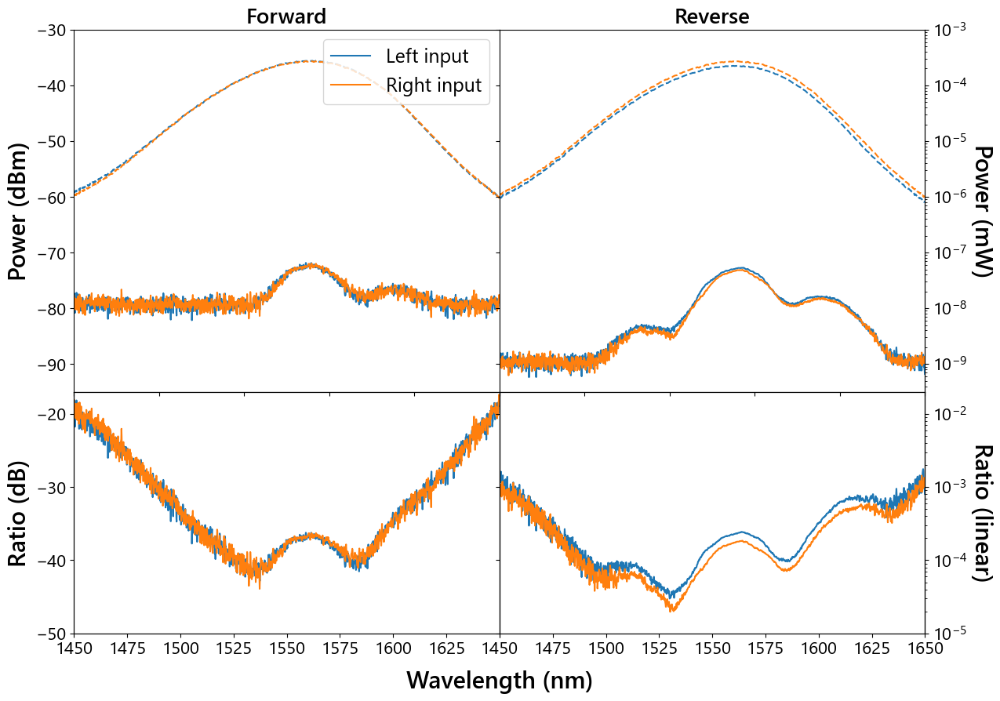

In [118]:
fig, ax = plt.subplots(
    2, 2, figsize=(14,10),
    gridspec_kw={'height_ratios': [3, 2]})
plt.subplots_adjust(hspace=0, wspace=0)  # remove vertical gap

# Forwards
device_name = 'Device1_ParallelWaveguides'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I4_O2_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I4_O3_spectrum.csv'
filepath_3 = f'{filepath_root}{device_name}_I5_O2_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I5_O3_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=False)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=False)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=False)
flux_4 = np.interp(wav_3, wav_4, flux_4)

ax[0,0].plot(wav_1, 10*np.log10(flux_1), linestyle='dashed', color='C0')
ax[0,0].plot(wav_1, 10*np.log10(flux_2), label='Left input', color='C0')
ax[0,0].plot(wav_3, 10*np.log10(flux_4), linestyle='dashed', color='C1')
ax[0,0].plot(wav_3, 10*np.log10(flux_3), label='Right input', color='C1')
ax[1,0].plot(wav_1, 10*np.log10(flux_2)-10*np.log10(flux_1), color='C0')
ax[1,0].plot(wav_3, 10*np.log10(flux_3)-10*np.log10(flux_4), color='C1')
for i in range(2):
    ax[i,0].set_xlim(wav_range[0], wav_range[1])
    ticks = ax[i, 0].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks] 
    ax[i,0].set_xticklabels(labels)
ax[0,0].set_title('Forward')


# Reverse
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I4_O2_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I4_O3_spectrum.csv'
filepath_3 = f'{filepath_root}{device_name}_I5_O2_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I5_O3_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=True)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=True)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=True)
flux_4 = np.interp(wav_3, wav_4, flux_4)

ax[0,1].plot(wav_1, 10*np.log10(flux_1), linestyle='dashed', color='C0')
ax[0,1].plot(wav_1, 10*np.log10(flux_2), label='Left input', color='C0')
ax[0,1].plot(wav_3, 10*np.log10(flux_4), linestyle='dashed', color='C1')
ax[0,1].plot(wav_3, 10*np.log10(flux_3), label='Right input', color='C1')
ax[1,1].plot(wav_1, 10*np.log10(flux_2)-10*np.log10(flux_1), color='C0')
ax[1,1].plot(wav_3, 10*np.log10(flux_3)-10*np.log10(flux_4), color='C1')
for i in range(2):
    ax[i,1].set_xlim(wav_range[0], wav_range[1])    
ax[0,1].set_title('Reverse')

# Log scale on right axis
def db_to_ratio(db):
    return 10**(db/10)

def ratio_to_db(r):
    return 10*np.log10(r)

for row in range(2):
    secax = ax[row,1].secondary_yaxis(
        'right',
        functions=(db_to_ratio, ratio_to_db)
    )
    secax.set_yscale('log')
    if row == 0:
        secax.set_ylabel('Power (mW)', rotation=270, labelpad=23)     
    if row == 1:
        secax.set_ylabel('Ratio (linear)', rotation=270, labelpad=23)            
### 

for i in range(2):
    ax[0,i].set_xticklabels(['']*len(ax[0, i].get_xticks()))
    ax[0,i].set_ylim(-95, -30)
    ax[1,i].set_ylim(-50, -17)    
    ax[i,1].set_yticklabels(['']*len(ax[0, i].get_yticks()))
    
    ax_top = ax[1,i].twiny()
    ax_top.tick_params(axis='x', top=True, direction='in')
    ax_top.set_xticklabels(['']*len(ax_top.get_xticks()))

ax[1,0].set_xlabel('Wavelength (nm)')
ax[1,0].xaxis.set_label_coords(1, -0.15)
ax[0,0].set_ylabel('Power (dBm)')
ax[1,0].set_ylabel('Ratio (dB)')
ax[0,0].legend(loc='upper right')
plt.savefig(f'{save_dir}Device1_ParallelWaveguides_spectra.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

Splitters

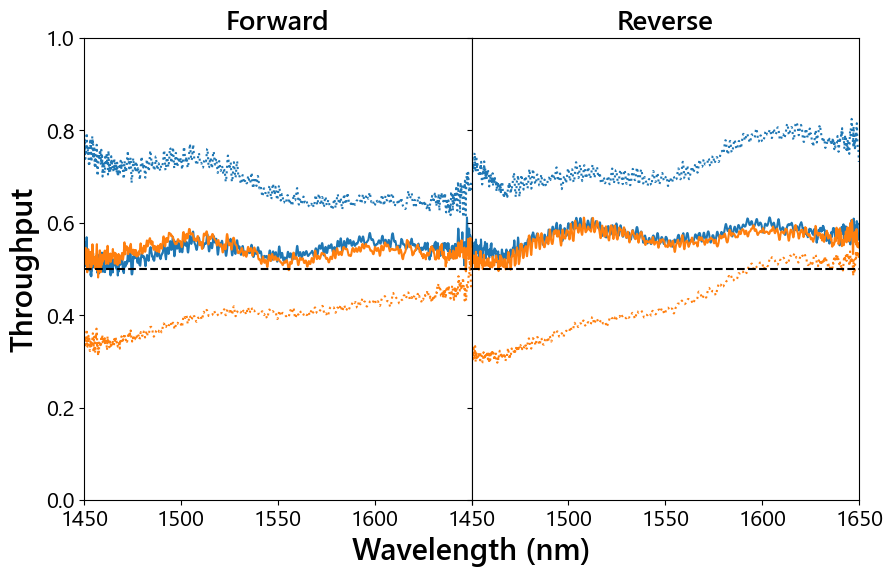

In [134]:
fig, ax = plt.subplots(
    1, 2, figsize=(10,6))
plt.subplots_adjust(hspace=0, wspace=0)  # remove vertical gap

# Forwards
filepath = f'{data_dir_forwards}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=False)
device_name = 'Device2a_Ysplitter'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I6_O4_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I6_O5_spectrum.csv'
device_name = 'Device2b_WINCsplitter'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I7_O6_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I7_O7_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=False)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=False)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=False)
flux_4 = np.interp(wav_3, wav_4, flux_4)

flux_norm = np.interp(wav_1, wav_sbend, flux_sbend)
# flux_norm = (flux_1+flux_2)
ax[0].plot(wav_1, flux_1/flux_norm, label='Left', color='C0')
ax[0].plot(wav_1, flux_2/flux_norm, label='Right', color='C1')
flux_norm = np.interp(wav_3, wav_sbend, flux_sbend)
# flux_norm = (flux_3+flux_4)
ax[0].plot(wav_3, flux_3/flux_norm, linestyle='dotted', color='C0')
ax[0].plot(wav_3, flux_4/flux_norm, linestyle='dotted', color='C1')
ax[0].axhline(0.5, color='k', linestyle='dashed')
ax[0].set_xlim(wav_range[0], wav_range[1])
ticks = ax[0].get_xticks()
labels = [int(t) if t != 1650 else '' for t in ticks] 
ax[0].set_xticklabels(labels)
ax[0].set_title('Forward')

# Reverse
filepath = f'{data_dir_reverse}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=True)
device_name = 'Device2a_Ysplitter'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I6_O4_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I6_O5_spectrum.csv'
device_name = 'Device2b_WINCsplitter'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I7_O6_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I7_O7_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=True)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=True)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=True)
flux_4 = np.interp(wav_3, wav_4, flux_4)

flux_norm = np.interp(wav_1, wav_sbend, flux_sbend)
# flux_norm = (flux_1+flux_2)
ax[1].plot(wav_1, flux_1/flux_norm, label='Left', color='C0')
ax[1].plot(wav_1, flux_2/flux_norm, label='Right', color='C1')
flux_norm = np.interp(wav_3, wav_sbend, flux_sbend)
# flux_norm = (flux_3+flux_4)
ax[1].plot(wav_3, flux_3/flux_norm, linestyle='dotted', color='C0')
ax[1].plot(wav_3, flux_4/flux_norm, linestyle='dotted', color='C1') 
ax[1].axhline(0.5, color='k', linestyle='dashed')
ax[1].set_xlim(wav_range[0], wav_range[1])
ticks = ax[1].get_yticks()
labels = ['' for t in ticks] 
ax[1].set_yticklabels(labels)
ax[1].set_title('Reverse')

for i in range(2):
    ax[i].set_ylim(0, 1)

ax[0].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Throughput')
ax[0].xaxis.set_label_coords(1, -0.08)
plt.savefig(f'{save_dir}Device2_Splitters_throughput.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
device_name = 'Device2a_Ysplitter'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I6_O4_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I6_O5_spectrum.csv'
wav_range = [1450, 1650]

wav_5, flux_5 = PIC.read_ThorSpectra(filepath_5, log=True)
wav_5, flux_5 = PIC.crop_spectrum(wav_5, flux_5, wav_range)
wav_6, flux_6 = PIC.read_ThorSpectra(filepath_6, log=True)
flux_6 = np.interp(wav_5, wav_6, flux_6)
flux_norm = (flux_5+flux_6)

np.save(f'{filepath_root}Device20_2x2MMI_I19_wav', wav_5)
np.save(f'{filepath_root}Device20_2x2MMI_I19_O37_splittingRatio', flux_5/flux_norm)
np.save(f'{filepath_root}Device20_2x2MMI_I19_O38_splittingRatio', flux_6/flux_norm)

C:\Users\Pradip\AppData\Local\Temp\ipykernel_7780\161959131.py:45: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(labels)
C:\Users\Pradip\AppData\Local\Temp\ipykernel_7780\161959131.py:79: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_yticklabels(labels)


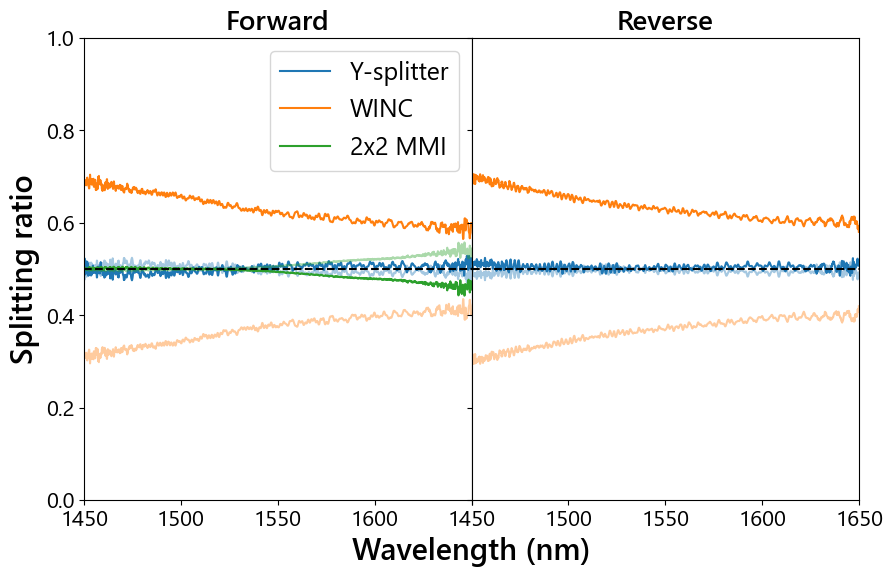

In [3]:
fig, ax = plt.subplots(
    1, 2, figsize=(10,6))
plt.subplots_adjust(hspace=0, wspace=0)  # remove vertical gap

# Forwards
filepath = f'{data_dir_forwards}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=False)
device_name = 'Device2a_Ysplitter'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I6_O4_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I6_O5_spectrum.csv'
device_name = 'Device2b_WINCsplitter'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I7_O6_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I7_O7_spectrum.csv'
filepath_root = f'D:\\Active_PIC\\Data\\2026-04-15\\'
filepath_5 = f'{filepath_root}Device20_2x2MMI_I19_O37_spectrum.csv'
filepath_6 = f'{filepath_root}Device20_2x2MMI_I19_O38_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=False)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=False)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=False)
flux_4 = np.interp(wav_3, wav_4, flux_4)
wav_5, flux_5 = PIC.read_ThorSpectra(filepath_5, log=True)
wav_5, flux_5 = PIC.crop_spectrum(wav_5, flux_5, wav_range)
wav_6, flux_6 = PIC.read_ThorSpectra(filepath_6, log=True)
flux_6 = np.interp(wav_5, wav_6, flux_6)

flux_norm = (flux_1+flux_2)
ax[0].plot(wav_1, flux_1/flux_norm, label='Y-splitter', color='C0')
ax[0].plot(wav_1, flux_2/flux_norm, color='C0', alpha=0.4)
flux_norm = (flux_3+flux_4)
ax[0].plot(wav_3, flux_3/flux_norm, label='WINC', color='C1')
ax[0].plot(wav_3, flux_4/flux_norm, color='C1', alpha=0.4)
flux_norm = (flux_5+flux_6)
ax[0].plot(wav_5, flux_5/flux_norm, label='2x2 MMI', color='C2')
ax[0].plot(wav_5, flux_6/flux_norm,  color='C2', alpha=0.4) 
ax[0].axhline(0.5, color='k', linestyle='dashed')
ax[0].set_xlim(wav_range[0], wav_range[1])
ticks = ax[0].get_xticks()
labels = [int(t) if t != 1650 else '' for t in ticks] 
ax[0].set_xticklabels(labels)
ax[0].set_title('Forward')
ax[0].legend()

# Reverse
filepath = f'{data_dir_reverse}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=True)
device_name = 'Device2a_Ysplitter'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I6_O4_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I6_O5_spectrum.csv'
device_name = 'Device2b_WINCsplitter'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I7_O6_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I7_O7_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=True)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=True)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=True)
flux_4 = np.interp(wav_3, wav_4, flux_4)

flux_norm = (flux_1+flux_2)
ax[1].plot(wav_1, flux_1/flux_norm, color='C0')
ax[1].plot(wav_1, flux_2/flux_norm, color='C0', alpha=0.4)
flux_norm = (flux_3+flux_4)
ax[1].plot(wav_3, flux_3/flux_norm, color='C1')
ax[1].plot(wav_3, flux_4/flux_norm,  color='C1', alpha=0.4) 
ax[1].axhline(0.5, color='k', linestyle='dashed')
ax[1].set_xlim(wav_range[0], wav_range[1])
ticks = ax[1].get_yticks()
labels = ['' for t in ticks] 
ax[1].set_yticklabels(labels)
ax[1].set_title('Reverse')

for i in range(2):
    ax[i].set_ylim(0, 1)

ax[0].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Splitting ratio')
ax[0].xaxis.set_label_coords(1, -0.08)
plt.savefig(f'{save_dir}Device2_Splitters_splittingRatio.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [8]:
save_dir

'D:\\Active_PIC\\Data\\device_figs\\Passive\\'

In [5]:
import numpy as np

flux_norm = (flux_5 + flux_6)
np.savetxt(f'{save_dir}Device20_2x2MMI_splittingRatio.csv',
           np.column_stack([wav_5, flux_5 / flux_norm, flux_6 / flux_norm]),
           delimiter=",", header="wavelength_nm,fraction_O37,fraction_O38", comments="")

76 deg vs. 53 deg crossing

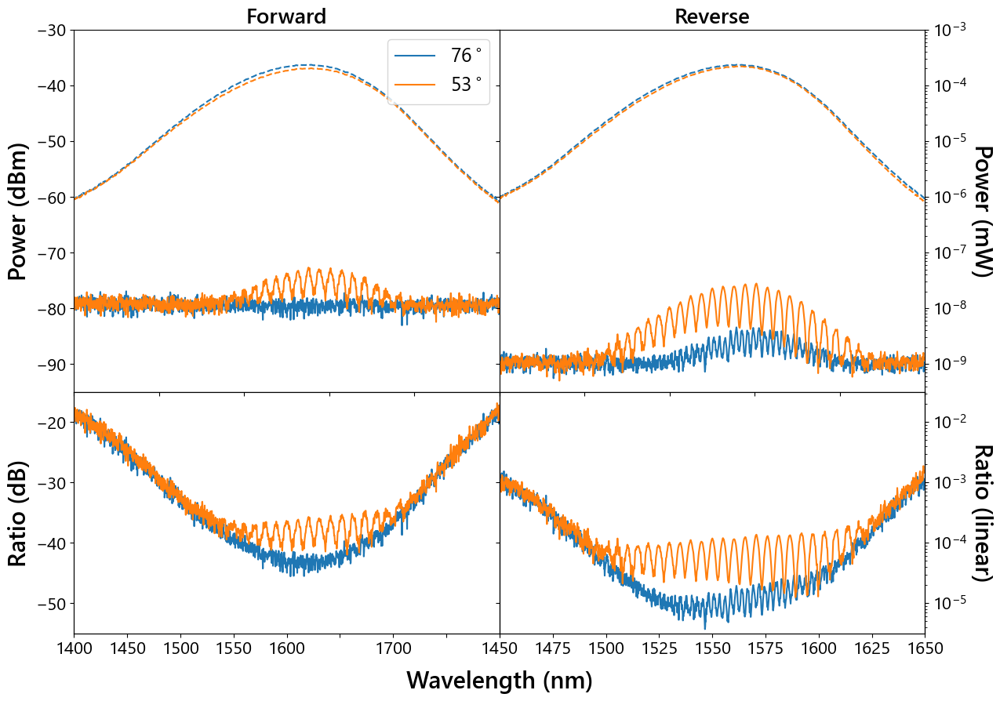

In [159]:
fig, ax = plt.subplots(
    2, 2, figsize=(14,10),
    gridspec_kw={'height_ratios': [3, 2]})
plt.subplots_adjust(hspace=0, wspace=0)  # remove vertical gap

# Forwards
device_name = 'Device3a_76degCrossing'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I8_O8_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I8_O9_spectrum.csv'
device_name = 'Device3b_53degCrossing'
filepath_root = f'{data_dir_forwards}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I9_O10_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I9_O11_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=False)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=True)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=False)
flux_4 = np.interp(wav_3, wav_4, flux_4)

ax[0,0].plot(wav_1, 10*np.log10(flux_1), label='76$^\circ$', color='C0')
ax[0,0].plot(wav_3, 10*np.log10(flux_3), label='53$^\circ$', color='C1')
ax[0,0].plot(wav_1, 10*np.log10(flux_2), linestyle='dashed', color='C0')
ax[0,0].plot(wav_3, 10*np.log10(flux_4), linestyle='dashed', color='C1')
ax[1,0].plot(wav_1, 10*np.log10(flux_1)-10*np.log10(flux_2), color='C0')
ax[1,0].plot(wav_3, 10*np.log10(flux_3)-10*np.log10(flux_4), color='C1')
for i in range(2):
    ticks = ax[i, 0].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks] 
    ax[i,0].set_xticklabels(labels)
ax[0,0].set_title('Forward')

# Reverse
device_name = 'Device3a_76degCrossing'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_1 = f'{filepath_root}{device_name}_I8_O8_spectrum.csv'
filepath_2 = f'{filepath_root}{device_name}_I8_O9_spectrum.csv'
device_name = 'Device3b_53degCrossing'
filepath_root = f'{data_dir_reverse}{device_name}\\'
filepath_3 = f'{filepath_root}{device_name}_I9_O10_spectrum.csv'
filepath_4 = f'{filepath_root}{device_name}_I9_O11_spectrum.csv'
wav_1, flux_1 = PIC.read_ThorSpectra(filepath_1, log=True)
wav_1, flux_1 = PIC.crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = PIC.read_ThorSpectra(filepath_2, log=True)
flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = PIC.read_ThorSpectra(filepath_3, log=True)
wav_3, flux_3 = PIC.crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = PIC.read_ThorSpectra(filepath_4, log=True)
flux_4 = np.interp(wav_3, wav_4, flux_4)

ax[0,1].plot(wav_1, 10*np.log10(flux_1), label='76$^\circ$', color='C0')
ax[0,1].plot(wav_3, 10*np.log10(flux_3), label='53$^\circ$', color='C1')
ax[0,1].plot(wav_1, 10*np.log10(flux_2), linestyle='dashed', color='C0')
ax[0,1].plot(wav_3, 10*np.log10(flux_4), linestyle='dashed', color='C1')
ax[1,1].plot(wav_1, 10*np.log10(flux_1)-10*np.log10(flux_2), color='C0')
ax[1,1].plot(wav_3, 10*np.log10(flux_3)-10*np.log10(flux_4), color='C1') 
ax[0,1].set_title('Reverse')

# Log scale on right axis
def db_to_ratio(db):
    return 10**(db/10)

def ratio_to_db(r):
    return 10*np.log10(r)

for row in range(2):
    secax = ax[row,1].secondary_yaxis(
        'right',
        functions=(db_to_ratio, ratio_to_db)
    )
    secax.set_yscale('log')
    if row == 0:
        secax.set_ylabel('Power (mW)', rotation=270, labelpad=23)     
    if row == 1:
        secax.set_ylabel('Ratio (linear)', rotation=270, labelpad=23)            
### 

for i in range(2):
    ax[0,i].set_xticklabels(['']*len(ax[0, i].get_xticks()))
    ax[i,0].set_xlim(wav_range[0], wav_range[1])  
    ax[i,1].set_xlim(wav_range[0], wav_range[1])  
    ax[0,i].set_ylim(-95, -30)
    ax[1,i].set_ylim(-55, -15)    
    ax[i,1].set_yticklabels(['']*len(ax[0, i].get_yticks()))
    
    ax_top = ax[1,i].twiny()
    ax_top.tick_params(axis='x', top=True, direction='in')
    ax_top.set_xticklabels(['']*len(ax_top.get_xticks()))

ax[1,0].set_xlabel('Wavelength (nm)')
ax[1,0].xaxis.set_label_coords(1, -0.15)
ax[0,0].set_ylabel('Power (dBm)')
ax[1,0].set_ylabel('Ratio (dB)')
ax[0,0].legend(loc='upper right')
plt.savefig(f'{save_dir}Device3_Crossing_spectra.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()


2x3 tricoupler

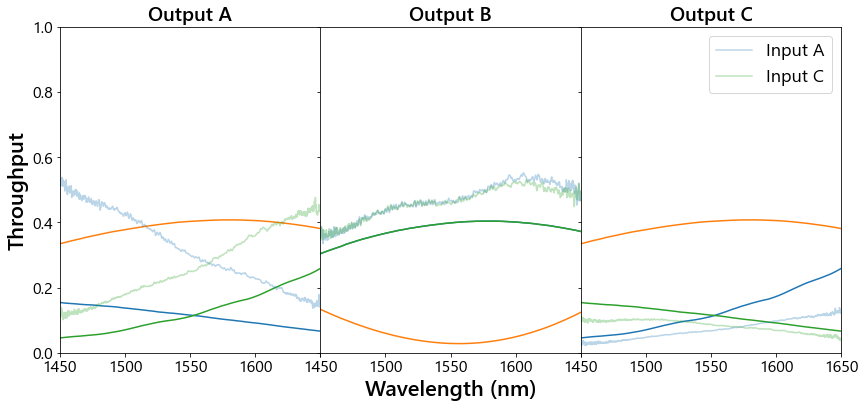

In [12]:
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device44_1x3Tri\\model\\'
wavs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_wavs.npy')
wavs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_wavs.npy')
wavs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_wavs.npy')
outputs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_outputs.npy')
outputs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_outputs.npy')
outputs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_outputs.npy')

model_wavs = [wavs_left, wavs_center, wavs_right]
model_inputs = [outputs_left, outputs_center, outputs_right]

filepath = f'{data_dir}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav, norm = read_ThorSpectra(filepath, log=True)

output_names = ['Output A', 'Output B', 'Output C']
inputs = [16, 17]
outputs = [23, 24, 25]
fig, ax = plt.subplots(1, len(outputs), figsize=(14,6), sharey=True)
for i, output in enumerate(outputs):
    filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[0]}_O{output}_spectrum.csv'
    wav_1, flux_1 = read_ThorSpectra(filepath, log=False)

    filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[1]}_O{output}_spectrum.csv'
    wav_2, flux_2 = read_ThorSpectra(filepath, log=False)

    flux_1_interp = np.interp(wav, wav_1, flux_1)
    flux_2_interp = np.interp(wav, wav_2, flux_2)
    # norm = flux_1_interp + flux_2_interp

    for o_ind in range(len(outputs)):
        ax[i].plot(model_wavs[i]*1000, model_inputs[i][o_ind], color=f'C{o_ind}')

    ax[i].plot(wav, flux_1_interp/norm, label='Input A', color='C0', alpha=0.3)
    ax[i].plot(wav, flux_2_interp/norm, label='Input C', color='C2', alpha=0.3)
    ax[i].set_xlim(wav_range[0], wav_range[1])
    ax[i].set_ylim(0, 1)
    ax[i].set_title(output_names[i])
    ax[i].tick_params(axis='x')
ax[1].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Throughput')
ax[2].legend()
plt.subplots_adjust(wspace=0)
for i in range(2):
    ticks = ax[i].get_xticks()
    labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
    ax[i].set_xticklabels(labels)

plt.show()

In [13]:
import imageio, io

output_names = ['Output A', 'Output B', 'Output C']
inputs = [16, 17]
outputs = [23, 24, 25]

filepath = f'{data_dir}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav, norm = read_ThorSpectra(filepath, log=True)

lengths = np.arange(250, 401, 25)
wav_range = [1450, 1650]
images = []
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device44_1x3Tri\\model\\'

for length in lengths:
    # --- your plotting code (unchanged) ---
    length_str = f"{length:.3f}".replace(".", "p")
    print(length_str)
    wavs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_CouplingLength{length_str}_wavs.npy')
    wavs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_CouplingLength{length_str}_wavs.npy')
    wavs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_CouplingLength{length_str}_wavs.npy')
    outputs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_CouplingLength{length_str}_outputs.npy')
    outputs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_CouplingLength{length_str}_outputs.npy')
    outputs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_CouplingLength{length_str}_outputs.npy')

    model_wavs = [wavs_left, wavs_center, wavs_right]
    model_inputs = [outputs_left, outputs_center, outputs_right]

    
    fig, ax = plt.subplots(1, len(outputs), figsize=(14,6), sharey=True)
    for i, output in enumerate(outputs):
        filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[0]}_O{output}_spectrum.csv'
        wav_1, flux_1 = read_ThorSpectra(filepath, log=False)

        filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[1]}_O{output}_spectrum.csv'
        wav_2, flux_2 = read_ThorSpectra(filepath, log=False)

        flux_1_interp = np.interp(wav, wav_1, flux_1)
        flux_2_interp = np.interp(wav, wav_2, flux_2)
        # norm = flux_1_interp + flux_2_interp

        for o_ind in range(len(outputs)):
            ax[i].plot(model_wavs[i]*1000, model_inputs[i][o_ind], color=f'C{o_ind}')

        ax[i].plot(wav, flux_1_interp/norm, label='Input A', color='C0', alpha=0.3)
        ax[i].plot(wav, flux_2_interp/norm, label='Input C', color='C2', alpha=0.3)
        ax[i].set_xlim(wav_range[0], wav_range[1])
        ax[i].set_ylim(0, 1)
        ax[i].set_title(output_names[i])
        ax[i].tick_params(axis='x')
    ax[1].set_xlabel('Wavelength (nm)')
    ax[0].set_ylabel('Throughput')
    ax[2].legend()
    plt.subplots_adjust(wspace=0)
    for i in range(2):
        ticks = ax[i].get_xticks()
        labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
        ax[i].set_xticklabels(labels)

    fig.suptitle(f'Coupling length: {length} microns', fontsize=30, fontweight='semibold',
                    y=0.99)

    # --- convert figure to image ---
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=300, bbox_inches='tight')
    buf.seek(0)

    images.append(imageio.imread(buf))
    buf.close()
    plt.close(fig)

# write GIF all at once (better quality)
imageio.mimsave(
    f'{save_dir}Device5b_2x3Tri_throughput.gif',
    images,
    duration=1
)

250p000
275p000
300p000
325p000
350p000
375p000
400p000


Passive chip tricoupler

In [61]:
sanny_left = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-04-25-Prototype-One-Passive\\10-DC-3x3-09-oil-in-out-2025-07-17\\In-1\\Out-1\\Ex0.txt'
sanny_center = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-04-25-Prototype-One-Passive\\10-DC-3x3-09-oil-in-out-2025-07-17\\In-1\\Out-2\\Ex0.txt'
sanny_right = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-04-25-Prototype-One-Passive\\10-DC-3x3-09-oil-in-out-2025-07-17\\In-1\\Out-3\\Ex0.txt'

sanny_left = np.genfromtxt(sanny_left, delimiter=',')
sanny_center = np.genfromtxt(sanny_center, delimiter=',')
sanny_right = np.genfromtxt(sanny_right, delimiter=',')

sanny_left[:,1] = 10**(sanny_left[:,1]/10)
sanny_center[:,1] = 10**(sanny_center[:,1]/10)
sanny_right[:,1] = 10**(sanny_right[:,1]/10)

sanny_norm = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2025-04-25-Prototype-One-Passive\\1-S-Bend-oil-in-out-2025-06-06\\Ex3_maximized_again.txt'
sanny_norm = np.genfromtxt(sanny_norm, delimiter=',')
wav_sanny = sanny_norm[:,0]
norm_sanny = 10**(sanny_norm[:,1]/10)
sanny_left = np.interp(wav_sanny, sanny_left[:,0], sanny_left[:,1])
sanny_center = np.interp(wav_sanny, sanny_center[:,0], sanny_center[:,1])
sanny_right = np.interp(wav_sanny, sanny_right[:,0], sanny_right[:,1])

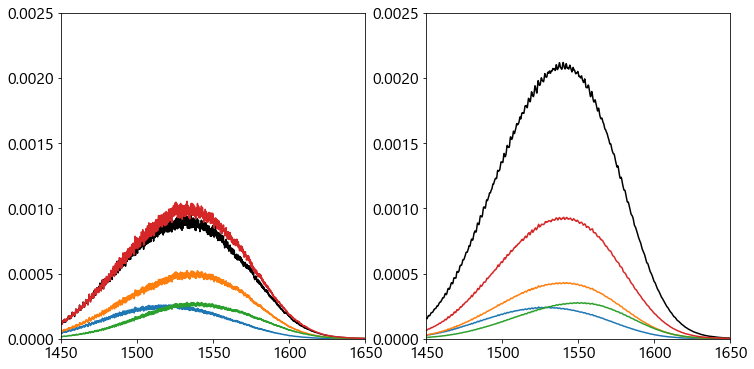

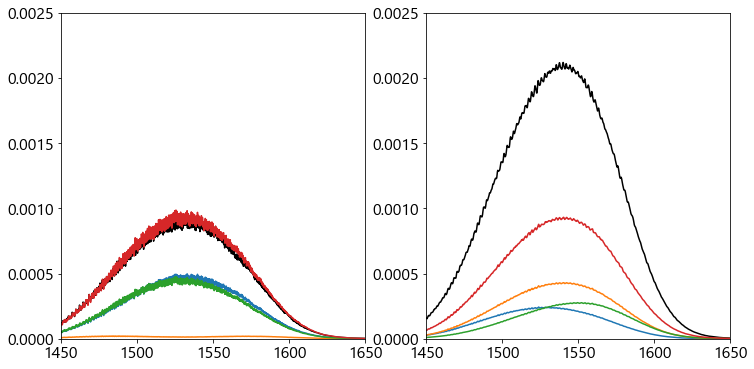

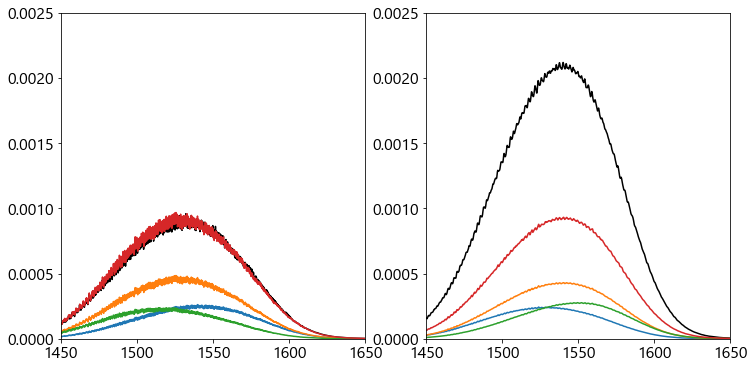

In [77]:
data_dir = 'D:\\Active_PIC\\PassiveChip\\20260411\\'
device_name = 'Device43_1x3Tri'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device43_1x3Tri\\model\\old\\'

inputs = [50, 51, 52]
outputs = [91, 92, 93]

filepath = f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv'
wav_ref, norm = read_ThorSpectra(filepath, log=True)

coupling_str = '' #'CouplingLength275p000_'
wavs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_{coupling_str}wavs.npy')
wavs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_{coupling_str}wavs.npy')
wavs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_{coupling_str}wavs.npy')
outputs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_{coupling_str}outputs.npy')
outputs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_{coupling_str}outputs.npy')
outputs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_{coupling_str}outputs.npy')
model_wavs = [wavs_left, wavs_center, wavs_right]
model_inputs = [outputs_left, outputs_center, outputs_right]

wav_range = [1450, 1650]
# fig, ax = plt.subplots(1, 3, figsize=(14,6), sharey=True)
# plt.subplots_adjust(wspace=0)
for i_ind, i in enumerate(inputs):
    wavs, fluxes = [], []
    for o_ind, o in enumerate(outputs):
        filepath = f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv'
        wav, flux = read_ThorSpectra(filepath, log=True)
        # if o_ind == 0:
        #     wav_ref = np.copy(wav)
        fluxes.append(np.interp(wav_ref, wav, flux))
    fluxes = np.array(fluxes).T

    fig, ax = plt.subplots(1, 2, figsize=(12,6))
    ax[0].plot(wav_ref, norm, color='k')
    for o_ind in range(len(outputs)):
        ax[0].plot(wav_ref, fluxes[:,o_ind], color=f'C{o_ind}')
    ax[0].plot(wav_ref, np.sum(fluxes,axis=1), color=f'C3')
    ax[1].plot(wav_sanny, norm_sanny, color='k')
    ax[1].plot(wav_sanny, sanny_left, color='C0')
    ax[1].plot(wav_sanny, sanny_center, color='C1')
    ax[1].plot(wav_sanny, sanny_right, color='C2')
    ax[1].plot(wav_sanny, sanny_left + sanny_center + sanny_right, color='C3')
    for i in range(2):
        ax[i].set_xlim(1450, 1650)
        ax[i].set_ylim(0, 0.0025)
    plt.show()
    # norm = np.sum(fluxes, axis=1, keepdims=True).T.flatten()
#     for o_ind in range(len(outputs)):
#         ax[i_ind].plot(model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind], linestyle='dashed', label=f'Output {chr(ord("A") + o_ind)}')    
#         ax[i_ind].plot(wav_ref, fluxes[:,o_ind]/norm, color=f'C{o_ind}', alpha=0.3)   
#     ax[i_ind].set_xlim(wav_range[0], wav_range[1])
#     ax[i_ind].set_ylim(0, 1)
#     ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
# for i in range(2):
#     ticks = ax[i].get_xticks()
#     labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
#     ax[i].set_xticklabels(labels)

# ax[0].plot(wav_sanny, sanny_left/norm_sanny, color=f'C0') 
# ax[0].plot(wav_sanny, sanny_center/norm_sanny, color=f'C1') 
# ax[0].plot(wav_sanny, sanny_right/norm_sanny, color=f'C2') 

# ax[1].set_xlabel('Wavelength (nm)')
# ax[0].set_ylabel('Normalized throughput')
# plt.legend()
# plt.show()

In [53]:
np.array(passive_spec).T

array([[5.99991882e+02, 1.62418598e-06, 2.81613600e-06, 1.19793808e-06],
       [6.00009522e+02, 1.96187614e-06, 4.00475956e-06, 1.35729073e-06],
       [6.00027161e+02, 1.99624224e-06, 4.03194787e-06, 1.08103701e-06],
       ...,
       [1.69977112e+03, 1.30372824e-06, 1.87034092e-06, 1.28422705e-06],
       [1.69991260e+03, 1.68688507e-06, 2.00326831e-06, 1.52727900e-06],
       [1.70005420e+03, 1.63070016e-06, 2.49964680e-06, 1.54275745e-06]])

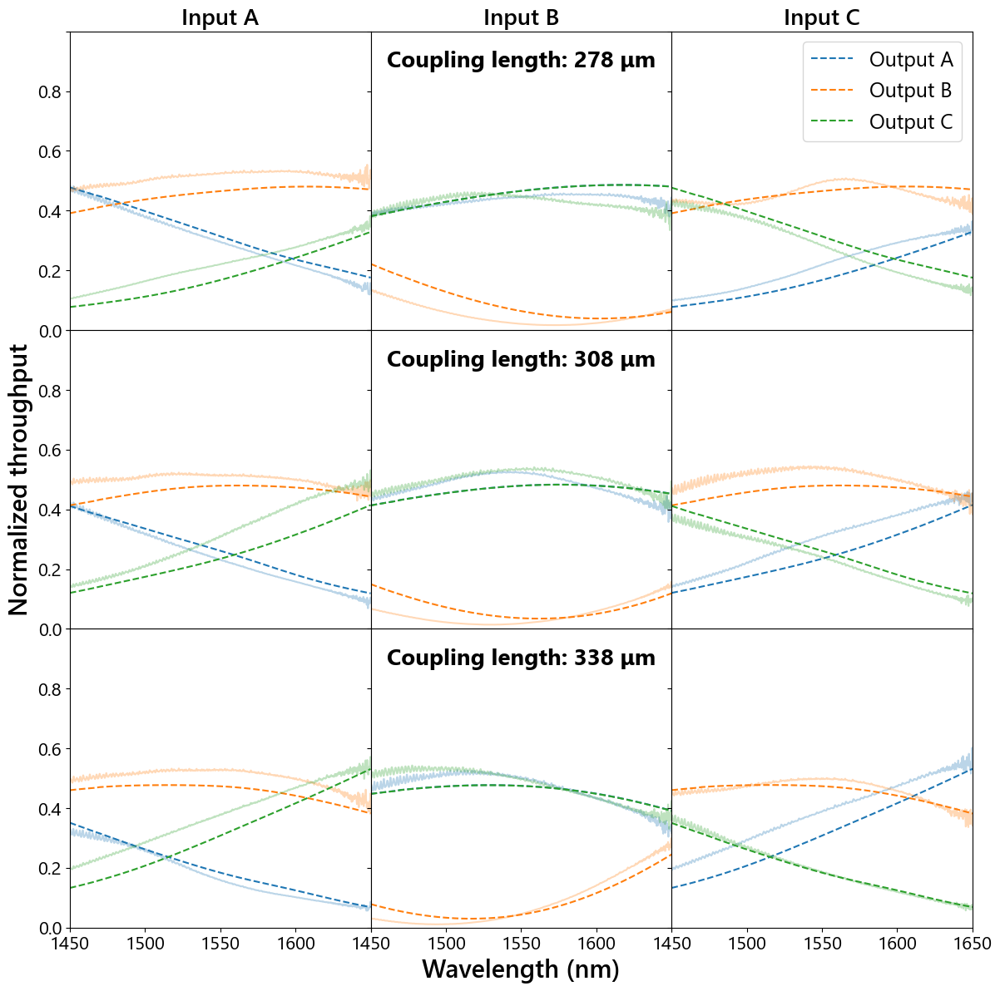

In [ ]:
data_dir = 'D:\\Active_PIC\\2026-04-14\\'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device43_1x3Tri\\model\\old\\'

inputs_arr = [[47, 48, 49], [50, 51, 52], [53, 54, 55]]
outputs_arr = [[88, 89, 90], [91, 92, 93], [94, 95, 96]]
coupling_strs = ['CouplingLength275p000_', '', 'CouplingLength350p000_']
device_names = ['Device42_1x3Tri', 'Device43_1x3Tri', 'Device44_1x3Tri']
coupling_lengths = [278, 308, 338]

wav_ref, norm = PIC.read_ThorSpectra(f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv', log=True)

wav_range = [1450, 1650]
fig, ax = plt.subplots(3, 3, figsize=(14,14))
plt.subplots_adjust(wspace=0, hspace=0)

for row, (device_name, coupling_str, inputs, outputs) in enumerate(zip(device_names, coupling_strs, inputs_arr, outputs_arr)):
    model_wavs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}wavs.npy') for s in ['Left','Center','Right']]
    model_inputs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}outputs.npy') for s in ['Left','Center','Right']]

    for i_ind, i in enumerate(inputs):
        fluxes = []
        for o in outputs:
            try:
                wav, flux = PIC.read_ThorSpectra(f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv', log=True)
            except:
                wav, flux = np.nan*np.ones_like(wav_ref), np.nan*np.ones_like(wav_ref)
            fluxes.append(np.interp(wav_ref, wav, flux))
        fluxes = np.array(fluxes).T

        passive_spec = [wav_ref]
        for o_ind in range(len(outputs)):
            ax[row,i_ind].plot(model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind], linestyle='dashed', label=f'Output {chr(ord("A")+o_ind)}')
            ax[row,i_ind].plot(wav_ref, fluxes[:,o_ind]/norm, color=f'C{o_ind}', alpha=0.3)
            passive_spec.append(fluxes[:,o_ind])
        np.savetxt(f'{data_dir}Tricoupler_couplingLength{coupling_lengths[row]}_input{chr(65+i_ind)}.txt', 
                   np.array(passive_spec).T, header='wav,outputA,outputB,outputC')
            

        ax[row,i_ind].set(xlim=wav_range, ylim=(0,1))

for row in range(2):
    for col in range(3):
        ax[row,col].tick_params(axis='x', bottom=True, labelbottom=False)

for col in range(3):
    ticks = ax[2,col].get_xticks()
    labels = [int(t) if (col<2 and t!=1650) else ('' if col<2 else int(t)) for t in ticks]
    ax[2,col].set_xticklabels(labels)

for row in range(3):
    ticks = ax[row,0].get_yticks()
    ax[row,0].set_yticklabels([round(t,1) if t!=1.0 else '' for t in ticks])

for col in [1,2]:
    for row in range(3):
        ax[row,col].tick_params(labelleft=False)

ax[0,2].legend()
ax[2,1].set_xlabel('Wavelength (nm)')
ax[1,0].set_ylabel('Normalized throughput')

for i in range(3):
    ax[0,i].set_title(f'Input {chr(ord("A")+i)}')

for row in range(3):
    ax[row,1].text(1550, 0.9, f'Coupling length: {coupling_lengths[row]} μm', ha='center', va='center', fontsize=20, fontweight='bold')

# plt.savefig(f'{save_dir}Device42_Device43_Device44_1x3Tri_throughput.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

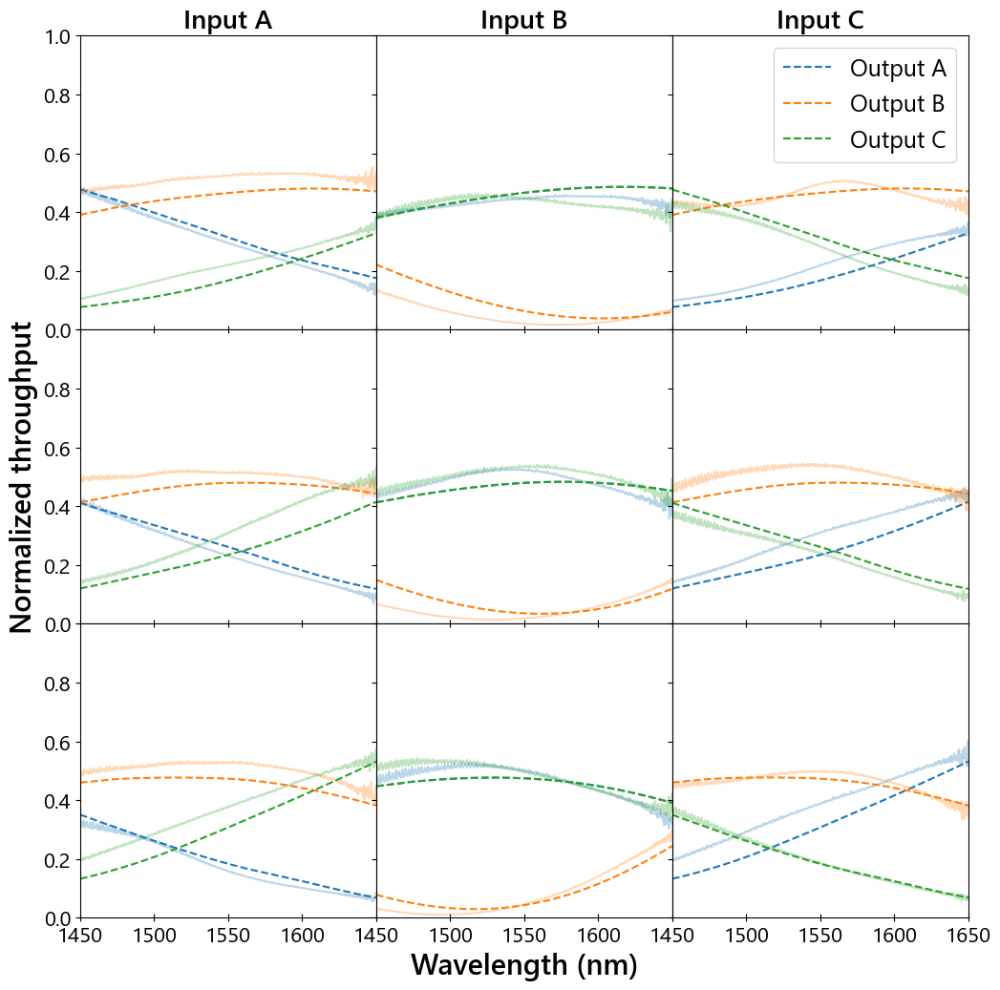

In [264]:
data_dir = 'D:\\Active_PIC\\2026-04-14\\'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device43_1x3Tri\\model\\old\\'

inputs_arr = [[47, 48, 49], [50, 51, 52], [53, 54, 55]]
outputs_arr = [[88, 89, 90], [91, 92, 93], [94, 95, 96]]
coupling_strs = ['CouplingLength275p000_', '', 'CouplingLength350p000_']
device_names = ['Device42_1x3Tri', 'Device43_1x3Tri', 'Device44_1x3Tri']
coupling_lengths = [278, 308, 338]

wav_ref, norm = PIC.read_ThorSpectra(f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv', log=True)

wav_range = [1450, 1650]
fig, ax = plt.subplots(3, 3, figsize=(12,12))
plt.subplots_adjust(wspace=0, hspace=0)

for row, (device_name, coupling_str, inputs, outputs) in enumerate(zip(device_names, coupling_strs, inputs_arr, outputs_arr)):
    model_wavs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}wavs.npy') for s in ['Left','Center','Right']]
    model_inputs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}outputs.npy') for s in ['Left','Center','Right']]

    for i_ind, i in enumerate(inputs):
        fluxes = []
        for o in outputs:
            try:
                wav, flux = PIC.read_ThorSpectra(f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv', log=True)
            except:
                wav, flux = np.nan*np.ones_like(wav_ref), np.nan*np.ones_like(wav_ref)
            fluxes.append(np.interp(wav_ref, wav, flux))
        fluxes = np.array(fluxes).T

        for o_ind in range(len(outputs)):
            ax[row,i_ind].plot(model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind], linestyle='dashed', label=f'Output {chr(ord("A")+o_ind)}')
            ax[row,i_ind].plot(wav_ref, fluxes[:,o_ind]/norm, color=f'C{o_ind}', alpha=0.3)

        ax[row,i_ind].set(xlim=wav_range, ylim=(0,1))

ax[0,2].legend()
ax[2,1].set_xlabel('Wavelength (nm)')
ax[1,0].set_ylabel('Normalized throughput')
ax[0,0].set_title('Input A')
ax[0,1].set_title('Input B')
ax[0,2].set_title('Input C')


for row in range(2):
    ticks = ax[row+1,0].get_yticks()
    ax[row+1,0].set_yticklabels([round(t,1) if t != 1.0 else '' for t in ticks])
    ticks = ax[2,row].get_xticks()
    ax[2,row].set_xticklabels([int(t) if t != 1650 else '' for t in ticks])

for row in [1,2]:
    for col in range(3):
        ax[row,col].tick_params(axis='x', top=True, labeltop=False, 
                                direction='inout', length=6)

for row in range(2):
    for col in range(3):
        ax[row,col].tick_params(bottom=False, labelbottom=False)

for row in range(3):
    for col in range(1,3):
        ax[row,col].tick_params(labelleft=False)


plt.savefig(f'{save_dir}Device42_Device43_Device44_1x3Tri_throughput.png',
            dpi=300, transparent=True, bbox_inches='tight')
plt.show()

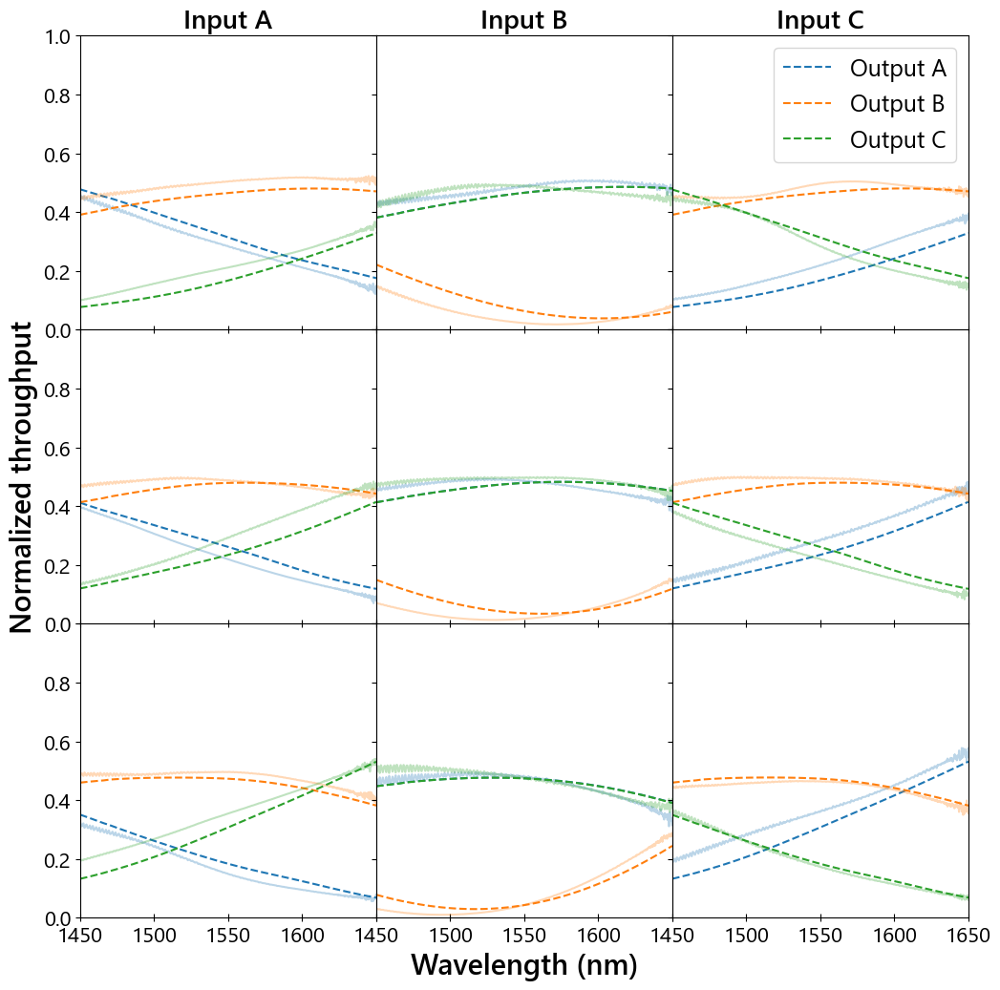

In [267]:
data_dir = 'D:\\Active_PIC\\2026-04-14\\'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device43_1x3Tri\\model\\old\\'

inputs_arr = [[47, 48, 49], [50, 51, 52], [53, 54, 55]]
outputs_arr = [[88, 89, 90], [91, 92, 93], [94, 95, 96]]
coupling_strs = ['CouplingLength275p000_', '', 'CouplingLength350p000_']
device_names = ['Device42_1x3Tri', 'Device43_1x3Tri', 'Device44_1x3Tri']
coupling_lengths = [278, 308, 338]

wav_ref, norm = PIC.read_ThorSpectra(f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv', log=True)

wav_range = [1450, 1650]
fig, ax = plt.subplots(3, 3, figsize=(12,12))
plt.subplots_adjust(wspace=0, hspace=0)

for row, (device_name, coupling_str, inputs, outputs) in enumerate(zip(device_names, coupling_strs, inputs_arr, outputs_arr)):
    model_wavs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}wavs.npy') for s in ['Left','Center','Right']]
    model_inputs = [np.load(f'{model_dir}Tricoupler_FiberOneInput_{s}_scan_Wav_{coupling_str}outputs.npy') for s in ['Left','Center','Right']]

    for i_ind, i in enumerate(inputs):
        fluxes = []
        for o in outputs:
            try:
                wav, flux = PIC.read_ThorSpectra(f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv', log=True)
            except:
                wav, flux = np.nan*np.ones_like(wav_ref), np.nan*np.ones_like(wav_ref)
            fluxes.append(np.interp(wav_ref, wav, flux))
        fluxes = np.array(fluxes).T

        norm = np.sum(fluxes, axis=1)
        for o_ind in range(len(outputs)):
            ax[row,i_ind].plot(model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind], linestyle='dashed', label=f'Output {chr(ord("A")+o_ind)}')
            ax[row,i_ind].plot(wav_ref, fluxes[:,o_ind]/norm, color=f'C{o_ind}', alpha=0.3)

        ax[row,i_ind].set(xlim=wav_range, ylim=(0,1))

ax[0,2].legend()
ax[2,1].set_xlabel('Wavelength (nm)')
ax[1,0].set_ylabel('Normalized throughput')
ax[0,0].set_title('Input A')
ax[0,1].set_title('Input B')
ax[0,2].set_title('Input C')


for row in range(2):
    ticks = ax[row+1,0].get_yticks()
    ax[row+1,0].set_yticklabels([round(t,1) if t != 1.0 else '' for t in ticks])
    ticks = ax[2,row].get_xticks()
    ax[2,row].set_xticklabels([int(t) if t != 1650 else '' for t in ticks])

for row in [1,2]:
    for col in range(3):
        ax[row,col].tick_params(axis='x', top=True, labeltop=False, 
                                direction='inout', length=6)

for row in range(2):
    for col in range(3):
        ax[row,col].tick_params(bottom=False, labelbottom=False)

for row in range(3):
    for col in range(1,3):
        ax[row,col].tick_params(labelleft=False)


plt.savefig(f'{save_dir}Device42_Device43_Device44_1x3Tri_splittingRatio.png',
            dpi=300, transparent=True, bbox_inches='tight')
plt.show()

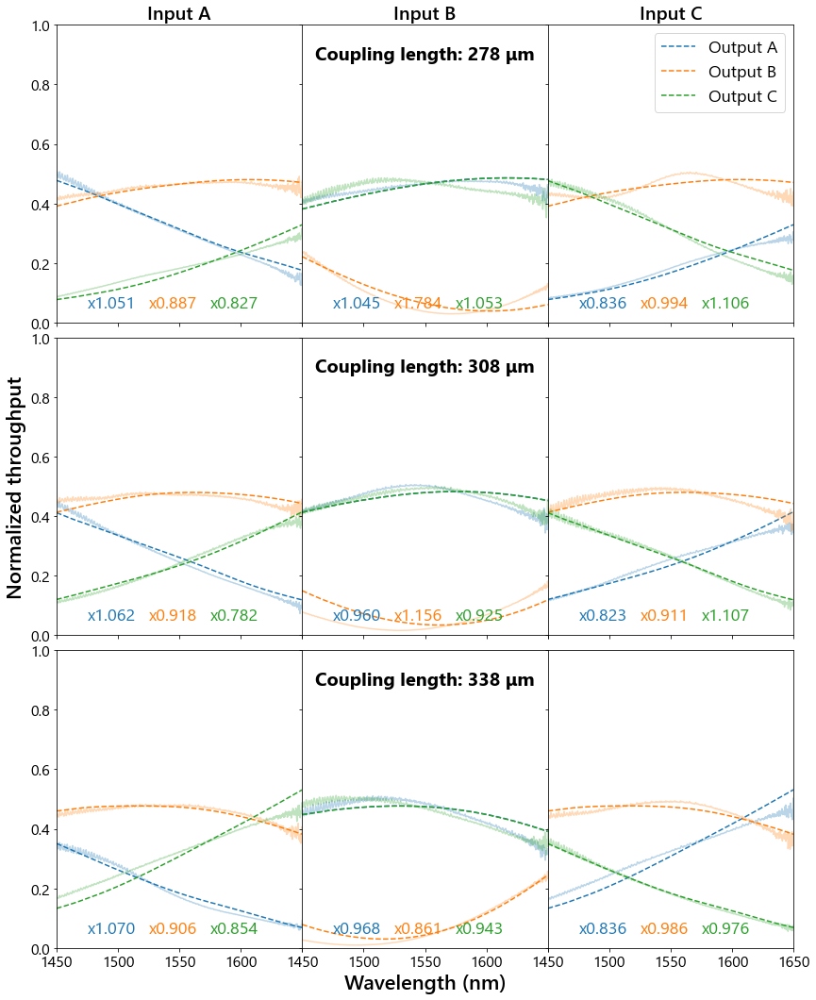

In [23]:
data_dir = 'D:\\Active_PIC\\2026-04-14\\'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device43_1x3Tri\\model\\old\\'

inputs_arr = [[47, 48, 49], [50, 51, 52], [53, 54, 55]]
outputs_arr = [[88, 89, 90], [91, 92, 93], [94, 95, 96]]
coupling_strs = ['CouplingLength275p000_', '', 'CouplingLength350p000_']
device_names = ['Device42_1x3Tri', 'Device43_1x3Tri', 'Device44_1x3Tri']
coupling_lengths = [278, 308, 338]

filepath = f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv'
wav_ref, norm = PIC.read_ThorSpectra(filepath, log=True)

wav_range = [1450, 1650]
norm = norm[(wav_ref > 1450)*(wav_ref < 1650)]
wav_ref = wav_ref[(wav_ref > 1450)*(wav_ref < 1650)]

fig, ax = plt.subplots(3, 3, figsize=(14,18), sharey=True)
plt.subplots_adjust(wspace=0, hspace=0.05)

for row in range(3):
    device_name = device_names[row]
    coupling_str = coupling_strs[row]
    inputs = inputs_arr[row]
    outputs = outputs_arr[row]

    wavs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_{coupling_str}wavs.npy')
    wavs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_{coupling_str}wavs.npy')
    wavs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_{coupling_str}wavs.npy')
    outputs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_{coupling_str}outputs.npy')
    outputs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_{coupling_str}outputs.npy')
    outputs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_{coupling_str}outputs.npy')
    model_wavs = [wavs_left, wavs_center, wavs_right]
    model_inputs = [outputs_left, outputs_center, outputs_right]

    for i_ind, i in enumerate(inputs):
        wavs, fluxes = [], []
        for o_ind, o in enumerate(outputs):
            try:
                filepath = f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv'
                wav, flux = PIC.read_ThorSpectra(filepath, log=True)
            except:
                wav, flux = np.nan*np.ones_like(wav_ref), np.nan*np.ones_like(wav_ref)
            # if o_ind == 0:
            #     wav_ref = np.copy(wav)
            fluxes.append(np.interp(wav_ref, wav, flux))
        fluxes = np.array(fluxes).T
        # norm = np.sum(fluxes, axis=1, keepdims=True).T.flatten()
        for o_ind in range(len(outputs)):
            model = np.interp(wav_ref, model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind])
            data = fluxes[:,o_ind]/norm
            scale = np.sum(data**2) / np.sum(data * model)
            ax[row, i_ind].plot(wav_ref, model, linestyle='dashed', label=f'Output {chr(ord("A") + o_ind)}')    
            ax[row, i_ind].plot(wav_ref, data/scale, color=f'C{o_ind}', alpha=0.3)   
            ax[row, i_ind].text(1475+50*o_ind, 0.05, f'x{1/scale:.3f}', color=f'C{o_ind}', fontsize=18)
        ax[row, i_ind].set_xlim(wav_range[0], wav_range[1])
        ax[row, i_ind].set_ylim(0, 1)
    for i in range(3):
        ticks = ax[row, i].get_xticks()
        if row < 2:
            labels = ['' for t in ticks] 
        else:
            if i < 2:
                labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
            else:
                labels = [int(t) for t in ticks] 
        ax[row, i].set_xticklabels(labels)
    # ax[row,1].set_title(f'Coupling length: {coupling_lengths[row]} microns')
# ax[1, 0].plot(wav_sanny, sanny_left/norm_sanny * 2.5, color=f'C0') 
# ax[1, 0].plot(wav_sanny, sanny_center/norm_sanny * 2.5, color=f'C1') 
# ax[1, 0].plot(wav_sanny, sanny_right/norm_sanny * 2.5, color=f'C2') 
ax[0, 2].legend()
ax[2, 1].set_xlabel('Wavelength (nm)')
ax[1, 0].set_ylabel('Normalized throughput')
[ax[0, i_ind].set_title(f'Input {chr(ord("A") + i_ind)}') for i_ind in range(3)]
for row in range(3):
    ax[row, 1].text(1550, 0.9, f'Coupling length: {coupling_lengths[row]} μm',
             ha='center', va='center', fontsize=20, fontweight='bold')
    
plt.show()

250p000


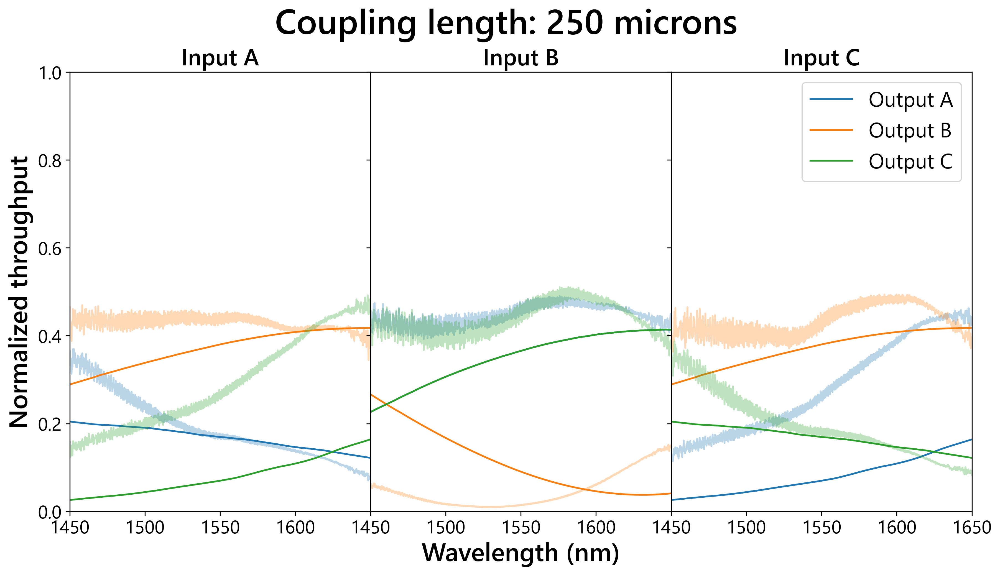

275p000


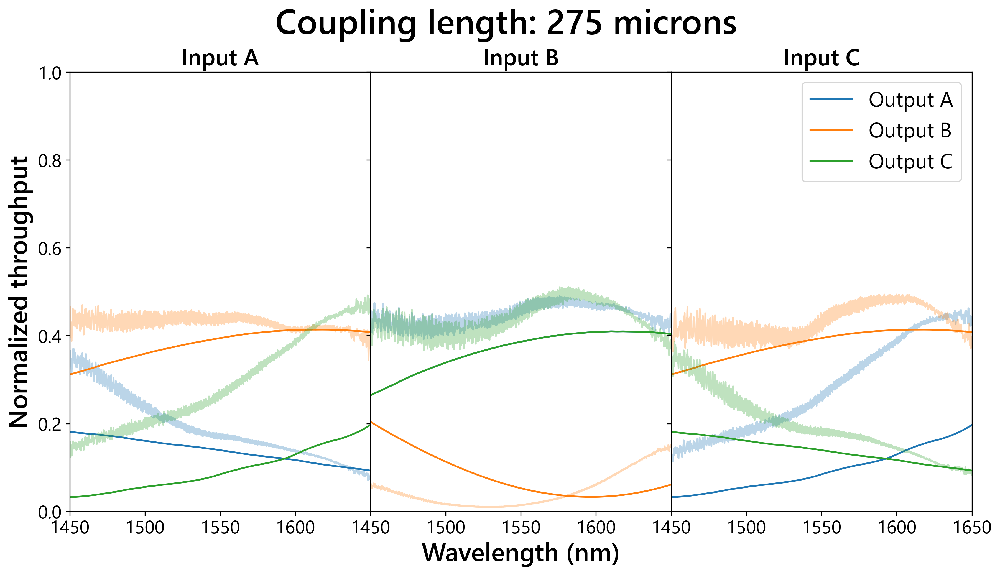

300p000


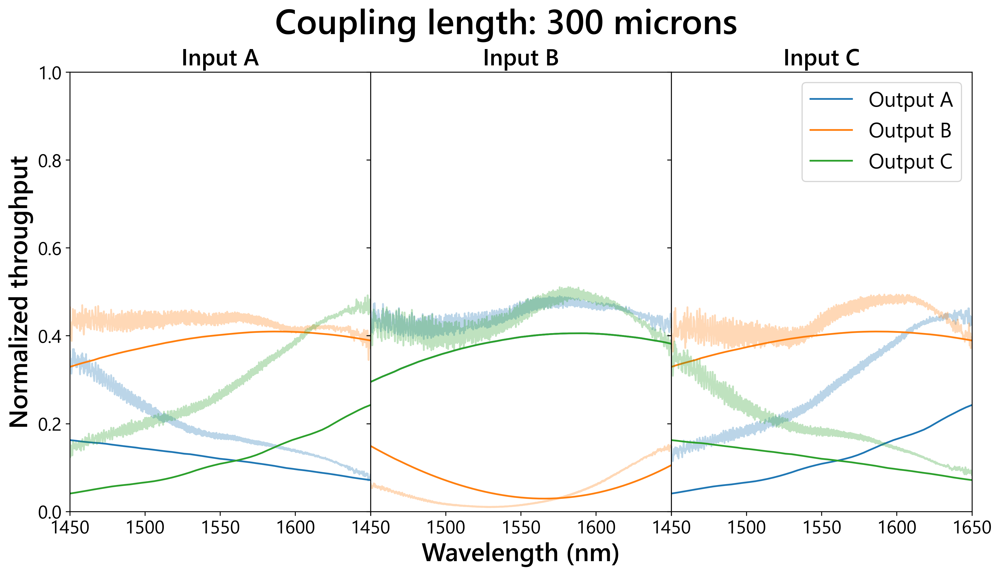

325p000


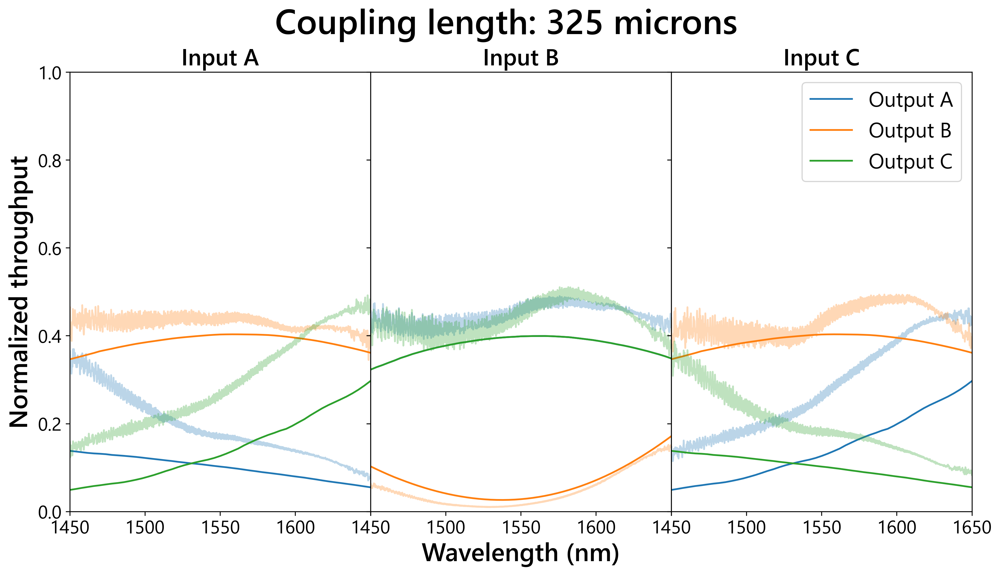

350p000


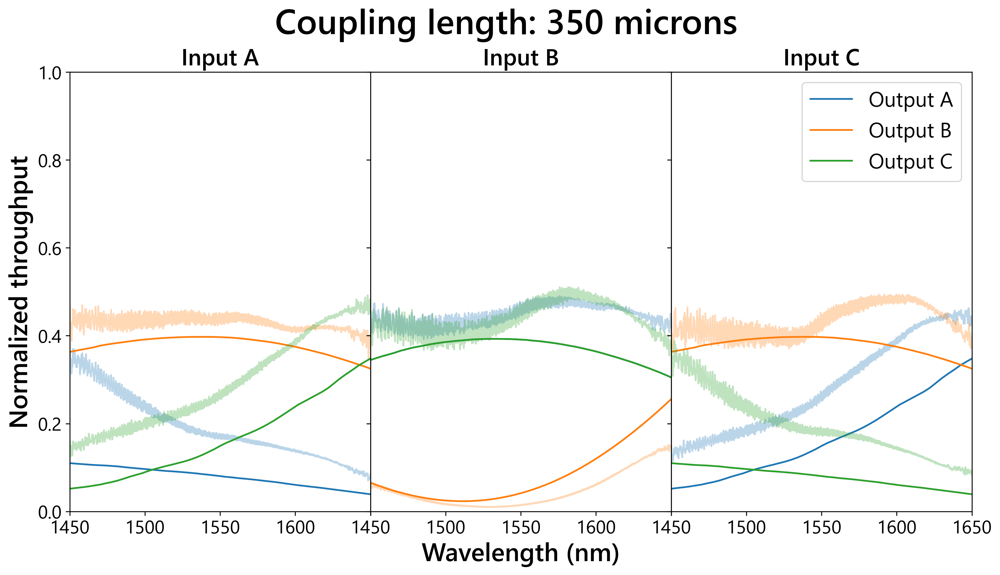

375p000


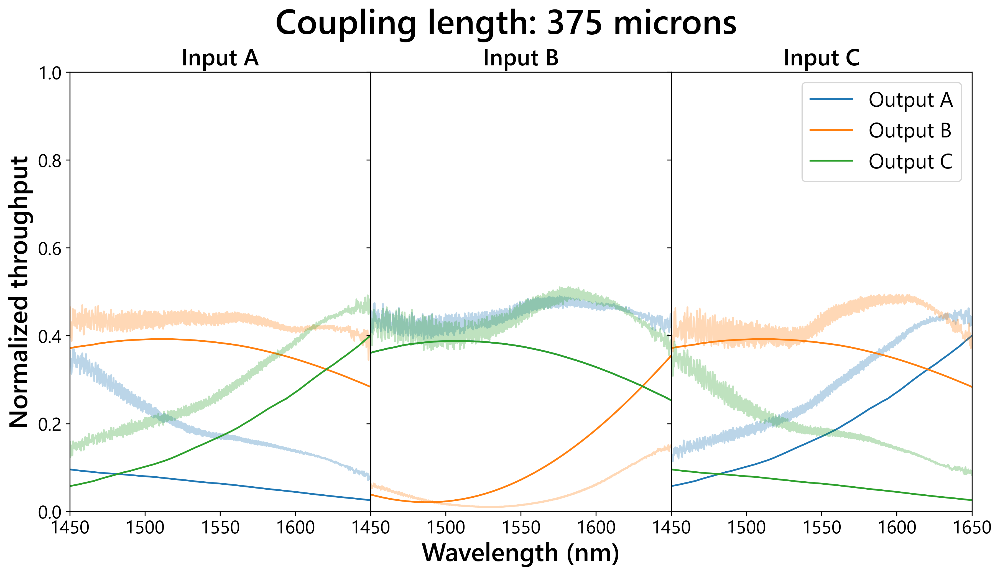

400p000


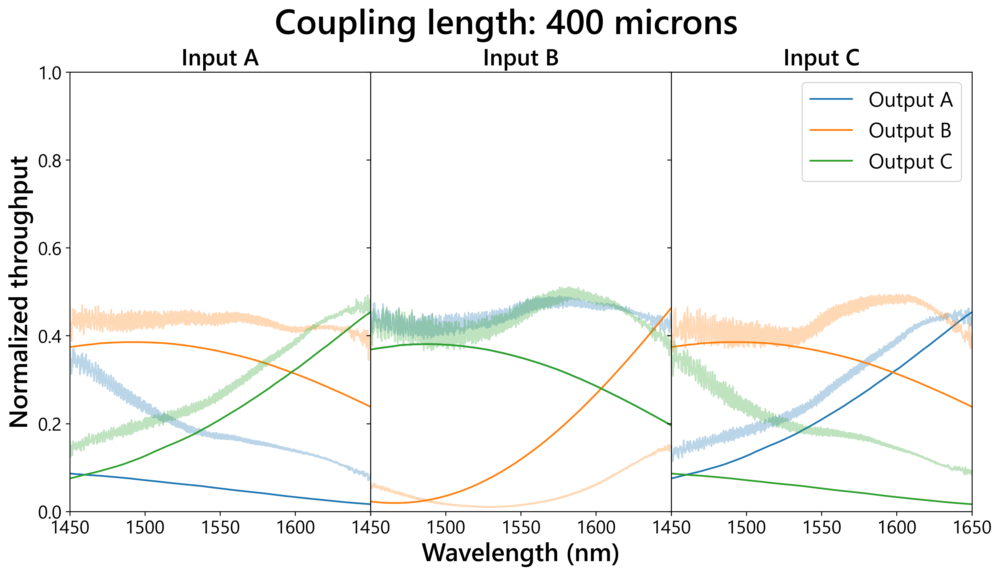

In [18]:
import imageio, io

gif_path = "PassiveChip_1x3Tri_throughput.gif"

data_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\'
device_name = 'Device44_1x3Tri'
model_dir = 'D:\\Active_PIC\\PassiveChip\\20260317\\Device44_1x3Tri\\model\\'

inputs = [50, 51, 52]
outputs = [91, 92, 93]

filepath = f'{data_dir}Device0_I0_O0_Sbend_spectrum.csv'
wav_ref, norm = read_ThorSpectra(filepath, log=False)

lengths = np.arange(250, 401, 25)
wav_range = [1450, 1650]
images = []

for length in lengths:
    # --- your plotting code (unchanged) ---
    length_str = f"{length:.3f}".replace(".", "p")
    print(length_str)
    wavs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_CouplingLength{length_str}_wavs.npy')
    wavs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_CouplingLength{length_str}_wavs.npy')
    wavs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_CouplingLength{length_str}_wavs.npy')
    outputs_left = np.load(f'{model_dir}Tricoupler_FiberOneInput_Left_scan_Wav_CouplingLength{length_str}_outputs.npy')
    outputs_center = np.load(f'{model_dir}Tricoupler_FiberOneInput_Center_scan_Wav_CouplingLength{length_str}_outputs.npy')
    outputs_right = np.load(f'{model_dir}Tricoupler_FiberOneInput_Right_scan_Wav_CouplingLength{length_str}_outputs.npy')

    model_wavs = [wavs_left, wavs_center, wavs_right]
    model_inputs = [outputs_left, outputs_center, outputs_right]

    fig, ax = plt.subplots(1, 3, figsize=(14,7), sharey=True, dpi=300)
    plt.subplots_adjust(wspace=0)

    for i_ind, i in enumerate(inputs):
        fluxes = []
        for o_ind, o in enumerate(outputs):
            filepath = f'{data_dir}{device_name}\\{device_name}_I{i}_O{o}_spectrum.csv'
            wav, flux = read_ThorSpectra(filepath, log=False)
            fluxes.append(np.interp(wav_ref, wav, flux))

        fluxes = np.array(fluxes).T
        # norm = np.sum(fluxes, axis=1, keepdims=True).T.flatten()
        for o_ind in range(len(outputs)):
            ax[i_ind].plot(model_wavs[i_ind]*1000, model_inputs[i_ind][o_ind], label=f'Output {chr(ord("A") + o_ind)}')    
            ax[i_ind].plot(wav_ref, fluxes[:,o_ind]/norm, color=f'C{o_ind}', alpha=0.3)    
        ax[i_ind].set_xlim(wav_range[0], wav_range[1])
        ax[i_ind].set_ylim(0, 1)
        ax[i_ind].set_title(f'Input {chr(ord("A") + i_ind)}')
    for i in range(2):
        ticks = ax[i].get_xticks()
        labels = [int(t) if t != 1650 else '' for t in ticks]  # blank for 1650
        ax[i].set_xticklabels(labels)
    ax[1].set_xlabel('Wavelength (nm)')
    ax[0].set_ylabel('Normalized throughput')
    plt.legend()
    fig.suptitle(f'Coupling length: {length} microns', fontsize=30, fontweight='semibold',
                    y=0.99)

    # --- convert figure to image ---
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=300, bbox_inches='tight')
    buf.seek(0)

    images.append(imageio.imread(buf))
    buf.close()
    plt.show()

# write GIF all at once (better quality)
imageio.mimsave(
    data_dir+device_name+'\\'+gif_path,
    images,
    duration=1
)

Passive chip Y-splitter/2x2 MMI

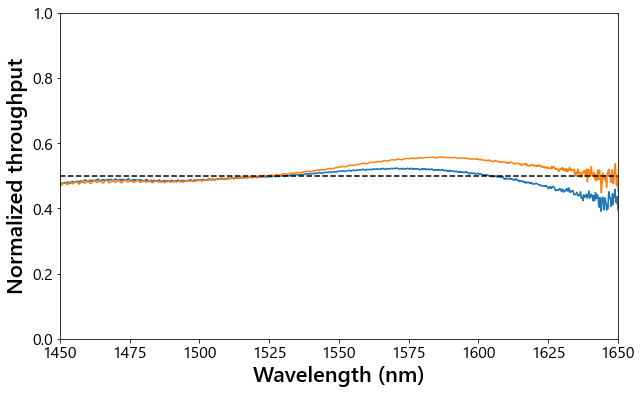

In [213]:
# filename_left = f'D:\\Active_PIC\\2026-04-15\\Device33_Ysplitter_I32_O63_spectrum.csv'
# filename_right = f'D:\\Active_PIC\\2026-04-15\\Device33_Ysplitter_I32_O64_spectrum.csv'
filename_left = f'D:\\Active_PIC\\2026-04-15\\Device20_2x2MMI_I19_O37_spectrum.csv'
filename_right = f'D:\\Active_PIC\\2026-04-15\\Device20_2x2MMI_I19_O38_spectrum.csv'
# filename_sbend = 'D:\\Active_PIC\\2026-04-14\\Device0_I0_O0_Sbend_spectrum.csv'
filename_sbend = 'D:\\Active_PIC\\2026-04-15\\Device0_I0_O0_Sbend_spectrum.csv'
left = read_ThorSpectra(filename_left, log=True) 
right = read_ThorSpectra(filename_right, log=True) 
sbend = read_ThorSpectra(filename_sbend, log=True) 
wav_ref = np.copy(sbend[0])
left, right = np.interp(wav_ref, left[0], left[1]), np.interp(wav_ref, right[0], right[1])

plt.figure(figsize=(10,6))
# plt.plot(wav_ref, sbend[1])
plt.plot(wav_ref, left/sbend[1])
plt.plot(wav_ref, right/sbend[1])
plt.axhline(0.5, color='k', linestyle='dashed')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Normalized throughput')
plt.xlim(1450, 1650)
plt.ylim(0, 1)
plt.show()

Fiber-to-fiber

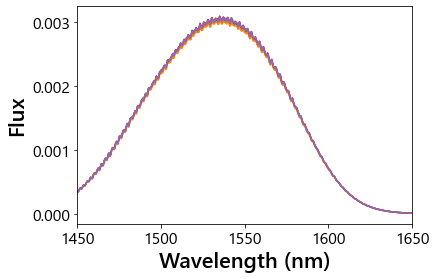

Standard deviation (%): 0.007032407079576379


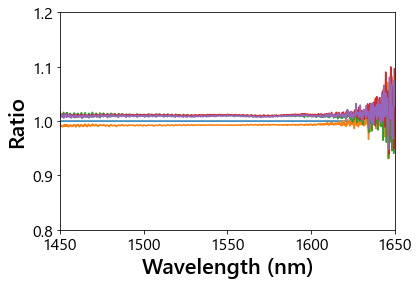

In [273]:
spectra = []
for i in range(5):
    filename = f'D:\\Active_PIC\\2026-04-14\\SLD_PM_oil_SMF_{i}.txt'
    fiber_spec = np.genfromtxt(filename, delimiter=',')
    wav, flux = fiber_spec[:,0], 10**(fiber_spec[:,1]/10)
    if i == 0:
        wav_ref = np.copy(wav)
    else:
        flux = np.interp(wav_ref, wav, flux)
    spectra.append(flux)
spectra = np.array(spectra).T

plt.figure()
plt.plot(wav_ref, spectra)
# plt.plot(wav_sanny, norm_sanny, 'k',label='Sanny s-bend')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Flux')
plt.xlim(1450, 1650)
plt.show()

peak = np.max(spectra, axis=0)
print('Standard deviation (%):', np.std(peak)/np.mean(peak))

plt.figure()
plt.plot(wav_ref, spectra/spectra[:,0][:, None])
# plt.plot(wav_ref, np.interp(wav_ref, wav_sanny, norm_sanny)/spectra[:,0], 'k', label='Sanny s-bend')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Ratio')
plt.xlim(1450, 1650)
plt.ylim(0.8,1.2)
plt.show()

In [279]:
sbend

array([5.14518490e-06, 3.60389585e-06, 4.77968316e-06, ...,
       6.57304448e-06, 5.52746810e-06, 5.06255923e-06])

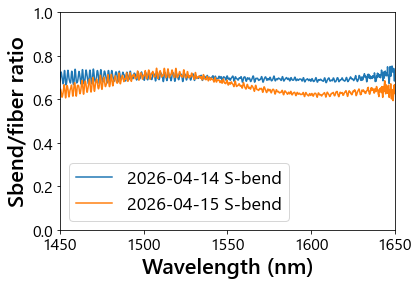

In [285]:
PM_SMF = np.mean(spectra, axis=1)
filename_sbend = 'D:\\Active_PIC\\2026-04-15\\Device0_I0_O0_Sbend_spectrum.csv'
sbend_0 = read_ThorSpectra(filename_sbend, log=True) 
sbend_0 = np.interp(wav_ref, sbend_0[0], sbend_0[1])

filename_sbend = 'D:\\Active_PIC\\2026-04-14\\Device0_I0_O0_Sbend_spectrum.csv'
sbend_1 = read_ThorSpectra(filename_sbend, log=True) 
sbend_1 = np.interp(wav_ref, sbend_1[0], sbend_1[1])

plt.figure()
plt.plot(wav_ref, sbend_1/PM_SMF, label='2026-04-14 S-bend')
plt.plot(wav_ref, sbend_0/PM_SMF, label='2026-04-15 S-bend')
# plt.plot(wav_ref, np.interp(wav_ref, wav_sanny, norm_sanny)/spectra[:,0], 'k', label='Sanny s-bend')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Sbend/fiber ratio')
plt.xlim(1450, 1650)
plt.ylim(0, 1)
plt.legend()
plt.show()

### Active devices

In [2]:
save_dir = 'D:\\Active_PIC\\Data\\device_figs\\Active\\'
data_dir = 'D:\\Active_PIC\\Data\\ForwardsInjectionSpectra\\20260312\\'
# save_dir = 'D:\\Active_PIC\\device_figs\\Active\\ReverseInjection\\'
# data_dir = 'D:\\Active_PIC\\ReverseInjection\\20260304\\'
wav_range = [1450, 1650]

In [3]:
def read_voltage_scan_spectra(data_dir, prefix, channel, sep=';'):
    ''' Outputs all spectra associated with input filename prefix and modulation channel.

        Parameters
        ----------
        data_dir: string
            Path to directory where data being read in are stored
        prefix: string
            Filename prefix (can include wildcard * to encompass multiple voltage scans)
        channel: integer
            Channel being modulated (in voltage) in data of interest
        sep: string
            Separator used in data files
        
        Returns
        -------
        all_spectra: 3D numpy array
            Collection of spectra (nx2 arrays with wavelength in the first column and spectral power in the second column)
        powers: 1D numpy array
            Powers associated with voltages applied to obtain spectra
        actualvoltages: 1D numpy array
            Measured voltages associated with voltages applied to obtain spectra   
    '''
    # List all files of interest with spectra to plot
    files = glob.glob(data_dir+'%s*_Ch%d_V*' % (prefix, channel))
    
    # Identify all voltages associated with data
    dats = np.genfromtxt(glob.glob(f'{data_dir}*.log')[0], names=True, comments="#", delimiter=',')
    voltages = dats[f'inputVoltage{channel}']

    # Average and store all spectra associated with the same voltage applied to the same channel
    all_spectra = []
    for v in voltages:
        v_str = f'{v:0.3f}'.replace('.', 'p')
        files = glob.glob(f'{data_dir}{prefix}*_Ch{channel}_V{v_str}*') # All spectra of a given voltage
        spectra_v = [] 
        for filename in files:
            # Read and store spectrum
            wav, flux = read_ThorSpectra(filename, log=False, delimiter=',')
            spectra_v.append(np.vstack([wav, flux]).T)      
        
        # Average all iterations      
        spectrum_v = np.mean(spectra_v, axis=0)
        all_spectra.append(spectrum_v)

    all_spectra = np.array(all_spectra)

    return voltages, all_spectra

Device 4a

In [4]:
from matplotlib.colors import LogNorm

port_in,  channel = 11, 65
data_dir = 'D:\\Active_PIC\\Data\\ForwardsInjectionSpectra\\20260312\\'
device_name = 'Device4a_1x2MZI_2x2MMI'
filepath = f'{data_dir}{device_name}\\'

port_out = 14
voltages_1, all_spectra_1 = PIC.read_voltage_scan_spectra(filepath, f'{device_name}_I{port_in}_O{port_out}', channel, sep=',')
port_out = 15
voltages_2, all_spectra_2 = PIC.read_voltage_scan_spectra(filepath, f'{device_name}_I{port_in}_O{port_out}', channel, sep=',')


splitting_1, splitting_2 = [], []
spectra_1, spectra_2 = [], []
for i, voltage in enumerate(voltages_1):
    if i == 0:
        wav = all_spectra_1[i][:, 0]
    wav_1, spectrum_1 = all_spectra_1[i][:, 0], all_spectra_1[i][:, 1]
    wav_2, spectrum_2 = all_spectra_2[i][:, 0], all_spectra_2[i][:, 1]
    spectrum_1 = np.interp(wav, wav_1, spectrum_1)
    spectrum_2 = np.interp(wav, wav_2, spectrum_2)
    spectrum_tot = spectrum_1 + spectrum_2
    splitting_1.append(spectrum_1/spectrum_tot)
    splitting_2.append(spectrum_2/spectrum_tot)
    spectra_1.append(spectrum_1)
    spectra_2.append(spectrum_2)

splitting_1, splitting_2 = np.array(splitting_1).T, np.array(splitting_2).T
spectra_1, spectra_2 = np.array(spectra_1).T, np.array(spectra_2).T
wav = 10000000/wav

# fig, ax = plt.subplots(1, 2, figsize=(14,6))
# cmap = plt.get_cmap('viridis') 
# cmap.set_bad(color='gray') 
# fontsize = 18
# plt.subplots_adjust(wspace=0.33)
# im = ax[0].pcolormesh(voltages_1, wav, splitting_1, norm=LogNorm(vmin=1e-4, vmax=1))
# ax[1].pcolormesh(voltages_1, wav, splitting_2, norm=LogNorm(vmin=1e-4, vmax=1))
# for i in range(2):
#     ax[i].set_xlabel('Voltage (V)', fontsize=fontsize)
#     ax[i].set_ylabel('Wavelength (nm)', fontsize=fontsize)
#     ax[i].set_ylim(1450, 1650)
#     ax[i].set_title(f'Output {chr(ord("A") + i)}')
# cbar = fig.colorbar(im, ax=ax, pad=0.07)
# cbar.set_label('Splitting ratio', rotation=270, labelpad=18, fontsize=fontsize)


# plt.savefig(f'{save_dir}{device_name}_splittingMap.png', dpi=300, bbox_inches='tight', transparent=True)
# plt.show()


D:\Active_PIC\Data\ForwardsInjectionSpectra\20260312\Device4a_1x2MZI_2x2MMI\Device4a_1x2MZI_2x2MMI_I11_O14*_Ch65_V*
D:\Active_PIC\Data\ForwardsInjectionSpectra\20260312\Device4a_1x2MZI_2x2MMI\Device4a_1x2MZI_2x2MMI_I11_O15*_Ch65_V*


In [5]:
np.save(f'{filepath}{device_name}_voltages.npy', voltages_1)
np.save(f'{filepath}{device_name}_wavelengths.npy', wav)
np.save(f'{filepath}{device_name}_outputA.npy', splitting_1)
np.save(f'{filepath}{device_name}_outputB.npy', splitting_2)

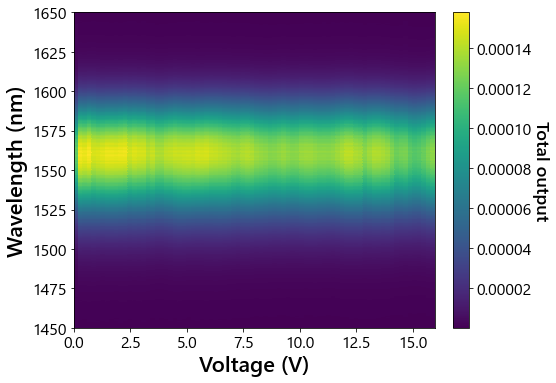

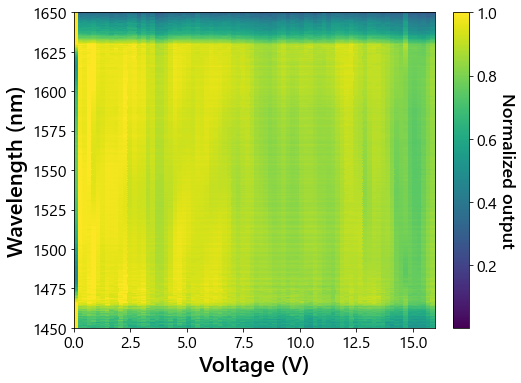

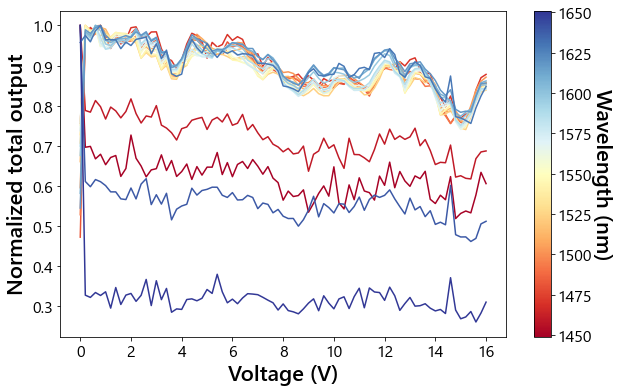

In [43]:
spectra_tot = spectra_1+spectra_2
voltages_tot = np.copy(voltages_1)#[2:], spectra_tot[:, 2:]
# outputs_tot = np.sum(outputs_scaled, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot)#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Total output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot/np.max(spectra_tot, axis=1)[:, None])#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Normalized output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

wavs = np.linspace(1450, 1650, 20)

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wavs)-1, vmax=np.max(wavs)+1)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue

for wav_0 in wavs:    
    color = cmap(norm(wav_0))
    wav_ind = np.argmin(abs(wav-wav_0))
    ax.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), label=f"{voltage:0.3f} V", color=color)

# ax.plot(voltages, outputs_tot/np.max(outputs_tot), 'k')
# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Voltage (V)')
plt.ylabel('Normalized total output')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength (nm)", rotation=270, labelpad=20)

plt.show()  


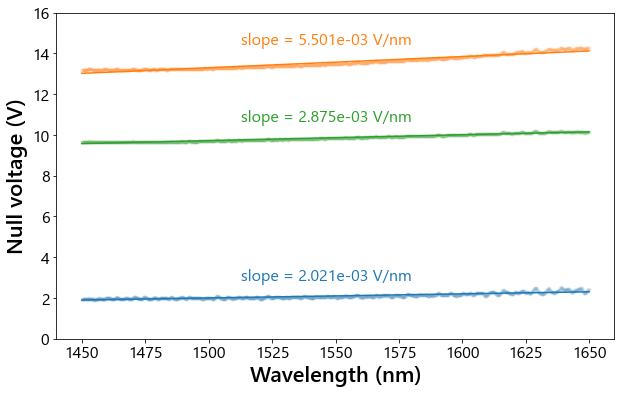

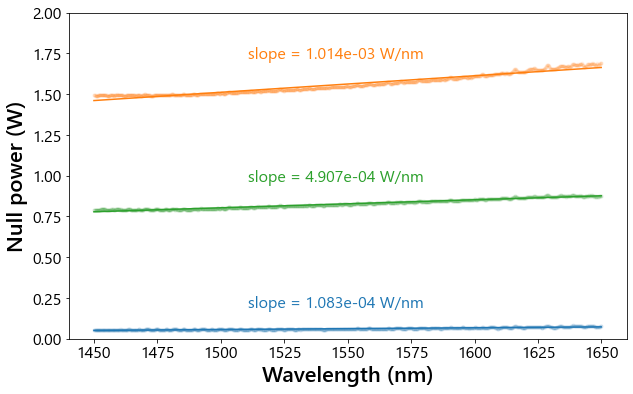

In [62]:
wav_range = abs(wav-1550) < 100
voltage_range = abs(voltages_1 - 2.5) < 2.5
voltage_A_0, wav_null, splitting_A_0 = voltages_1[voltage_range], wav[wav_range], splitting_1[np.ix_(wav_range, voltage_range)]

voltage_range = abs(voltages_1 - 13) < 3
voltage_A_1, splitting_A_1 = voltages_1[voltage_range], splitting_1[np.ix_(wav_range, voltage_range)]

voltage_range = abs(voltages_1 - 10) < 2
voltage_B_0, splitting_B_0 = voltages_1[voltage_range], splitting_2[np.ix_(wav_range, voltage_range)]

resistance = 120
current_A_0, current_A_1, current_B_0 = voltage_A_0/resistance, voltage_A_1/resistance, voltage_B_0/resistance
power_A_0, power_A_1, power_B_0 = current_A_0*voltage_A_0, current_A_1*voltage_A_1, current_B_0*voltage_B_0

null_V_A_0, null_V_A_1, null_V_B_0 = [], [], []
null_P_A_0, null_P_A_1, null_P_B_0 = [], [], []
for i in range(len(wav_null)):
    a, b, c = np.polyfit(voltage_A_0, splitting_A_0[i], 2)
    null_V_A_0.append(-b / (2*a))
    a, b, c = np.polyfit(power_A_0, splitting_A_0[i], 2)
    null_P_A_0.append(-b / (2*a))

    a, b, c = np.polyfit(voltage_A_1, splitting_A_1[i], 2)
    null_V_A_1.append(-b / (2*a))
    a, b, c = np.polyfit(power_A_1, splitting_A_1[i], 2)
    null_P_A_1.append(-b / (2*a))

    a, b, c = np.polyfit(voltage_B_0, splitting_B_0[i], 2)
    null_V_B_0.append(-b / (2*a))
    a, b, c = np.polyfit(power_B_0, splitting_B_0[i], 2)
    null_P_B_0.append(-b / (2*a))

m_V_A_0, b_V_A_0 = np.polyfit(wav_null, null_V_A_0, 1)
m_V_A_1, b_V_A_1 = np.polyfit(wav_null, null_V_A_1, 1)
m_V_B_0, b_V_B_0 = np.polyfit(wav_null, null_V_B_0, 1)
m_P_A_0, b_P_A_0 = np.polyfit(wav_null, null_P_A_0, 1)
m_P_A_1, b_P_A_1 = np.polyfit(wav_null, null_P_A_1, 1)
m_P_B_0, b_P_B_0 = np.polyfit(wav_null, null_P_B_0, 1)

plt.figure(figsize=(10,6))
plt.plot(wav_null, null_V_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_V_A_0*wav_null + b_V_A_0, color='C0')
plt.plot(wav_null, null_V_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_V_A_1*wav_null + b_V_A_1, color='C1')
plt.plot(wav_null, null_V_B_0, '.', alpha=0.05, color='C2')
plt.plot(wav_null, m_V_B_0*wav_null + b_V_B_0, color='C2')
x_text = 1580
plt.text(x_text, m_V_A_0*x_text + b_V_A_0 + 0.5,
         f'slope = {m_V_A_0:.3e} V/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_V_A_1*x_text + b_V_A_1 + 0.5,
         f'slope = {m_V_A_1:.3e} V/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_V_B_0*x_text + b_V_B_0 + 0.5,
         f'slope = {m_V_B_0:.3e} V/nm', color='C2', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 16)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null voltage (V)')
plt.show()


plt.figure(figsize=(10,6))
plt.plot(wav_null, null_P_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_P_A_0*wav_null + b_P_A_0, color='C0')
plt.plot(wav_null, null_P_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_P_A_1*wav_null + b_P_A_1, color='C1')
plt.plot(wav_null, null_P_B_0, '.', alpha=0.05, color='C2')
plt.plot(wav_null, m_P_B_0*wav_null + b_P_B_0, color='C2')
x_text = 1580
plt.text(x_text, m_P_A_0*x_text + b_P_A_0 + 0.1,
         f'slope = {m_P_A_0:.3e} W/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_P_A_1*x_text + b_P_A_1 + 0.1,
         f'slope = {m_P_A_1:.3e} W/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_P_B_0*x_text + b_P_B_0 + 0.1,
         f'slope = {m_P_B_0:.3e} W/nm', color='C2', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 2)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null power (W)')
plt.show()

<ipython-input-480-1b2bae89a782>:26: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. In future versions, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = copy.copy(mpl.cm.get_cmap("viridis"))
  cmap.set_bad(color='gray')
<ipython-input-480-1b2bae89a782>:29: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  im = ax[0].pcolormesh(voltages_1, 10000000/wav, splitting_1, norm=LogNorm(vmin=1e-3, vmax=1))
<ipython-input-480-1b2bae89a782>:30: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals 

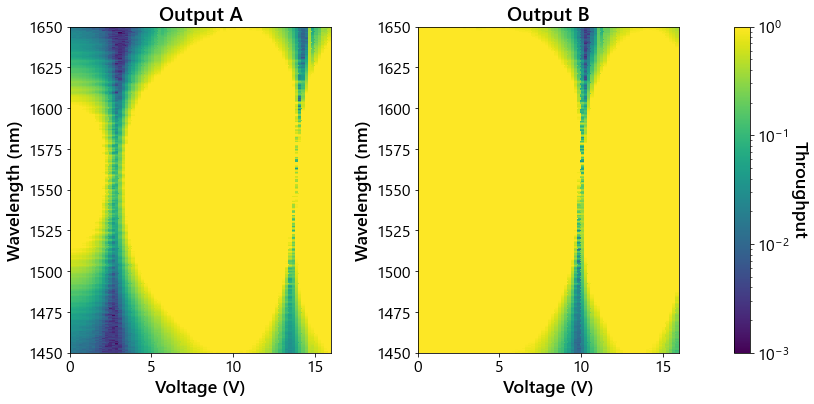

In [480]:
port_in,  channel = 11, 65
device_name = 'Device4a_1x2MZI_2x2MMI'
filepath = f'{data_dir}{device_name}\\'

port_out = 14
voltages_1, all_spectra_1 = read_voltage_scan_spectra('D:\\Active_PIC\\ForwardsInjectionSpectra\\20260312\\Device4a_1x2MZI_2x2MMI\\', f'{device_name}_I{port_in}_O{port_out}', channel, sep=',')
port_out = 15
voltages_2, all_spectra_2 = read_voltage_scan_spectra('D:\\Active_PIC\\ForwardsInjectionSpectra\\20260312\\Device4a_1x2MZI_2x2MMI\\', f'{device_name}_I{port_in}_O{port_out}', channel, sep=',')
filepath = f'{data_dir}Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_sbend, flux_sbend = read_ThorSpectra(filepath, log=True)

splitting_1, splitting_2 = [], []
for i, voltage in enumerate(voltages_1):
    wav, spectrum_1 = all_spectra_1[i][:, 0], all_spectra_1[i][:, 1]
    wav_2, spectrum_2 = all_spectra_2[i][:, 0], all_spectra_2[i][:, 1]
    spectrum_2 = np.interp(wav, wav_2, spectrum_2)
    # spectrum_tot = spectrum_1 + spectrum_2
    spectrum_tot = np.interp(wav, wav_sbend, flux_sbend)
    splitting_1.append(spectrum_1/spectrum_tot)
    splitting_2.append(spectrum_2/spectrum_tot)

splitting_1, splitting_2 = np.array(splitting_1).T, np.array(splitting_2).T

fig, ax = plt.subplots(1, 2, figsize=(14,6))
cmap = plt.get_cmap('viridis') 
cmap.set_bad(color='gray') 
fontsize = 18
plt.subplots_adjust(wspace=0.33)
im = ax[0].pcolormesh(voltages_1, 10000000/wav, splitting_1, norm=LogNorm(vmin=1e-3, vmax=1))
ax[1].pcolormesh(voltages_1, 10000000/wav, splitting_2, norm=LogNorm(vmin=1e-3, vmax=1))
for i in range(2):
    ax[i].set_xlabel('Voltage (V)', fontsize=fontsize)
    ax[i].set_ylabel('Wavelength (nm)', fontsize=fontsize)
    ax[i].set_ylim(1450, 1650)
    ax[i].set_title(f'Output {chr(ord("A") + i)}')
cbar = fig.colorbar(im, ax=ax, pad=0.07)
cbar.set_label('Throughput', rotation=270, labelpad=18, fontsize=fontsize)


plt.savefig(f'{save_dir}{device_name}_throughputMap.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,6))
cmap = plt.get_cmap('viridis') 
cmap.set_bad(color='gray') 
fontsize = 18
plt.subplots_adjust(wspace=0.33)
im = ax[0].pcolormesh(voltages_1, 10000000/wav, splitting_1, norm=LogNorm(vmin=1e-4, vmax=1))
ax[1].pcolormesh(voltages_1, 10000000/wav, splitting_2, norm=LogNorm(vmin=1e-4, vmax=1))
for i in range(2):
    ax[i].set_xlabel('Voltage (V)', fontsize=fontsize)
    ax[i].set_ylabel('Wavelength (nm)', fontsize=fontsize)
    ax[i].set_ylim(1450, 1650)
    ax[i].set_title(f'Output {chr(ord("A") + i)}')
cbar = fig.colorbar(im, ax=ax, pad=0.07)
cbar.set_label('Throughput', rotation=270, labelpad=18, fontsize=fontsize)


plt.savefig(f'{save_dir}{device_name}_throughputMap.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Device 5a

In [2]:
port_in, channel, fontsize = 15, 66, 18
device_name = 'Device5a_I15_1x3Tri'
data_dir = f'D:\\Active_PIC\\Data\\SpectroscopyScans\\Device5a_I15_1x3Tri\\20260508\\'

port_out = 20
voltages_1, all_spectra_1 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}\\', 
                                                          f'{device_name}_O{port_out}', 
                                                          channel, delimiter=';')
port_out = 21
voltages_2, all_spectra_2 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}\\', 
                                                          f'{device_name}_O{port_out}', 
                                                          channel, delimiter=';')
port_out = 22
voltages_3, all_spectra_3 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}\\', 
                                                          f'{device_name}_O{port_out}', 
                                                          channel, delimiter=';')

filepath = 'D:\\Active_PIC\\Data\\SpectroscopyScans\\Device1_I3_SbendWaveguide_O1.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=False, delimiter=';')

throughput_1, throughput_2, throughput_3 = [], [], []
splitting_1, splitting_2, splitting_3 = [], [], []
spectra_1, spectra_2, spectra_3 = [], [], []
for i, voltage in enumerate(voltages_1):
    wav, spectrum_1 = all_spectra_1[i][:, 0], all_spectra_1[i][:, 1]
    wav_2, spectrum_2 = all_spectra_2[i][:, 0], all_spectra_2[i][:, 1]
    wav_3, spectrum_3 = all_spectra_3[i][:, 0], all_spectra_3[i][:, 1]
    spectrum_2 = np.interp(wav, wav_2, spectrum_2)
    spectrum_3 = np.interp(wav, wav_3, spectrum_3)
    spectrum_sbend = np.interp(wav, wav_sbend, flux_sbend)
    spectrum_tot = spectrum_1 + spectrum_2 + spectrum_3
    
    throughput_1.append(spectrum_1/spectrum_sbend)
    throughput_2.append(spectrum_2/spectrum_sbend)
    throughput_3.append(spectrum_3/spectrum_sbend)

    splitting_1.append(spectrum_1/spectrum_tot)
    splitting_2.append(spectrum_2/spectrum_tot)
    splitting_3.append(spectrum_3/spectrum_tot)

    spectra_1.append(spectrum_1)
    spectra_2.append(spectrum_2)
    spectra_3.append(spectrum_3)

throughput_1, throughput_2, throughput_3 = np.array(throughput_1).T, np.array(throughput_2).T, np.array(throughput_3).T
splitting_1, splitting_2, splitting_3 = np.array(splitting_1).T, np.array(splitting_2).T, np.array(splitting_3).T
spectra_1, spectra_2, spectra_3 = np.array(spectra_1).T, np.array(spectra_2).T, np.array(spectra_3).T
wav = 10000000/wav

# fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
# from matplotlib.colors import LogNorm
# cmap = plt.get_cmap('viridis')
# cmap.set_bad(color='gray')
# vmin, vmax= -25, 0
# plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
# im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(throughput_1), vmin=vmin, vmax=vmax)
# ax[1].pcolormesh(voltages_1, wav, 10*np.log10(throughput_2), vmin=vmin, vmax=vmax)
# ax[2].pcolormesh(voltages_1, wav, 10*np.log10(throughput_3), vmin=vmin, vmax=vmax)
# for i in range(3):
#     ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
# ax[0].set_ylabel('Wavelength (nm)')
# ax[1].set_xlabel('Voltage (V)')
# ax[0].set_ylim(1450, 1650)
# cbar = fig.colorbar(im, ax=ax, pad=0.04)
# cbar.set_label('Throughput (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# # plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
# #             dpi=300, bbox_inches='tight', transparent=True)
# plt.show()

# fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
# from matplotlib.colors import LogNorm
# cmap = plt.get_cmap('viridis')
# cmap.set_bad(color='gray')
# vmin, vmax= -35, 0
# plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
# im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(splitting_1), vmin=vmin, vmax=vmax)
# ax[1].pcolormesh(voltages_1, wav, 10*np.log10(splitting_2), vmin=vmin, vmax=vmax)
# ax[2].pcolormesh(voltages_1, wav, 10*np.log10(splitting_3), vmin=vmin, vmax=vmax)
# for i in range(3):
#     ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
# ax[0].set_ylabel('Wavelength (nm)')
# ax[1].set_xlabel('Voltage (V)')
# ax[0].set_ylim(1450, 1650)
# cbar = fig.colorbar(im, ax=ax, pad=0.04)
# cbar.set_label('Splitting ratio (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# # plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
# #             dpi=300, bbox_inches='tight', transparent=True)
# plt.show()

norm = np.max(spectra_2, axis=1, keepdims=True)
null = 10*np.log10(spectra_2/norm)


# fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
# cmap = plt.get_cmap('viridis')
# cmap.set_bad(color='gray')
# plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
# im = ax.pcolormesh(voltages_1, wav, null, vmin=-35, vmax=0)
# ax.set_ylabel('Wavelength (nm)')
# ax.set_xlabel('Voltage (V)')
# ax.set_ylim(1450, 1650)
# cbar = fig.colorbar(im, ax=ax, pad=0.04)
# cbar.set_label('Null depth (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# # plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
# #             dpi=300, bbox_inches='tight', transparent=True)
# plt.show()


D:\Active_PIC\Data\SpectroscopyScans\Device5a_I15_1x3Tri\20260508\Device5a_I15_1x3Tri_O20\Device5a_I15_1x3Tri_O20*_Ch66_V*
D:\Active_PIC\Data\SpectroscopyScans\Device5a_I15_1x3Tri\20260508\Device5a_I15_1x3Tri_O21\Device5a_I15_1x3Tri_O21*_Ch66_V*
D:\Active_PIC\Data\SpectroscopyScans\Device5a_I15_1x3Tri\20260508\Device5a_I15_1x3Tri_O22\Device5a_I15_1x3Tri_O22*_Ch66_V*


In [3]:
np.save(f'{data_dir}{device_name}_voltages.npy', voltages_1)
np.save(f'{data_dir}{device_name}_wavelengths.npy', wav)
np.save(f'{data_dir}{device_name}_outputA.npy', splitting_1)
np.save(f'{data_dir}{device_name}_outputB.npy', splitting_2)
np.save(f'{data_dir}{device_name}_outputC.npy', splitting_3)

In [7]:
filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{filename_root}\\20260506\\voltage_scan\\{filename_root}_amoeba_TECoff_trial0\\'
voltages = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)

spectra_tot = spectra_1+spectra_2+spectra_3
voltages_tot, spectra_tot = np.copy(voltages_1)[2:], spectra_tot[:, 2:]
outputs_tot = np.sum(outputs_scaled, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot)#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Total output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot/np.max(spectra_tot, axis=1)[:, None])#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Normalized output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

wavs = np.linspace(1450, 1650, 20)

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wavs)-1, vmax=np.max(wavs)+1)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue

for wav_0 in wavs:    
    color = cmap(norm(wav_0))
    wav_ind = np.argmin(abs(wav-wav_0))
    ax.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), label=f"{voltage:0.3f} V", color=color)

ax.plot(voltages, outputs_tot/np.max(outputs_tot), 'k')
# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Voltage (V)')
plt.ylabel('Normalized total output')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength (nm)", rotation=270, labelpad=20)

plt.show()  

fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i]/np.max(np.sum(outputs_scaled, axis=1)), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, spectra_1[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C0')
ax1.plot(voltages_tot, spectra_2[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C1')
ax1.plot(voltages_tot, spectra_3[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C2')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

fig, ax1 = plt.subplots(figsize=(10,6))
# ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, 10*np.log10(outputs_scaled[:,i]/np.max(outputs_scaled[:,i])), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
# ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, 10*np.log10(spectra_1[wav_ind, 2:]/np.max(spectra_1[wav_ind, 2:])), '--', color='C0')
ax1.plot(voltages_tot, 10*np.log10(spectra_2[wav_ind, 2:]/np.max(spectra_2[wav_ind, 2:])), '--', color='C1')
ax1.plot(voltages_tot, 10*np.log10(spectra_3[wav_ind, 2:]/np.max(spectra_3[wav_ind, 2:])), '--', color='C2')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260506\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECoff_trial0\\Device5a_I15_1x3Tri_voltage.npy'

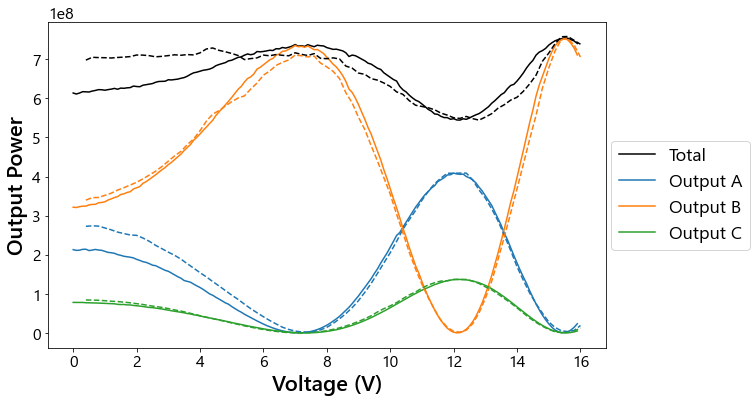

In [75]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i], color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
spec_tot_scaled = (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:] + (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:] + (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:]
ax1.plot(voltages_tot, spec_tot_scaled, 'k--')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:], '--', color='C0')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:], '--', color='C1')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:], '--', color='C2')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

In [11]:
def scale_voltage_scan(outputs, attens):
    """Get output intensities for each image produced by a voltage scan.

    Parameters
    ----------
    outputs : array-like
        Output intensities at each voltage setting
    attens : array-like
        Attenuation applied for each output at each voltage setting

    Returns
    -------
    outputs_scaled : ndarray
        Output intensities scaled by attenuation
    """

    outputs = np.asarray(outputs, dtype=float)
    attens = np.asarray(attens, dtype=float)

    # Create attenuation array in dB
    attens_dB = np.full(attens.shape, np.nan)
    # Convert unique attenuation voltages to dB
    for atten in np.unique(attens[~np.isnan(attens)]):
        attens_dB[attens == atten] = BENCH.externalVOA_voltage_to_dB(atten)

    # Convert dB attenuation to linear scaling
    scaling = 10 ** (attens_dB / 10)

    # Apply scaling
    outputs_scaled = outputs * scaling

    return outputs_scaled

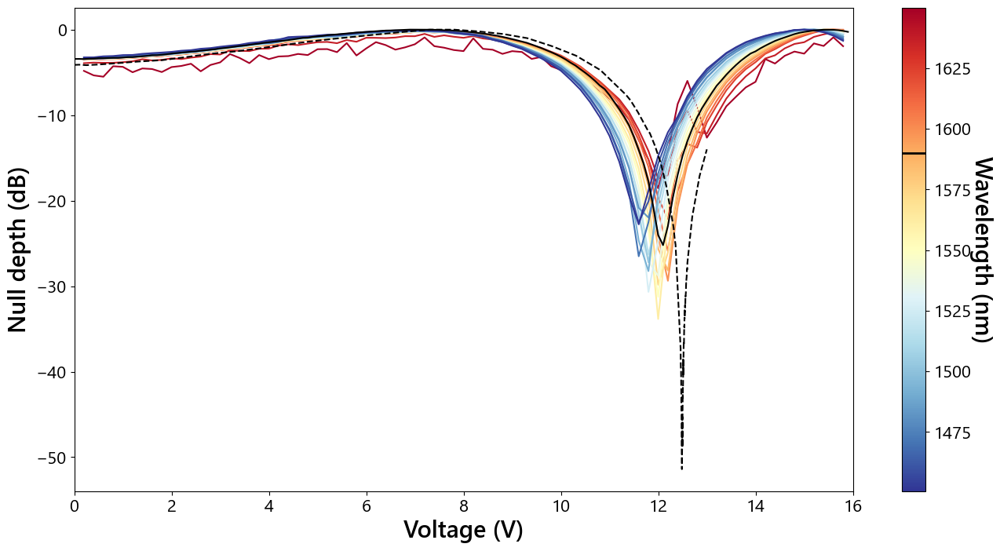

In [20]:
from Bench import BENCH

wav_range, skip = 100, 100
wav_cond, voltages_cond = np.abs(wav-1550)<wav_range, np.abs(voltages_3-8)<8
wav_poly, voltages_poly, null_poly = wav[wav_cond], voltages_2[voltages_cond], null[np.ix_(wav_cond, voltages_cond)]
wav_poly, null_poly = wav_poly[::skip], null_poly[::skip,:]

fig, ax = plt.subplots(figsize=(16,8))
norm = plt.Normalize(vmin=np.min(wav_poly), vmax=np.max(wav_poly))
cmap = cm.get_cmap('RdYlBu_r')  # red → yellow → blue
for i in range(len(wav_poly)):
    color = cmap(norm(wav_poly[i]))
    ax.plot(voltages_poly, null_poly[i], color=color)# linestyle='dashed')

# Unpolarized
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260506\\voltage_scan\\Device5a_I15_1x3Tri_amoeba_TECon_trial0\\'
filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
voltages_phot = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs_phot = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
attens_dB = np.nan * np.ones_like(attens)
for atten in np.sort(list(set(attens.flatten()))):
    atten_dB = BENCH.externalVOA_voltage_to_dB(atten)
    attens_dB[attens==atten] = atten_dB
scaling = 10**(attens_dB/10).reshape(len(attens_dB), num_outputs)
outputs_phot = scaling*outputs_phot
flux_ratio_maxC = outputs_phot[:, 1]/np.max(outputs_phot[:,1])
null_phot = 10*np.log10(flux_ratio_maxC)
ax.plot(voltages_phot, null_phot, color='k')

# Polarized
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\Device5a_I15_1x3Tri\\20260921\\voltage_scan\\Device5a_I15_1x3Tri_TECon_polarizer_adaptive_trial1\\'
filename_root, num_outputs = 'Device5a_I15_1x3Tri', 3
voltages_phot = np.load(f'{data_dir}{filename_root}_voltage.npy')
outputs_phot = np.load(f'{data_dir}{filename_root}_outputs.npy')
attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
outputs_phot = outputs_phot * 10**(attens/10)
flux_ratio_maxC = outputs_phot/np.max(outputs_phot)
null_phot = 10*np.log10(flux_ratio_maxC)
ax.plot(voltages_phot, null_phot, color='k', linestyle='dashed')

plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.ax.axhline(1590, color='k', linewidth=2)
cbar.set_label("Wavelength (nm)", rotation=270, labelpad=20)
plt.xlim(0, 16)
# plt.ylim(-40, 1)

plt.show()

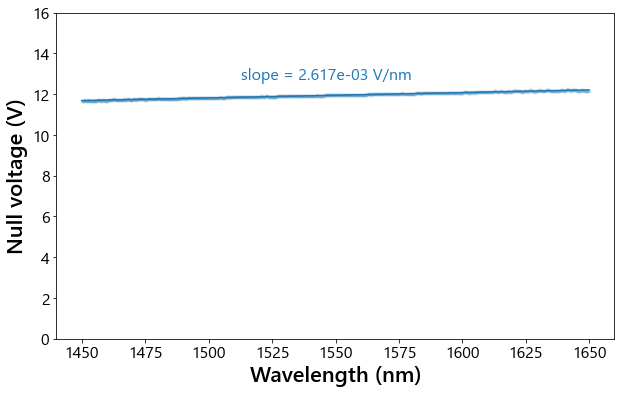

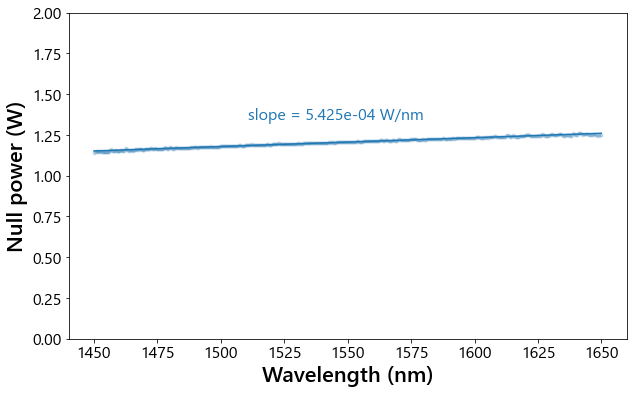

In [4]:
wav_range = abs(wav-1550) < 100
voltage_range = abs(voltages_1 - 12) < 2
voltage_B_0, wav_null, splitting_B_0 = voltages_1[voltage_range], wav[wav_range], null[np.ix_(wav_range, voltage_range)]

resistance = 120
current_B_0 = voltage_B_0/resistance
power_B_0 = current_B_0*voltage_B_0

null_V_B_0 = []
null_P_B_0 = []

for i in range(len(wav_null)):
    a, b, c = np.polyfit(voltage_B_0, splitting_B_0[i], 2)
    null_V_B_0.append(-b / (2*a))
    a, b, c = np.polyfit(power_B_0, splitting_B_0[i], 2)
    null_P_B_0.append(-b / (2*a))


m_V_B_0, b_V_B_0 = np.polyfit(wav_null, null_V_B_0, 1)
m_P_B_0, b_P_B_0 = np.polyfit(wav_null, null_P_B_0, 1)

plt.figure(figsize=(10,6))
plt.plot(wav_null, null_V_B_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_V_B_0*wav_null + b_V_B_0, color='C0')

x_text = 1580
plt.text(x_text, m_V_B_0*x_text + b_V_B_0 + 0.5,
         f'slope = {m_V_B_0:.3e} V/nm', color='C0', va='bottom', ha='right', fontsize=16)

plt.ylim(0, 16)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null voltage (V)')
plt.show()


plt.figure(figsize=(10,6))
plt.plot(wav_null, null_P_B_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_P_B_0*wav_null + b_P_B_0, color='C0')
x_text = 1580
plt.text(x_text, m_P_B_0*x_text + b_P_B_0 + 0.1,
         f'slope = {m_P_B_0:.3e} W/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 2)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null power (W)')
plt.show()

Device 6a

D:\Active_PIC\SpectroscopyScans\Device6a_I18_1x5Tri\20260508\Device6a_I18_1x5Tri_O26_Ch61_V9p550_Ch62_V10p380\Device6a_I18_1x5Tri_O26_Ch61_V9p550_Ch62_V10p380*_Ch41_V*
D:\Active_PIC\SpectroscopyScans\Device6a_I18_1x5Tri\20260508\Device6a_I18_1x5Tri_O27_Ch61_V9p550_Ch62_V10p380\Device6a_I18_1x5Tri_O27_Ch61_V9p550_Ch62_V10p380*_Ch41_V*
D:\Active_PIC\SpectroscopyScans\Device6a_I18_1x5Tri\20260508\Device6a_I18_1x5Tri_O28_Ch61_V9p550_Ch62_V10p380\Device6a_I18_1x5Tri_O28_Ch61_V9p550_Ch62_V10p380*_Ch41_V*
D:\Active_PIC\SpectroscopyScans\Device6a_I18_1x5Tri\20260508\Device6a_I18_1x5Tri_O29_Ch61_V9p550_Ch62_V10p380\Device6a_I18_1x5Tri_O29_Ch61_V9p550_Ch62_V10p380*_Ch41_V*
D:\Active_PIC\SpectroscopyScans\Device6a_I18_1x5Tri\20260508\Device6a_I18_1x5Tri_O30_Ch61_V9p550_Ch62_V10p380\Device6a_I18_1x5Tri_O30_Ch61_V9p550_Ch62_V10p380*_Ch41_V*


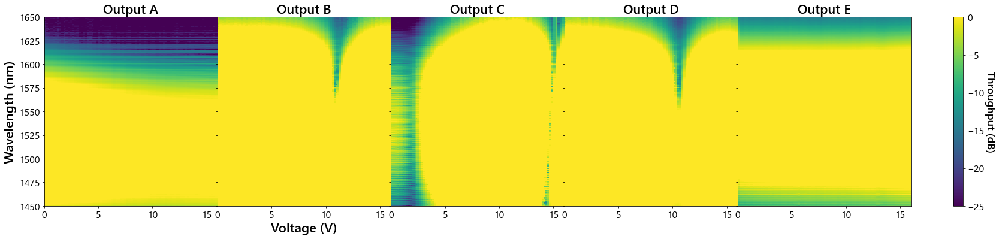

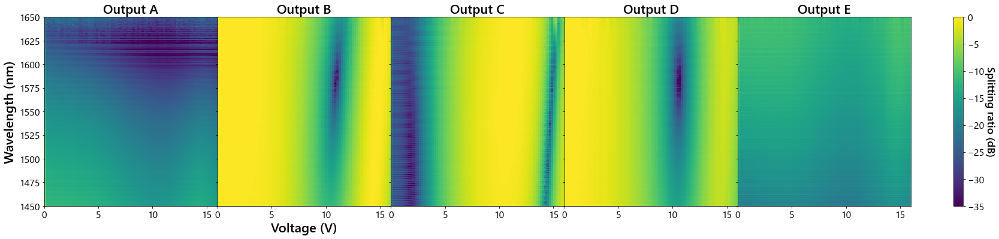

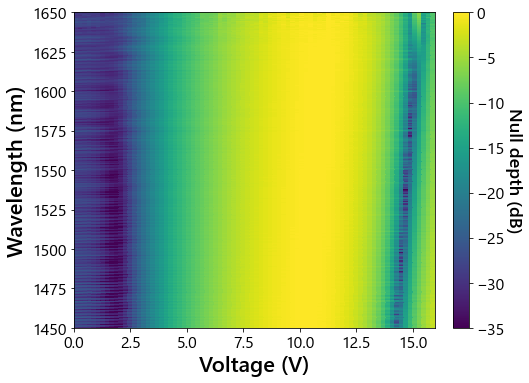

In [104]:
port_in, channel, fontsize = 18, 41, 18
device_name = 'Device6a_I18_1x5Tri'
data_dir = f'D:\\Active_PIC\\SpectroscopyScans\\Device6a_I18_1x5Tri\\20260508\\'
filename_ext = 'Ch61_V9p550_Ch62_V10p380'

port_out = 26
voltages_1, all_spectra_1 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 27
voltages_2, all_spectra_2 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 28
voltages_3, all_spectra_3 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 29
voltages_4, all_spectra_4 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 30
voltages_5, all_spectra_5 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')

filepath = 'D:\\Active_PIC\\SpectroscopyScans\\Device1_I3_SbendWaveguide_O1.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=False, delimiter=';')

throughput_1, throughput_2, throughput_3, throughput_4, throughput_5 = [], [], [], [], []
splitting_1, splitting_2, splitting_3, splitting_4, splitting_5 = [], [], [], [], []
spectra_1, spectra_2, spectra_3, spectra_4, spectra_5 = [], [], [], [], []
for i, voltage in enumerate(voltages_1):
    wav, spectrum_1 = all_spectra_1[i][:, 0], all_spectra_1[i][:, 1]
    wav_2, spectrum_2 = all_spectra_2[i][:, 0], all_spectra_2[i][:, 1]
    wav_3, spectrum_3 = all_spectra_3[i][:, 0], all_spectra_3[i][:, 1]
    wav_4, spectrum_4 = all_spectra_4[i][:, 0], all_spectra_4[i][:, 1]
    wav_5, spectrum_5 = all_spectra_5[i][:, 0], all_spectra_5[i][:, 1]
    spectrum_2 = np.interp(wav, wav_2, spectrum_2)
    spectrum_3 = np.interp(wav, wav_3, spectrum_3)
    spectrum_4 = np.interp(wav, wav_4, spectrum_4)
    spectrum_5 = np.interp(wav, wav_5, spectrum_5)
    spectrum_sbend = np.interp(wav, wav_sbend, flux_sbend)
    spectrum_tot = spectrum_1 + spectrum_2 + spectrum_3
    
    throughput_1.append(spectrum_1/spectrum_sbend)
    throughput_2.append(spectrum_2/spectrum_sbend)
    throughput_3.append(spectrum_3/spectrum_sbend)
    throughput_4.append(spectrum_4/spectrum_sbend)
    throughput_5.append(spectrum_5/spectrum_sbend)

    splitting_1.append(spectrum_1/spectrum_tot)
    splitting_2.append(spectrum_2/spectrum_tot)
    splitting_3.append(spectrum_3/spectrum_tot)
    splitting_4.append(spectrum_4/spectrum_tot)
    splitting_5.append(spectrum_5/spectrum_tot)

    spectra_1.append(spectrum_1)
    spectra_2.append(spectrum_2)
    spectra_3.append(spectrum_3)
    spectra_4.append(spectrum_4)
    spectra_5.append(spectrum_5)

throughput_1, throughput_2, throughput_3, throughput_4, throughput_5 = np.array(throughput_1).T, np.array(throughput_2).T, np.array(throughput_3).T, np.array(throughput_4).T, np.array(throughput_5).T
splitting_1, splitting_2, splitting_3, splitting_4, splitting_5 = np.array(splitting_1).T, np.array(splitting_2).T, np.array(splitting_3).T, np.array(splitting_4).T, np.array(splitting_5).T
spectra_1, spectra_2, spectra_3, spectra_4, spectra_5 = np.array(spectra_1).T, np.array(spectra_2).T, np.array(spectra_3).T, np.array(spectra_4).T, np.array(spectra_5).T
wav = 10000000/wav

fig, ax = plt.subplots(1, 5, figsize=(32, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= -25, 0
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(throughput_1), vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_1, wav, 10*np.log10(throughput_2), vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_1, wav, 10*np.log10(throughput_3), vmin=vmin, vmax=vmax)
ax[3].pcolormesh(voltages_1, wav, 10*np.log10(throughput_4), vmin=vmin, vmax=vmax)
ax[4].pcolormesh(voltages_1, wav, 10*np.log10(throughput_5), vmin=vmin, vmax=vmax)
for i in range(5):
    ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Throughput (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 5, figsize=(32, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= -35, 0
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(splitting_1), vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_1, wav, 10*np.log10(splitting_2), vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_1, wav, 10*np.log10(splitting_3), vmin=vmin, vmax=vmax)
ax[3].pcolormesh(voltages_1, wav, 10*np.log10(splitting_4), vmin=vmin, vmax=vmax)
ax[4].pcolormesh(voltages_1, wav, 10*np.log10(splitting_5), vmin=vmin, vmax=vmax)
for i in range(5):
    ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Splitting ratio (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

norm = np.max(spectra_3, axis=1, keepdims=True)
null = 10*np.log10(spectra_3/norm)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_1, wav, null, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [99]:
voltages_tot = np.copy(voltages_1)#[2:]#, spectra_tot[:, 2:]

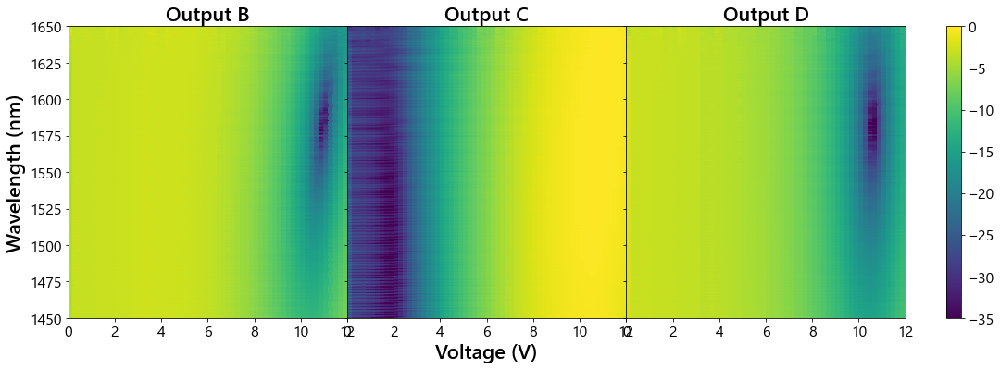

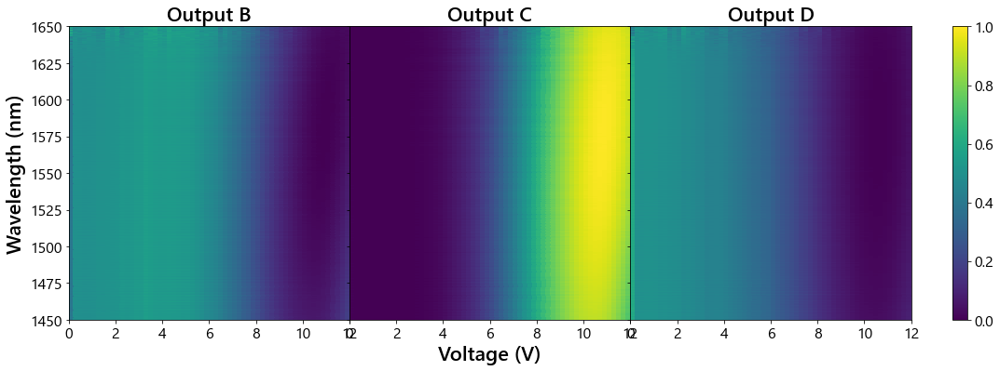

In [113]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= -35, 0
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
spectra_tot = spectra_2 + spectra_3 + spectra_4
im = ax[0].pcolormesh(voltages_tot, wav, 10*np.log10(spectra_2/spectra_tot), vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_tot, wav, 10*np.log10(spectra_3/spectra_tot), vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_tot, wav, 10*np.log10(spectra_4/spectra_tot), vmin=vmin, vmax=vmax)
for i in range(3):
    ax[i].set_title(f'Output {chr(ord("A") + i+1)}', fontsize=22)
    ax[i].set_xlim(0, 12)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
# cbar.set_label('Splitting ratio (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= 0, 1
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
spectra_tot = spectra_2 + spectra_3 + spectra_4
im = ax[0].pcolormesh(voltages_tot, wav, spectra_2/spectra_tot, vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_tot, wav, spectra_3/spectra_tot, vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_tot, wav, spectra_4/spectra_tot, vmin=vmin, vmax=vmax)
for i in range(3):
    ax[i].set_title(f'Output {chr(ord("A") + i+1)}', fontsize=22)
    ax[i].set_xlim(0, 12)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
# cbar.set_label('Splitting ratio (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [108]:
np.shape(spectra_2)

(22021, 81)

NameError: name 'output_' is not defined

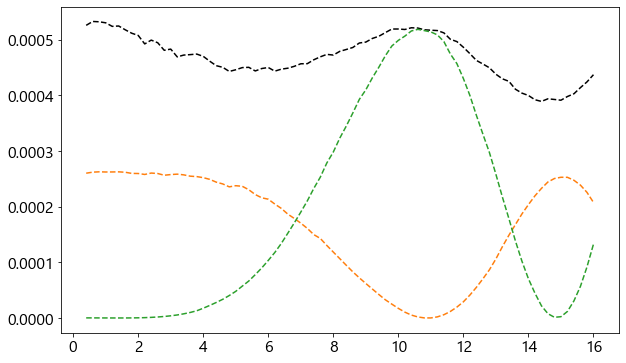

In [115]:
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
output_B, output_C, output_D = spectra_2[wav_ind, 2:], spectra_3[wav_ind, 2:], spectra_4[wav_ind, 2:]

fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages_tot[2:], output_B+output_C+output_D, 'k--')
ax1.plot(voltages_tot[2:], output_B, '--', color='C1', label='Output B')
ax1.plot(voltages_tot[2:], output_C, '--', color='C2', label='Output C')
ax1.plot(voltages_tot[2:], output_, '--', color='C3', label='Output D')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.xlim(0, 12)
plt.legend(loc=(1.01, 0.3))
plt.show()


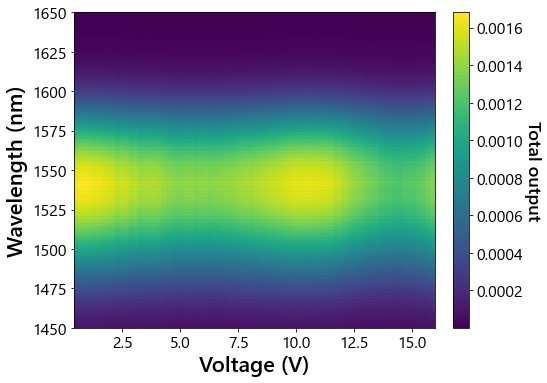

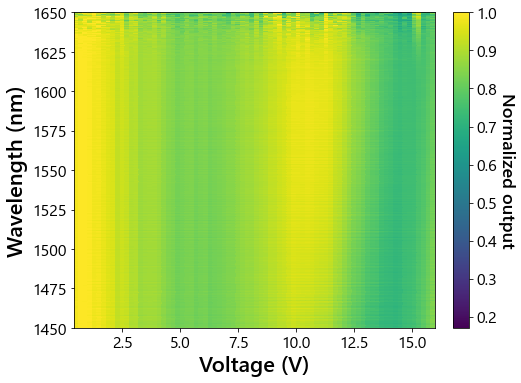

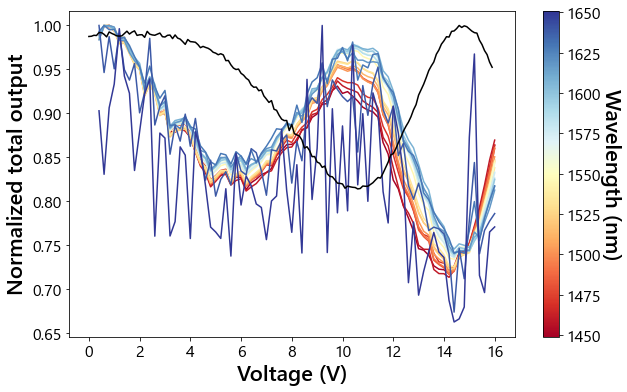

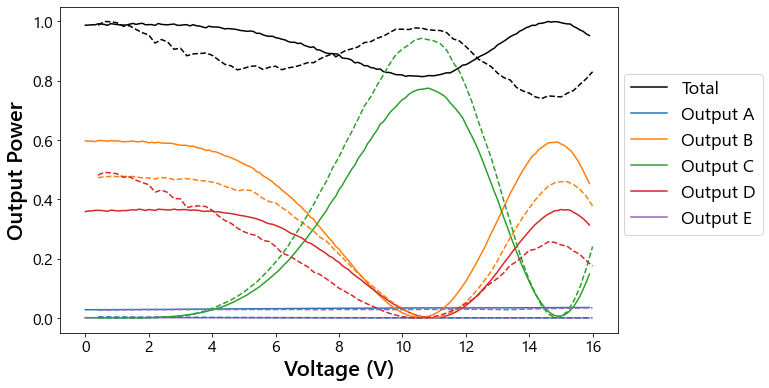

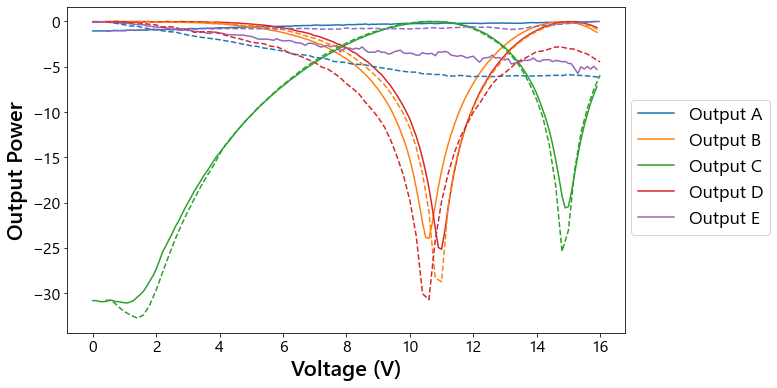

In [91]:
filename_root, num_outputs = 'Device6a_I18_1x5Tri', 5
data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260505\\voltage_scan\\{filename_root}_amoeba_TECoff_lowV_trial0\\'
voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)

spectra_tot = spectra_1+spectra_2+spectra_3+spectra_4+spectra_5
voltages_tot, spectra_tot = np.copy(voltages_1)[2:], spectra_tot[:, 2:]
outputs_tot = np.sum(outputs_scaled, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot)#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Total output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot/np.max(spectra_tot, axis=1)[:, None])#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Normalized output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

wavs = np.linspace(1450, 1650, 20)

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wavs)-1, vmax=np.max(wavs)+1)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue

for wav_0 in wavs:    
    color = cmap(norm(wav_0))
    wav_ind = np.argmin(abs(wav-wav_0))
    ax.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), label=f"{voltage:0.3f} V", color=color)

ax.plot(voltages, outputs_tot/np.max(outputs_tot), 'k')
# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Voltage (V)')
plt.ylabel('Normalized total output')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength (nm)", rotation=270, labelpad=20)

plt.show()  

fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i]/np.max(np.sum(outputs_scaled, axis=1)), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, spectra_1[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C0')
ax1.plot(voltages_tot, spectra_2[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C1')
ax1.plot(voltages_tot, spectra_3[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C2')
ax1.plot(voltages_tot, spectra_4[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C3')
ax1.plot(voltages_tot, spectra_5[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C4')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

fig, ax1 = plt.subplots(figsize=(10,6))
# ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, 10*np.log10(outputs_scaled[:,i]/np.max(outputs_scaled[:,i])), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
# ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, 10*np.log10(spectra_1[wav_ind, 2:]/np.max(spectra_1[wav_ind, 2:])), '--', color='C0')
ax1.plot(voltages_tot, 10*np.log10(spectra_2[wav_ind, 2:]/np.max(spectra_2[wav_ind, 2:])), '--', color='C1')
ax1.plot(voltages_tot, 10*np.log10(spectra_3[wav_ind, 2:]/np.max(spectra_3[wav_ind, 2:])), '--', color='C2')
ax1.plot(voltages_tot, 10*np.log10(spectra_4[wav_ind, 2:]/np.max(spectra_4[wav_ind, 2:])), '--', color='C3')
ax1.plot(voltages_tot, 10*np.log10(spectra_5[wav_ind, 2:]/np.max(spectra_5[wav_ind, 2:])), '--', color='C4')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()


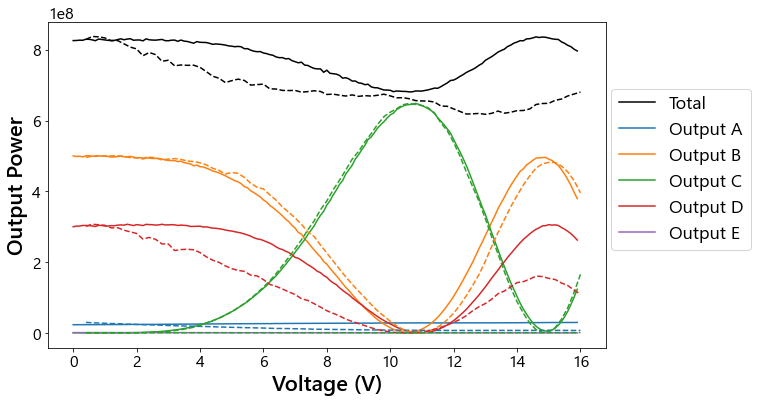

In [92]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i], color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
spec_tot_scaled = (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:] + (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:] + (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:] + (np.max(outputs_scaled[:,3])/np.max(spectra_4[wav_ind, 2:])) * spectra_4[wav_ind, 2:] +  (np.max(outputs_scaled[:,4])/np.max(spectra_5[wav_ind, 2:])) * spectra_5[wav_ind, 2:]
ax1.plot(voltages_tot, spec_tot_scaled, 'k--')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:], '--', color='C0')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:], '--', color='C1')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:], '--', color='C2')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,3])/np.max(spectra_4[wav_ind, 2:])) * spectra_4[wav_ind, 2:], '--', color='C3')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,4])/np.max(spectra_5[wav_ind, 2:])) * spectra_5[wav_ind, 2:], '--', color='C2')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

-33.808728593118225 -44.2132871573766


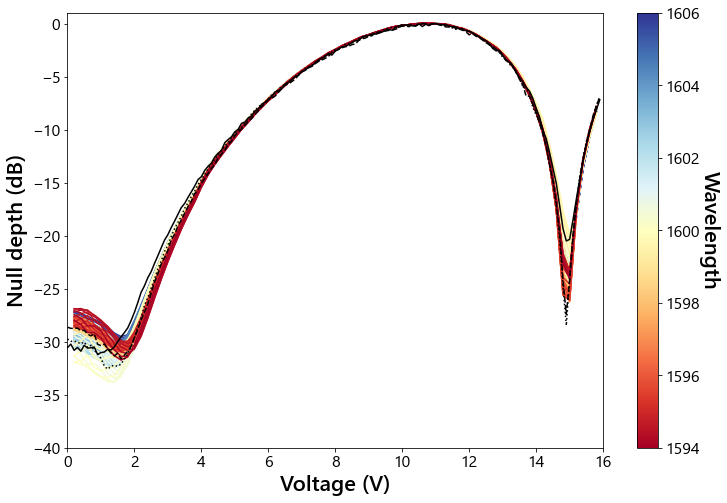

In [21]:
wav_range = 6
wav_cond, voltages_cond = np.abs(wav-1600)<wav_range, np.abs(voltages_3-8)<8
print(np.min(null[np.ix_(wav_cond, voltages_cond)]), np.min(null))

fig, ax = plt.subplots(figsize=(12,8))
norm = plt.Normalize(vmin=1600-wav_range, vmax=1600+wav_range)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
for i in range(len(wav[wav_cond])):
    color = cmap(norm(wav[wav_cond][i]))
    ax.plot(voltages_3[voltages_cond], null[np.ix_(wav_cond, voltages_cond)][i].T, color=color)# linestyle='dashed')

linestyles = ['solid', 'dashed', 'dotted']
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\Device6a_I18_1x5Tri\\20260505\\voltage_scan\\Device6a_I18_1x5Tri_amoeba_TECoff_lowV_trial{i}\\'
    filename_root, num_outputs = 'Device6a_I18_1x5Tri_Ch61_V9p55_Ch62_V10p38', 5
    voltages_phot = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs_phot = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
    attens_dB = np.nan * np.ones_like(attens)
    for atten in np.sort(list(set(attens.flatten()))):
        atten_dB = PIC.externalVOA_voltage_to_dB(atten)
        attens_dB[attens==atten] = atten_dB
    scaling = 10**(attens_dB/10).reshape(len(attens_dB), num_outputs)
    outputs_phot = scaling*outputs_phot
    flux_ratio_maxC = outputs_phot[:, 2]/np.max(outputs_phot[:,2])
    null_phot = 10*np.log10(flux_ratio_maxC)
    ax.plot(voltages_phot, null_phot, color='k', linestyle=linestyles[i])

plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength", rotation=270, labelpad=20)
plt.xlim(0, 16)
plt.ylim(-40, 1)

plt.show()

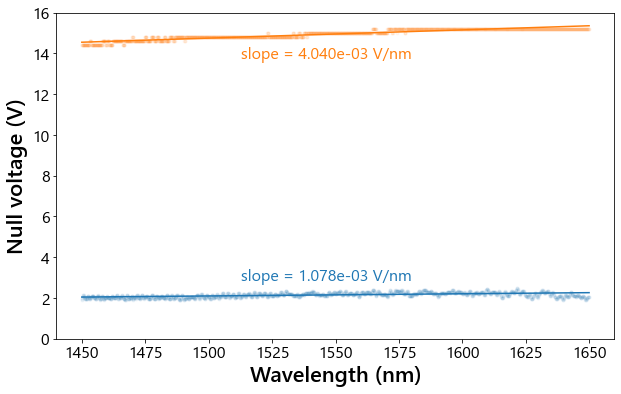

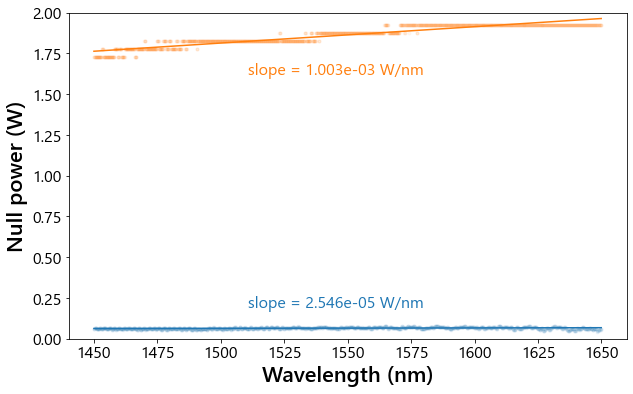

In [262]:
wav_range = abs(wav-1550) < 100
voltage_range = abs(voltages_1 - 2.5) < 2.5
voltage_A_0, wav_null, splitting_A_0 = voltages_1[voltage_range], wav[wav_range], null[np.ix_(wav_range, voltage_range)]

voltage_range = abs(voltages_1 - 14) < 3
voltage_A_1, splitting_A_1 = voltages_1[voltage_range], null[np.ix_(wav_range, voltage_range)]

resistance = 120
current_A_0, current_A_1 = voltage_A_0/resistance, voltage_A_1/resistance
power_A_0, power_A_1 = current_A_0*voltage_A_0, current_A_1*voltage_A_1

null_V_A_0, null_V_A_1 = [], []
null_P_A_0, null_P_A_1= [], []
for i in range(len(wav_null)):
    a, b, c = np.polyfit(voltage_A_0, splitting_A_0[i], 2)
    null_V_A_0.append(-b / (2*a))
    a, b, c = np.polyfit(power_A_0, splitting_A_0[i], 2)
    null_P_A_0.append(-b / (2*a))

    # a, b, c = np.polyfit(voltage_A_1, splitting_A_1[i], 2)
    # null_V_A_1.append(-b / (2*a))
    # a, b, c = np.polyfit(power_A_1, splitting_A_1[i], 2)
    # null_P_A_1.append(-b / (2*a))
    null_V_A_1.append(voltage_A_1[np.argmin(splitting_A_1[i])])
    null_P_A_1.append(power_A_1[np.argmin(splitting_A_1[i])])

m_V_A_0, b_V_A_0 = np.polyfit(wav_null, null_V_A_0, 1)
m_V_A_1, b_V_A_1 = np.polyfit(wav_null, null_V_A_1, 1)
m_P_A_0, b_P_A_0 = np.polyfit(wav_null, null_P_A_0, 1)
m_P_A_1, b_P_A_1 = np.polyfit(wav_null, null_P_A_1, 1)

plt.figure(figsize=(10,6))
plt.plot(wav_null, null_V_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_V_A_0*wav_null + b_V_A_0, color='C0')
plt.plot(wav_null, null_V_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_V_A_1*wav_null + b_V_A_1, color='C1')
plt.axhline(1550-6, color='k', linestyle='dashed')
plt.axhline(1550+6, color='k', linestyle='dashed')
x_text = 1580
plt.text(x_text, m_V_A_0*x_text + b_V_A_0 + 0.5,
         f'slope = {m_V_A_0:.3e} V/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_V_A_1*x_text + b_V_A_1 - 1.5,
         f'slope = {m_V_A_1:.3e} V/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 16)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null voltage (V)')
plt.show()


plt.figure(figsize=(10,6))
plt.plot(wav_null, null_P_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_P_A_0*wav_null + b_P_A_0, color='C0')
plt.plot(wav_null, null_P_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_P_A_1*wav_null + b_P_A_1, color='C1')
x_text = 1580
plt.text(x_text, m_P_A_0*x_text + b_P_A_0 + 0.1,
         f'slope = {m_P_A_0:.3e} W/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_P_A_1*x_text + b_P_A_1 - 0.3,
         f'slope = {m_P_A_1:.3e} W/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 2)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null power (W)')
plt.show()

Device 7a

D:\Active_PIC\SpectroscopyScans\Device7a_I21_1x5Tri\20260508\Device7a_I21_1x5Tri_O36_Ch68_V11p380_Ch69_V11p920\Device7a_I21_1x5Tri_O36_Ch68_V11p380_Ch69_V11p920*_Ch43_V*
D:\Active_PIC\SpectroscopyScans\Device7a_I21_1x5Tri\20260508\Device7a_I21_1x5Tri_O37_Ch68_V11p380_Ch69_V11p920\Device7a_I21_1x5Tri_O37_Ch68_V11p380_Ch69_V11p920*_Ch43_V*
D:\Active_PIC\SpectroscopyScans\Device7a_I21_1x5Tri\20260508\Device7a_I21_1x5Tri_O38_Ch68_V11p380_Ch69_V11p920\Device7a_I21_1x5Tri_O38_Ch68_V11p380_Ch69_V11p920*_Ch43_V*
D:\Active_PIC\SpectroscopyScans\Device7a_I21_1x5Tri\20260508\Device7a_I21_1x5Tri_O39_Ch68_V11p380_Ch69_V11p920\Device7a_I21_1x5Tri_O39_Ch68_V11p380_Ch69_V11p920*_Ch43_V*
D:\Active_PIC\SpectroscopyScans\Device7a_I21_1x5Tri\20260508\Device7a_I21_1x5Tri_O40_Ch68_V11p380_Ch69_V11p920\Device7a_I21_1x5Tri_O40_Ch68_V11p380_Ch69_V11p920*_Ch43_V*


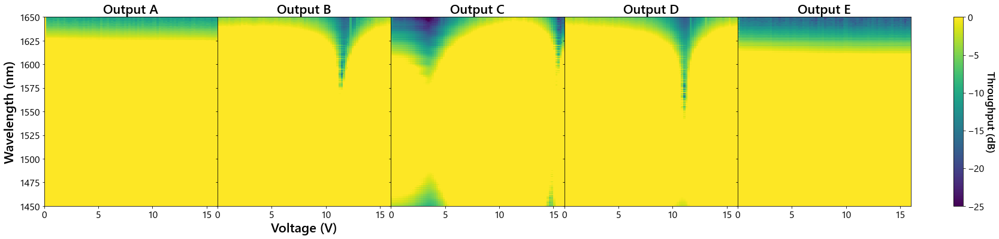

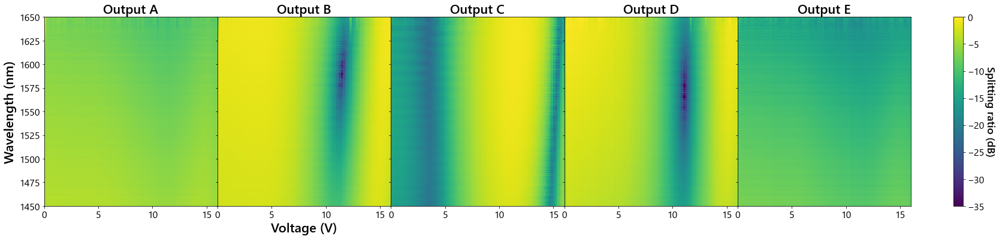

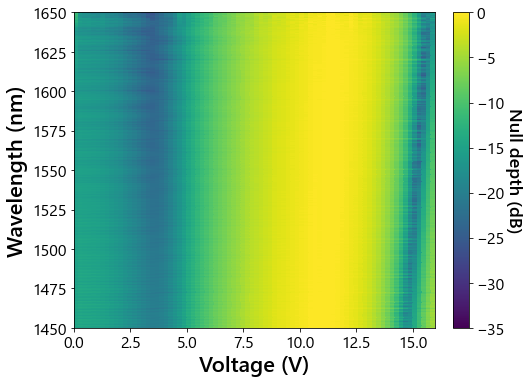

In [83]:
port_in, channel, fontsize = 21, 43, 18
device_name = 'Device7a_I21_1x5Tri'
data_dir = f'D:\\Active_PIC\\SpectroscopyScans\\Device7a_I21_1x5Tri\\20260508\\'
filename_ext = 'Ch68_V11p380_Ch69_V11p920'

port_out = 36
voltages_1, all_spectra_1 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 37
voltages_2, all_spectra_2 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 38
voltages_3, all_spectra_3 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 39
voltages_4, all_spectra_4 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')
port_out = 40
voltages_5, all_spectra_5 = PIC.read_voltage_scan_spectra(f'{data_dir}{device_name}_O{port_out}_{filename_ext}\\', 
                                                          f'{device_name}_O{port_out}_{filename_ext}', 
                                                          channel, delimiter=';')

filepath = 'D:\\Active_PIC\\SpectroscopyScans\\Device1_I3_SbendWaveguide_O1.csv'
wav_sbend, flux_sbend = PIC.read_ThorSpectra(filepath, log=False, delimiter=';')

throughput_1, throughput_2, throughput_3, throughput_4, throughput_5 = [], [], [], [], []
splitting_1, splitting_2, splitting_3, splitting_4, splitting_5 = [], [], [], [], []
spectra_1, spectra_2, spectra_3, spectra_4, spectra_5 = [], [], [], [], []
for i, voltage in enumerate(voltages_1):
    wav, spectrum_1 = all_spectra_1[i][:, 0], all_spectra_1[i][:, 1]
    wav_2, spectrum_2 = all_spectra_2[i][:, 0], all_spectra_2[i][:, 1]
    wav_3, spectrum_3 = all_spectra_3[i][:, 0], all_spectra_3[i][:, 1]
    wav_4, spectrum_4 = all_spectra_4[i][:, 0], all_spectra_4[i][:, 1]
    wav_5, spectrum_5 = all_spectra_5[i][:, 0], all_spectra_5[i][:, 1]
    spectrum_2 = np.interp(wav, wav_2, spectrum_2)
    spectrum_3 = np.interp(wav, wav_3, spectrum_3)
    spectrum_4 = np.interp(wav, wav_4, spectrum_4)
    spectrum_5 = np.interp(wav, wav_5, spectrum_5)
    spectrum_sbend = np.interp(wav, wav_sbend, flux_sbend)
    spectrum_tot = spectrum_1 + spectrum_2 + spectrum_3
    
    throughput_1.append(spectrum_1/spectrum_sbend)
    throughput_2.append(spectrum_2/spectrum_sbend)
    throughput_3.append(spectrum_3/spectrum_sbend)
    throughput_4.append(spectrum_4/spectrum_sbend)
    throughput_5.append(spectrum_5/spectrum_sbend)

    splitting_1.append(spectrum_1/spectrum_tot)
    splitting_2.append(spectrum_2/spectrum_tot)
    splitting_3.append(spectrum_3/spectrum_tot)
    splitting_4.append(spectrum_4/spectrum_tot)
    splitting_5.append(spectrum_5/spectrum_tot)

    spectra_1.append(spectrum_1)
    spectra_2.append(spectrum_2)
    spectra_3.append(spectrum_3)
    spectra_4.append(spectrum_4)
    spectra_5.append(spectrum_5)

throughput_1, throughput_2, throughput_3, throughput_4, throughput_5 = np.array(throughput_1).T, np.array(throughput_2).T, np.array(throughput_3).T, np.array(throughput_4).T, np.array(throughput_5).T
splitting_1, splitting_2, splitting_3, splitting_4, splitting_5 = np.array(splitting_1).T, np.array(splitting_2).T, np.array(splitting_3).T, np.array(splitting_4).T, np.array(splitting_5).T
spectra_1, spectra_2, spectra_3, spectra_4, spectra_5 = np.array(spectra_1).T, np.array(spectra_2).T, np.array(spectra_3).T, np.array(spectra_4).T, np.array(spectra_5).T
wav = 10000000/wav

fig, ax = plt.subplots(1, 5, figsize=(32, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= -25, 0
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(throughput_1), vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_1, wav, 10*np.log10(throughput_2), vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_1, wav, 10*np.log10(throughput_3), vmin=vmin, vmax=vmax)
ax[3].pcolormesh(voltages_1, wav, 10*np.log10(throughput_4), vmin=vmin, vmax=vmax)
ax[4].pcolormesh(voltages_1, wav, 10*np.log10(throughput_5), vmin=vmin, vmax=vmax)
for i in range(5):
    ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Throughput (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 5, figsize=(32, 6), sharey=True)
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
vmin, vmax= -35, 0
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax[0].pcolormesh(voltages_1, wav, 10*np.log10(splitting_1), vmin=vmin, vmax=vmax)
ax[1].pcolormesh(voltages_1, wav, 10*np.log10(splitting_2), vmin=vmin, vmax=vmax)
ax[2].pcolormesh(voltages_1, wav, 10*np.log10(splitting_3), vmin=vmin, vmax=vmax)
ax[3].pcolormesh(voltages_1, wav, 10*np.log10(splitting_4), vmin=vmin, vmax=vmax)
ax[4].pcolormesh(voltages_1, wav, 10*np.log10(splitting_5), vmin=vmin, vmax=vmax)
for i in range(5):
    ax[i].set_title(f'Output {chr(ord("A") + i)}', fontsize=22)
ax[0].set_ylabel('Wavelength (nm)')
ax[1].set_xlabel('Voltage (V)')
ax[0].set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Splitting ratio (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_throughputMap.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

norm = np.max(spectra_3, axis=1, keepdims=True)
null = 10*np.log10(spectra_3/norm)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_1, wav, null, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Null depth (dB)', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()


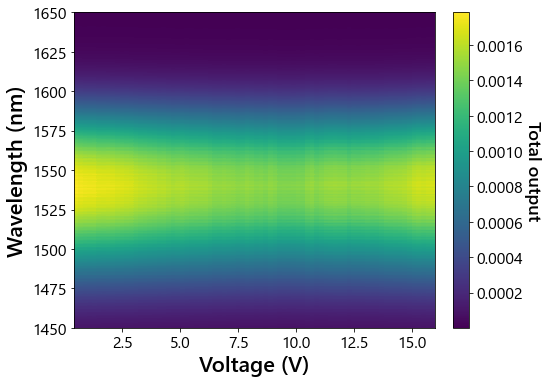

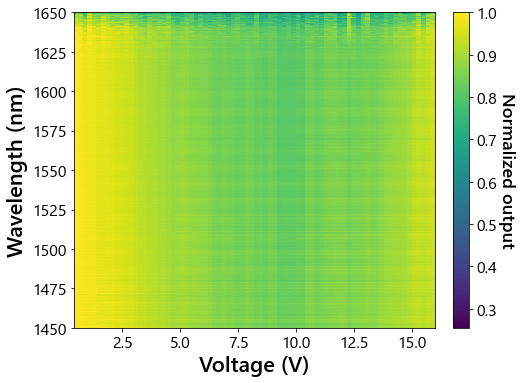

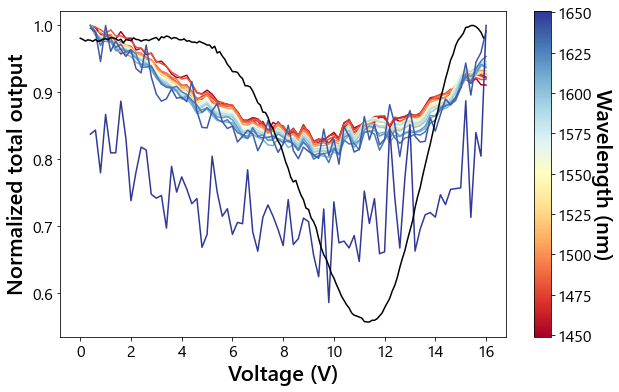

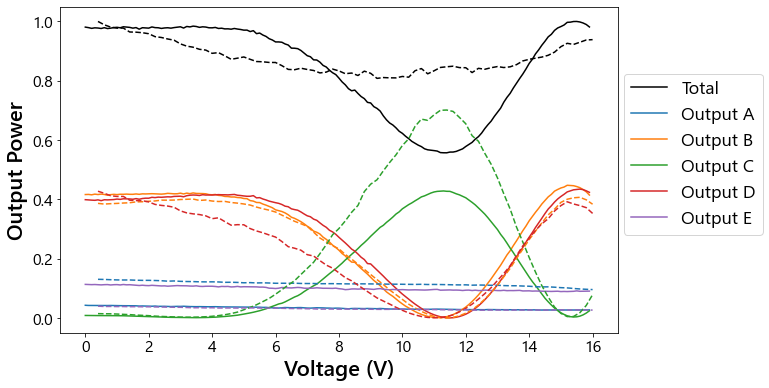

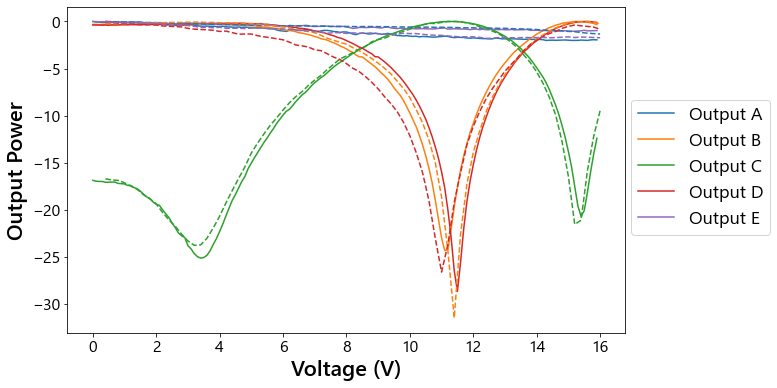

In [86]:
filename_root, num_outputs = 'Device7a_I21_1x5Tri', 5
data_dir = f'D:\\Active_PIC\\PhotometryScans\\{filename_root}\\20260506\\voltage_scan\\{filename_root}_amoeba_TECoff_lowV_trial0\\'
voltages = np.load(glob.glob(f'{data_dir}{filename_root}*_voltage.npy')[0])
outputs = np.load(glob.glob(f'{data_dir}{filename_root}*_outputs.npy')[0])
attens = np.load(glob.glob(f'{data_dir}{filename_root}*_attenuation.npy')[0])
outputs_scaled = PIC.scale_voltage_scan(outputs, attens)

spectra_tot = spectra_1+spectra_2+spectra_3+spectra_4+spectra_5
# spectra_tot = spectra_2+spectra_3+spectra_4
voltages_tot, spectra_tot = np.copy(voltages_1)[2:], spectra_tot[:, 2:]
outputs_tot = np.sum(outputs_scaled, axis=1)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot)#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Total output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
cmap = plt.get_cmap('viridis')
cmap.set_bad(color='gray')
plt.subplots_adjust(wspace=0, bottom=0.15)  # add bottom space for label
im = ax.pcolormesh(voltages_tot, wav, spectra_tot/np.max(spectra_tot, axis=1)[:, None])#, vmin=-35, vmax=0)
ax.set_ylabel('Wavelength (nm)')
ax.set_xlabel('Voltage (V)')
ax.set_ylim(1450, 1650)
cbar = fig.colorbar(im, ax=ax, pad=0.04)
cbar.set_label('Normalized output', rotation=270, labelpad=18, fontsize=fontsize)
# plt.savefig(f'{save_dir}{device_name}_nullDepth_normMaxB.png',
#             dpi=300, bbox_inches='tight', transparent=True)
plt.show()

wavs = np.linspace(1450, 1650, 20)

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wavs)-1, vmax=np.max(wavs)+1)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue

for wav_0 in wavs:    
    color = cmap(norm(wav_0))
    wav_ind = np.argmin(abs(wav-wav_0))
    ax.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), label=f"{voltage:0.3f} V", color=color)

ax.plot(voltages, outputs_tot/np.max(outputs_tot), 'k')
# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Voltage (V)')
plt.ylabel('Normalized total output')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength (nm)", rotation=270, labelpad=20)

plt.show()  

fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i]/np.max(np.sum(outputs_scaled, axis=1)), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, spectra_1[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C0')
ax1.plot(voltages_tot, spectra_2[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C1')
ax1.plot(voltages_tot, spectra_3[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C2')
ax1.plot(voltages_tot, spectra_4[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C3')
ax1.plot(voltages_tot, spectra_5[wav_ind, 2:]/np.max(spectra_tot[wav_ind, :]), '--', color='C4')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

fig, ax1 = plt.subplots(figsize=(10,6))
# ax1.plot(voltages, np.sum(outputs_scaled, axis=1)/np.max(np.sum(outputs_scaled, axis=1)), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, 10*np.log10(outputs_scaled[:,i]/np.max(outputs_scaled[:,i])), color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
# ax1.plot(voltages_tot, spectra_tot[wav_ind, :]/np.max(spectra_tot[wav_ind, :]), 'k--')
ax1.plot(voltages_tot, 10*np.log10(spectra_1[wav_ind, 2:]/np.max(spectra_1[wav_ind, 2:])), '--', color='C0')
ax1.plot(voltages_tot, 10*np.log10(spectra_2[wav_ind, 2:]/np.max(spectra_2[wav_ind, 2:])), '--', color='C1')
ax1.plot(voltages_tot, 10*np.log10(spectra_3[wav_ind, 2:]/np.max(spectra_3[wav_ind, 2:])), '--', color='C2')
ax1.plot(voltages_tot, 10*np.log10(spectra_4[wav_ind, 2:]/np.max(spectra_4[wav_ind, 2:])), '--', color='C3')
ax1.plot(voltages_tot, 10*np.log10(spectra_5[wav_ind, 2:]/np.max(spectra_5[wav_ind, 2:])), '--', color='C4')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()



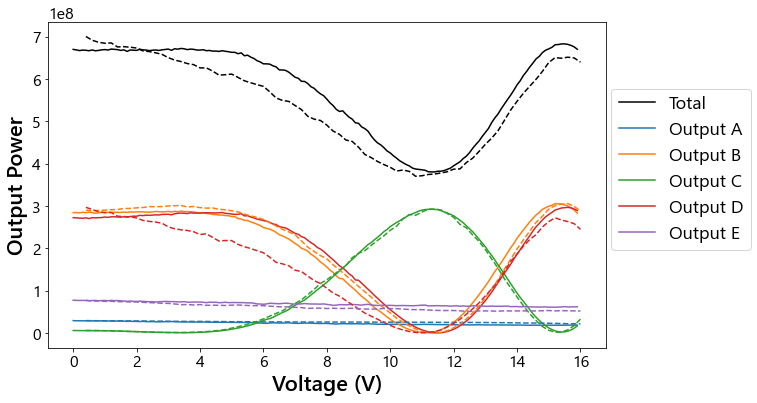

In [89]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(voltages, np.sum(outputs_scaled, axis=1), 'k', label='Total')
for i in range(np.shape(outputs_scaled)[1]):
    ax1.plot(voltages, outputs_scaled[:,i], color=f'C{i}', label=f'Output {chr(65+i)}')
wav_0 = 1590
wav_ind = np.argmin(abs(wav-wav_0))
spec_tot_scaled = (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:] + (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:] + (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:] + (np.max(outputs_scaled[:,3])/np.max(spectra_4[wav_ind, 2:])) * spectra_4[wav_ind, 2:] +  (np.max(outputs_scaled[:,4])/np.max(spectra_5[wav_ind, 2:])) * spectra_5[wav_ind, 2:]
ax1.plot(voltages_tot, spec_tot_scaled, 'k--')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,0])/np.max(spectra_1[wav_ind, 2:])) * spectra_1[wav_ind, 2:], '--', color='C0')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,1])/np.max(spectra_2[wav_ind, 2:])) * spectra_2[wav_ind, 2:], '--', color='C1')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,2])/np.max(spectra_3[wav_ind, 2:])) * spectra_3[wav_ind, 2:], '--', color='C2')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,3])/np.max(spectra_4[wav_ind, 2:])) * spectra_4[wav_ind, 2:], '--', color='C3')
ax1.plot(voltages_tot, (np.max(outputs_scaled[:,4])/np.max(spectra_5[wav_ind, 2:])) * spectra_5[wav_ind, 2:], '--', color='C4')
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Output Power')
plt.legend(loc=(1.01, 0.3))
plt.show()

-24.811501986570082 -27.68141016684663


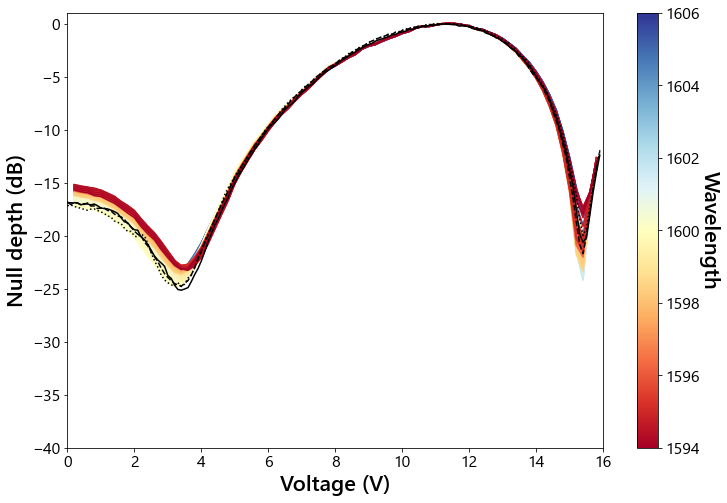

In [43]:
wav_range = 6
wav_cond, voltages_cond = np.abs(wav-1600)<wav_range, np.abs(voltages_3-8)<8
print(np.min(null[np.ix_(wav_cond, voltages_cond)]), np.min(null))

fig, ax = plt.subplots(figsize=(12,8))
norm = plt.Normalize(vmin=1600-wav_range, vmax=1600+wav_range)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
for i in range(len(wav[wav_cond])):
    color = cmap(norm(wav[wav_cond][i]))
    ax.plot(voltages_3[voltages_cond], null[np.ix_(wav_cond, voltages_cond)][i].T, color=color)# linestyle='dashed')

linestyles = ['solid', 'dashed', 'dotted']
for i in range(3):
    data_dir = f'D:\\Active_PIC\\PhotometryScans\\Device7a_I21_1x5Tri\\20260506\\voltage_scan\\Device7a_I21_1x5Tri_amoeba_TECoff_lowV_trial{i}\\'
    filename_root, num_outputs = 'Device7a_I21_1x5Tri_Ch68_V11p38_Ch69_V11p92', 5
    voltages_phot = np.load(f'{data_dir}{filename_root}_voltage.npy')
    outputs_phot = np.load(f'{data_dir}{filename_root}_outputs.npy')
    attens = np.load(f'{data_dir}{filename_root}_attenuation.npy')
    attens_dB = np.nan * np.ones_like(attens)
    for atten in np.sort(list(set(attens.flatten()))):
        atten_dB = PIC.externalVOA_voltage_to_dB(atten)
        attens_dB[attens==atten] = atten_dB
    scaling = 10**(attens_dB/10).reshape(len(attens_dB), num_outputs)
    outputs_phot = scaling*outputs_phot
    flux_ratio_maxC = outputs_phot[:, 2]/np.max(outputs_phot[:,2])
    null_phot = 10*np.log10(flux_ratio_maxC)
    ax.plot(voltages_phot, null_phot, color='k', linestyle=linestyles[i])

plt.xlabel('Voltage (V)')
plt.ylabel('Null depth (dB)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength", rotation=270, labelpad=20)
plt.xlim(0, 16)
plt.ylim(-40, 1)

plt.show()

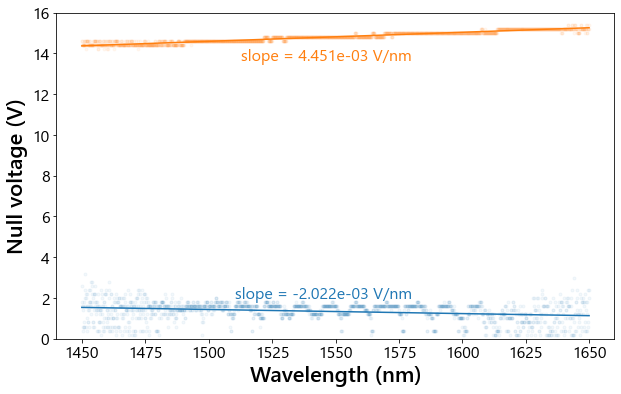

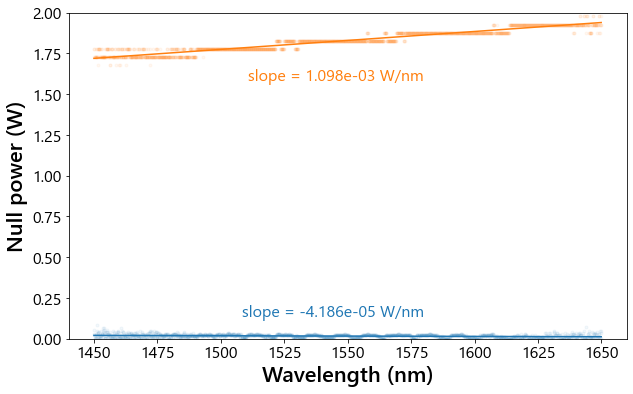

In [81]:
wav_range = abs(wav-1550) < 100
voltage_range = abs(voltages_1 - 2.5) < 2.5
voltage_A_0, wav_null, splitting_A_0 = voltages_1[voltage_range], wav[wav_range], null[np.ix_(wav_range, voltage_range)]

voltage_range = abs(voltages_1 - 14) < 3
voltage_A_1, splitting_A_1 = voltages_1[voltage_range], null[np.ix_(wav_range, voltage_range)]

resistance = 120
current_A_0, current_A_1 = voltage_A_0/resistance, voltage_A_1/resistance
power_A_0, power_A_1 = current_A_0*voltage_A_0, current_A_1*voltage_A_1

null_V_A_0, null_V_A_1 = [], []
null_P_A_0, null_P_A_1= [], []
for i in range(len(wav_null)):
    # a, b, c = np.polyfit(voltage_A_0, splitting_A_0[i], 2)
    # null_V_A_0.append(-b / (2*a))
    # a, b, c = np.polyfit(power_A_0, splitting_A_0[i], 2)
    # null_P_A_0.append(-b / (2*a))
    null_V_A_0.append(voltage_A_0[np.argmin(splitting_A_0[i])])
    null_P_A_0.append(power_A_0[np.argmin(splitting_A_0[i])])

    # a, b, c = np.polyfit(voltage_A_1, splitting_A_1[i], 2)
    # null_V_A_1.append(-b / (2*a))
    # a, b, c = np.polyfit(power_A_1, splitting_A_1[i], 2)
    # null_P_A_1.append(-b / (2*a))
    null_V_A_1.append(voltage_A_1[np.argmin(splitting_A_1[i])])
    null_P_A_1.append(power_A_1[np.argmin(splitting_A_1[i])])

m_V_A_0, b_V_A_0 = np.polyfit(wav_null, null_V_A_0, 1)
m_V_A_1, b_V_A_1 = np.polyfit(wav_null, null_V_A_1, 1)
m_P_A_0, b_P_A_0 = np.polyfit(wav_null, null_P_A_0, 1)
m_P_A_1, b_P_A_1 = np.polyfit(wav_null, null_P_A_1, 1)

plt.figure(figsize=(10,6))
plt.plot(wav_null, null_V_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_V_A_0*wav_null + b_V_A_0, color='C0')
plt.plot(wav_null, null_V_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_V_A_1*wav_null + b_V_A_1, color='C1')
x_text = 1580
plt.text(x_text, m_V_A_0*x_text + b_V_A_0 + 0.5,
         f'slope = {m_V_A_0:.3e} V/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_V_A_1*x_text + b_V_A_1 - 1.5,
         f'slope = {m_V_A_1:.3e} V/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 16)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null voltage (V)')
plt.show()


plt.figure(figsize=(10,6))
plt.plot(wav_null, null_P_A_0, '.', alpha=0.05, color='C0')
plt.plot(wav_null, m_P_A_0*wav_null + b_P_A_0, color='C0')
plt.plot(wav_null, null_P_A_1, '.', alpha=0.05, color='C1')
plt.plot(wav_null, m_P_A_1*wav_null + b_P_A_1, color='C1')
x_text = 1580
plt.text(x_text, m_P_A_0*x_text + b_P_A_0 + 0.1,
         f'slope = {m_P_A_0:.3e} W/nm', color='C0', va='bottom', ha='right', fontsize=16)
plt.text(x_text, m_P_A_1*x_text + b_P_A_1 - 0.3,
         f'slope = {m_P_A_1:.3e} W/nm', color='C1', va='bottom', ha='right', fontsize=16)
plt.ylim(0, 2)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Null power (W)')
plt.show()

In [222]:
import os
import glob
import re

folder = r"D:\Active_PIC\ForwardsInjectionSpectra\20260313\Device7a_1x5TriCross"

pattern = os.path.join(folder, "Device7a_1x5TriCross*_Ch*_V*_Ch*_V*_V*_*.txt")

for filepath in glob.glob(pattern):
    dirname, filename = os.path.split(filepath)

    # Match: _Vxxx_Vyyy_#.txt → insert _Ch41_
    new_filename = re.sub(
        r'_V([^_]+)_V([^_]+)(_.*\.txt)$',
        r'_V\1_Ch43_V\2\3',
        filename
    )

    new_filepath = os.path.join(dirname, new_filename)

    if new_filepath != filepath:
        os.rename(filepath, new_filepath)
        print(f"{filename} → {new_filename}")

Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p000_0.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p000_0.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p000_1.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p000_1.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p000_2.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p000_2.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p000_3.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p000_3.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p000_4.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p000_4.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p200_0.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p200_0.txt
Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_V0p200_1.txt → Device7a_1x5TriCross_I21_O36_Ch68_V9p750_Ch69_V11p000_Ch43_V0p200_1.txt
Device7a_1x5T

In [179]:
filepath

'D:\\Active_PIC\\\\ForwardsInjectionSpectra\\\\20260313\\Device6a_1x5Tri\\Device6a_1x5Tri_I18_O30_Ch61_V9p750_Ch62_V11p000_V9p800_4.txt'